# Advanced Image Processing — Project

## Rapid Hurricane Damage Assessment Using NOAA Emergency Response Imagery:
### A Comparison of Classical Image Processing and a Compact Convolutional Neural Network

**By:** Nafiu I. Hammed  
**Area:** Advanced Image Processing  
**Year done:** 2026

### Project Objective
This project investigates property-level hurricane damage assessment following
Hurricane Milton (2024) using high-resolution aerial imagery.

Two approaches are compared:

1. **Classical Image Processing:** Pre-event USDA NAIP 2023 imagery and
   post-event NOAA Emergency Response Imagery (ERI), using image registration,
   normalization, SSIM, color-difference analysis, and morphological processing.

2. **Compact CNN:** Post-event NOAA ERI patches classified using an
   ImageNet-pretrained MobileNetV3-Small model.

The methods are evaluated using common classification metrics and compared in
terms of predictive performance and computational efficiency.

In [ ]:
# ============================================================
# CELL 1 — PROJECT INITIALIZATION AND PERSISTENT STORAGE
# EE565 Advanced Image Processing — Midterm Project
# ============================================================

from google.colab import drive
from pathlib import Path
import os
import random
import numpy as np

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------
drive.mount('/content/drive')

# ------------------------------------------------------------
# 2. Define persistent project directory
# ------------------------------------------------------------
PROJECT_DIR = Path('/content/drive/MyDrive/EE565_Midterm_Milton')

DATA_DIR       = PROJECT_DIR / 'data'
CHECKPOINT_DIR = PROJECT_DIR / 'checkpoints'
MODEL_DIR      = PROJECT_DIR / 'models'
RESULTS_DIR    = PROJECT_DIR / 'results'
FIGURES_DIR    = PROJECT_DIR / 'figures'

PROJECT_DIRS = [
    DATA_DIR,
    CHECKPOINT_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    FIGURES_DIR
]

for directory in PROJECT_DIRS:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Reproducibility
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# 4. Basic project configuration
# ------------------------------------------------------------
PATCH_SIZE = 128

print("=" * 65)
print("EE565 MIDTERM PROJECT INITIALIZED")
print("=" * 65)

print(f"\nProject directory : {PROJECT_DIR}")
print(f"Data              : {DATA_DIR}")
print(f"Checkpoints       : {CHECKPOINT_DIR}")
print(f"Models            : {MODEL_DIR}")
print(f"Results           : {RESULTS_DIR}")
print(f"Figures           : {FIGURES_DIR}")

print(f"\nRandom seed        : {SEED}")
print(f"Patch size         : {PATCH_SIZE} x {PATCH_SIZE}")

print("\n✓ Google Drive mounted")
print("✓ Persistent project directories created")
print("✓ Reproducibility seed initialized")
print("✓ Cell 1 complete")

Mounted at /content/drive
EE565 MIDTERM PROJECT INITIALIZED

Project directory : /content/drive/MyDrive/EE565_Midterm_Milton
Data              : /content/drive/MyDrive/EE565_Midterm_Milton/data
Checkpoints       : /content/drive/MyDrive/EE565_Midterm_Milton/checkpoints
Models            : /content/drive/MyDrive/EE565_Midterm_Milton/models
Results           : /content/drive/MyDrive/EE565_Midterm_Milton/results
Figures           : /content/drive/MyDrive/EE565_Midterm_Milton/figures

Random seed        : 42
Patch size         : 128 x 128

✓ Google Drive mounted
✓ Persistent project directories created
✓ Reproducibility seed initialized
✓ Cell 1 complete


## 1. Environment Setup

This section initializes the Python environment and verifies the main libraries
required for geospatial image processing, image registration, classical feature
extraction, machine learning, and CNN development.

The implementation uses fixed software components throughout the experiment to
support reproducibility.

In [ ]:
# ============================================================
# CELL 2 — ENVIRONMENT AND DEPENDENCY CHECK
# ============================================================

import sys
import platform
import warnings
warnings.filterwarnings("ignore")

# Core scientific computing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Image processing
import cv2
import skimage
from skimage.metrics import structural_similarity as ssim

# Geospatial processing
import rasterio
import geopandas as gpd
import shapely
import pyproj

# Machine learning
import sklearn

# Deep learning
import torch
import torchvision

# Utilities
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Device configuration
# ------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Make PyTorch reproducible
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Environment report
# ------------------------------------------------------------
print("=" * 65)
print("ENVIRONMENT CHECK")
print("=" * 65)

print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"OpenCV       : {cv2.__version__}")
print(f"scikit-image : {skimage.__version__}")
print(f"Rasterio     : {rasterio.__version__}")
print(f"GeoPandas    : {gpd.__version__}")
print(f"Shapely      : {shapely.__version__}")
print(f"PyProj       : {pyproj.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"PyTorch      : {torch.__version__}")
print(f"Torchvision  : {torchvision.__version__}")

print("\nCompute device:", DEVICE)

if torch.cuda.is_available():
    print("GPU           :", torch.cuda.get_device_name(0))
else:
    print("GPU           : Not currently enabled")

# ------------------------------------------------------------
# Important capability checks
# ------------------------------------------------------------
assert hasattr(cv2, "SIFT_create"), \
    "OpenCV installation does not provide SIFT."

assert hasattr(skimage.metrics, "structural_similarity"), \
    "SSIM implementation unavailable."

print("\n✓ Core scientific libraries available")
print("✓ Geospatial libraries available")
print("✓ OpenCV SIFT available")
print("✓ SSIM available")
print("✓ PyTorch environment available")
print("✓ Cell 2 complete")

ENVIRONMENT CHECK
Python       : 3.13.15
NumPy        : 2.1.3
Pandas       : 2.2.3
OpenCV       : 5.0.0
scikit-image : 0.25.2
Rasterio     : 1.5.1
GeoPandas    : 1.1.4
Shapely      : 2.1.2
PyProj       : 3.7.2
scikit-learn : 1.6.1
PyTorch      : 2.11.0+cpu
Torchvision  : 0.26.0+cpu

Compute device: cpu
GPU           : Not currently enabled

✓ Core scientific libraries available
✓ Geospatial libraries available
✓ OpenCV SIFT available
✓ SSIM available
✓ PyTorch environment available
✓ Cell 2 complete


## 2. Ground-Truth Damage Assessment Data

Official Charlotte County post-Hurricane Milton damage assessment records are
used as the property-level ground-truth proxy.

For each property, the damage score is defined from three exterior components:

- roof covering (`roof_cover`)
- superstructure (`superstruc`)
- exterior finish (`exterior_f`)

The binary target is defined conservatively:

- **Negative (0):** maximum component damage = 0
- **Positive (1):** maximum component damage ≥ 50
- **Excluded:** maximum component damage between 1 and 49

This conservative definition reduces ambiguity while focusing on damage components
that are more relevant to aerial-image interpretation.

In [ ]:
# ============================================================
# CELL 3 — DOWNLOAD CHARLOTTE COUNTY DAMAGE ASSESSMENT DATA
# Handles Charlotte County server HTTP 403
# ============================================================

import requests
import zipfile
from pathlib import Path

# Persistent storage
LABEL_DIR = DATA_DIR / "charlotte_county"
LABEL_DIR.mkdir(parents=True, exist_ok=True)

LABEL_ZIP = LABEL_DIR / "SubstantialDamageEstimate.zip"

LABEL_URL = (
    "https://data.charlottecountyfl.gov/CCGIS/Zips/"
    "SubstantialDamageEstimate.zip"
)

# ------------------------------------------------------------
# Download only if a valid file is not already stored
# ------------------------------------------------------------
if not LABEL_ZIP.exists() or LABEL_ZIP.stat().st_size < 1000:

    print("Downloading official Charlotte County assessment data...")

    headers = {
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/120.0 Safari/537.36"
        ),
        "Referer": "https://data.charlottecountyfl.gov/CCGIS/Zips/"
    }

    response = requests.get(
        LABEL_URL,
        headers=headers,
        timeout=60
    )

    print("HTTP status:", response.status_code)

    response.raise_for_status()

    with open(LABEL_ZIP, "wb") as f:
        f.write(response.content)

    print("✓ Download complete")

else:
    print("✓ Existing ZIP found in Google Drive — download skipped")


# ------------------------------------------------------------
# Verify downloaded file
# ------------------------------------------------------------
assert LABEL_ZIP.exists(), "ZIP file was not created."

file_size_mb = LABEL_ZIP.stat().st_size / (1024**2)

print(f"\nZIP file : {LABEL_ZIP}")
print(f"Size     : {file_size_mb:.2f} MB")

assert zipfile.is_zipfile(LABEL_ZIP), \
    "Downloaded file is not a valid ZIP archive."


# ------------------------------------------------------------
# Inspect archive
# ------------------------------------------------------------
with zipfile.ZipFile(LABEL_ZIP, "r") as z:
    members = z.namelist()

print(f"\nArchive contains {len(members)} files:")

for name in members:
    print("  ", name)


# ------------------------------------------------------------
# Extract
# ------------------------------------------------------------
EXTRACT_DIR = LABEL_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

shapefiles = list(EXTRACT_DIR.rglob("*.shp"))

if not shapefiles:

    print("\nExtracting assessment dataset...")

    with zipfile.ZipFile(LABEL_ZIP, "r") as z:
        z.extractall(EXTRACT_DIR)

    shapefiles = list(EXTRACT_DIR.rglob("*.shp"))

    print("✓ Extraction complete")

else:
    print("\n✓ Existing extracted dataset found — extraction skipped")


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------
assert len(shapefiles) > 0, \
    "No shapefile found after extraction."

print("\nShapefile(s) found:")

for shp in shapefiles:
    print("  ", shp)

print("\n✓ Official Charlotte County dataset acquired")
print("✓ ZIP integrity verified")
print("✓ Shapefile located")
print("✓ Cell 3 complete")

HTTP status: 200
✓ Download complete

ZIP file : /content/drive/MyDrive/EE565_Midterm_Milton/data/charlotte_county/SubstantialDamageEstimate.zip
Size     : 1.46 MB

Archive contains 54 files:
   SubstantialDamageEstimate.cpg
   SubstantialDamageEstimate.dbf
   SubstantialDamageEstimate.gdb/a00000001.gdbindexes
   SubstantialDamageEstimate.gdb/a00000001.gdbtable
   SubstantialDamageEstimate.gdb/a00000001.gdbtablx
   SubstantialDamageEstimate.gdb/a00000001.TablesByName.atx
   SubstantialDamageEstimate.gdb/a00000002.gdbtable
   SubstantialDamageEstimate.gdb/a00000002.gdbtablx
   SubstantialDamageEstimate.gdb/a00000003.gdbindexes
   SubstantialDamageEstimate.gdb/a00000003.gdbtable
   SubstantialDamageEstimate.gdb/a00000003.gdbtablx
   SubstantialDamageEstimate.gdb/a00000004.CatItemsByPhysicalName.atx
   SubstantialDamageEstimate.gdb/a00000004.CatItemsByType.atx
   SubstantialDamageEstimate.gdb/a00000004.FDO_UUID.atx
   SubstantialDamageEstimate.gdb/a00000004.gdbindexes
   SubstantialDamage

### 2.1 Assessment Data Verification

The official Charlotte County assessment shapefile is loaded and inspected before
label construction. This verifies the number of property records, coordinate
reference system, geometry, and availability of the damage-component fields used
in the frozen label definition.

In [ ]:
# ============================================================
# CELL 4 — LOAD AND VERIFY CHARLOTTE COUNTY ASSESSMENTS
# ============================================================

import geopandas as gpd
import pandas as pd

# ------------------------------------------------------------
# 1. Locate and load shapefile
# ------------------------------------------------------------
shapefiles = list(EXTRACT_DIR.rglob("*.shp"))

assert len(shapefiles) == 1, \
    f"Expected one shapefile, found {len(shapefiles)}."

ASSESSMENT_SHP = shapefiles[0]

print("Loading:", ASSESSMENT_SHP)

gdf = gpd.read_file(ASSESSMENT_SHP)

# ------------------------------------------------------------
# 2. Basic dataset verification
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("CHARLOTTE COUNTY ASSESSMENT DATA")
print("=" * 65)

print(f"Records       : {len(gdf):,}")
print(f"Columns       : {len(gdf.columns)}")
print(f"CRS           : {gdf.crs}")
print(f"Geometry type : {gdf.geometry.geom_type.value_counts().to_dict()}")

# ------------------------------------------------------------
# 3. Inspect actual schema
# ------------------------------------------------------------
print("\nColumn names:")
print(list(gdf.columns))

# ------------------------------------------------------------
# 4. Verify required frozen-label fields
# ------------------------------------------------------------
REQUIRED_DAMAGE_FIELDS = [
    "roof_cover",
    "superstruc",
    "exterior_f"
]

missing_fields = [
    col for col in REQUIRED_DAMAGE_FIELDS
    if col not in gdf.columns
]

if missing_fields:
    print("\n⚠ Required fields not found exactly as expected:")
    print(missing_fields)
else:
    print("\n✓ All frozen-label damage fields are present")

    print("\nDamage-field summary:")
    print(gdf[REQUIRED_DAMAGE_FIELDS].describe())

    print("\nMissing values:")
    print(gdf[REQUIRED_DAMAGE_FIELDS].isna().sum())

# ------------------------------------------------------------
# 5. Geometry validity
# ------------------------------------------------------------
print("\nGeometry QC:")
print(f"Missing geometry : {gdf.geometry.isna().sum()}")
print(f"Empty geometry   : {gdf.geometry.is_empty.sum()}")
print(f"Valid geometry   : {gdf.geometry.is_valid.sum():,} / {len(gdf):,}")

# ------------------------------------------------------------
# 6. Preview only relevant fields
# ------------------------------------------------------------
preview_cols = [
    col for col in REQUIRED_DAMAGE_FIELDS
    if col in gdf.columns
]

preview_cols.append("geometry")

print("\nExample records:")
display(gdf[preview_cols].head())

print("\n✓ Cell 4 complete")

Loading: /content/drive/MyDrive/EE565_Midterm_Milton/data/charlotte_county/extracted/SubstantialDamageEstimate.shp

CHARLOTTE COUNTY ASSESSMENT DATA
Records       : 5,895
Columns       : 35
CRS           : EPSG:3857
Geometry type : {'Point': 5895}

Column names:
['globalid', 'inspection', 'street_add', 'damage_cau', 'foundation', 'superstruc', 'roof_cover', 'exterior_f', 'interior_f', 'doors_wind', 'cabinets_c', 'floor_fini', 'plumbing', 'electrical', 'appliances', 'hvac', 'damage_ave', 'damage_exc', 'comments', 'CreationDa', 'Creator', 'EditDate', 'Editor', 'business_o', 'water_in_l', 'high_water', 'latitude', 'longitude', 'damage_lev', 'reported_b', 'parcel_id', 'original_a', 'ACCOUNT', 'FullProper', 'geometry']

✓ All frozen-label damage fields are present

Damage-field summary:
        roof_cover   superstruc   exterior_f
count  5895.000000  5895.000000  5895.000000
mean      5.713316     5.698049    20.994063
std      18.508958    18.871732    27.464308
min       0.000000     0.00

,roof_cover,superstruc,exterior_f,geometry
0,0,0,0,POINT (-9140147.627 3120334.763)
1,0,0,0,POINT (-9140145.315 3120285.496)
2,0,0,0,POINT (-9140205 3120309.012)
3,0,0,0,POINT (-9140253.389 3120287.307)
4,0,0,0,POINT (-9140345.212 3120185.861)



✓ Cell 4 complete


### 2.2 Conservative Binary Damage Labels

A conservative binary damage target is constructed from the official assessment
fields. For each property,

\[
D_{\max} = \max(D_{\mathrm{roof}}, D_{\mathrm{superstructure}},
D_{\mathrm{exterior}})
\]

Properties with \(D_{\max}=0\) are assigned to the negative class, while
properties with \(D_{\max}\geq50\) are assigned to the positive class.
Intermediate cases (1–49) are excluded to reduce label ambiguity.

The resulting labels represent recorded exterior-component damage and should not
be interpreted as a complete measure of all possible property damage.

In [ ]:
# ============================================================
# CELL 5 — CONSTRUCT AND CHECKPOINT FROZEN DAMAGE LABELS
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd

# Work on a copy of the official assessment data
labeled_gdf = gdf.copy()

# ------------------------------------------------------------
# 1. Compute frozen maximum exterior-component damage score
# ------------------------------------------------------------
DAMAGE_FIELDS = ["roof_cover", "superstruc", "exterior_f"]

labeled_gdf["cnn_damage_max"] = (
    labeled_gdf[DAMAGE_FIELDS].max(axis=1)
)

# ------------------------------------------------------------
# 2. Apply frozen conservative binary label definition
# ------------------------------------------------------------
# NaN = excluded ambiguous case
labeled_gdf["damage_label"] = np.nan

labeled_gdf.loc[
    labeled_gdf["cnn_damage_max"] == 0,
    "damage_label"
] = 0

labeled_gdf.loc[
    labeled_gdf["cnn_damage_max"] >= 50,
    "damage_label"
] = 1

# ------------------------------------------------------------
# 3. Audit label construction BEFORE filtering
# ------------------------------------------------------------
negative_count = int((labeled_gdf["damage_label"] == 0).sum())
positive_count = int((labeled_gdf["damage_label"] == 1).sum())
excluded_count = int(labeled_gdf["damage_label"].isna().sum())

usable_count = negative_count + positive_count

print("=" * 65)
print("FROZEN LABEL CONSTRUCTION")
print("=" * 65)

print(f"Original assessment records : {len(labeled_gdf):,}")
print(f"Negative (damage = 0)       : {negative_count:,}")
print(f"Positive (damage >= 50)     : {positive_count:,}")
print(f"Excluded (damage 1–49)      : {excluded_count:,}")
print(f"Usable labeled properties   : {usable_count:,}")

assert (
    negative_count + positive_count + excluded_count
    == len(labeled_gdf)
), "Label accounting error."

# ------------------------------------------------------------
# 4. Keep only unambiguous labeled properties
# ------------------------------------------------------------
usable_gdf = labeled_gdf[
    labeled_gdf["damage_label"].notna()
].copy()

usable_gdf["damage_label"] = (
    usable_gdf["damage_label"].astype(np.int8)
)

# ------------------------------------------------------------
# 5. Convert to geographic coordinates for imagery matching
# ------------------------------------------------------------
usable_gdf = usable_gdf.to_crs("EPSG:4326")

# Preserve explicit coordinates
usable_gdf["property_lon"] = usable_gdf.geometry.x
usable_gdf["property_lat"] = usable_gdf.geometry.y

# ------------------------------------------------------------
# 6. Basic geographic QC
# ------------------------------------------------------------
print("\nGeographic extent (EPSG:4326):")
print(f"Longitude : {usable_gdf.property_lon.min():.6f} "
      f"to {usable_gdf.property_lon.max():.6f}")
print(f"Latitude  : {usable_gdf.property_lat.min():.6f} "
      f"to {usable_gdf.property_lat.max():.6f}")

print("\nFinal class distribution:")
print(usable_gdf["damage_label"].value_counts().sort_index())

# ------------------------------------------------------------
# 7. Persistent checkpoint
# ------------------------------------------------------------
LABEL_CHECKPOINT = (
    CHECKPOINT_DIR / "checkpoint_01_frozen_labels.gpkg"
)

usable_gdf.to_file(
    LABEL_CHECKPOINT,
    layer="frozen_labels",
    driver="GPKG"
)

print(f"\nCheckpoint saved:")
print(LABEL_CHECKPOINT)

print("\n✓ Frozen label rule applied")
print("✓ Ambiguous 1–49 cases excluded")
print("✓ Coordinates converted to EPSG:4326")
print("✓ Persistent label checkpoint created")
print("✓ Cell 5 complete")

FROZEN LABEL CONSTRUCTION
Original assessment records : 5,895
Negative (damage = 0)       : 2,433
Positive (damage >= 50)     : 1,407
Excluded (damage 1–49)      : 2,055
Usable labeled properties   : 3,840

Geographic extent (EPSG:4326):
Longitude : -82.374099 to -81.936964
Latitude  : 26.792495 to 27.056603

Final class distribution:
damage_label
0    2433
1    1407
Name: count, dtype: int64

Checkpoint saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_01_frozen_labels.gpkg

✓ Frozen label rule applied
✓ Ambiguous 1–49 cases excluded
✓ Coordinates converted to EPSG:4326
✓ Persistent label checkpoint created
✓ Cell 5 complete


## 3. NOAA Hurricane Milton Emergency Response Imagery

NOAA Emergency Response Imagery (ERI) collected following Hurricane Milton
provides the primary post-event aerial imagery.

Rather than downloading the complete Hurricane Milton archive, the NOAA imagery
inventory is first queried to identify only the GeoTIFF tiles relevant to the
labeled Charlotte County properties. This reduces unnecessary storage and
computation while preserving the full property-level study population.

In [ ]:
# ============================================================
# CELL 6 — NOAA HURRICANE MILTON IMAGE INVENTORY
# ============================================================

import subprocess
import sys
import pandas as pd

# ------------------------------------------------------------
# 1. Ensure boto3 is available
# ------------------------------------------------------------
try:
    import boto3
    from botocore import UNSIGNED
    from botocore.config import Config
except ImportError:
    print("Installing boto3...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "boto3"
    ])

    import boto3
    from botocore import UNSIGNED
    from botocore.config import Config

# ------------------------------------------------------------
# 2. NOAA public AWS configuration
# ------------------------------------------------------------
NOAA_BUCKET = "noaa-eri-pds"
MILTON_PREFIX = "2024_Hurricane_Milton/"

s3 = boto3.client(
    "s3",
    config=Config(signature_version=UNSIGNED)
)

print("=" * 65)
print("NOAA HURRICANE MILTON ERI INVENTORY")
print("=" * 65)

print(f"Bucket : s3://{NOAA_BUCKET}")
print(f"Prefix : {MILTON_PREFIX}")

# ------------------------------------------------------------
# 3. List all objects under Hurricane Milton event
# ------------------------------------------------------------
paginator = s3.get_paginator("list_objects_v2")

records = []

print("\nReading NOAA public imagery inventory...")

for page in paginator.paginate(
    Bucket=NOAA_BUCKET,
    Prefix=MILTON_PREFIX
):
    for obj in page.get("Contents", []):
        key = obj["Key"]

        # Keep GeoTIFF imagery only
        if key.lower().endswith((".tif", ".tiff")):
            records.append({
                "key": key,
                "size_bytes": obj["Size"],
                "last_modified": obj["LastModified"]
            })

noaa_inventory = pd.DataFrame(records)

assert len(noaa_inventory) > 0, \
    "No Hurricane Milton GeoTIFFs found."

# ------------------------------------------------------------
# 4. Derive useful inventory fields
# ------------------------------------------------------------
noaa_inventory["filename"] = (
    noaa_inventory["key"].str.split("/").str[-1]
)

noaa_inventory["acquisition_folder"] = (
    noaa_inventory["key"].str.split("/").str[-2]
)

noaa_inventory["size_mb"] = (
    noaa_inventory["size_bytes"] / (1024 ** 2)
)

# ------------------------------------------------------------
# 5. Inventory summary
# ------------------------------------------------------------
print(f"\nGeoTIFF files found : {len(noaa_inventory):,}")

print("\nAcquisition folders:")
print(
    noaa_inventory["acquisition_folder"]
    .value_counts()
    .sort_index()
)

print(
    f"\nTotal GeoTIFF volume represented: "
    f"{noaa_inventory['size_mb'].sum()/1024:.2f} GB"
)

print("\nExample NOAA files:")
display(
    noaa_inventory[
        ["acquisition_folder", "filename", "size_mb"]
    ].head()
)

# ------------------------------------------------------------
# 6. Save persistent inventory checkpoint
# ------------------------------------------------------------
NOAA_INVENTORY_CHECKPOINT = (
    CHECKPOINT_DIR / "checkpoint_02_noaa_inventory.csv"
)

noaa_inventory.to_csv(
    NOAA_INVENTORY_CHECKPOINT,
    index=False
)

print("\nCheckpoint saved:")
print(NOAA_INVENTORY_CHECKPOINT)

print("\n✓ NOAA public bucket accessed")
print("✓ Hurricane Milton GeoTIFF inventory created")
print("✓ Inventory saved persistently")
print("✓ Cell 6 complete")

Installing boto3...
NOAA HURRICANE MILTON ERI INVENTORY
Bucket : s3://noaa-eri-pds
Prefix : 2024_Hurricane_Milton/

Reading NOAA public imagery inventory...

GeoTIFF files found : 5,954

Acquisition folders:
acquisition_folder
20241011a_RGB    461
20241011b_RGB    469
20241011c_RGB     79
20241011d_RGB    449
20241012a_RGB    978
20241012b_RGB    147
20241012c_RGB    262
20241013a_RGB    478
20241013b_RGB    131
20241013c_RGB    299
20241013d_RGB    594
20241014a_RGB    810
20241014b_RGB    797
Name: count, dtype: int64

Total GeoTIFF volume represented: 894.60 GB

Example NOAA files:


,acquisition_folder,filename,size_mb
0,20241011a_RGB,20241011aC0822530w271245n.tif,55.433333
1,20241011a_RGB,20241011aC0822530w271330n.tif,84.870967
2,20241011a_RGB,20241011aC0822530w271415n.tif,26.524814
3,20241011a_RGB,20241011aC0822615w271115n.tif,50.630804
4,20241011a_RGB,20241011aC0822615w271200n.tif,18.869159



Checkpoint saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_02_noaa_inventory.csv

✓ NOAA public bucket accessed
✓ Hurricane Milton GeoTIFF inventory created
✓ Inventory saved persistently
✓ Cell 6 complete


### 3.1 Property-to-NOAA Tile Matching

The geographic coordinates encoded in NOAA ERI filenames are used to construct
the Hurricane Milton tile grid. Labeled properties are then assigned to the
corresponding post-event NOAA tile.

Where multiple acquisition dates cover the same location, a deterministic
selection rule is used so that each property is associated with one NOAA image.
This assignment is later used for geographic train/validation/test grouping and
prevents imagery from the same selected NOAA tile from leaking across splits.

In [ ]:
# ============================================================
# CELL 7 — MATCH LABELED PROPERTIES TO NOAA ERI TILES
# ============================================================

import re
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Decode NOAA tile-center coordinates from filenames
#
# Example:
# 20241011aC0822530w271245n.tif
#
# 0822530w -> 82°25'30" W
# 271245n  -> 27°12'45" N
# ------------------------------------------------------------
def parse_noaa_center(filename):

    pattern = r"C(\d{3})(\d{2})(\d{2})w(\d{2})(\d{2})(\d{2})n"

    match = re.search(pattern, filename)

    if match is None:
        return np.nan, np.nan

    lon_deg, lon_min, lon_sec, lat_deg, lat_min, lat_sec = map(
        int, match.groups()
    )

    lon = -(lon_deg + lon_min / 60 + lon_sec / 3600)
    lat =  (lat_deg + lat_min / 60 + lat_sec / 3600)

    return lon, lat


coords = noaa_inventory["filename"].apply(parse_noaa_center)

noaa_inventory["center_lon"] = [x[0] for x in coords]
noaa_inventory["center_lat"] = [x[1] for x in coords]

assert noaa_inventory["center_lon"].notna().all(), \
    "Some NOAA filenames could not be decoded."

# ------------------------------------------------------------
# 2. Determine the regular NOAA center spacing
# ------------------------------------------------------------
unique_lons = np.sort(noaa_inventory["center_lon"].unique())
unique_lats = np.sort(noaa_inventory["center_lat"].unique())

lon_diffs = np.diff(unique_lons)
lat_diffs = np.diff(unique_lats)

lon_spacing = np.min(lon_diffs[lon_diffs > 1e-8])
lat_spacing = np.min(lat_diffs[lat_diffs > 1e-8])

print("=" * 65)
print("PROPERTY-TO-NOAA TILE MATCHING")
print("=" * 65)

print(f"Longitude center spacing : {lon_spacing:.8f} degrees")
print(f"Latitude center spacing  : {lat_spacing:.8f} degrees")

# ------------------------------------------------------------
# 3. Restrict inventory to the Charlotte County study extent
#    plus a small margin
# ------------------------------------------------------------
margin = 0.03

study_inventory = noaa_inventory[
    noaa_inventory["center_lon"].between(
        usable_gdf["property_lon"].min() - margin,
        usable_gdf["property_lon"].max() + margin
    )
    &
    noaa_inventory["center_lat"].between(
        usable_gdf["property_lat"].min() - margin,
        usable_gdf["property_lat"].max() + margin
    )
].copy()

print(f"\nNOAA images near study area : {len(study_inventory):,}")

# ------------------------------------------------------------
# 4. Resolve repeat acquisitions of the same geographic tile
#
# Acquisition folders are sorted chronologically. For a
# repeated center location, retain the earliest available
# post-event acquisition.
# ------------------------------------------------------------
study_inventory = study_inventory.sort_values(
    ["center_lon", "center_lat", "acquisition_folder", "filename"]
)

selected_grid = (
    study_inventory
    .drop_duplicates(
        subset=["center_lon", "center_lat"],
        keep="first"
    )
    .copy()
)

print(f"Unique geographic tile centers : {len(selected_grid):,}")

# ------------------------------------------------------------
# 5. Assign each property to nearest NOAA tile center
# ------------------------------------------------------------
tile_xy = selected_grid[
    ["center_lon", "center_lat"]
].to_numpy()

prop_xy = usable_gdf[
    ["property_lon", "property_lat"]
].to_numpy()

assigned_indices = []
assigned_distances = []

for lon, lat in prop_xy:

    # Distance is used only for matching on this small
    # geographic tile grid.
    d2 = (
        (tile_xy[:, 0] - lon) ** 2 +
        (tile_xy[:, 1] - lat) ** 2
    )

    idx = np.argmin(d2)

    assigned_indices.append(idx)
    assigned_distances.append(np.sqrt(d2[idx]))

assigned_tiles = selected_grid.iloc[
    assigned_indices
].reset_index(drop=True)

property_noaa = usable_gdf.reset_index(drop=True).copy()

property_noaa["noaa_key"] = assigned_tiles["key"].values
property_noaa["noaa_filename"] = assigned_tiles["filename"].values
property_noaa["noaa_folder"] = assigned_tiles["acquisition_folder"].values
property_noaa["noaa_center_lon"] = assigned_tiles["center_lon"].values
property_noaa["noaa_center_lat"] = assigned_tiles["center_lat"].values
property_noaa["center_distance_deg"] = assigned_distances

# ------------------------------------------------------------
# 6. Conservative tile-membership check
#
# NOAA filename centers are spaced 45 arc-seconds apart.
# Half-spacing defines the nominal center-based tile boundary.
# ------------------------------------------------------------
half_lon = lon_spacing / 2
half_lat = lat_spacing / 2

property_noaa["noaa_matched"] = (
    (np.abs(
        property_noaa["property_lon"] -
        property_noaa["noaa_center_lon"]
    ) <= half_lon)
    &
    (np.abs(
        property_noaa["property_lat"] -
        property_noaa["noaa_center_lat"]
    ) <= half_lat)
)

matched = property_noaa[
    property_noaa["noaa_matched"]
].copy()

unmatched = property_noaa[
    ~property_noaa["noaa_matched"]
].copy()

# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------
print(f"\nUsable labeled properties : {len(property_noaa):,}")
print(f"Matched properties        : {len(matched):,}")
print(f"Unmatched properties      : {len(unmatched):,}")

print(
    f"Unique assigned NOAA tiles: "
    f"{matched['noaa_key'].nunique():,}"
)

print("\nSelected acquisition folders:")
print(
    matched["noaa_folder"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 8. Save checkpoint
# ------------------------------------------------------------
MATCH_CHECKPOINT = (
    CHECKPOINT_DIR /
    "checkpoint_03_property_noaa_assignment.gpkg"
)

property_noaa.to_file(
    MATCH_CHECKPOINT,
    layer="property_noaa_assignment",
    driver="GPKG"
)

print("\nCheckpoint saved:")
print(MATCH_CHECKPOINT)

print("\n✓ NOAA filename coordinates decoded")
print("✓ Properties assigned to candidate NOAA tiles")
print("✓ Assignment checkpoint created")
print("✓ Cell 7 complete")

PROPERTY-TO-NOAA TILE MATCHING
Longitude center spacing : 0.01222222 degrees
Latitude center spacing  : 0.01222222 degrees

NOAA images near study area : 770
Unique geographic tile centers : 627

Usable labeled properties : 3,840
Matched properties        : 3,655
Unmatched properties      : 185
Unique assigned NOAA tiles: 121

Selected acquisition folders:
noaa_folder
20241011b_RGB    1767
20241012b_RGB      40
20241013a_RGB    1848
Name: count, dtype: int64

Checkpoint saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_03_property_noaa_assignment.gpkg

✓ NOAA filename coordinates decoded
✓ Properties assigned to candidate NOAA tiles
✓ Assignment checkpoint created
✓ Cell 7 complete


### 3.2 Verification of NOAA Tile Georeferencing

Filename coordinates provide a useful approximation of NOAA ERI tile locations,
but final property-to-image assignment should use the georeferenced image
footprints rather than assuming that filename spacing defines exact image bounds.

The following step tests direct access to GeoTIFF metadata from NOAA's public
object storage. Only image metadata and geographic bounds are requested at this
stage; the full imagery archive is not downloaded.

In [ ]:
# ============================================================
# CELL 8 — TEST NOAA REMOTE GEOTIFF METADATA ACCESS
# ============================================================

import rasterio
from rasterio.session import AWSSession
from rasterio.warp import transform_bounds

import boto3
from botocore import UNSIGNED
from botocore.config import Config

print("=" * 65)
print("NOAA REMOTE GEOTIFF METADATA TEST")
print("=" * 65)

# ------------------------------------------------------------
# 1. Select one candidate NOAA tile from the study area
# ------------------------------------------------------------
test_row = study_inventory.iloc[0]

test_key = test_row["key"]
test_s3_uri = f"s3://{NOAA_BUCKET}/{test_key}"

print("\nTest tile:")
print(test_key)

# ------------------------------------------------------------
# 2. Create anonymous AWS session for NOAA public S3
# ------------------------------------------------------------
aws_session = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

# ------------------------------------------------------------
# 3. Open remote GeoTIFF and read metadata only
# ------------------------------------------------------------
with rasterio.Env(
    aws_session,
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
):
    with rasterio.open(test_s3_uri) as src:

        print("\nRaster metadata:")
        print(f"Width      : {src.width}")
        print(f"Height     : {src.height}")
        print(f"Bands      : {src.count}")
        print(f"CRS        : {src.crs}")
        print(f"Bounds     : {src.bounds}")
        print(f"Resolution : {src.res}")
        print(f"Dtype      : {src.dtypes}")
        print(f"Nodata     : {src.nodata}")

        # ----------------------------------------------------
        # 4. Convert geographic bounds to EPSG:4326
        #
        # NOAA Milton imagery is expected to already use
        # EPSG:4326, but this keeps the code robust if a tile
        # uses another CRS.
        # ----------------------------------------------------
        if src.crs is None:
            raise ValueError(
                "The NOAA GeoTIFF does not contain a CRS."
            )

        if src.crs.to_epsg() == 4326:
            geographic_bounds = (
                src.bounds.left,
                src.bounds.bottom,
                src.bounds.right,
                src.bounds.top
            )
        else:
            geographic_bounds = transform_bounds(
                src.crs,
                "EPSG:4326",
                *src.bounds
            )

# ------------------------------------------------------------
# 5. Report actual geographic footprint
# ------------------------------------------------------------
left, bottom, right, top = geographic_bounds

print("\nBounds in EPSG:4326:")
print(
    f"left={left:.6f}, "
    f"bottom={bottom:.6f}, "
    f"right={right:.6f}, "
    f"top={top:.6f}"
)

print("\nApproximate geographic dimensions:")
print(f"Width  : {right - left:.6f} degrees")
print(f"Height : {top - bottom:.6f} degrees")

# ------------------------------------------------------------
# 6. Basic sanity checks
# ------------------------------------------------------------
assert right > left, "Invalid longitude bounds."
assert top > bottom, "Invalid latitude bounds."

print("\n✓ Remote NOAA GeoTIFF opened successfully")
print("✓ CRS verified")
print("✓ Actual georeferenced bounds retrieved")
print("✓ Full imagery was not intentionally downloaded")
print("✓ Cell 8 complete")

NOAA REMOTE GEOTIFF METADATA TEST

Test tile:
2024_Hurricane_Milton/20241011b_RGB/20241011bC0822400w265700n.tif

Raster metadata:
Width      : 9415
Height     : 9415
Bands      : 4
CRS        : EPSG:4326
Bounds     : BoundingBox(left=-82.4001, bottom=26.9374, right=-82.3874, top=26.9501)
Resolution : (1.3489113117360883e-06, 1.3489113117364655e-06)
Dtype      : ('uint8', 'uint8', 'uint8', 'uint8')
Nodata     : None

Bounds in EPSG:4326:
left=-82.400100, bottom=26.937400, right=-82.387400, top=26.950100

Approximate geographic dimensions:
Width  : 0.012700 degrees
Height : 0.012700 degrees

✓ Remote NOAA GeoTIFF opened successfully
✓ CRS verified
✓ Actual georeferenced bounds retrieved
✓ Full imagery was not intentionally downloaded
✓ Cell 8 complete


### 3.3 Georeferenced NOAA Tile Footprints

Actual GeoTIFF bounds are used to construct the NOAA ERI image footprints covering
the Charlotte County study area. This avoids approximating image coverage from
filename coordinates alone.

Properties are spatially matched to the real NOAA image footprints. Where a
property is covered by multiple post-event acquisitions, the earliest available
post-event acquisition is selected deterministically.

In [ ]:
# ============================================================
# CELL 9 — BUILD ACTUAL NOAA FOOTPRINTS AND MATCH PROPERTIES
# ============================================================

import pandas as pd
import geopandas as gpd
import rasterio

from shapely.geometry import box
from rasterio.session import AWSSession
from rasterio.warp import transform_bounds
from tqdm.auto import tqdm

print("=" * 65)
print("ACTUAL NOAA GEOREFERENCED FOOTPRINT MATCHING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Persistent footprint checkpoint
# ------------------------------------------------------------
FOOTPRINT_CHECKPOINT = (
    CHECKPOINT_DIR / "checkpoint_04_noaa_footprints.gpkg"
)

# ------------------------------------------------------------
# 2. Build footprints only if checkpoint does not exist
# ------------------------------------------------------------
if FOOTPRINT_CHECKPOINT.exists():

    print("\n✓ Existing NOAA footprint checkpoint found")
    print("Loading saved footprints...")

    footprint_gdf = gpd.read_file(FOOTPRINT_CHECKPOINT)

else:

    print(
        f"\nReading actual georeferenced bounds for "
        f"{len(study_inventory):,} candidate NOAA images..."
    )

    footprint_records = []

    # Reuse anonymous AWS session created previously
    aws_session = AWSSession(
        boto3.Session(),
        aws_unsigned=True
    )

    for _, row in tqdm(
        study_inventory.iterrows(),
        total=len(study_inventory),
        desc="Reading NOAA metadata"
    ):

        key = row["key"]
        s3_uri = f"s3://{NOAA_BUCKET}/{key}"

        try:

            with rasterio.Env(
                aws_session,
                GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
            ):

                with rasterio.open(s3_uri) as src:

                    if src.crs is None:
                        continue

                    # Obtain actual geographic bounds
                    if src.crs.to_epsg() == 4326:

                        left   = src.bounds.left
                        bottom = src.bounds.bottom
                        right  = src.bounds.right
                        top    = src.bounds.top

                    else:

                        left, bottom, right, top = transform_bounds(
                            src.crs,
                            "EPSG:4326",
                            *src.bounds
                        )

                    footprint_records.append({
                        "key": key,
                        "filename": row["filename"],
                        "acquisition_folder":
                            row["acquisition_folder"],
                        "size_mb": row["size_mb"],
                        "width": src.width,
                        "height": src.height,
                        "bands": src.count,
                        "left": left,
                        "bottom": bottom,
                        "right": right,
                        "top": top,
                        "geometry": box(
                            left,
                            bottom,
                            right,
                            top
                        )
                    })

        except Exception as e:

            print(
                f"\nWarning: metadata failed for "
                f"{row['filename']}: {e}"
            )

    # --------------------------------------------------------
    # 3. Convert to GeoDataFrame
    # --------------------------------------------------------
    footprint_gdf = gpd.GeoDataFrame(
        footprint_records,
        geometry="geometry",
        crs="EPSG:4326"
    )

    assert len(footprint_gdf) > 0, \
        "No NOAA footprints were successfully created."

    # Save immediately because this was the slow part
    footprint_gdf.to_file(
        FOOTPRINT_CHECKPOINT,
        layer="noaa_footprints",
        driver="GPKG"
    )

    print("\n✓ NOAA footprint checkpoint saved")


# ------------------------------------------------------------
# 4. Footprint QC
# ------------------------------------------------------------
print(f"\nCandidate NOAA images       : {len(study_inventory):,}")
print(f"Footprints successfully read: {len(footprint_gdf):,}")

print("\nAcquisition folders represented:")
print(
    footprint_gdf["acquisition_folder"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 5. Prepare property identifiers
# ------------------------------------------------------------
properties_for_join = usable_gdf.copy().reset_index(drop=True)

properties_for_join["property_index"] = (
    properties_for_join.index
)


# ------------------------------------------------------------
# 6. Spatial join: properties inside actual NOAA footprints
# ------------------------------------------------------------
matches = gpd.sjoin(
    properties_for_join,
    footprint_gdf[
        [
            "key",
            "filename",
            "acquisition_folder",
            "geometry"
        ]
    ],
    how="left",
    predicate="within"
)

print(
    f"\nProperty-footprint intersections: "
    f"{matches['key'].notna().sum():,}"
)


# ------------------------------------------------------------
# 7. Resolve multiple acquisitions deterministically
#
# Earliest available post-event acquisition is retained.
# ------------------------------------------------------------
valid_matches = matches[
    matches["key"].notna()
].copy()

valid_matches = valid_matches.sort_values(
    [
        "property_index",
        "acquisition_folder",
        "filename"
    ]
)

selected_matches = (
    valid_matches
    .drop_duplicates(
        subset="property_index",
        keep="first"
    )
    .copy()
)


# ------------------------------------------------------------
# 8. Reattach selected NOAA assignment to all properties
# ------------------------------------------------------------
assignment = selected_matches[
    [
        "property_index",
        "key",
        "filename",
        "acquisition_folder"
    ]
].rename(
    columns={
        "key": "noaa_key",
        "filename": "noaa_filename",
        "acquisition_folder": "noaa_folder"
    }
)

property_noaa_v2 = properties_for_join.merge(
    assignment,
    on="property_index",
    how="left"
)

property_noaa_v2 = gpd.GeoDataFrame(
    property_noaa_v2,
    geometry="geometry",
    crs="EPSG:4326"
)

property_noaa_v2["noaa_matched"] = (
    property_noaa_v2["noaa_key"].notna()
)


# ------------------------------------------------------------
# 9. Final matching report
# ------------------------------------------------------------
matched_v2 = property_noaa_v2[
    property_noaa_v2["noaa_matched"]
].copy()

unmatched_v2 = property_noaa_v2[
    ~property_noaa_v2["noaa_matched"]
].copy()

print("\n" + "=" * 65)
print("ACTUAL FOOTPRINT MATCHING RESULT")
print("=" * 65)

print(
    f"Usable labeled properties : "
    f"{len(property_noaa_v2):,}"
)

print(
    f"Matched properties        : "
    f"{len(matched_v2):,}"
)

print(
    f"Unmatched properties      : "
    f"{len(unmatched_v2):,}"
)

print(
    f"Unique assigned NOAA tiles: "
    f"{matched_v2['noaa_key'].nunique():,}"
)

print("\nSelected acquisition folders:")
print(
    matched_v2["noaa_folder"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 10. Save final property-to-NOAA assignment checkpoint
# ------------------------------------------------------------
ASSIGNMENT_CHECKPOINT = (
    CHECKPOINT_DIR /
    "checkpoint_05_property_noaa_assignment_actual.gpkg"
)

property_noaa_v2.to_file(
    ASSIGNMENT_CHECKPOINT,
    layer="property_noaa_assignment",
    driver="GPKG"
)

print("\nAssignment checkpoint saved:")
print(ASSIGNMENT_CHECKPOINT)

print("\n✓ Actual NOAA footprints constructed")
print("✓ Property-to-footprint spatial matching completed")
print("✓ Multiple acquisitions resolved deterministically")
print("✓ Persistent checkpoints created")
print("✓ Cell 9 complete")

ACTUAL NOAA GEOREFERENCED FOOTPRINT MATCHING

Reading actual georeferenced bounds for 770 candidate NOAA images...


Reading NOAA metadata:   0%|          | 0/770 [00:00<?, ?it/s]


✓ NOAA footprint checkpoint saved

Candidate NOAA images       : 770
Footprints successfully read: 770

Acquisition folders represented:
acquisition_folder
20241011b_RGB    303
20241012a_RGB     38
20241012b_RGB     53
20241013a_RGB    259
20241013b_RGB    117
Name: count, dtype: int64

Property-footprint intersections: 4,049

ACTUAL FOOTPRINT MATCHING RESULT
Usable labeled properties : 3,840
Matched properties        : 3,830
Unmatched properties      : 10
Unique assigned NOAA tiles: 116

Selected acquisition folders:
noaa_folder
20241011b_RGB    1861
20241012b_RGB      29
20241013a_RGB    1940
Name: count, dtype: int64

Assignment checkpoint saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_05_property_noaa_assignment_actual.gpkg

✓ Actual NOAA footprints constructed
✓ Property-to-footprint spatial matching completed
✓ Multiple acquisitions resolved deterministically
✓ Persistent checkpoints created
✓ Cell 9 complete


### 3.4 NOAA Assignment Verification

Before reconstructing the geographically grouped train, validation, and test sets,
the selected NOAA assignments are summarized by acquisition and geographic tile
location. This ensures that the split is based on spatially independent imagery
and that overlapping post-event acquisitions do not introduce leakage.

In [ ]:
# ============================================================
# CELL 10 — INSPECT NOAA ASSIGNMENT STRUCTURE
# ============================================================

import pandas as pd
import numpy as np
import re

print("=" * 65)
print("NOAA ASSIGNMENT STRUCTURE")
print("=" * 65)

# Use only successfully matched properties
assigned = matched_v2.copy()

# ------------------------------------------------------------
# 1. Create a geographic tile ID independent of acquisition
#
# NOAA filenames:
# 20241011bC0821845w265145n.tif
#
# Everything after "C" identifies the geographic tile location.
# ------------------------------------------------------------
def extract_geographic_tile(filename):
    match = re.search(r"C(\d{7}w\d{6}n)", filename)
    return match.group(1) if match else None

assigned["geo_tile_id"] = (
    assigned["noaa_filename"]
    .apply(extract_geographic_tile)
)

assert assigned["geo_tile_id"].notna().all(), \
    "Some geographic tile IDs could not be parsed."

# ------------------------------------------------------------
# 2. Compare image-file IDs with geographic tile IDs
# ------------------------------------------------------------
n_image_files = assigned["noaa_key"].nunique()
n_geo_tiles = assigned["geo_tile_id"].nunique()

print(f"\nMatched properties             : {len(assigned):,}")
print(f"Unique selected NOAA files     : {n_image_files:,}")
print(f"Unique geographic tile IDs     : {n_geo_tiles:,}")

# ------------------------------------------------------------
# 3. Properties per tile
# ------------------------------------------------------------
tile_summary = (
    assigned
    .groupby("geo_tile_id")
    .agg(
        n_properties=("property_index", "size"),
        n_positive=("damage_label", "sum"),
        noaa_file=("noaa_filename", "first"),
        acquisition=("noaa_folder", "first")
    )
    .reset_index()
)

tile_summary["n_negative"] = (
    tile_summary["n_properties"] -
    tile_summary["n_positive"]
)

tile_summary = tile_summary.sort_values(
    "n_properties",
    ascending=False
).reset_index(drop=True)

print("\nProperties per geographic tile:")
print(tile_summary["n_properties"].describe())

print("\nLargest 10 geographic tiles:")
display(tile_summary.head(10))

# ------------------------------------------------------------
# 4. Class totals after NOAA coverage matching
# ------------------------------------------------------------
print("\nClass distribution after NOAA matching:")
print(
    assigned["damage_label"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 5. Save diagnostic summary
# ------------------------------------------------------------
TILE_SUMMARY_CHECKPOINT = (
    CHECKPOINT_DIR /
    "checkpoint_06_noaa_tile_summary.csv"
)

tile_summary.to_csv(
    TILE_SUMMARY_CHECKPOINT,
    index=False
)

print("\nCheckpoint saved:")
print(TILE_SUMMARY_CHECKPOINT)

print("\n✓ Geographic tile identifiers created")
print("✓ Tile-level class distribution summarized")
print("✓ Cell 10 complete")

NOAA ASSIGNMENT STRUCTURE

Matched properties             : 3,830
Unique selected NOAA files     : 116
Unique geographic tile IDs     : 116

Properties per geographic tile:
count    116.000000
mean      33.017241
std       48.270611
min        1.000000
25%        2.000000
50%       14.500000
75%       41.000000
max      328.000000
Name: n_properties, dtype: float64

Largest 10 geographic tiles:


,geo_tile_id,n_properties,n_positive,noaa_file,acquisition,n_negative
0,0820600w265830n,328,17,20241013aC0820600w265830n.tif,20241013a_RGB,311
1,0822145w265530n,210,130,20241011bC0822145w265530n.tif,20241011b_RGB,80
2,0820645w265830n,152,12,20241013aC0820645w265830n.tif,20241013a_RGB,140
3,0822145w265615n,128,107,20241011bC0822145w265615n.tif,20241011b_RGB,21
4,0822015w265700n,124,66,20241011bC0822015w265700n.tif,20241011b_RGB,58
5,0821930w265400n,119,81,20241011bC0821930w265400n.tif,20241011b_RGB,38
6,0820300w265830n,114,14,20241013aC0820300w265830n.tif,20241013a_RGB,100
7,0822015w265530n,111,57,20241011bC0822015w265530n.tif,20241011b_RGB,54
8,0820300w265445n,111,63,20241013aC0820300w265445n.tif,20241013a_RGB,48
9,0821930w265230n,109,9,20241011bC0821930w265230n.tif,20241011b_RGB,100



Class distribution after NOAA matching:
damage_label
0    2426
1    1404
Name: count, dtype: int64

Checkpoint saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_06_noaa_tile_summary.csv

✓ Geographic tile identifiers created
✓ Tile-level class distribution summarized
✓ Cell 10 complete


### 3.5 Geographically Grouped Dataset Split

The dataset is partitioned at the NOAA geographic-tile level so that properties
from the same post-event image cannot appear in multiple dataset partitions.

The split targets reproduce the train, validation, and test sizes established
during the feasibility study as closely as possible. Assignment is based only
on tile membership, sample counts, and class composition; no model performance
information is used.

The resulting split is frozen before subsequent preprocessing and model
development.

In [ ]:
# ============================================================
# CELL 11 — RECONSTRUCT AND FREEZE GEOGRAPHIC GROUPED SPLIT
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd

print("=" * 65)
print("GEOGRAPHICALLY GROUPED TRAIN / VALIDATION / TEST SPLIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Frozen feasibility-study targets
# ------------------------------------------------------------
TARGETS = {
    "train": {
        "n": 2651,
        "positive": 972,
        "negative": 1679
    },
    "validation": {
        "n": 583,
        "positive": 228,
        "negative": 355
    },
    "test": {
        "n": 596,
        "positive": 204,
        "negative": 392
    }
}

print("\nFrozen target counts:")
for split_name, t in TARGETS.items():
    print(
        f"{split_name.upper():10s} "
        f"n={t['n']:4d} | "
        f"positive={t['positive']:4d} | "
        f"negative={t['negative']:4d}"
    )

# ------------------------------------------------------------
# 2. Tile-level table
# ------------------------------------------------------------
split_tiles = (
    assigned
    .groupby("geo_tile_id")
    .agg(
        n_properties=("property_index", "size"),
        n_positive=("damage_label", "sum")
    )
    .reset_index()
)

split_tiles["n_negative"] = (
    split_tiles["n_properties"] -
    split_tiles["n_positive"]
)

# Stable ordering before optimization
split_tiles = split_tiles.sort_values(
    "geo_tile_id"
).reset_index(drop=True)

tile_ids = split_tiles["geo_tile_id"].to_numpy()
n_total = split_tiles["n_properties"].to_numpy()
n_pos = split_tiles["n_positive"].to_numpy()
n_neg = split_tiles["n_negative"].to_numpy()

N_TILES = len(split_tiles)

# ------------------------------------------------------------
# 3. Objective function
#
# Lower is better.
# Relative errors are used so sample count and class balance
# contribute on comparable scales.
# ------------------------------------------------------------
def split_error(mask, target):
    total = n_total[mask].sum()
    pos = n_pos[mask].sum()
    neg = n_neg[mask].sum()

    return (
        ((total - target["n"]) / target["n"]) ** 2
        + ((pos - target["positive"]) / target["positive"]) ** 2
        + ((neg - target["negative"]) / target["negative"]) ** 2
    )


# ------------------------------------------------------------
# 4. Deterministic randomized search
#
# We first construct TEST, then VALIDATION from the remaining
# tiles. TRAIN receives all remaining tiles.
#
# No image/model performance is involved.
# ------------------------------------------------------------
rng = np.random.default_rng(SEED)

best_score = np.inf
best_assignment = None

N_ITERATIONS = 50000

for iteration in range(N_ITERATIONS):

    permutation = rng.permutation(N_TILES)

    # --------------------------------------------------------
    # Build test candidate
    # --------------------------------------------------------
    test_mask = np.zeros(N_TILES, dtype=bool)

    for idx in permutation:

        current_error = split_error(
            test_mask,
            TARGETS["test"]
        )

        candidate_mask = test_mask.copy()
        candidate_mask[idx] = True

        candidate_error = split_error(
            candidate_mask,
            TARGETS["test"]
        )

        # Accept tile if it improves the target fit
        if candidate_error < current_error:
            test_mask = candidate_mask

    # --------------------------------------------------------
    # Build validation candidate from remaining tiles
    # --------------------------------------------------------
    remaining_idx = np.where(~test_mask)[0]
    remaining_idx = rng.permutation(remaining_idx)

    val_mask = np.zeros(N_TILES, dtype=bool)

    for idx in remaining_idx:

        current_error = split_error(
            val_mask,
            TARGETS["validation"]
        )

        candidate_mask = val_mask.copy()
        candidate_mask[idx] = True

        candidate_error = split_error(
            candidate_mask,
            TARGETS["validation"]
        )

        if candidate_error < current_error:
            val_mask = candidate_mask

    # Everything else becomes training
    train_mask = ~(test_mask | val_mask)

    # --------------------------------------------------------
    # Overall objective
    # --------------------------------------------------------
    score = (
        split_error(train_mask, TARGETS["train"])
        + split_error(val_mask, TARGETS["validation"])
        + split_error(test_mask, TARGETS["test"])
    )

    if score < best_score:

        best_score = score

        best_assignment = {
            "train": train_mask.copy(),
            "validation": val_mask.copy(),
            "test": test_mask.copy()
        }


# ------------------------------------------------------------
# 5. Convert best tile assignment to lookup table
# ------------------------------------------------------------
tile_split_records = []

for split_name, mask in best_assignment.items():

    for tile_id in tile_ids[mask]:

        tile_split_records.append({
            "geo_tile_id": tile_id,
            "split": split_name
        })

tile_split_df = pd.DataFrame(tile_split_records)

assert tile_split_df["geo_tile_id"].nunique() == N_TILES
assert len(tile_split_df) == N_TILES


# ------------------------------------------------------------
# 6. Assign split to every matched property
# ------------------------------------------------------------
frozen_split = assigned.merge(
    tile_split_df,
    on="geo_tile_id",
    how="left"
)

assert frozen_split["split"].notna().all()


# ------------------------------------------------------------
# 7. Leakage check
# ------------------------------------------------------------
tile_split_counts = (
    frozen_split
    .groupby("geo_tile_id")["split"]
    .nunique()
)

assert tile_split_counts.max() == 1, \
    "Tile leakage detected between splits."


# ------------------------------------------------------------
# 8. Report final split
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("SELECTED GROUPED SPLIT")
print("=" * 65)

summary_rows = []

for split_name in ["train", "validation", "test"]:

    part = frozen_split[
        frozen_split["split"] == split_name
    ]

    n = len(part)
    pos = int(part["damage_label"].sum())
    neg = n - pos
    tiles = part["geo_tile_id"].nunique()

    summary_rows.append({
        "split": split_name,
        "properties": n,
        "positive": pos,
        "negative": neg,
        "tiles": tiles
    })

split_summary = pd.DataFrame(summary_rows)

display(split_summary)

print(f"\nOptimization score: {best_score:.8f}")

print("\nTarget comparison:")

for _, row in split_summary.iterrows():

    split_name = row["split"]
    target = TARGETS[split_name]

    print(
        f"{split_name.upper():10s} "
        f"properties {row['properties']:4d} "
        f"(target {target['n']:4d}, "
        f"Δ {row['properties'] - target['n']:+d}) | "
        f"positive {row['positive']:4d} "
        f"(target {target['positive']:4d}, "
        f"Δ {row['positive'] - target['positive']:+d})"
    )


# ------------------------------------------------------------
# 9. Save frozen split checkpoints
# ------------------------------------------------------------
SPLIT_GPKG = (
    CHECKPOINT_DIR /
    "checkpoint_07_frozen_grouped_split.gpkg"
)

SPLIT_CSV = (
    CHECKPOINT_DIR /
    "checkpoint_07_frozen_grouped_split.csv"
)

TILE_SPLIT_CSV = (
    CHECKPOINT_DIR /
    "checkpoint_07_tile_split_assignment.csv"
)

frozen_split.to_file(
    SPLIT_GPKG,
    layer="frozen_grouped_split",
    driver="GPKG"
)

# CSV without geometry for easy inspection/reuse
frozen_split.drop(
    columns="geometry"
).to_csv(
    SPLIT_CSV,
    index=False
)

tile_split_df.to_csv(
    TILE_SPLIT_CSV,
    index=False
)


# ------------------------------------------------------------
# 10. Final verification
# ------------------------------------------------------------
assert len(frozen_split) == 3830
assert set(frozen_split["split"].unique()) == {
    "train",
    "validation",
    "test"
}

print("\nCheckpoints saved:")
print(SPLIT_GPKG)
print(SPLIT_CSV)
print(TILE_SPLIT_CSV)

print("\n✓ All 3,830 NOAA-covered properties assigned")
print("✓ Geographic NOAA tiles kept entirely within one split")
print("✓ No tile leakage")
print("✓ Split selected without model-performance information")
print("✓ Split persisted to Google Drive")
print("✓ Cell 11 complete")

GEOGRAPHICALLY GROUPED TRAIN / VALIDATION / TEST SPLIT

Frozen target counts:
TRAIN      n=2651 | positive= 972 | negative=1679
VALIDATION n= 583 | positive= 228 | negative= 355
TEST       n= 596 | positive= 204 | negative= 392

SELECTED GROUPED SPLIT


,split,properties,positive,negative,tiles
0,train,2650,972,1678,71
1,validation,584,228,356,12
2,test,596,204,392,33



Optimization score: 0.00001137

Target comparison:
TRAIN      properties 2650 (target 2651, Δ -1) | positive  972 (target  972, Δ +0)
VALIDATION properties  584 (target  583, Δ +1) | positive  228 (target  228, Δ +0)
TEST       properties  596 (target  596, Δ +0) | positive  204 (target  204, Δ +0)

Checkpoints saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_07_frozen_grouped_split.gpkg
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_07_frozen_grouped_split.csv
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_07_tile_split_assignment.csv

✓ All 3,830 NOAA-covered properties assigned
✓ Geographic NOAA tiles kept entirely within one split
✓ No tile leakage
✓ Split selected without model-performance information
✓ Split persisted to Google Drive
✓ Cell 11 complete


### 4.1 NOAA Training and Validation Imagery Manifest

Following the frozen geographically grouped split, NOAA post-event imagery required
for the training and validation partitions is identified before image download.

The test partition remains sealed during method development. Only unique NOAA
GeoTIFFs required by the training and validation properties are included in the
development imagery manifest. The manifest is saved persistently to support
reproducible and resumable downloading.

In [ ]:
# ============================================================
# CELL 12 — BUILD TRAIN / VALIDATION NOAA DOWNLOAD MANIFEST
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 65)
print("TRAIN / VALIDATION NOAA IMAGERY MANIFEST")
print("=" * 65)

# ------------------------------------------------------------
# 1. Use the frozen split from Cell 11
# ------------------------------------------------------------
development = frozen_split[
    frozen_split["split"].isin(["train", "validation"])
].copy()

sealed_test = frozen_split[
    frozen_split["split"] == "test"
].copy()

print("\nFrozen property counts:")
print(f"Training properties   : {(development['split'] == 'train').sum():,}")
print(f"Validation properties : {(development['split'] == 'validation').sum():,}")
print(f"Sealed test properties: {len(sealed_test):,}")

# ------------------------------------------------------------
# 2. Identify unique NOAA files required for development
# ------------------------------------------------------------
development_keys = sorted(
    development["noaa_key"].dropna().unique()
)

test_keys = sorted(
    sealed_test["noaa_key"].dropna().unique()
)

print("\nNOAA tile counts:")
print(f"Train + validation tiles : {len(development_keys):,}")
print(f"Sealed test tiles        : {len(test_keys):,}")

# ------------------------------------------------------------
# 3. Verify no NOAA tile leakage into test
# ------------------------------------------------------------
overlap = set(development_keys).intersection(test_keys)

print(f"Tile overlap             : {len(overlap):,}")

assert len(overlap) == 0, (
    "ERROR: NOAA tile leakage detected between "
    "development and test sets."
)

# ------------------------------------------------------------
# 4. Construct download manifest from NOAA inventory
# ------------------------------------------------------------
dev_manifest = noaa_inventory[
    noaa_inventory["key"].isin(development_keys)
].copy()

# Verify every required file exists in inventory
missing_keys = sorted(
    set(development_keys) -
    set(dev_manifest["key"])
)

assert len(missing_keys) == 0, (
    f"{len(missing_keys)} required NOAA files are "
    "missing from the inventory."
)

# ------------------------------------------------------------
# 5. Add split usage information
# ------------------------------------------------------------
tile_usage = (
    development
    .groupby("noaa_key")
    .agg(
        split=("split", "first"),
        n_properties=("property_index", "size"),
        n_positive=("damage_label", "sum")
    )
    .reset_index()
)

tile_usage["n_negative"] = (
    tile_usage["n_properties"] -
    tile_usage["n_positive"]
)

dev_manifest = dev_manifest.merge(
    tile_usage,
    left_on="key",
    right_on="noaa_key",
    how="left"
)

dev_manifest = dev_manifest.drop(
    columns=["noaa_key"]
)

# ------------------------------------------------------------
# 6. Sort manifest
# ------------------------------------------------------------
dev_manifest = dev_manifest.sort_values(
    ["split", "acquisition_folder", "filename"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. Estimate download size
# ------------------------------------------------------------
total_size_mb = dev_manifest["size_mb"].sum()
total_size_gb = total_size_mb / 1024

train_manifest = dev_manifest[
    dev_manifest["split"] == "train"
]

val_manifest = dev_manifest[
    dev_manifest["split"] == "validation"
]

train_size_gb = train_manifest["size_mb"].sum() / 1024
val_size_gb = val_manifest["size_mb"].sum() / 1024

# ------------------------------------------------------------
# 8. Report manifest
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("DEVELOPMENT IMAGERY REQUIREMENTS")
print("=" * 65)

print(f"Training NOAA tiles      : {len(train_manifest):,}")
print(f"Validation NOAA tiles    : {len(val_manifest):,}")
print(f"Total unique NOAA tiles  : {len(dev_manifest):,}")

print("\nEstimated NOAA download size:")
print(f"Training                 : {train_size_gb:.2f} GB")
print(f"Validation               : {val_size_gb:.2f} GB")
print(f"Total                     : {total_size_gb:.2f} GB")

print("\nTiles by acquisition folder:")
print(
    dev_manifest["acquisition_folder"]
    .value_counts()
    .sort_index()
)

print("\nProperties represented:")
print(
    dev_manifest
    .groupby("split")[
        ["n_properties", "n_positive", "n_negative"]
    ]
    .sum()
)

# ------------------------------------------------------------
# 9. Save persistent manifest
# ------------------------------------------------------------
DEV_MANIFEST_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_08_train_val_noaa_manifest.csv"
)

dev_manifest.to_csv(
    DEV_MANIFEST_PATH,
    index=False
)

print("\nManifest saved:")
print(DEV_MANIFEST_PATH)

# ------------------------------------------------------------
# 10. Final safeguards
# ------------------------------------------------------------
assert len(dev_manifest) == len(development_keys)
assert dev_manifest["key"].nunique() == len(dev_manifest)

assert (
    dev_manifest["n_properties"].sum()
    == len(development)
)

print("\n✓ Frozen train/validation split loaded")
print("✓ Required NOAA development imagery identified")
print("✓ No train/validation/test NOAA tile leakage")
print("✓ Test imagery remains excluded")
print("✓ Download manifest checkpoint created")
print("✓ Cell 12 complete")

TRAIN / VALIDATION NOAA IMAGERY MANIFEST

Frozen property counts:
Training properties   : 2,650
Validation properties : 584
Sealed test properties: 596

NOAA tile counts:
Train + validation tiles : 83
Sealed test tiles        : 33
Tile overlap             : 0

DEVELOPMENT IMAGERY REQUIREMENTS
Training NOAA tiles      : 71
Validation NOAA tiles    : 12
Total unique NOAA tiles  : 83

Estimated NOAA download size:
Training                 : 22.05 GB
Validation               : 4.01 GB
Total                     : 26.06 GB

Tiles by acquisition folder:
acquisition_folder
20241011b_RGB    35
20241012b_RGB     3
20241013a_RGB    45
Name: count, dtype: int64

Properties represented:
            n_properties  n_positive  n_negative
split                                           
train               2650         972        1678
validation           584         228         356

Manifest saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_08_train_val_noaa_manifest.csv

✓ Fro

### 4.2 Remote NOAA Patch Extraction Test

Rather than downloading complete NOAA GeoTIFFs, only the image window surrounding
each labeled property is read from NOAA's public object storage.

A 128 × 128 RGB patch is centered on the property's geographic location. NOAA's
dataset mask is used to quantify valid image coverage before a patch is accepted.
This substantially reduces storage and data-transfer requirements while preserving
the original image resolution.

REMOTE NOAA PATCH EXTRACTION TEST

Property:
Longitude : -82.333552
Latitude  : 26.919276
Label     : 0

NOAA image:
2024_Hurricane_Milton/20241011b_RGB/20241011bC0822015w265530n.tif

Raster:
Shape      : 9415 × 9415
Bands      : 4
CRS        : EPSG:4326
Resolution : (1.3489113117360883e-06, 1.3489113117364655e-06)

Property pixel location:
Row : 4317
Col : 3000

Inside raster boundary : True

Patch:
Shape          : (128, 128, 3)
Dtype          : uint8
Minimum value  : 55
Maximum value  : 255
Valid fraction : 1.0000
Coverage gate  : PASS


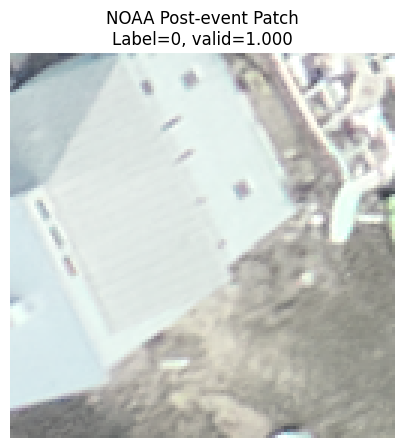


✓ Remote window read successful
✓ 128×128 NOAA RGB patch extracted
✓ NOAA dataset mask evaluated
✓ No complete GeoTIFF download required
✓ Cell 13 complete


In [ ]:
# ============================================================
# CELL 13 — TEST REMOTE NOAA 128x128 PATCH EXTRACTION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import rasterio

from rasterio.session import AWSSession
from rasterio.windows import Window
from rasterio.transform import rowcol

print("=" * 65)
print("REMOTE NOAA PATCH EXTRACTION TEST")
print("=" * 65)

# ------------------------------------------------------------
# 1. Select one training property
# ------------------------------------------------------------
test_property = (
    frozen_split[
        frozen_split["split"] == "train"
    ]
    .iloc[0]
)

property_lon = float(test_property["property_lon"])
property_lat = float(test_property["property_lat"])
noaa_key = test_property["noaa_key"]

s3_uri = f"s3://{NOAA_BUCKET}/{noaa_key}"

print("\nProperty:")
print(f"Longitude : {property_lon:.6f}")
print(f"Latitude  : {property_lat:.6f}")
print(f"Label     : {int(test_property['damage_label'])}")

print("\nNOAA image:")
print(noaa_key)

# ------------------------------------------------------------
# 2. Anonymous NOAA S3 session
# ------------------------------------------------------------
aws_session = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

# ------------------------------------------------------------
# 3. Open remote image
# ------------------------------------------------------------
with rasterio.Env(
    aws_session,
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
):

    with rasterio.open(s3_uri) as src:

        print("\nRaster:")
        print(f"Shape      : {src.height} × {src.width}")
        print(f"Bands      : {src.count}")
        print(f"CRS        : {src.crs}")
        print(f"Resolution : {src.res}")

        # ----------------------------------------------------
        # 4. Convert property coordinate to raster pixel
        # ----------------------------------------------------
        row, col = rowcol(
            src.transform,
            property_lon,
            property_lat
        )

        row = int(row)
        col = int(col)

        print("\nProperty pixel location:")
        print(f"Row : {row}")
        print(f"Col : {col}")

        # ----------------------------------------------------
        # 5. Construct 128 × 128 window
        # ----------------------------------------------------
        half = PATCH_SIZE // 2

        row_start = row - half
        col_start = col - half

        window = Window(
            col_off=col_start,
            row_off=row_start,
            width=PATCH_SIZE,
            height=PATCH_SIZE
        )

        # ----------------------------------------------------
        # 6. Boundary check
        # ----------------------------------------------------
        inside_bounds = (
            row_start >= 0
            and col_start >= 0
            and row_start + PATCH_SIZE <= src.height
            and col_start + PATCH_SIZE <= src.width
        )

        print(f"\nInside raster boundary : {inside_bounds}")

        if not inside_bounds:
            raise ValueError(
                "Selected test property is too close to the "
                "raster boundary for a complete 128×128 patch."
            )

        # ----------------------------------------------------
        # 7. Read RGB patch only
        # ----------------------------------------------------
        patch = src.read(
            indexes=[1, 2, 3],
            window=window
        )

        # CHW -> HWC
        patch = np.moveaxis(
            patch,
            0,
            -1
        )

        # ----------------------------------------------------
        # 8. Read NOAA dataset mask
        # ----------------------------------------------------
        dataset_mask = src.dataset_mask(
            window=window
        )

# ------------------------------------------------------------
# 9. Validity calculation
# ------------------------------------------------------------
valid_fraction = (
    np.count_nonzero(dataset_mask)
    / dataset_mask.size
)

print("\nPatch:")
print(f"Shape          : {patch.shape}")
print(f"Dtype          : {patch.dtype}")
print(f"Minimum value  : {patch.min()}")
print(f"Maximum value  : {patch.max()}")
print(f"Valid fraction : {valid_fraction:.4f}")

accepted = valid_fraction >= 0.95

print(f"Coverage gate  : {'PASS' if accepted else 'FAIL'}")

# ------------------------------------------------------------
# 10. Display test patch
# ------------------------------------------------------------
plt.figure(figsize=(5, 5))
plt.imshow(patch)
plt.title(
    f"NOAA Post-event Patch\n"
    f"Label={int(test_property['damage_label'])}, "
    f"valid={valid_fraction:.3f}"
)
plt.axis("off")
plt.show()

# ------------------------------------------------------------
# 11. Sanity checks
# ------------------------------------------------------------
assert patch.shape == (
    PATCH_SIZE,
    PATCH_SIZE,
    3
), "Unexpected patch shape."

assert dataset_mask.shape == (
    PATCH_SIZE,
    PATCH_SIZE
), "Unexpected dataset-mask shape."

print("\n✓ Remote window read successful")
print("✓ 128×128 NOAA RGB patch extracted")
print("✓ NOAA dataset mask evaluated")
print("✓ No complete GeoTIFF download required")
print("✓ Cell 13 complete")

### 4.3 Batch Extraction of NOAA Development Patches

Post-event NOAA RGB patches are extracted for the frozen training and validation
properties using remote windowed access to the source GeoTIFFs.

Each patch is 128 × 128 pixels and is retained only when it lies completely
inside the assigned raster and at least 95% of its pixels are valid according
to NOAA's dataset mask.

Processing is performed in resumable batches and saved to persistent storage.
The test partition remains sealed.

In [ ]:
# ============================================================
# CELL 14 — RESUMABLE NOAA TRAIN / VALIDATION PATCH EXTRACTION
# ============================================================

import numpy as np
import pandas as pd
import rasterio
import boto3
import time

from pathlib import Path
from rasterio.session import AWSSession
from rasterio.windows import Window
from rasterio.transform import rowcol
from tqdm.auto import tqdm

print("=" * 65)
print("RESUMABLE NOAA TRAIN / VALIDATION PATCH EXTRACTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
NOAA_PATCH_DIR = CHECKPOINT_DIR / "noaa_post_patch_batches"
NOAA_PATCH_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 100
VALID_THRESHOLD = 0.95

# Development only — TEST REMAINS SEALED
development_properties = (
    frozen_split[
        frozen_split["split"].isin(["train", "validation"])
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(development_properties) == 3234
assert not (development_properties["split"] == "test").any()

print(f"\nDevelopment properties : {len(development_properties):,}")
print(
    f"  Train                : "
    f"{(development_properties['split'] == 'train').sum():,}"
)
print(
    f"  Validation           : "
    f"{(development_properties['split'] == 'validation').sum():,}"
)
print("  Test                  : 0  [SEALED]")

print(f"\nPatch size             : {PATCH_SIZE} × {PATCH_SIZE}")
print(f"NOAA valid threshold   : {VALID_THRESHOLD:.2f}")
print(f"Batch size             : {BATCH_SIZE}")
print(f"Persistent directory   : {NOAA_PATCH_DIR}")

# ------------------------------------------------------------
# 2. Anonymous NOAA S3 session
# ------------------------------------------------------------
aws_session = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

# ------------------------------------------------------------
# 3. Determine batches
# ------------------------------------------------------------
n_properties = len(development_properties)

n_batches = int(
    np.ceil(n_properties / BATCH_SIZE)
)

print(f"\nTotal batches          : {n_batches}")

# ------------------------------------------------------------
# 4. Process each batch
# ------------------------------------------------------------
for batch_idx in range(n_batches):

    start_idx = batch_idx * BATCH_SIZE
    end_idx = min(
        start_idx + BATCH_SIZE,
        n_properties
    )

    batch_number = batch_idx + 1

    batch_npz = (
        NOAA_PATCH_DIR /
        f"batch_{batch_number:03d}.npz"
    )

    batch_csv = (
        NOAA_PATCH_DIR /
        f"batch_{batch_number:03d}.csv"
    )

    # --------------------------------------------------------
    # Resume support
    # --------------------------------------------------------
    if batch_npz.exists() and batch_csv.exists():

        print(
            f"Batch {batch_number:03d}/{n_batches:03d} "
            f"already complete — skipping"
        )

        continue

    batch_df = (
        development_properties
        .iloc[start_idx:end_idx]
        .copy()
    )

    patches = []
    metadata_records = []

    print(
        f"\nProcessing batch "
        f"{batch_number:03d}/{n_batches:03d} "
        f"(properties {start_idx}–{end_idx - 1})"
    )

    # --------------------------------------------------------
    # 5. Extract each property patch
    # --------------------------------------------------------
    for _, prop in tqdm(
        batch_df.iterrows(),
        total=len(batch_df),
        leave=False
    ):

        property_index = int(prop["property_index"])
        split_name = prop["split"]
        label = int(prop["damage_label"])

        lon = float(prop["property_lon"])
        lat = float(prop["property_lat"])

        noaa_key = prop["noaa_key"]
        s3_uri = f"s3://{NOAA_BUCKET}/{noaa_key}"

        accepted = False
        rejection_reason = ""
        valid_fraction = np.nan

        try:

            with rasterio.Env(
                aws_session,
                GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
            ):

                with rasterio.open(s3_uri) as src:

                    # ----------------------------------------
                    # Convert property location to pixel
                    # ----------------------------------------
                    row, col = rowcol(
                        src.transform,
                        lon,
                        lat
                    )

                    row = int(row)
                    col = int(col)

                    half = PATCH_SIZE // 2

                    row_start = row - half
                    col_start = col - half

                    # ----------------------------------------
                    # Boundary QC
                    # ----------------------------------------
                    inside_bounds = (
                        row_start >= 0
                        and col_start >= 0
                        and row_start + PATCH_SIZE <= src.height
                        and col_start + PATCH_SIZE <= src.width
                    )

                    if not inside_bounds:

                        rejection_reason = "boundary"

                    else:

                        window = Window(
                            col_off=col_start,
                            row_off=row_start,
                            width=PATCH_SIZE,
                            height=PATCH_SIZE
                        )

                        # ------------------------------------
                        # Read NOAA dataset mask first
                        # ------------------------------------
                        dataset_mask = src.dataset_mask(
                            window=window
                        )

                        valid_fraction = (
                            np.count_nonzero(dataset_mask)
                            / dataset_mask.size
                        )

                        # ------------------------------------
                        # NOAA coverage QC
                        # ------------------------------------
                        if valid_fraction < VALID_THRESHOLD:

                            rejection_reason = (
                                "noaa_post_coverage"
                            )

                        else:

                            # --------------------------------
                            # Read RGB only after QC passes
                            # --------------------------------
                            patch = src.read(
                                indexes=[1, 2, 3],
                                window=window
                            )

                            patch = np.moveaxis(
                                patch,
                                0,
                                -1
                            )

                            if patch.shape != (
                                PATCH_SIZE,
                                PATCH_SIZE,
                                3
                            ):

                                rejection_reason = "shape"

                            else:

                                accepted = True
                                patches.append(patch)

        except Exception as e:

            rejection_reason = (
                "read_error:"
                + type(e).__name__
            )

        # ----------------------------------------------------
        # 6. Metadata record for every attempted property
        # ----------------------------------------------------
        metadata_records.append({
            "property_index": property_index,
            "split": split_name,
            "damage_label": label,
            "property_lon": lon,
            "property_lat": lat,
            "noaa_key": noaa_key,
            "accepted": accepted,
            "valid_fraction": valid_fraction,
            "rejection_reason": rejection_reason
        })

    # --------------------------------------------------------
    # 7. Convert accepted patches to array
    # --------------------------------------------------------
    if len(patches) > 0:

        patch_array = np.stack(
            patches,
            axis=0
        ).astype(np.uint8)

    else:

        patch_array = np.empty(
            (
                0,
                PATCH_SIZE,
                PATCH_SIZE,
                3
            ),
            dtype=np.uint8
        )

    batch_metadata = pd.DataFrame(
        metadata_records
    )

    # --------------------------------------------------------
    # 8. IMPORTANT consistency check
    #
    # NPZ contains accepted patches in exactly the same order
    # as accepted=True rows in the CSV.
    # --------------------------------------------------------
    n_accepted = int(
        batch_metadata["accepted"].sum()
    )

    assert len(patch_array) == n_accepted

    # --------------------------------------------------------
    # 9. Save batch checkpoint
    # --------------------------------------------------------
    np.savez_compressed(
        batch_npz,
        patches=patch_array
    )

    batch_metadata.to_csv(
        batch_csv,
        index=False
    )

    print(
        f"✓ Batch {batch_number:03d}: "
        f"{n_accepted}/{len(batch_metadata)} accepted"
    )

# ------------------------------------------------------------
# 10. Verify every batch exists
# ------------------------------------------------------------
expected_npz = [
    NOAA_PATCH_DIR / f"batch_{i:03d}.npz"
    for i in range(1, n_batches + 1)
]

expected_csv = [
    NOAA_PATCH_DIR / f"batch_{i:03d}.csv"
    for i in range(1, n_batches + 1)
]

missing_npz = [
    p for p in expected_npz
    if not p.exists()
]

missing_csv = [
    p for p in expected_csv
    if not p.exists()
]

if missing_npz or missing_csv:

    print("\nWARNING: Some batches are incomplete.")
    print(f"Missing NPZ batches : {len(missing_npz)}")
    print(f"Missing CSV batches : {len(missing_csv)}")

    raise RuntimeError(
        "Batch extraction incomplete. "
        "Rerun Cell 14 to resume."
    )

# ------------------------------------------------------------
# 11. Combine metadata only
# ------------------------------------------------------------
all_metadata = pd.concat(
    [
        pd.read_csv(p)
        for p in expected_csv
    ],
    ignore_index=True
)

assert len(all_metadata) == len(
    development_properties
)

# ------------------------------------------------------------
# 12. QC summary
# ------------------------------------------------------------
accepted_metadata = all_metadata[
    all_metadata["accepted"] == True
].copy()

rejected_metadata = all_metadata[
    all_metadata["accepted"] == False
].copy()

print("\n" + "=" * 65)
print("NOAA PATCH EXTRACTION SUMMARY")
print("=" * 65)

summary = (
    all_metadata
    .groupby("split")
    .agg(
        attempted=("property_index", "size"),
        accepted=("accepted", "sum")
    )
)

summary["rejected"] = (
    summary["attempted"] -
    summary["accepted"]
)

print(summary)

print("\nRejection reasons:")
if len(rejected_metadata) > 0:
    print(
        rejected_metadata[
            "rejection_reason"
        ].value_counts()
    )
else:
    print("None")

print("\nAccepted class distribution:")
print(
    accepted_metadata
    .groupby(
        ["split", "damage_label"]
    )
    .size()
)

# ------------------------------------------------------------
# 13. Save combined QC metadata
# ------------------------------------------------------------
COMBINED_METADATA_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_09_noaa_post_patch_qc.csv"
)

all_metadata.to_csv(
    COMBINED_METADATA_PATH,
    index=False
)

print("\nCombined QC metadata saved:")
print(COMBINED_METADATA_PATH)

print("\n✓ All development properties attempted")
print("✓ Accepted NOAA patches saved in resumable batches")
print("✓ Rejection reasons recorded")
print("✓ Test partition remained sealed")
print("✓ Cell 14 complete")

RESUMABLE NOAA TRAIN / VALIDATION PATCH EXTRACTION

Development properties : 3,234
  Train                : 2,650
  Validation           : 584
  Test                  : 0  [SEALED]

Patch size             : 128 × 128
NOAA valid threshold   : 0.95
Batch size             : 100
Persistent directory   : /content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/noaa_post_patch_batches

Total batches          : 33

Processing batch 001/033 (properties 0–99)


  0%|          | 0/100 [00:00<?, ?it/s]

✓ Batch 001: 98/100 accepted

Processing batch 002/033 (properties 100–199)


  0%|          | 0/100 [00:00<?, ?it/s]

✓ Batch 002: 89/100 accepted

Processing batch 003/033 (properties 200–299)


...

✓ Batch 031: 96/100 accepted

Processing batch 032/033 (properties 3100–3199)


  0%|          | 0/100 [00:00<?, ?it/s]

✓ Batch 032: 99/100 accepted

Processing batch 033/033 (properties 3200–3233)


  0%|          | 0/34 [00:00<?, ?it/s]

✓ Batch 033: 34/34 accepted

NOAA PATCH EXTRACTION SUMMARY
            attempted  accepted  rejected
split                                    
train            2650      2528       122
validation        584       575         9

Rejection reasons:
rejection_reason
noaa_post_coverage    90
boundary              41
Name: count, dtype: int64

Accepted class distribution:
split       damage_label
train       0               1618
            1                910
validation  0                349
            1                226
dtype: int64

Combined QC metadata saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_09_noaa_post_patch_qc.csv

✓ All development properties attempted
✓ Accepted NOAA patches saved in resumable batches
✓ Rejection reasons recorded
✓ Test partition remained sealed
✓ Cell 14 complete


### 4.4 Pre-event NAIP Imagery Access

USDA National Agriculture Imagery Program (NAIP) 2023 imagery provides the
pre-event reference for the classical change-detection branch.

A small georeferenced image surrounding a training property is requested from
the NAIP 2023 CONUS ImageServer to verify access, spatial coverage, and image
quality before batch preprocessing is performed.

NAIP 2023 PRE-EVENT IMAGE ACCESS TEST

Test property:
Longitude : -82.333552
Latitude  : 26.919276
Label     : 0

Requesting NAIP 2023 imagery...
HTTP status : 200
Response size: 144.0 KB
Content type : image/jpeg

NAIP image:
Shape : (1024, 1024, 3)
Dtype : uint8
Min   : 0
Max   : 255
Non-zero image fraction : 1.0000


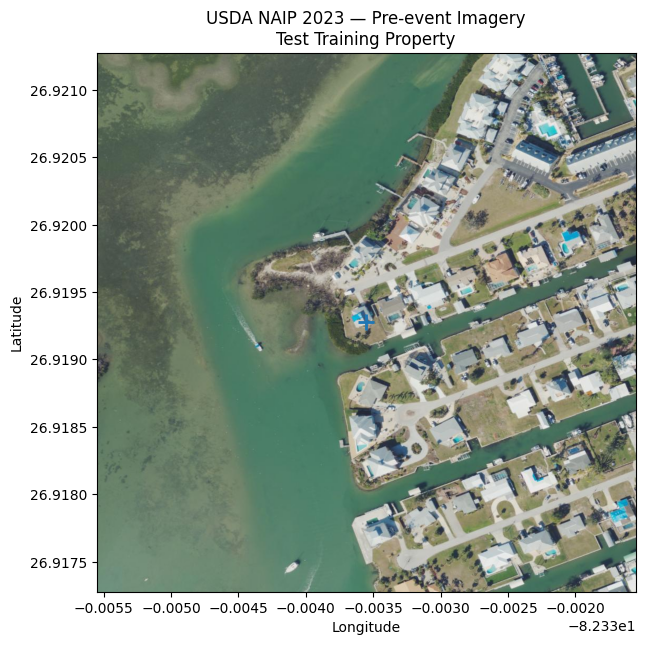


✓ NAIP 2023 server accessible
✓ Pre-event RGB imagery retrieved
✓ Test property lies within requested region
✓ Cell 15 complete


In [ ]:
# ============================================================
# CELL 15 — TEST NAIP 2023 PRE-EVENT IMAGE ACCESS
# ============================================================

import requests
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

print("=" * 65)
print("NAIP 2023 PRE-EVENT IMAGE ACCESS TEST")
print("=" * 65)

# ------------------------------------------------------------
# 1. NAIP 2023 ArcGIS ImageServer
# ------------------------------------------------------------
NAIP_IMAGE_SERVER = (
    "https://imagery.geoplatform.gov/iipp/rest/services/"
    "NAIP/NAIP2023_CONUS/ImageServer/exportImage"
)

# ------------------------------------------------------------
# 2. Use the SAME property tested in Cell 13
# ------------------------------------------------------------
lon = float(test_property["property_lon"])
lat = float(test_property["property_lat"])

print("\nTest property:")
print(f"Longitude : {lon:.6f}")
print(f"Latitude  : {lat:.6f}")
print(f"Label     : {int(test_property['damage_label'])}")

# ------------------------------------------------------------
# 3. Request a moderately larger geographic region
#
# We intentionally request more than 128×128 here because
# registration requires surrounding spatial context.
# ------------------------------------------------------------
HALF_WIDTH_DEG = 0.002

bbox = (
    lon - HALF_WIDTH_DEG,
    lat - HALF_WIDTH_DEG,
    lon + HALF_WIDTH_DEG,
    lat + HALF_WIDTH_DEG
)

bbox_string = ",".join(
    f"{v:.8f}" for v in bbox
)

# ------------------------------------------------------------
# 4. ArcGIS exportImage request
# ------------------------------------------------------------
params = {
    "bbox": bbox_string,
    "bboxSR": "4326",
    "imageSR": "4326",
    "size": "1024,1024",
    "format": "jpgpng",
    "pixelType": "U8",
    "f": "image"
}

print("\nRequesting NAIP 2023 imagery...")

response = requests.get(
    NAIP_IMAGE_SERVER,
    params=params,
    timeout=120
)

print(f"HTTP status : {response.status_code}")
print(
    f"Response size: "
    f"{len(response.content) / 1024:.1f} KB"
)

response.raise_for_status()

# ------------------------------------------------------------
# 5. Verify returned content is actually an image
# ------------------------------------------------------------
content_type = response.headers.get(
    "Content-Type",
    ""
)

print(f"Content type : {content_type}")

if "image" not in content_type.lower():
    print("\nServer response:")
    print(response.text[:1000])

    raise RuntimeError(
        "NAIP server did not return an image."
    )

# ------------------------------------------------------------
# 6. Decode image
# ------------------------------------------------------------
naip_test_image = Image.open(
    BytesIO(response.content)
).convert("RGB")

naip_test_array = np.asarray(
    naip_test_image
)

print("\nNAIP image:")
print(f"Shape : {naip_test_array.shape}")
print(f"Dtype : {naip_test_array.dtype}")
print(f"Min   : {naip_test_array.min()}")
print(f"Max   : {naip_test_array.max()}")

# ------------------------------------------------------------
# 7. Basic validity check
# ------------------------------------------------------------
nonzero_fraction = np.mean(
    np.any(
        naip_test_array > 0,
        axis=2
    )
)

print(
    f"Non-zero image fraction : "
    f"{nonzero_fraction:.4f}"
)

# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------
plt.figure(figsize=(7, 7))

plt.imshow(
    naip_test_array,
    extent=[
        bbox[0],
        bbox[2],
        bbox[1],
        bbox[3]
    ]
)

plt.scatter(
    [lon],
    [lat],
    marker="+",
    s=120,
    linewidths=2
)

plt.title(
    "USDA NAIP 2023 — Pre-event Imagery\n"
    "Test Training Property"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# ------------------------------------------------------------
# 9. Sanity checks
# ------------------------------------------------------------
assert naip_test_array.ndim == 3
assert naip_test_array.shape[2] == 3

print("\n✓ NAIP 2023 server accessible")
print("✓ Pre-event RGB imagery retrieved")
print("✓ Test property lies within requested region")
print("✓ Cell 15 complete")

### 4.5 NAIP–NOAA Registration Test

Pre-event NAIP and post-event NOAA imagery are first aligned geographically using
their georeferencing. SIFT feature matching and RANSAC homography estimation are
then evaluated as an optional refinement.

The estimated homography is accepted only when predefined reliability criteria
are satisfied. Otherwise, the geographically aligned imagery is retained as a
fallback rather than forcing an unreliable registration.

NAIP–NOAA GEOGRAPHIC ALIGNMENT + SIFT/RANSAC TEST

Property:
Longitude : -82.333552
Latitude  : 26.919276
Label     : 0

Common geographic bbox:
left=-82.335552, bottom=26.917276, right=-82.331552, top=26.921276

Working images:
NAIP shape : (1024, 1024, 3)
NOAA shape : (1024, 1024, 3)
NOAA geographic coverage : 1.0000

SIFT:
NAIP keypoints : 6,994
NOAA keypoints : 6,399
Good matches    : 91

Registration diagnostics:
Good matches        : 91
RANSAC inliers      : 14
Inlier ratio        : 0.1538
Warped-area ratio   : 0.9768
Valid-warp fraction : 0.9745

SIFT reliability gate : PASS
Selected method       : SIFT_RANSAC


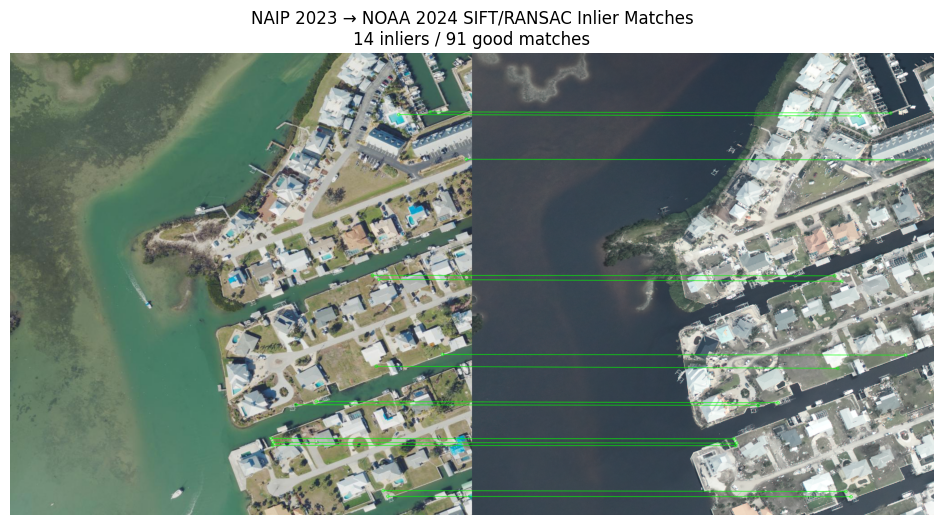

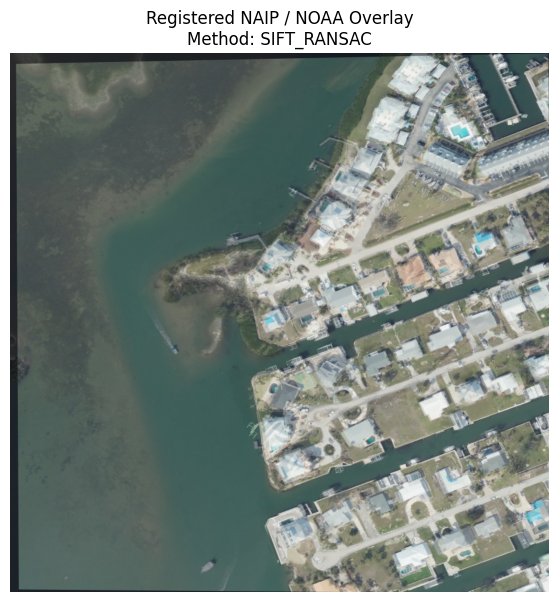


✓ Common geographic context created
✓ SIFT/RANSAC registration evaluated
✓ Reliability gate applied
✓ Unreliable homography will not be forced
✓ Match visualization generated
✓ Cell 16 complete


In [ ]:
# ============================================================
# CELL 16 — SINGLE-PROPERTY NAIP–NOAA REGISTRATION TEST
# Corrected OpenCV 5 visualization version
# ============================================================

import cv2
import numpy as np
import requests
import rasterio
import matplotlib.pyplot as plt
import boto3

from PIL import Image
from io import BytesIO
from rasterio.session import AWSSession
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

print("=" * 65)
print("NAIP–NOAA GEOGRAPHIC ALIGNMENT + SIFT/RANSAC TEST")
print("=" * 65)

# ------------------------------------------------------------
# 1. Frozen registration parameters
# ------------------------------------------------------------
WORK_SIZE = 1024

SIFT_NFEATURES = 12000
LOWE_RATIO = 0.75
RANSAC_THRESHOLD = 4.0

MIN_GOOD_MATCHES = 10
MIN_INLIERS = 10
MIN_INLIER_RATIO = 0.15

MIN_AREA_RATIO = 0.75
MAX_AREA_RATIO = 1.25

MIN_VALID_WARP = 0.90

# ------------------------------------------------------------
# 2. Same training property used previously
# ------------------------------------------------------------
lon = float(test_property["property_lon"])
lat = float(test_property["property_lat"])
label = int(test_property["damage_label"])
noaa_key = test_property["noaa_key"]

# Same geographic context for BOTH images
HALF_WIDTH_DEG = 0.002

left   = lon - HALF_WIDTH_DEG
bottom = lat - HALF_WIDTH_DEG
right  = lon + HALF_WIDTH_DEG
top    = lat + HALF_WIDTH_DEG

print("\nProperty:")
print(f"Longitude : {lon:.6f}")
print(f"Latitude  : {lat:.6f}")
print(f"Label     : {label}")

print("\nCommon geographic bbox:")
print(
    f"left={left:.6f}, bottom={bottom:.6f}, "
    f"right={right:.6f}, top={top:.6f}"
)

# ------------------------------------------------------------
# 3. Request NAIP over common geographic bbox
# ------------------------------------------------------------
bbox_string = (
    f"{left:.8f},{bottom:.8f},"
    f"{right:.8f},{top:.8f}"
)

params = {
    "bbox": bbox_string,
    "bboxSR": "4326",
    "imageSR": "4326",
    "size": f"{WORK_SIZE},{WORK_SIZE}",
    "format": "jpgpng",
    "pixelType": "U8",
    "f": "image"
}

response = requests.get(
    NAIP_IMAGE_SERVER,
    params=params,
    timeout=120
)

response.raise_for_status()

if "image" not in response.headers.get(
    "Content-Type", ""
).lower():

    raise RuntimeError(
        "NAIP server did not return an image."
    )

naip_rgb = np.asarray(
    Image.open(
        BytesIO(response.content)
    ).convert("RGB")
)

# ------------------------------------------------------------
# 4. Read NOAA over exactly the same geographic bbox
# ------------------------------------------------------------
s3_uri = f"s3://{NOAA_BUCKET}/{noaa_key}"

aws_session = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

with rasterio.Env(
    aws_session,
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
):

    with rasterio.open(s3_uri) as src:

        noaa_window = from_bounds(
            left,
            bottom,
            right,
            top,
            transform=src.transform
        )

        noaa_chw = src.read(
            indexes=[1, 2, 3],
            window=noaa_window,
            out_shape=(3, WORK_SIZE, WORK_SIZE),
            resampling=Resampling.bilinear,
            boundless=True,
            fill_value=0
        )

        noaa_mask = src.dataset_mask(
            window=noaa_window,
            out_shape=(WORK_SIZE, WORK_SIZE),
            boundless=True
        )

noaa_rgb = np.moveaxis(
    noaa_chw,
    0,
    -1
).astype(np.uint8)

noaa_valid_fraction = (
    np.count_nonzero(noaa_mask)
    / noaa_mask.size
)

print("\nWorking images:")
print(f"NAIP shape : {naip_rgb.shape}")
print(f"NOAA shape : {noaa_rgb.shape}")
print(
    f"NOAA geographic coverage : "
    f"{noaa_valid_fraction:.4f}"
)

# ------------------------------------------------------------
# 5. Convert to grayscale
# ------------------------------------------------------------
naip_gray = cv2.cvtColor(
    naip_rgb,
    cv2.COLOR_RGB2GRAY
)

noaa_gray = cv2.cvtColor(
    noaa_rgb,
    cv2.COLOR_RGB2GRAY
)

# ------------------------------------------------------------
# 6. SIFT feature detection
# ------------------------------------------------------------
sift = cv2.SIFT_create(
    nfeatures=SIFT_NFEATURES
)

kp_pre, des_pre = sift.detectAndCompute(
    naip_gray,
    None
)

kp_post, des_post = sift.detectAndCompute(
    noaa_gray,
    None
)

print("\nSIFT:")
print(f"NAIP keypoints : {len(kp_pre):,}")
print(f"NOAA keypoints : {len(kp_post):,}")

good_matches = []
H = None
inlier_mask = None

if des_pre is not None and des_post is not None:

    matcher = cv2.BFMatcher(
        cv2.NORM_L2
    )

    knn_matches = matcher.knnMatch(
        des_pre,
        des_post,
        k=2
    )

    for pair in knn_matches:

        if len(pair) < 2:
            continue

        m, n = pair

        if m.distance < LOWE_RATIO * n.distance:
            good_matches.append(m)

print(f"Good matches    : {len(good_matches):,}")

# ------------------------------------------------------------
# 7. RANSAC homography: NAIP -> NOAA
# ------------------------------------------------------------
if len(good_matches) >= 4:

    src_pts = np.float32(
        [
            kp_pre[m.queryIdx].pt
            for m in good_matches
        ]
    ).reshape(-1, 1, 2)

    dst_pts = np.float32(
        [
            kp_post[m.trainIdx].pt
            for m in good_matches
        ]
    ).reshape(-1, 1, 2)

    H, inlier_mask = cv2.findHomography(
        src_pts,
        dst_pts,
        cv2.RANSAC,
        RANSAC_THRESHOLD
    )

# ------------------------------------------------------------
# 8. Registration diagnostics
# ------------------------------------------------------------
n_inliers = 0
inlier_ratio = 0.0
area_ratio = np.nan
valid_warp_fraction = 0.0

if H is not None and inlier_mask is not None:

    n_inliers = int(
        inlier_mask.ravel().sum()
    )

    inlier_ratio = (
        n_inliers / len(good_matches)
        if len(good_matches) > 0
        else 0.0
    )

    corners = np.float32([
        [0, 0],
        [WORK_SIZE - 1, 0],
        [WORK_SIZE - 1, WORK_SIZE - 1],
        [0, WORK_SIZE - 1]
    ]).reshape(-1, 1, 2)

    warped_corners = cv2.perspectiveTransform(
        corners,
        H
    )

    original_area = float(
        (WORK_SIZE - 1) *
        (WORK_SIZE - 1)
    )

    warped_area = abs(
        cv2.contourArea(
            warped_corners.astype(np.float32)
        )
    )

    area_ratio = (
        warped_area / original_area
    )

    support = np.ones(
        (WORK_SIZE, WORK_SIZE),
        dtype=np.uint8
    )

    warped_support = cv2.warpPerspective(
        support,
        H,
        (WORK_SIZE, WORK_SIZE),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    valid_warp_fraction = (
        np.count_nonzero(warped_support)
        / warped_support.size
    )

# ------------------------------------------------------------
# 9. Frozen SIFT reliability gate
# ------------------------------------------------------------
sift_accepted = (
    H is not None
    and len(good_matches) >= MIN_GOOD_MATCHES
    and n_inliers >= MIN_INLIERS
    and inlier_ratio >= MIN_INLIER_RATIO
    and np.isfinite(area_ratio)
    and MIN_AREA_RATIO <= area_ratio <= MAX_AREA_RATIO
    and valid_warp_fraction >= MIN_VALID_WARP
)

print("\nRegistration diagnostics:")
print(f"Good matches        : {len(good_matches)}")
print(f"RANSAC inliers      : {n_inliers}")
print(f"Inlier ratio        : {inlier_ratio:.4f}")
print(f"Warped-area ratio   : {area_ratio:.4f}")
print(
    f"Valid-warp fraction : "
    f"{valid_warp_fraction:.4f}"
)

print(
    "\nSIFT reliability gate : "
    + ("PASS" if sift_accepted else "FAIL")
)

# ------------------------------------------------------------
# 10. Select registration
# ------------------------------------------------------------
if sift_accepted:

    registered_pre = cv2.warpPerspective(
        naip_rgb,
        H,
        (WORK_SIZE, WORK_SIZE),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    registration_method = "SIFT_RANSAC"

else:

    registered_pre = naip_rgb.copy()
    registration_method = "GEOGRAPHIC_FALLBACK"

print(
    f"Selected method       : "
    f"{registration_method}"
)

# ------------------------------------------------------------
# 11. Corrected OpenCV 5 match visualization
# ------------------------------------------------------------
if len(good_matches) > 0:

    # OpenCV 5 expects a list of ordinary Python integers,
    # not NumPy bool/int values.
    if inlier_mask is not None:

        full_match_mask = [
            int(v)
            for v in inlier_mask.ravel()
        ]

        display_matches = good_matches[:100]
        display_mask = full_match_mask[:len(display_matches)]

    else:

        display_matches = good_matches[:100]
        display_mask = None

    # drawMatches expects BGR images
    naip_bgr = cv2.cvtColor(
        naip_rgb,
        cv2.COLOR_RGB2BGR
    )

    noaa_bgr = cv2.cvtColor(
        noaa_rgb,
        cv2.COLOR_RGB2BGR
    )

    if display_mask is not None:

        match_vis = cv2.drawMatches(
            naip_bgr,
            kp_pre,
            noaa_bgr,
            kp_post,
            display_matches,
            None,
            matchColor=(0, 255, 0),
            singlePointColor=None,
            matchesMask=display_mask,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

    else:

        match_vis = cv2.drawMatches(
            naip_bgr,
            kp_pre,
            noaa_bgr,
            kp_post,
            display_matches,
            None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

    match_vis = cv2.cvtColor(
        match_vis,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(14, 6))

    plt.imshow(match_vis)

    plt.title(
        f"NAIP 2023 → NOAA 2024 "
        f"SIFT/RANSAC Inlier Matches\n"
        f"{n_inliers} inliers / "
        f"{len(good_matches)} good matches"
    )

    plt.axis("off")
    plt.show()

# ------------------------------------------------------------
# 12. Registration overlay
# ------------------------------------------------------------
blend = cv2.addWeighted(
    registered_pre,
    0.5,
    noaa_rgb,
    0.5,
    0
)

plt.figure(figsize=(7, 7))

plt.imshow(blend)

plt.title(
    f"Registered NAIP / NOAA Overlay\n"
    f"Method: {registration_method}"
)

plt.axis("off")
plt.show()

# ------------------------------------------------------------
# 13. Final checks
# ------------------------------------------------------------
assert naip_rgb.shape == (
    WORK_SIZE,
    WORK_SIZE,
    3
)

assert noaa_rgb.shape == (
    WORK_SIZE,
    WORK_SIZE,
    3
)

print("\n✓ Common geographic context created")
print("✓ SIFT/RANSAC registration evaluated")
print("✓ Reliability gate applied")
print("✓ Unreliable homography will not be forced")
print("✓ Match visualization generated")
print("✓ Cell 16 complete")

### 4.6 ECC Registration Refinement

When SIFT/RANSAC registration passes the reliability gate, Enhanced Correlation
Coefficient (ECC) alignment is evaluated as a small affine refinement.

ECC is accepted only when the estimated affine transformation remains
geometrically plausible and does not materially reduce valid image coverage.
Otherwise, the accepted SIFT/RANSAC registration is retained.

ECC AFFINE REGISTRATION REFINEMENT

SIFT accepted : True

ECC diagnostics:
Correlation coefficient : 0.668123
Affine determinant      : 0.982876
Singular values         : 0.999197, 0.983666
Translation magnitude   : 13.7057 px
SIFT coverage           : 0.9758
ECC coverage            : 0.9880
Coverage loss           : 0.0000

ECC reliability gate    : PASS

Final registration method : SIFT_RANSAC_ECC


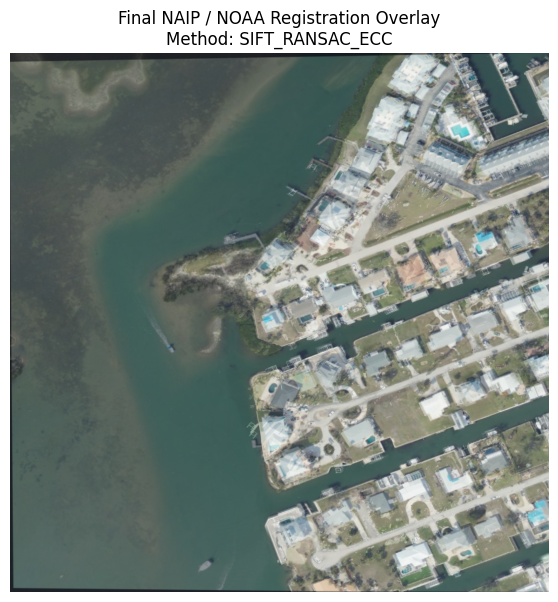

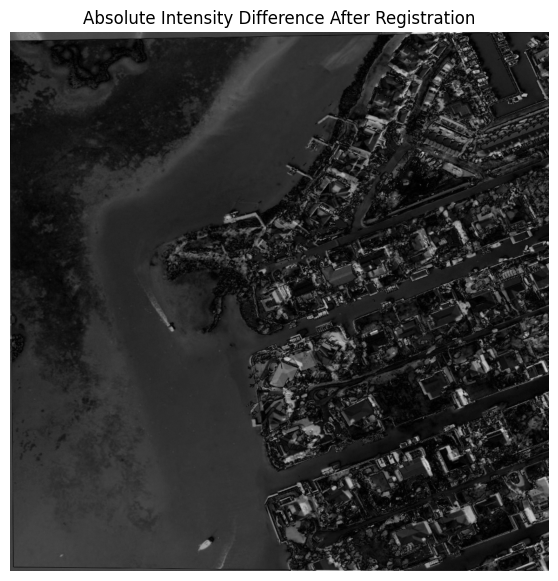


✓ ECC attempted only after reliable SIFT
✓ ECC geometric plausibility evaluated
✓ Coverage preservation evaluated
✓ Final registration selected safely
✓ Cell 17 complete


In [ ]:
# ============================================================
# CELL 17 — GATED ECC AFFINE REFINEMENT
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("ECC AFFINE REGISTRATION REFINEMENT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Frozen ECC acceptance parameters
# ------------------------------------------------------------
ECC_MIN_SINGULAR = 0.95
ECC_MAX_SINGULAR = 1.05
ECC_MAX_TRANSLATION = 50.0
ECC_MAX_COVERAGE_LOSS = 0.02

# ECC optimization settings
ECC_MAX_ITER = 100
ECC_EPS = 1e-6

# ------------------------------------------------------------
# 2. ECC is attempted ONLY after accepted SIFT
# ------------------------------------------------------------
print(f"\nSIFT accepted : {sift_accepted}")

if not sift_accepted:

    print(
        "\nSIFT did not pass the reliability gate."
        "\nECC will therefore NOT be attempted."
    )

    ecc_attempted = False
    ecc_accepted = False
    ecc_correlation = np.nan
    ecc_warp = None

    final_registered_pre = registered_pre.copy()
    final_registration_method = registration_method

else:

    ecc_attempted = True

    # --------------------------------------------------------
    # 3. Convert SIFT-registered NAIP and NOAA to grayscale
    # --------------------------------------------------------
    pre_ecc_gray = cv2.cvtColor(
        registered_pre,
        cv2.COLOR_RGB2GRAY
    ).astype(np.float32) / 255.0

    post_ecc_gray = cv2.cvtColor(
        noaa_rgb,
        cv2.COLOR_RGB2GRAY
    ).astype(np.float32) / 255.0

    # --------------------------------------------------------
    # 4. Initialize ECC with identity affine transform
    #
    # SIFT has already performed the large alignment.
    # ECC estimates only a residual refinement.
    # --------------------------------------------------------
    ecc_warp = np.eye(
        2,
        3,
        dtype=np.float32
    )

    criteria = (
        cv2.TERM_CRITERIA_EPS |
        cv2.TERM_CRITERIA_COUNT,
        ECC_MAX_ITER,
        ECC_EPS
    )

    ecc_error = None

    try:

        ecc_correlation, ecc_warp = (
            cv2.findTransformECC(
                post_ecc_gray,
                pre_ecc_gray,
                ecc_warp,
                cv2.MOTION_AFFINE,
                criteria,
                None,
                5
            )
        )

    except cv2.error as e:

        ecc_error = str(e)
        ecc_correlation = np.nan

# ------------------------------------------------------------
# 5. Evaluate ECC transform
# ------------------------------------------------------------
if ecc_attempted and ecc_error is None:

    A = ecc_warp[:, :2]
    t = ecc_warp[:, 2]

    finite_transform = np.all(
        np.isfinite(ecc_warp)
    )

    determinant = float(
        np.linalg.det(A)
    )

    singular_values = np.linalg.svd(
        A,
        compute_uv=False
    )

    translation_magnitude = float(
        np.linalg.norm(t)
    )

    # --------------------------------------------------------
    # 6. Apply ECC residual transform
    #
    # WARP_INVERSE_MAP is required because findTransformECC
    # estimates the mapping in the convention expected by
    # warpAffine with inverse-map semantics.
    # --------------------------------------------------------
    ecc_refined_pre = cv2.warpAffine(
        registered_pre,
        ecc_warp,
        (WORK_SIZE, WORK_SIZE),
        flags=(
            cv2.INTER_LINEAR |
            cv2.WARP_INVERSE_MAP
        ),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    # --------------------------------------------------------
    # 7. Measure coverage before and after ECC
    # --------------------------------------------------------
    sift_support = np.any(
        registered_pre > 0,
        axis=2
    ).astype(np.uint8)

    ecc_support = cv2.warpAffine(
        sift_support,
        ecc_warp,
        (WORK_SIZE, WORK_SIZE),
        flags=(
            cv2.INTER_NEAREST |
            cv2.WARP_INVERSE_MAP
        ),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    sift_coverage = (
        np.count_nonzero(sift_support)
        / sift_support.size
    )

    ecc_coverage = (
        np.count_nonzero(ecc_support)
        / ecc_support.size
    )

    coverage_loss = max(
        0.0,
        sift_coverage - ecc_coverage
    )

    # --------------------------------------------------------
    # 8. Frozen ECC reliability gate
    # --------------------------------------------------------
    ecc_accepted = (
        finite_transform
        and determinant > 0
        and np.all(
            singular_values >= ECC_MIN_SINGULAR
        )
        and np.all(
            singular_values <= ECC_MAX_SINGULAR
        )
        and translation_magnitude <= ECC_MAX_TRANSLATION
        and coverage_loss <= ECC_MAX_COVERAGE_LOSS
    )

    print("\nECC diagnostics:")
    print(
        f"Correlation coefficient : "
        f"{ecc_correlation:.6f}"
    )
    print(
        f"Affine determinant      : "
        f"{determinant:.6f}"
    )
    print(
        "Singular values         : "
        f"{singular_values[0]:.6f}, "
        f"{singular_values[1]:.6f}"
    )
    print(
        f"Translation magnitude   : "
        f"{translation_magnitude:.4f} px"
    )
    print(
        f"SIFT coverage           : "
        f"{sift_coverage:.4f}"
    )
    print(
        f"ECC coverage            : "
        f"{ecc_coverage:.4f}"
    )
    print(
        f"Coverage loss           : "
        f"{coverage_loss:.4f}"
    )

    print(
        "\nECC reliability gate    : "
        + ("PASS" if ecc_accepted else "FAIL")
    )

    # --------------------------------------------------------
    # 9. Select final registration
    # --------------------------------------------------------
    if ecc_accepted:

        final_registered_pre = (
            ecc_refined_pre.copy()
        )

        final_registration_method = (
            "SIFT_RANSAC_ECC"
        )

    else:

        final_registered_pre = (
            registered_pre.copy()
        )

        final_registration_method = (
            "SIFT_RANSAC"
        )

elif ecc_attempted:

    # ECC optimization itself failed
    ecc_accepted = False

    final_registered_pre = (
        registered_pre.copy()
    )

    final_registration_method = (
        "SIFT_RANSAC"
    )

    print("\nECC optimization failed.")
    print("SIFT/RANSAC registration retained.")

# ------------------------------------------------------------
# 10. Report final selection
# ------------------------------------------------------------
print(
    "\nFinal registration method : "
    f"{final_registration_method}"
)

# ------------------------------------------------------------
# 11. Visual comparison
# ------------------------------------------------------------
final_blend = cv2.addWeighted(
    final_registered_pre,
    0.5,
    noaa_rgb,
    0.5,
    0
)

plt.figure(figsize=(7, 7))
plt.imshow(final_blend)
plt.title(
    "Final NAIP / NOAA Registration Overlay\n"
    f"Method: {final_registration_method}"
)
plt.axis("off")
plt.show()

# ------------------------------------------------------------
# 12. Absolute grayscale difference diagnostic
# ------------------------------------------------------------
final_pre_gray = cv2.cvtColor(
    final_registered_pre,
    cv2.COLOR_RGB2GRAY
)

final_post_gray = cv2.cvtColor(
    noaa_rgb,
    cv2.COLOR_RGB2GRAY
)

difference = cv2.absdiff(
    final_pre_gray,
    final_post_gray
)

plt.figure(figsize=(7, 7))
plt.imshow(
    difference,
    cmap="gray"
)
plt.title(
    "Absolute Intensity Difference After Registration"
)
plt.axis("off")
plt.show()

print("\n✓ ECC attempted only after reliable SIFT")
print("✓ ECC geometric plausibility evaluated")
print("✓ Coverage preservation evaluated")
print("✓ Final registration selected safely")
print("✓ Cell 17 complete")

### 4.7 Property-Level Paired Patch and Change Diagnostics

Following registration, a 128 × 128 property-centered patch is extracted from
both the pre-event NAIP image and the post-event NOAA image.

Because the two image sources differ substantially in illumination and sensor
characteristics, pre-event luminance is normalized to the post-event image before
change analysis. Structural Similarity (SSIM) and CIELAB color difference are
then evaluated as complementary indicators of structural and radiometric change.

PROPERTY-LEVEL PAIRED PATCH + CHANGE DIAGNOSTICS

Raw paired patches:
PRE shape  : (128, 128, 3)
POST shape : (128, 128, 3)
PRE valid fraction  : 1.0000
POST valid fraction : 1.0000

Raw luminance:
PRE  mean=126.68, std=43.04
POST mean=139.40, std=54.06

After histogram matching:
PRE  mean=139.14, std=53.13
POST mean=139.40, std=54.06

SSIM:
Global SSIM score : 0.2420
Change-map range  : 0.0298 – 1.6949

LAB color difference:
Range : 0.00 – 182.54
Mean  : 38.26

Combined diagnostic:
Range : 0.0063 – 0.9091
Mean  : 0.3212


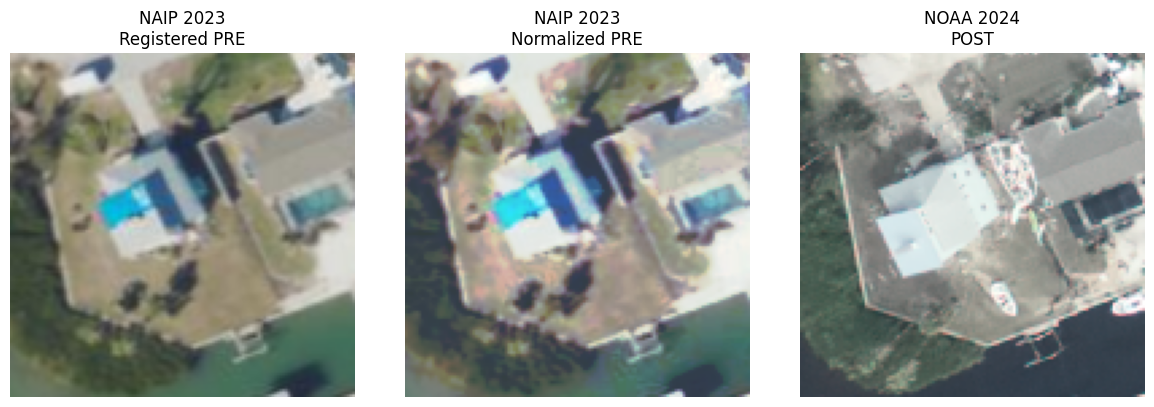

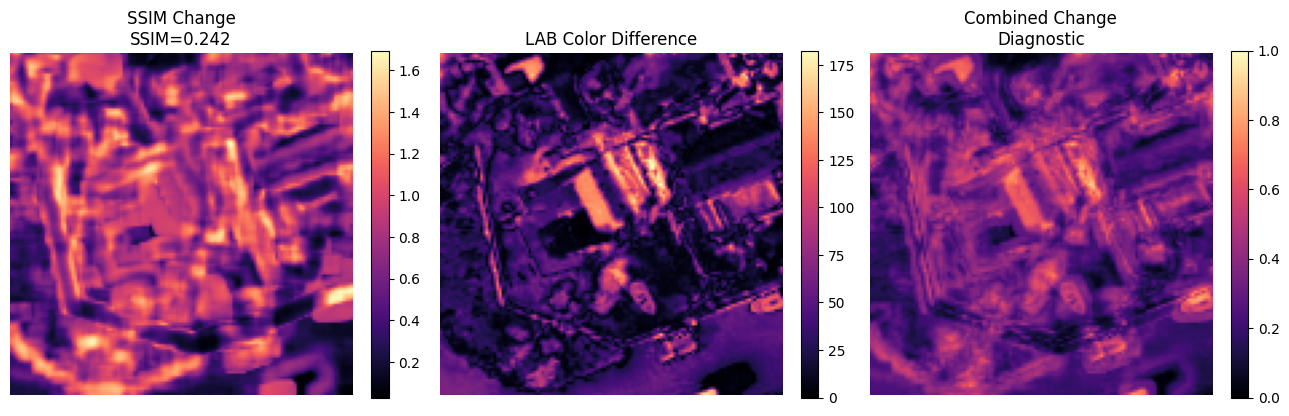


SINGLE-PROPERTY PREPROCESSING RESULT
Ground-truth label     : 0
Ground-truth class     : NON-DAMAGED / NEGATIVE
Registration method    : SIFT_RANSAC_ECC
PRE coverage           : 1.0000
POST coverage          : 1.0000
Global SSIM            : 0.2420
Mean LAB difference    : 38.2581

✓ Registered 128×128 PRE patch extracted
✓ Corresponding 128×128 POST patch extracted
✓ Luminance/radiometric normalization applied
✓ SSIM structural-change diagnostic computed
✓ LAB color-change diagnostic computed
✓ Single-property classical preprocessing validated
✓ Cell 18 complete


In [ ]:
# ============================================================
# CELL 18 — PROPERTY-LEVEL PAIRED PATCH + CHANGE DIAGNOSTICS
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.exposure import match_histograms
from skimage.metrics import structural_similarity

print("=" * 65)
print("PROPERTY-LEVEL PAIRED PATCH + CHANGE DIAGNOSTICS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Extract central 128×128 property patch
#
# Both working images share the same geographic frame.
# final_registered_pre has already been aligned to NOAA.
# ------------------------------------------------------------
center = WORK_SIZE // 2
half = PATCH_SIZE // 2

r0 = center - half
r1 = center + half

c0 = center - half
c1 = center + half

pre_patch = final_registered_pre[
    r0:r1,
    c0:c1
].copy()

post_patch = noaa_rgb[
    r0:r1,
    c0:c1
].copy()

print("\nRaw paired patches:")
print(f"PRE shape  : {pre_patch.shape}")
print(f"POST shape : {post_patch.shape}")

assert pre_patch.shape == (
    PATCH_SIZE,
    PATCH_SIZE,
    3
)

assert post_patch.shape == (
    PATCH_SIZE,
    PATCH_SIZE,
    3
)

# ------------------------------------------------------------
# 2. Check registered PRE coverage
# ------------------------------------------------------------
pre_valid_mask = np.any(
    pre_patch > 0,
    axis=2
)

pre_valid_fraction = (
    np.count_nonzero(pre_valid_mask)
    / pre_valid_mask.size
)

print(
    f"PRE valid fraction  : "
    f"{pre_valid_fraction:.4f}"
)

# NOAA validity for this test property was already verified,
# but calculate a simple RGB-support diagnostic here as well.
post_valid_mask = np.any(
    post_patch > 0,
    axis=2
)

post_valid_fraction = (
    np.count_nonzero(post_valid_mask)
    / post_valid_mask.size
)

print(
    f"POST valid fraction : "
    f"{post_valid_fraction:.4f}"
)

# ------------------------------------------------------------
# 3. Raw luminance statistics
# ------------------------------------------------------------
pre_gray_raw = cv2.cvtColor(
    pre_patch,
    cv2.COLOR_RGB2GRAY
)

post_gray = cv2.cvtColor(
    post_patch,
    cv2.COLOR_RGB2GRAY
)

print("\nRaw luminance:")
print(
    f"PRE  mean={pre_gray_raw.mean():.2f}, "
    f"std={pre_gray_raw.std():.2f}"
)

print(
    f"POST mean={post_gray.mean():.2f}, "
    f"std={post_gray.std():.2f}"
)

# ------------------------------------------------------------
# 4. Histogram-match PRE to POST
#
# This reduces broad sensor/illumination differences while
# retaining spatial structure.
# ------------------------------------------------------------
pre_matched = match_histograms(
    pre_patch,
    post_patch,
    channel_axis=-1
)

pre_matched = np.clip(
    pre_matched,
    0,
    255
).astype(np.uint8)

pre_gray_matched = cv2.cvtColor(
    pre_matched,
    cv2.COLOR_RGB2GRAY
)

print("\nAfter histogram matching:")
print(
    f"PRE  mean={pre_gray_matched.mean():.2f}, "
    f"std={pre_gray_matched.std():.2f}"
)

print(
    f"POST mean={post_gray.mean():.2f}, "
    f"std={post_gray.std():.2f}"
)

# ------------------------------------------------------------
# 5. SSIM structural change
#
# structural_similarity returns similarity in [-1, 1].
# We convert it to a change representation:
#
#     SSIM change = 1 - local SSIM
#
# Larger values indicate greater structural disagreement.
# ------------------------------------------------------------
ssim_score, ssim_map = structural_similarity(
    pre_gray_matched,
    post_gray,
    data_range=255,
    full=True
)

ssim_change = 1.0 - ssim_map

print("\nSSIM:")
print(f"Global SSIM score : {ssim_score:.4f}")
print(
    f"Change-map range  : "
    f"{ssim_change.min():.4f} – "
    f"{ssim_change.max():.4f}"
)

# ------------------------------------------------------------
# 6. CIELAB color difference
#
# OpenCV LAB is used consistently for both images.
# Euclidean distance provides a simple complementary
# radiometric/color-change measure.
# ------------------------------------------------------------
pre_lab = cv2.cvtColor(
    pre_matched,
    cv2.COLOR_RGB2LAB
).astype(np.float32)

post_lab = cv2.cvtColor(
    post_patch,
    cv2.COLOR_RGB2LAB
).astype(np.float32)

lab_difference = np.linalg.norm(
    pre_lab - post_lab,
    axis=2
)

print("\nLAB color difference:")
print(
    f"Range : "
    f"{lab_difference.min():.2f} – "
    f"{lab_difference.max():.2f}"
)

print(
    f"Mean  : "
    f"{lab_difference.mean():.2f}"
)

# ------------------------------------------------------------
# 7. Normalize LAB difference for visualization / combination
# ------------------------------------------------------------
lab_norm = cv2.normalize(
    lab_difference,
    None,
    0.0,
    1.0,
    cv2.NORM_MINMAX
)

# SSIM change can theoretically reach 2 because local SSIM
# can be negative. Normalize for visualization only.
ssim_norm = cv2.normalize(
    ssim_change.astype(np.float32),
    None,
    0.0,
    1.0,
    cv2.NORM_MINMAX
)

# ------------------------------------------------------------
# 8. Simple combined change diagnostic
#
# Equal weighting is used here only as a diagnostic.
# Final classical feature construction/thresholding will be
# determined using TRAIN/VALIDATION, not this single example.
# ------------------------------------------------------------
combined_change = (
    0.5 * ssim_norm +
    0.5 * lab_norm
)

print("\nCombined diagnostic:")
print(
    f"Range : "
    f"{combined_change.min():.4f} – "
    f"{combined_change.max():.4f}"
)

print(
    f"Mean  : "
    f"{combined_change.mean():.4f}"
)

# ------------------------------------------------------------
# 9. Display PRE / normalized PRE / POST
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4)
)

axes[0].imshow(pre_patch)
axes[0].set_title(
    "NAIP 2023\nRegistered PRE"
)
axes[0].axis("off")

axes[1].imshow(pre_matched)
axes[1].set_title(
    "NAIP 2023\nNormalized PRE"
)
axes[1].axis("off")

axes[2].imshow(post_patch)
axes[2].set_title(
    "NOAA 2024\nPOST"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Display change diagnostics
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4)
)

im0 = axes[0].imshow(
    ssim_change,
    cmap="magma"
)
axes[0].set_title(
    f"SSIM Change\nSSIM={ssim_score:.3f}"
)
axes[0].axis("off")
plt.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046
)

im1 = axes[1].imshow(
    lab_difference,
    cmap="magma"
)
axes[1].set_title(
    "LAB Color Difference"
)
axes[1].axis("off")
plt.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046
)

im2 = axes[2].imshow(
    combined_change,
    cmap="magma",
    vmin=0,
    vmax=1
)
axes[2].set_title(
    "Combined Change\nDiagnostic"
)
axes[2].axis("off")
plt.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Report test property's interpretation
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("SINGLE-PROPERTY PREPROCESSING RESULT")
print("=" * 65)

print(f"Ground-truth label     : {label}")
print(
    "Ground-truth class     : "
    + (
        "DAMAGED / POSITIVE"
        if label == 1
        else "NON-DAMAGED / NEGATIVE"
    )
)

print(
    f"Registration method    : "
    f"{final_registration_method}"
)

print(
    f"PRE coverage           : "
    f"{pre_valid_fraction:.4f}"
)

print(
    f"POST coverage          : "
    f"{post_valid_fraction:.4f}"
)

print(
    f"Global SSIM            : "
    f"{ssim_score:.4f}"
)

print(
    f"Mean LAB difference    : "
    f"{lab_difference.mean():.4f}"
)

# ------------------------------------------------------------
# 12. Final checks
# ------------------------------------------------------------
assert pre_valid_fraction >= 0.95, (
    "Registered PRE patch failed coverage QC."
)

assert post_valid_fraction >= 0.95, (
    "POST patch failed coverage QC."
)

print("\n✓ Registered 128×128 PRE patch extracted")
print("✓ Corresponding 128×128 POST patch extracted")
print("✓ Luminance/radiometric normalization applied")
print("✓ SSIM structural-change diagnostic computed")
print("✓ LAB color-change diagnostic computed")
print("✓ Single-property classical preprocessing validated")
print("✓ Cell 18 complete")

### 4.8 Production Preprocessing Workload

Before applying paired NAIP–NOAA preprocessing to the full development dataset,
the accepted properties are summarized by geographic NOAA tile.

This identifies repeated spatial contexts and avoids unnecessary preprocessing
work while preserving the frozen train/validation split and quality-control
criteria. The test partition remains sealed.

In [ ]:
# ============================================================
# CELL 19 — PRODUCTION PREPROCESSING WORKLOAD BY NOAA TILE
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("PRODUCTION PREPROCESSING WORKLOAD")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load NOAA QC metadata produced by Cell 14
# ------------------------------------------------------------
qc_metadata = pd.read_csv(
    COMBINED_METADATA_PATH
)

print(f"\nNOAA QC records loaded : {len(qc_metadata):,}")

# Keep only NOAA-QC accepted development properties
accepted_qc = qc_metadata[
    qc_metadata["accepted"] == True
].copy()

print(
    f"NOAA-QC accepted       : "
    f"{len(accepted_qc):,}"
)

# ------------------------------------------------------------
# 2. Recover geographic tile ID and frozen assignment info
# ------------------------------------------------------------
production_candidates = (
    frozen_split[
        [
            "property_index",
            "geo_tile_id",
            "noaa_key",
            "noaa_filename",
            "noaa_folder",
            "split",
            "damage_label",
            "property_lon",
            "property_lat"
        ]
    ]
    .merge(
        accepted_qc[
            [
                "property_index",
                "valid_fraction"
            ]
        ],
        on="property_index",
        how="inner"
    )
)

# ------------------------------------------------------------
# 3. Sanity checks
# ------------------------------------------------------------
assert len(production_candidates) == len(
    accepted_qc
)

assert not (
    production_candidates["split"] == "test"
).any()

assert (
    production_candidates["valid_fraction"]
    >= 0.95
).all()

print("\nCandidate properties:")
print(
    production_candidates["split"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 4. Summarize workload by geographic tile
# ------------------------------------------------------------
tile_workload = (
    production_candidates
    .groupby(
        [
            "split",
            "geo_tile_id",
            "noaa_key",
            "noaa_filename",
            "noaa_folder"
        ],
        as_index=False
    )
    .agg(
        n_properties=("property_index", "size"),
        n_positive=("damage_label", "sum"),
        min_lon=("property_lon", "min"),
        max_lon=("property_lon", "max"),
        min_lat=("property_lat", "min"),
        max_lat=("property_lat", "max")
    )
)

tile_workload["n_negative"] = (
    tile_workload["n_properties"]
    - tile_workload["n_positive"]
)

# ------------------------------------------------------------
# 5. Report workload
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("TILE-LEVEL WORKLOAD")
print("=" * 65)

for split_name in ["train", "validation"]:

    subset = tile_workload[
        tile_workload["split"] == split_name
    ]

    print(
        f"{split_name.upper():10s}: "
        f"{len(subset):3d} tiles | "
        f"{subset['n_properties'].sum():4d} properties"
    )

print(
    f"\nTotal development tiles : "
    f"{tile_workload['geo_tile_id'].nunique():,}"
)

print(
    f"Total properties        : "
    f"{tile_workload['n_properties'].sum():,}"
)

print("\nProperties per tile:")
print(
    tile_workload["n_properties"]
    .describe()
)

# ------------------------------------------------------------
# 6. Show largest workloads
# ------------------------------------------------------------
largest_tiles = (
    tile_workload
    .sort_values(
        "n_properties",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

print("\nLargest 15 tile workloads:")
display(
    largest_tiles[
        [
            "split",
            "geo_tile_id",
            "n_properties",
            "n_positive",
            "n_negative",
            "noaa_folder"
        ]
    ]
)

# ------------------------------------------------------------
# 7. Quantify possible reuse
# ------------------------------------------------------------
n_properties = len(
    production_candidates
)

n_tiles = tile_workload[
    "geo_tile_id"
].nunique()

print("\nPotential registration workload reduction:")
print(
    f"Property-wise contexts : "
    f"{n_properties:,}"
)

print(
    f"Tile-wise groups        : "
    f"{n_tiles:,}"
)

print(
    f"Average properties/tile : "
    f"{n_properties / n_tiles:.2f}"
)

# ------------------------------------------------------------
# 8. Save persistent production workload
# ------------------------------------------------------------
PRODUCTION_CANDIDATES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_10_production_candidates.csv"
)

TILE_WORKLOAD_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_10_tile_workload.csv"
)

production_candidates.to_csv(
    PRODUCTION_CANDIDATES_PATH,
    index=False
)

tile_workload.to_csv(
    TILE_WORKLOAD_PATH,
    index=False
)

print("\nCheckpoints saved:")
print(PRODUCTION_CANDIDATES_PATH)
print(TILE_WORKLOAD_PATH)

# ------------------------------------------------------------
# 9. Final verification
# ------------------------------------------------------------
assert (
    tile_workload["n_properties"].sum()
    == len(production_candidates)
)

assert set(
    production_candidates["split"].unique()
) == {
    "train",
    "validation"
}

print("\n✓ NOAA-QC accepted development set recovered")
print("✓ Properties organized by geographic NOAA tile")
print("✓ Test partition remains sealed")
print("✓ Production workload checkpoints created")
print("✓ Cell 19 complete")

PRODUCTION PREPROCESSING WORKLOAD

NOAA QC records loaded : 3,234
NOAA-QC accepted       : 3,103

Candidate properties:
split
train         2528
validation     575
Name: count, dtype: int64

TILE-LEVEL WORKLOAD
TRAIN     :  69 tiles | 2528 properties
VALIDATION:  11 tiles |  575 properties

Total development tiles : 80
Total properties        : 3,103

Properties per tile:
count     80.000000
mean      38.787500
std       52.740994
min        1.000000
25%        3.750000
50%       21.000000
75%       50.250000
max      323.000000
Name: n_properties, dtype: float64

Largest 15 tile workloads:


,split,geo_tile_id,n_properties,n_positive,n_negative,noaa_folder
0,train,0820600w265830n,323,17,306,20241013a_RGB
1,train,0822145w265530n,206,127,79,20241011b_RGB
2,validation,0820645w265830n,151,12,139,20241013a_RGB
3,train,0822145w265615n,124,103,21,20241011b_RGB
4,train,0822015w265700n,122,65,57,20241011b_RGB
5,train,0821930w265400n,119,81,38,20241011b_RGB
6,train,0820300w265830n,114,14,100,20241013a_RGB
7,train,0822015w265530n,111,57,54,20241011b_RGB
8,train,0820430w265745n,102,41,61,20241013a_RGB
9,train,0822230w265700n,99,52,47,20241011b_RGB



Potential registration workload reduction:
Property-wise contexts : 3,103
Tile-wise groups        : 80
Average properties/tile : 38.79

Checkpoints saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_10_production_candidates.csv
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_10_tile_workload.csv

✓ NOAA-QC accepted development set recovered
✓ Properties organized by geographic NOAA tile
✓ Test partition remains sealed
✓ Production workload checkpoints created
✓ Cell 19 complete


### 4.9 Spatial Distribution Within NOAA Tiles

The spatial distribution of labeled properties within each NOAA tile is examined
before defining reusable registration contexts. Registration is not automatically
assumed to be constant across an entire tile; instead, the analysis determines
whether properties are sufficiently localized to support efficient local
registration while preserving geometric reliability.

In [ ]:
# ============================================================
# CELL 20 — WITHIN-TILE PROPERTY SPATIAL DISTRIBUTION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("WITHIN-TILE PROPERTY SPATIAL DISTRIBUTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Work from the frozen production candidates
# ------------------------------------------------------------
df = production_candidates.copy()

# ------------------------------------------------------------
# 2. Approximate local distances in metres
#
# At latitude ~27 degrees:
#   1 degree latitude  ≈ 111.32 km
#   longitude scaling depends on latitude.
# ------------------------------------------------------------
METERS_PER_DEG_LAT = 111_320.0

tile_spread_records = []

for (
    split_name,
    tile_id
), group in df.groupby(
    ["split", "geo_tile_id"]
):

    mean_lat = group["property_lat"].mean()

    meters_per_deg_lon = (
        111_320.0 *
        np.cos(
            np.deg2rad(mean_lat)
        )
    )

    lon_span_m = (
        group["property_lon"].max()
        - group["property_lon"].min()
    ) * meters_per_deg_lon

    lat_span_m = (
        group["property_lat"].max()
        - group["property_lat"].min()
    ) * METERS_PER_DEG_LAT

    diagonal_span_m = np.sqrt(
        lon_span_m ** 2 +
        lat_span_m ** 2
    )

    tile_spread_records.append({
        "split": split_name,
        "geo_tile_id": tile_id,
        "n_properties": len(group),
        "lon_span_m": lon_span_m,
        "lat_span_m": lat_span_m,
        "diagonal_span_m": diagonal_span_m
    })

tile_spread = pd.DataFrame(
    tile_spread_records
)

# ------------------------------------------------------------
# 3. Summary
# ------------------------------------------------------------
print(
    f"\nTiles analyzed : "
    f"{len(tile_spread):,}"
)

print("\nWithin-tile property diagonal span (metres):")
print(
    tile_spread[
        "diagonal_span_m"
    ].describe()
)

# ------------------------------------------------------------
# 4. Distribution across useful distance ranges
# ------------------------------------------------------------
bins = [
    -np.inf,
    100,
    250,
    500,
    750,
    1000,
    np.inf
]

labels = [
    "≤100 m",
    "100–250 m",
    "250–500 m",
    "500–750 m",
    "750–1000 m",
    ">1000 m"
]

tile_spread["span_category"] = pd.cut(
    tile_spread["diagonal_span_m"],
    bins=bins,
    labels=labels
)

print("\nTiles by property spatial span:")
print(
    tile_spread[
        "span_category"
    ].value_counts(
        sort=False
    )
)

# ------------------------------------------------------------
# 5. Largest spatial spreads
# ------------------------------------------------------------
largest_spreads = (
    tile_spread
    .sort_values(
        "diagonal_span_m",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

print("\nLargest 15 within-tile property spreads:")

display(
    largest_spreads[
        [
            "split",
            "geo_tile_id",
            "n_properties",
            "lon_span_m",
            "lat_span_m",
            "diagonal_span_m"
        ]
    ].round(1)
)

# ------------------------------------------------------------
# 6. Property-weighted view
# ------------------------------------------------------------
total_properties = tile_spread[
    "n_properties"
].sum()

print("\nProperties represented by span category:")

property_span_summary = (
    tile_spread
    .groupby(
        "span_category",
        observed=False
    )["n_properties"]
    .sum()
)

property_span_percent = (
    100.0 *
    property_span_summary /
    total_properties
)

span_table = pd.DataFrame({
    "properties": property_span_summary,
    "percent": property_span_percent
})

display(
    span_table.round(2)
)

# ------------------------------------------------------------
# 7. Save checkpoint
# ------------------------------------------------------------
TILE_SPREAD_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_11_tile_spatial_spread.csv"
)

tile_spread.to_csv(
    TILE_SPREAD_PATH,
    index=False
)

print("\nCheckpoint saved:")
print(TILE_SPREAD_PATH)

print("\n✓ Within-tile spatial spread quantified")
print("✓ No registration assumptions changed")
print("✓ Test partition remains sealed")
print("✓ Cell 20 complete")

WITHIN-TILE PROPERTY SPATIAL DISTRIBUTION

Tiles analyzed : 80

Within-tile property diagonal span (metres):
count      80.000000
mean      899.834906
std       559.959836
min         0.000000
25%       523.439356
50%       983.767899
75%      1337.663439
max      1800.438643
Name: diagonal_span_m, dtype: float64

Tiles by property spatial span:
span_category
≤100 m        15
100–250 m      2
250–500 m      3
500–750 m      8
750–1000 m    13
>1000 m       39
Name: count, dtype: int64

Largest 15 within-tile property spreads:


,split,geo_tile_id,n_properties,lon_span_m,lat_span_m,diagonal_span_m
0,validation,0820645w265830n,151,1193.4,1348.1,1800.4
1,train,0820600w265830n,323,1230.3,1271.4,1769.2
2,train,0821845w265145n,29,1187.4,1060.8,1592.2
3,train,0822145w265615n,124,1050.6,1194.6,1590.9
4,train,0822015w265615n,82,1167.0,1080.3,1590.2
5,train,0821800w265100n,30,989.9,1232.7,1580.9
6,train,0822145w265530n,206,768.4,1373.4,1573.7
7,validation,0822100w265700n,84,1226.6,948.7,1550.7
8,train,0821715w265100n,37,1114.6,1070.8,1545.7
9,train,0821930w265315n,41,1156.2,986.7,1520.0



Properties represented by span category:


,properties,percent
span_category,,
≤100 m,18,0.58
100–250 m,11,0.35
250–500 m,84,2.71
500–750 m,86,2.77
750–1000 m,302,9.73
>1000 m,2602,83.85



Checkpoint saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_11_tile_spatial_spread.csv

✓ Within-tile spatial spread quantified
✓ No registration assumptions changed
✓ Test partition remains sealed
✓ Cell 20 complete


### 4.10 Production Registration Runtime Benchmark

Because registration must remain local to each property, a small subset of
training properties is timed before full production preprocessing is launched.

The benchmark uses the same NAIP retrieval, geographic alignment, SIFT/RANSAC,
and gated ECC procedure established during the single-property validation.
Its purpose is computational planning only; it does not alter the frozen
dataset, labels, split, registration thresholds, or model-selection procedure.

In [ ]:
# ============================================================
# CELL 21 — PRODUCTION REGISTRATION RUNTIME BENCHMARK
# ============================================================

import time
import cv2
import numpy as np
import requests
import rasterio
import boto3

from PIL import Image
from io import BytesIO
from rasterio.session import AWSSession
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

print("=" * 65)
print("PRODUCTION REGISTRATION RUNTIME BENCHMARK")
print("=" * 65)

# ------------------------------------------------------------
# 1. Benchmark configuration
# ------------------------------------------------------------
BENCHMARK_N = 10

# Use the already frozen TRAIN partition only.
# Evenly spaced rows give a deterministic sample without
# selecting cases according to registration/model performance.
train_candidates = (
    production_candidates[
        production_candidates["split"] == "train"
    ]
    .sort_values("property_index")
    .reset_index(drop=True)
)

benchmark_positions = np.linspace(
    0,
    len(train_candidates) - 1,
    BENCHMARK_N,
    dtype=int
)

benchmark_df = (
    train_candidates
    .iloc[benchmark_positions]
    .copy()
    .reset_index(drop=True)
)

print(f"\nBenchmark properties : {len(benchmark_df)}")
print("Partition            : TRAIN only")
print(f"Working size         : {WORK_SIZE} × {WORK_SIZE}")
print("Test partition       : SEALED")

# ------------------------------------------------------------
# 2. Persistent HTTP session
# ------------------------------------------------------------
http_session = requests.Session()

http_session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

aws_session_benchmark = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

# ------------------------------------------------------------
# 3. Registration benchmark function
# ------------------------------------------------------------
def benchmark_registration(prop):

    start_time = time.perf_counter()

    lon = float(prop["property_lon"])
    lat = float(prop["property_lat"])
    noaa_key = prop["noaa_key"]

    left = lon - HALF_WIDTH_DEG
    bottom = lat - HALF_WIDTH_DEG
    right = lon + HALF_WIDTH_DEG
    top = lat + HALF_WIDTH_DEG

    # --------------------------------------------------------
    # NAIP request
    # --------------------------------------------------------
    bbox_string = (
        f"{left:.8f},{bottom:.8f},"
        f"{right:.8f},{top:.8f}"
    )

    params = {
        "bbox": bbox_string,
        "bboxSR": "4326",
        "imageSR": "4326",
        "size": f"{WORK_SIZE},{WORK_SIZE}",
        "format": "jpgpng",
        "pixelType": "U8",
        "f": "image"
    }

    response = http_session.get(
        NAIP_IMAGE_SERVER,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    if "image" not in response.headers.get(
        "Content-Type", ""
    ).lower():

        raise RuntimeError(
            "NAIP server did not return an image."
        )

    naip = np.asarray(
        Image.open(
            BytesIO(response.content)
        ).convert("RGB")
    )

    # --------------------------------------------------------
    # NOAA request over same geographic context
    # --------------------------------------------------------
    s3_uri = (
        f"s3://{NOAA_BUCKET}/{noaa_key}"
    )

    with rasterio.Env(
        aws_session_benchmark,
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
    ):

        with rasterio.open(s3_uri) as src:

            window = from_bounds(
                left,
                bottom,
                right,
                top,
                transform=src.transform
            )

            noaa_chw = src.read(
                indexes=[1, 2, 3],
                window=window,
                out_shape=(
                    3,
                    WORK_SIZE,
                    WORK_SIZE
                ),
                resampling=Resampling.bilinear,
                boundless=True,
                fill_value=0
            )

    noaa = np.moveaxis(
        noaa_chw,
        0,
        -1
    ).astype(np.uint8)

    # --------------------------------------------------------
    # SIFT
    # --------------------------------------------------------
    pre_gray = cv2.cvtColor(
        naip,
        cv2.COLOR_RGB2GRAY
    )

    post_gray = cv2.cvtColor(
        noaa,
        cv2.COLOR_RGB2GRAY
    )

    sift_local = cv2.SIFT_create(
        nfeatures=SIFT_NFEATURES
    )

    kp_pre, des_pre = (
        sift_local.detectAndCompute(
            pre_gray,
            None
        )
    )

    kp_post, des_post = (
        sift_local.detectAndCompute(
            post_gray,
            None
        )
    )

    good = []
    H_local = None
    mask_local = None

    if (
        des_pre is not None
        and des_post is not None
    ):

        matcher = cv2.BFMatcher(
            cv2.NORM_L2
        )

        knn = matcher.knnMatch(
            des_pre,
            des_post,
            k=2
        )

        for pair in knn:

            if len(pair) < 2:
                continue

            m, n = pair

            if (
                m.distance
                < LOWE_RATIO * n.distance
            ):
                good.append(m)

    if len(good) >= 4:

        src_pts = np.float32([
            kp_pre[m.queryIdx].pt
            for m in good
        ]).reshape(-1, 1, 2)

        dst_pts = np.float32([
            kp_post[m.trainIdx].pt
            for m in good
        ]).reshape(-1, 1, 2)

        H_local, mask_local = (
            cv2.findHomography(
                src_pts,
                dst_pts,
                cv2.RANSAC,
                RANSAC_THRESHOLD
            )
        )

    # --------------------------------------------------------
    # SIFT reliability diagnostics
    # --------------------------------------------------------
    n_inliers_local = 0
    inlier_ratio_local = 0.0
    area_ratio_local = np.nan
    warp_fraction_local = 0.0

    if (
        H_local is not None
        and mask_local is not None
    ):

        n_inliers_local = int(
            mask_local.ravel().sum()
        )

        inlier_ratio_local = (
            n_inliers_local / len(good)
        )

        corners = np.float32([
            [0, 0],
            [WORK_SIZE - 1, 0],
            [
                WORK_SIZE - 1,
                WORK_SIZE - 1
            ],
            [0, WORK_SIZE - 1]
        ]).reshape(-1, 1, 2)

        warped_corners = (
            cv2.perspectiveTransform(
                corners,
                H_local
            )
        )

        original_area = float(
            (WORK_SIZE - 1) ** 2
        )

        warped_area = abs(
            cv2.contourArea(
                warped_corners.astype(
                    np.float32
                )
            )
        )

        area_ratio_local = (
            warped_area /
            original_area
        )

        support = np.ones(
            (WORK_SIZE, WORK_SIZE),
            dtype=np.uint8
        )

        warped_support = (
            cv2.warpPerspective(
                support,
                H_local,
                (
                    WORK_SIZE,
                    WORK_SIZE
                ),
                flags=cv2.INTER_NEAREST,
                borderValue=0
            )
        )

        warp_fraction_local = (
            np.count_nonzero(
                warped_support
            )
            / warped_support.size
        )

    sift_pass = (
        H_local is not None
        and len(good) >= MIN_GOOD_MATCHES
        and n_inliers_local >= MIN_INLIERS
        and inlier_ratio_local >= MIN_INLIER_RATIO
        and np.isfinite(
            area_ratio_local
        )
        and MIN_AREA_RATIO
        <= area_ratio_local
        <= MAX_AREA_RATIO
        and warp_fraction_local
        >= MIN_VALID_WARP
    )

    # --------------------------------------------------------
    # Warp if SIFT accepted
    # --------------------------------------------------------
    if sift_pass:

        registered = cv2.warpPerspective(
            naip,
            H_local,
            (
                WORK_SIZE,
                WORK_SIZE
            ),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        method = "SIFT_RANSAC"

    else:

        registered = naip.copy()
        method = "GEOGRAPHIC_FALLBACK"

    # --------------------------------------------------------
    # ECC only after accepted SIFT
    # --------------------------------------------------------
    ecc_pass = False

    if sift_pass:

        template = cv2.cvtColor(
            noaa,
            cv2.COLOR_RGB2GRAY
        ).astype(
            np.float32
        ) / 255.0

        moving = cv2.cvtColor(
            registered,
            cv2.COLOR_RGB2GRAY
        ).astype(
            np.float32
        ) / 255.0

        warp_matrix = np.eye(
            2,
            3,
            dtype=np.float32
        )

        criteria = (
            cv2.TERM_CRITERIA_EPS |
            cv2.TERM_CRITERIA_COUNT,
            ECC_MAX_ITER,
            ECC_EPS
        )

        try:

            _, warp_matrix = (
                cv2.findTransformECC(
                    template,
                    moving,
                    warp_matrix,
                    cv2.MOTION_AFFINE,
                    criteria,
                    None,
                    5
                )
            )

            A = warp_matrix[:, :2]
            t = warp_matrix[:, 2]

            determinant = float(
                np.linalg.det(A)
            )

            singular = np.linalg.svd(
                A,
                compute_uv=False
            )

            translation = float(
                np.linalg.norm(t)
            )

            support_before = np.any(
                registered > 0,
                axis=2
            ).astype(np.uint8)

            support_after = (
                cv2.warpAffine(
                    support_before,
                    warp_matrix,
                    (
                        WORK_SIZE,
                        WORK_SIZE
                    ),
                    flags=(
                        cv2.INTER_NEAREST |
                        cv2.WARP_INVERSE_MAP
                    ),
                    borderValue=0
                )
            )

            coverage_before = (
                np.count_nonzero(
                    support_before
                )
                / support_before.size
            )

            coverage_after = (
                np.count_nonzero(
                    support_after
                )
                / support_after.size
            )

            coverage_loss = max(
                0.0,
                coverage_before
                - coverage_after
            )

            ecc_pass = (
                np.all(
                    np.isfinite(
                        warp_matrix
                    )
                )
                and determinant > 0
                and np.all(
                    singular
                    >= ECC_MIN_SINGULAR
                )
                and np.all(
                    singular
                    <= ECC_MAX_SINGULAR
                )
                and translation
                <= ECC_MAX_TRANSLATION
                and coverage_loss
                <= ECC_MAX_COVERAGE_LOSS
            )

            if ecc_pass:
                method = (
                    "SIFT_RANSAC_ECC"
                )

        except cv2.error:
            ecc_pass = False

    elapsed = (
        time.perf_counter()
        - start_time
    )

    return {
        "property_index":
            int(prop["property_index"]),
        "geo_tile_id":
            prop["geo_tile_id"],
        "damage_label":
            int(prop["damage_label"]),
        "good_matches":
            len(good),
        "inliers":
            n_inliers_local,
        "inlier_ratio":
            inlier_ratio_local,
        "sift_pass":
            sift_pass,
        "ecc_pass":
            ecc_pass,
        "method":
            method,
        "seconds":
            elapsed
    }

# ------------------------------------------------------------
# 4. Run benchmark
# ------------------------------------------------------------
benchmark_results = []

for i, (_, prop) in enumerate(
    benchmark_df.iterrows(),
    start=1
):

    print(
        f"\nBenchmark "
        f"{i:02d}/{BENCHMARK_N:02d}..."
    )

    try:

        result = benchmark_registration(
            prop
        )

        benchmark_results.append(
            result
        )

        print(
            f"  {result['seconds']:.2f} s | "
            f"{result['method']} | "
            f"good={result['good_matches']} | "
            f"inliers={result['inliers']}"
        )

    except Exception as e:

        print(
            "  FAILED: "
            f"{type(e).__name__}: {e}"
        )

# ------------------------------------------------------------
# 5. Summarize runtime
# ------------------------------------------------------------
benchmark_results = pd.DataFrame(
    benchmark_results
)

if len(benchmark_results) == 0:
    raise RuntimeError(
        "All benchmark registrations failed."
    )

print("\n" + "=" * 65)
print("BENCHMARK SUMMARY")
print("=" * 65)

print(
    benchmark_results[
        [
            "property_index",
            "damage_label",
            "good_matches",
            "inliers",
            "sift_pass",
            "ecc_pass",
            "method",
            "seconds"
        ]
    ].to_string(
        index=False
    )
)

mean_seconds = (
    benchmark_results[
        "seconds"
    ].mean()
)

median_seconds = (
    benchmark_results[
        "seconds"
    ].median()
)

estimated_hours = (
    mean_seconds
    * len(production_candidates)
    / 3600.0
)

print("\nRuntime:")
print(
    f"Mean/property       : "
    f"{mean_seconds:.2f} s"
)
print(
    f"Median/property     : "
    f"{median_seconds:.2f} s"
)
print(
    f"Estimated 3,103 run : "
    f"{estimated_hours:.2f} hours"
)

print("\nRegistration outcomes:")
print(
    benchmark_results[
        "method"
    ].value_counts()
)

print("\n✓ Production procedure benchmarked")
print("✓ Frozen registration gates retained")
print("✓ No test properties accessed")
print("✓ No model decisions made")
print("✓ Cell 21 complete")

PRODUCTION REGISTRATION RUNTIME BENCHMARK

Benchmark properties : 10
Partition            : TRAIN only
Working size         : 1024 × 1024
Test partition       : SEALED

Benchmark 01/10...
  9.42 s | SIFT_RANSAC_ECC | good=91 | inliers=14

Benchmark 02/10...
  6.94 s | GEOGRAPHIC_FALLBACK | good=132 | inliers=13

Benchmark 03/10...
  12.67 s | SIFT_RANSAC_ECC | good=58 | inliers=17

Benchmark 04/10...
  7.06 s | GEOGRAPHIC_FALLBACK | good=76 | inliers=5

Benchmark 05/10...
  9.09 s | SIFT_RANSAC_ECC | good=155 | inliers=29

Benchmark 06/10...
  13.74 s | SIFT_RANSAC_ECC | good=105 | inliers=21

Benchmark 07/10...
  14.95 s | SIFT_RANSAC_ECC | good=166 | inliers=38

Benchmark 08/10...
  8.24 s | SIFT_RANSAC_ECC | good=96 | inliers=22

Benchmark 09/10...
  8.66 s | GEOGRAPHIC_FALLBACK | good=44 | inliers=5

Benchmark 10/10...
  10.24 s | GEOGRAPHIC_FALLBACK | good=42 | inliers=5

BENCHMARK SUMMARY
 property_index  damage_label  good_matches  inliers  sift_pass  ecc_pass              metho

### 4.11 Resumable Production Paired Preprocessing

The validated preprocessing pipeline is now applied to the frozen training and
validation properties. For each property, pre-event NAIP and post-event NOAA
imagery are geographically aligned, followed by reliability-gated SIFT/RANSAC
registration and optional gated ECC refinement.

A registered 128 × 128 pre/post pair is retained only when the required spatial
coverage and shape criteria are satisfied. Processing is checkpointed in small
batches so that completed work survives runtime interruptions. The test
partition remains sealed throughout development.

In [ ]:
# ============================================================
# CELL 22 — RESUMABLE PRODUCTION PAIRED PREPROCESSING
# ============================================================

import cv2
import time
import json
import boto3
import requests
import rasterio
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image
from io import BytesIO

from rasterio.session import AWSSession
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

print("=" * 70)
print("RESUMABLE PRODUCTION PAIRED NAIP / NOAA PREPROCESSING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Production configuration
# ------------------------------------------------------------
PRODUCTION_BATCH_SIZE = 25
MAX_NETWORK_ATTEMPTS = 3
RETRY_WAIT_SECONDS = 3

PRE_COVERAGE_THRESHOLD = 0.95
POST_COVERAGE_THRESHOLD = 0.95

PRODUCTION_DIR = (
    CHECKPOINT_DIR /
    "paired_production_batches"
)

PRODUCTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Reload production candidates from persistent checkpoint
# ------------------------------------------------------------
production_df = pd.read_csv(
    PRODUCTION_CANDIDATES_PATH
)

# Deterministic ordering
production_df = (
    production_df
    .sort_values("property_index")
    .reset_index(drop=True)
)

# Safety checks
assert len(production_df) == 3103

assert set(
    production_df["split"].unique()
) == {
    "train",
    "validation"
}

assert not (
    production_df["split"] == "test"
).any()

assert (
    production_df["valid_fraction"]
    >= POST_COVERAGE_THRESHOLD
).all()

print("\nProduction candidates:")
print(
    production_df["split"]
    .value_counts()
    .sort_index()
)

print(
    f"\nTotal properties       : "
    f"{len(production_df):,}"
)

print(
    f"Production batch size  : "
    f"{PRODUCTION_BATCH_SIZE}"
)

n_batches = int(
    np.ceil(
        len(production_df) /
        PRODUCTION_BATCH_SIZE
    )
)

print(
    f"Total batches          : "
    f"{n_batches}"
)

print(
    f"Persistent directory   : "
    f"{PRODUCTION_DIR}"
)

print(
    "\nTEST partition          : "
    "SEALED"
)

# ------------------------------------------------------------
# 3. Persistent remote sessions
# ------------------------------------------------------------
http_session = requests.Session()

http_session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

aws_session_prod = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

# ------------------------------------------------------------
# 4. Helper — retry NAIP request
# ------------------------------------------------------------
def get_naip_image(
    left,
    bottom,
    right,
    top
):

    bbox_string = (
        f"{left:.8f},"
        f"{bottom:.8f},"
        f"{right:.8f},"
        f"{top:.8f}"
    )

    params = {
        "bbox": bbox_string,
        "bboxSR": "4326",
        "imageSR": "4326",
        "size": (
            f"{WORK_SIZE},"
            f"{WORK_SIZE}"
        ),
        "format": "jpgpng",
        "pixelType": "U8",
        "f": "image"
    }

    last_error = None

    for attempt in range(
        1,
        MAX_NETWORK_ATTEMPTS + 1
    ):

        try:

            response = http_session.get(
                NAIP_IMAGE_SERVER,
                params=params,
                timeout=120
            )

            response.raise_for_status()

            content_type = (
                response.headers.get(
                    "Content-Type",
                    ""
                )
            )

            if (
                "image"
                not in content_type.lower()
            ):
                raise RuntimeError(
                    "NAIP response was not an image."
                )

            image = np.asarray(
                Image.open(
                    BytesIO(
                        response.content
                    )
                ).convert("RGB")
            )

            if image.shape != (
                WORK_SIZE,
                WORK_SIZE,
                3
            ):
                raise RuntimeError(
                    "Unexpected NAIP image shape."
                )

            return image

        except Exception as e:

            last_error = e

            if (
                attempt
                < MAX_NETWORK_ATTEMPTS
            ):
                time.sleep(
                    RETRY_WAIT_SECONDS
                )

    raise RuntimeError(
        "NAIP_READ_FAILED: "
        f"{type(last_error).__name__}: "
        f"{last_error}"
    )

# ------------------------------------------------------------
# 5. Helper — retry NOAA context request
# ------------------------------------------------------------
def get_noaa_context(
    noaa_key,
    left,
    bottom,
    right,
    top
):

    s3_uri = (
        f"s3://{NOAA_BUCKET}/"
        f"{noaa_key}"
    )

    last_error = None

    for attempt in range(
        1,
        MAX_NETWORK_ATTEMPTS + 1
    ):

        try:

            with rasterio.Env(
                aws_session_prod,
                GDAL_DISABLE_READDIR_ON_OPEN=(
                    "EMPTY_DIR"
                )
            ):

                with rasterio.open(
                    s3_uri
                ) as src:

                    window = from_bounds(
                        left,
                        bottom,
                        right,
                        top,
                        transform=src.transform
                    )

                    rgb_chw = src.read(
                        indexes=[1, 2, 3],
                        window=window,
                        out_shape=(
                            3,
                            WORK_SIZE,
                            WORK_SIZE
                        ),
                        resampling=(
                            Resampling.bilinear
                        ),
                        boundless=True,
                        fill_value=0
                    )

                    mask = src.dataset_mask(
                        window=window,
                        out_shape=(
                            WORK_SIZE,
                            WORK_SIZE
                        ),
                        boundless=True
                    )

            rgb = np.moveaxis(
                rgb_chw,
                0,
                -1
            ).astype(np.uint8)

            if rgb.shape != (
                WORK_SIZE,
                WORK_SIZE,
                3
            ):
                raise RuntimeError(
                    "Unexpected NOAA context shape."
                )

            return rgb, mask

        except Exception as e:

            last_error = e

            if (
                attempt
                < MAX_NETWORK_ATTEMPTS
            ):
                time.sleep(
                    RETRY_WAIT_SECONDS
                )

    raise RuntimeError(
        "NOAA_READ_FAILED: "
        f"{type(last_error).__name__}: "
        f"{last_error}"
    )

# ------------------------------------------------------------
# 6. Helper — process one property
# ------------------------------------------------------------
def process_production_property(
    prop
):

    t0 = time.perf_counter()

    property_index = int(
        prop["property_index"]
    )

    split_name = str(
        prop["split"]
    )

    label = int(
        prop["damage_label"]
    )

    lon = float(
        prop["property_lon"]
    )

    lat = float(
        prop["property_lat"]
    )

    noaa_key = str(
        prop["noaa_key"]
    )

    # Default metadata values
    record = {
        "property_index": property_index,
        "split": split_name,
        "damage_label": label,
        "property_lon": lon,
        "property_lat": lat,
        "geo_tile_id": prop[
            "geo_tile_id"
        ],
        "noaa_key": noaa_key,

        "accepted": False,
        "rejection_reason": "",

        "registration_method": "",
        "good_matches": 0,
        "inliers": 0,
        "inlier_ratio": 0.0,
        "area_ratio": np.nan,
        "valid_warp_fraction": 0.0,

        "sift_accepted": False,
        "ecc_attempted": False,
        "ecc_accepted": False,
        "ecc_correlation": np.nan,
        "ecc_determinant": np.nan,
        "ecc_sv_max": np.nan,
        "ecc_sv_min": np.nan,
        "ecc_translation": np.nan,
        "ecc_coverage_loss": np.nan,

        "pre_valid_fraction": np.nan,
        "post_valid_fraction": np.nan,

        "processing_seconds": np.nan
    }

    try:

        # ----------------------------------------------------
        # A. Common local geographic context
        # ----------------------------------------------------
        left = (
            lon - HALF_WIDTH_DEG
        )
        bottom = (
            lat - HALF_WIDTH_DEG
        )
        right = (
            lon + HALF_WIDTH_DEG
        )
        top = (
            lat + HALF_WIDTH_DEG
        )

        # ----------------------------------------------------
        # B. Retrieve PRE and POST contexts
        # ----------------------------------------------------
        naip_rgb_local = (
            get_naip_image(
                left,
                bottom,
                right,
                top
            )
        )

        (
            noaa_rgb_local,
            noaa_mask_local
        ) = get_noaa_context(
            noaa_key,
            left,
            bottom,
            right,
            top
        )

        # ----------------------------------------------------
        # C. SIFT feature extraction
        # ----------------------------------------------------
        pre_gray = cv2.cvtColor(
            naip_rgb_local,
            cv2.COLOR_RGB2GRAY
        )

        post_gray = cv2.cvtColor(
            noaa_rgb_local,
            cv2.COLOR_RGB2GRAY
        )

        sift_local = (
            cv2.SIFT_create(
                nfeatures=(
                    SIFT_NFEATURES
                )
            )
        )

        (
            kp_pre,
            des_pre
        ) = sift_local.detectAndCompute(
            pre_gray,
            None
        )

        (
            kp_post,
            des_post
        ) = sift_local.detectAndCompute(
            post_gray,
            None
        )

        good = []
        H_local = None
        ransac_mask = None

        if (
            des_pre is not None
            and des_post is not None
        ):

            matcher = cv2.BFMatcher(
                cv2.NORM_L2
            )

            knn = matcher.knnMatch(
                des_pre,
                des_post,
                k=2
            )

            for pair in knn:

                if len(pair) < 2:
                    continue

                m, n = pair

                if (
                    m.distance
                    < LOWE_RATIO
                    * n.distance
                ):
                    good.append(m)

        record[
            "good_matches"
        ] = len(good)

        # ----------------------------------------------------
        # D. RANSAC homography
        # ----------------------------------------------------
        if len(good) >= 4:

            src_pts = np.float32([
                kp_pre[m.queryIdx].pt
                for m in good
            ]).reshape(
                -1,
                1,
                2
            )

            dst_pts = np.float32([
                kp_post[m.trainIdx].pt
                for m in good
            ]).reshape(
                -1,
                1,
                2
            )

            (
                H_local,
                ransac_mask
            ) = cv2.findHomography(
                src_pts,
                dst_pts,
                cv2.RANSAC,
                RANSAC_THRESHOLD
            )

        n_inliers = 0
        inlier_ratio = 0.0
        area_ratio = np.nan
        valid_warp_fraction = 0.0

        if (
            H_local is not None
            and ransac_mask
            is not None
        ):

            n_inliers = int(
                ransac_mask
                .ravel()
                .sum()
            )

            if len(good) > 0:
                inlier_ratio = (
                    n_inliers /
                    len(good)
                )

            corners = np.float32([
                [0, 0],
                [
                    WORK_SIZE - 1,
                    0
                ],
                [
                    WORK_SIZE - 1,
                    WORK_SIZE - 1
                ],
                [
                    0,
                    WORK_SIZE - 1
                ]
            ]).reshape(
                -1,
                1,
                2
            )

            warped_corners = (
                cv2.perspectiveTransform(
                    corners,
                    H_local
                )
            )

            original_area = float(
                (WORK_SIZE - 1) ** 2
            )

            warped_area = abs(
                cv2.contourArea(
                    warped_corners
                    .astype(
                        np.float32
                    )
                )
            )

            area_ratio = (
                warped_area /
                original_area
            )

            support = np.ones(
                (
                    WORK_SIZE,
                    WORK_SIZE
                ),
                dtype=np.uint8
            )

            warped_support = (
                cv2.warpPerspective(
                    support,
                    H_local,
                    (
                        WORK_SIZE,
                        WORK_SIZE
                    ),
                    flags=(
                        cv2.INTER_NEAREST
                    ),
                    borderMode=(
                        cv2.BORDER_CONSTANT
                    ),
                    borderValue=0
                )
            )

            valid_warp_fraction = (
                np.count_nonzero(
                    warped_support
                )
                / warped_support.size
            )

        record[
            "inliers"
        ] = n_inliers

        record[
            "inlier_ratio"
        ] = inlier_ratio

        record[
            "area_ratio"
        ] = area_ratio

        record[
            "valid_warp_fraction"
        ] = valid_warp_fraction

        # ----------------------------------------------------
        # E. Frozen SIFT gate
        # ----------------------------------------------------
        sift_pass = (
            H_local is not None
            and len(good)
            >= MIN_GOOD_MATCHES
            and n_inliers
            >= MIN_INLIERS
            and inlier_ratio
            >= MIN_INLIER_RATIO
            and np.isfinite(
                area_ratio
            )
            and MIN_AREA_RATIO
            <= area_ratio
            <= MAX_AREA_RATIO
            and valid_warp_fraction
            >= MIN_VALID_WARP
        )

        record[
            "sift_accepted"
        ] = sift_pass

        # ----------------------------------------------------
        # F. Geographic fallback or SIFT warp
        # ----------------------------------------------------
        if sift_pass:

            registered_pre_local = (
                cv2.warpPerspective(
                    naip_rgb_local,
                    H_local,
                    (
                        WORK_SIZE,
                        WORK_SIZE
                    ),
                    flags=(
                        cv2.INTER_LINEAR
                    ),
                    borderMode=(
                        cv2.BORDER_CONSTANT
                    ),
                    borderValue=0
                )
            )

            method = (
                "SIFT_RANSAC"
            )

        else:

            registered_pre_local = (
                naip_rgb_local.copy()
            )

            method = (
                "GEOGRAPHIC_FALLBACK"
            )

        # ----------------------------------------------------
        # G. ECC only after accepted SIFT
        # ----------------------------------------------------
        if sift_pass:

            record[
                "ecc_attempted"
            ] = True

            template = cv2.cvtColor(
                noaa_rgb_local,
                cv2.COLOR_RGB2GRAY
            ).astype(
                np.float32
            ) / 255.0

            moving = cv2.cvtColor(
                registered_pre_local,
                cv2.COLOR_RGB2GRAY
            ).astype(
                np.float32
            ) / 255.0

            warp_matrix = np.eye(
                2,
                3,
                dtype=np.float32
            )

            criteria = (
                cv2.TERM_CRITERIA_EPS |
                cv2.TERM_CRITERIA_COUNT,
                ECC_MAX_ITER,
                ECC_EPS
            )

            try:

                (
                    ecc_corr,
                    warp_matrix
                ) = cv2.findTransformECC(
                    template,
                    moving,
                    warp_matrix,
                    cv2.MOTION_AFFINE,
                    criteria,
                    None,
                    5
                )

                record[
                    "ecc_correlation"
                ] = float(
                    ecc_corr
                )

                A = (
                    warp_matrix[
                        :,
                        :2
                    ]
                )

                t = (
                    warp_matrix[
                        :,
                        2
                    ]
                )

                determinant = float(
                    np.linalg.det(A)
                )

                singular = (
                    np.linalg.svd(
                        A,
                        compute_uv=False
                    )
                )

                translation = float(
                    np.linalg.norm(t)
                )

                record[
                    "ecc_determinant"
                ] = determinant

                record[
                    "ecc_sv_max"
                ] = float(
                    singular.max()
                )

                record[
                    "ecc_sv_min"
                ] = float(
                    singular.min()
                )

                record[
                    "ecc_translation"
                ] = translation

                support_before = (
                    np.any(
                        registered_pre_local
                        > 0,
                        axis=2
                    ).astype(
                        np.uint8
                    )
                )

                support_after = (
                    cv2.warpAffine(
                        support_before,
                        warp_matrix,
                        (
                            WORK_SIZE,
                            WORK_SIZE
                        ),
                        flags=(
                            cv2.INTER_NEAREST
                            |
                            cv2.WARP_INVERSE_MAP
                        ),
                        borderMode=(
                            cv2.BORDER_CONSTANT
                        ),
                        borderValue=0
                    )
                )

                coverage_before = (
                    np.count_nonzero(
                        support_before
                    )
                    / support_before.size
                )

                coverage_after = (
                    np.count_nonzero(
                        support_after
                    )
                    / support_after.size
                )

                coverage_loss = max(
                    0.0,
                    coverage_before
                    - coverage_after
                )

                record[
                    "ecc_coverage_loss"
                ] = coverage_loss

                ecc_pass = (
                    np.all(
                        np.isfinite(
                            warp_matrix
                        )
                    )
                    and determinant > 0
                    and np.all(
                        singular
                        >= ECC_MIN_SINGULAR
                    )
                    and np.all(
                        singular
                        <= ECC_MAX_SINGULAR
                    )
                    and translation
                    <= ECC_MAX_TRANSLATION
                    and coverage_loss
                    <= ECC_MAX_COVERAGE_LOSS
                )

                record[
                    "ecc_accepted"
                ] = ecc_pass

                if ecc_pass:

                    registered_pre_local = (
                        cv2.warpAffine(
                            registered_pre_local,
                            warp_matrix,
                            (
                                WORK_SIZE,
                                WORK_SIZE
                            ),
                            flags=(
                                cv2.INTER_LINEAR
                                |
                                cv2.WARP_INVERSE_MAP
                            ),
                            borderMode=(
                                cv2.BORDER_CONSTANT
                            ),
                            borderValue=0
                        )
                    )

                    method = (
                        "SIFT_RANSAC_ECC"
                    )

            except cv2.error:

                record[
                    "ecc_accepted"
                ] = False

        record[
            "registration_method"
        ] = method

        # ----------------------------------------------------
        # H. Extract final 128×128 property patches
        # ----------------------------------------------------
        center = (
            WORK_SIZE // 2
        )

        half_patch = (
            PATCH_SIZE // 2
        )

        r0 = (
            center -
            half_patch
        )

        r1 = (
            r0 +
            PATCH_SIZE
        )

        c0 = (
            center -
            half_patch
        )

        c1 = (
            c0 +
            PATCH_SIZE
        )

        pre_patch_local = (
            registered_pre_local[
                r0:r1,
                c0:c1
            ].copy()
        )

        post_patch_local = (
            noaa_rgb_local[
                r0:r1,
                c0:c1
            ].copy()
        )

        post_mask_patch = (
            noaa_mask_local[
                r0:r1,
                c0:c1
            ]
        )

        # ----------------------------------------------------
        # I. Shape QC
        # ----------------------------------------------------
        expected_shape = (
            PATCH_SIZE,
            PATCH_SIZE,
            3
        )

        if (
            pre_patch_local.shape
            != expected_shape
            or post_patch_local.shape
            != expected_shape
        ):

            record[
                "rejection_reason"
            ] = "shape"

            return (
                record,
                None,
                None
            )

        # ----------------------------------------------------
        # J. PRE registration coverage
        # ----------------------------------------------------
        pre_valid = np.any(
            pre_patch_local > 0,
            axis=2
        )

        pre_valid_fraction = (
            np.count_nonzero(
                pre_valid
            )
            / pre_valid.size
        )

        record[
            "pre_valid_fraction"
        ] = pre_valid_fraction

        if (
            pre_valid_fraction
            < PRE_COVERAGE_THRESHOLD
        ):

            record[
                "rejection_reason"
            ] = (
                "pre_registration_coverage"
            )

            return (
                record,
                None,
                None
            )

        # ----------------------------------------------------
        # K. NOAA authoritative dataset-mask coverage
        # ----------------------------------------------------
        post_valid_fraction = (
            np.count_nonzero(
                post_mask_patch
            )
            / post_mask_patch.size
        )

        record[
            "post_valid_fraction"
        ] = post_valid_fraction

        if (
            post_valid_fraction
            < POST_COVERAGE_THRESHOLD
        ):

            record[
                "rejection_reason"
            ] = (
                "noaa_post_coverage"
            )

            return (
                record,
                None,
                None
            )

        # ----------------------------------------------------
        # L. Accept pair
        # ----------------------------------------------------
        record[
            "accepted"
        ] = True

        return (
            record,
            pre_patch_local.astype(
                np.uint8
            ),
            post_patch_local.astype(
                np.uint8
            )
        )

    except Exception as e:

        message = str(e)

        if (
            "NAIP_READ_FAILED"
            in message
        ):
            reason = (
                "naip_read_error"
            )

        elif (
            "NOAA_READ_FAILED"
            in message
        ):
            reason = (
                "noaa_read_error"
            )

        else:
            reason = (
                "processing_error:"
                + type(e).__name__
            )

        record[
            "rejection_reason"
        ] = reason

        return (
            record,
            None,
            None
        )

    finally:

        record[
            "processing_seconds"
        ] = (
            time.perf_counter()
            - t0
        )

# ------------------------------------------------------------
# 7. Process resumable batches
# ------------------------------------------------------------
for batch_idx in range(
    n_batches
):

    start_idx = (
        batch_idx
        * PRODUCTION_BATCH_SIZE
    )

    end_idx = min(
        start_idx
        + PRODUCTION_BATCH_SIZE,
        len(production_df)
    )

    batch_number = (
        batch_idx + 1
    )

    batch_npz = (
        PRODUCTION_DIR /
        f"batch_{batch_number:03d}.npz"
    )

    batch_csv = (
        PRODUCTION_DIR /
        f"batch_{batch_number:03d}.csv"
    )

    # --------------------------------------------------------
    # Resume logic
    # --------------------------------------------------------
    if (
        batch_npz.exists()
        and batch_csv.exists()
    ):

        print(
            f"Batch "
            f"{batch_number:03d}/"
            f"{n_batches:03d} "
            "already complete — skipping"
        )

        continue

    batch_df = (
        production_df
        .iloc[
            start_idx:end_idx
        ]
        .copy()
    )

    metadata_records = []
    pre_patches = []
    post_patches = []

    batch_start = (
        time.perf_counter()
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        f"Processing batch "
        f"{batch_number:03d}/"
        f"{n_batches:03d} "
        f"(properties "
        f"{start_idx}–"
        f"{end_idx - 1})"
    )

    for local_i, (
        _,
        prop
    ) in enumerate(
        batch_df.iterrows(),
        start=1
    ):

        (
            record,
            pre_patch_result,
            post_patch_result
        ) = process_production_property(
            prop
        )

        metadata_records.append(
            record
        )

        if record["accepted"]:

            pre_patches.append(
                pre_patch_result
            )

            post_patches.append(
                post_patch_result
            )

        print(
            f"  "
            f"{local_i:02d}/"
            f"{len(batch_df):02d} | "
            f"property="
            f"{record['property_index']} | "
            f"{record['registration_method'] or 'ERROR'} | "
            f"{'ACCEPT' if record['accepted'] else 'REJECT'} | "
            f"{record['processing_seconds']:.1f}s"
        )

    # --------------------------------------------------------
    # 8. Build arrays
    # --------------------------------------------------------
    batch_metadata = pd.DataFrame(
        metadata_records
    )

    if len(pre_patches) > 0:

        pre_array = np.stack(
            pre_patches
        ).astype(
            np.uint8
        )

        post_array = np.stack(
            post_patches
        ).astype(
            np.uint8
        )

    else:

        pre_array = np.empty(
            (
                0,
                PATCH_SIZE,
                PATCH_SIZE,
                3
            ),
            dtype=np.uint8
        )

        post_array = np.empty(
            (
                0,
                PATCH_SIZE,
                PATCH_SIZE,
                3
            ),
            dtype=np.uint8
        )

    n_accepted = int(
        batch_metadata[
            "accepted"
        ].sum()
    )

    assert (
        len(pre_array)
        == n_accepted
    )

    assert (
        len(post_array)
        == n_accepted
    )

    # --------------------------------------------------------
    # 9. Atomic checkpoint save
    #
    # Write temporary files first. Rename only after successful
    # completion so an interrupted write is never mistaken for
    # a completed batch.
    # --------------------------------------------------------
    temp_npz = Path(
        str(batch_npz)
        + ".tmp.npz"
    )

    temp_csv = Path(
        str(batch_csv)
        + ".tmp"
    )

    np.savez_compressed(
        temp_npz,
        pre=pre_array,
        post=post_array
    )

    batch_metadata.to_csv(
        temp_csv,
        index=False
    )

    temp_npz.replace(
        batch_npz
    )

    temp_csv.replace(
        batch_csv
    )

    batch_elapsed = (
        time.perf_counter()
        - batch_start
    )

    print(
        f"\n✓ Batch "
        f"{batch_number:03d}: "
        f"{n_accepted}/"
        f"{len(batch_metadata)} "
        f"accepted | "
        f"{batch_elapsed / 60:.1f} min"
    )

# ------------------------------------------------------------
# 10. Verify all expected batches
# ------------------------------------------------------------
expected_npz = [
    PRODUCTION_DIR /
    f"batch_{i:03d}.npz"
    for i in range(
        1,
        n_batches + 1
    )
]

expected_csv = [
    PRODUCTION_DIR /
    f"batch_{i:03d}.csv"
    for i in range(
        1,
        n_batches + 1
    )
]

missing_npz = [
    p for p in expected_npz
    if not p.exists()
]

missing_csv = [
    p for p in expected_csv
    if not p.exists()
]

if (
    missing_npz
    or missing_csv
):

    print(
        "\nProduction preprocessing "
        "is not yet complete."
    )

    print(
        f"Missing NPZ batches : "
        f"{len(missing_npz)}"
    )

    print(
        f"Missing CSV batches : "
        f"{len(missing_csv)}"
    )

    print(
        "\nCompleted batches are safe. "
        "Rerun Cell 22 later to resume."
    )

else:

    # --------------------------------------------------------
    # 11. Combine metadata
    # --------------------------------------------------------
    all_production_metadata = (
        pd.concat(
            [
                pd.read_csv(p)
                for p in expected_csv
            ],
            ignore_index=True
        )
    )

    assert (
        len(
            all_production_metadata
        )
        == len(
            production_df
        )
    )

    # --------------------------------------------------------
    # 12. Final production summary
    # --------------------------------------------------------
    print(
        "\n"
        + "=" * 70
    )

    print(
        "PRODUCTION PREPROCESSING SUMMARY"
    )

    print(
        "=" * 70
    )

    summary = (
        all_production_metadata
        .groupby("split")
        .agg(
            attempted=(
                "property_index",
                "size"
            ),
            accepted=(
                "accepted",
                "sum"
            )
        )
    )

    summary[
        "rejected"
    ] = (
        summary["attempted"]
        - summary["accepted"]
    )

    print("\nFinal paired dataset:")
    print(summary)

    rejected = (
        all_production_metadata[
            all_production_metadata[
                "accepted"
            ] == False
        ]
    )

    print("\nRejection reasons:")

    if len(rejected) > 0:

        print(
            rejected[
                "rejection_reason"
            ].value_counts()
        )

    else:

        print("None")

    print(
        "\nRegistration methods "
        "among accepted samples:"
    )

    print(
        all_production_metadata[
            all_production_metadata[
                "accepted"
            ] == True
        ][
            "registration_method"
        ].value_counts()
    )

    print(
        "\nAccepted class distribution:"
    )

    print(
        all_production_metadata[
            all_production_metadata[
                "accepted"
            ] == True
        ]
        .groupby(
            [
                "split",
                "damage_label"
            ]
        )
        .size()
    )

    # --------------------------------------------------------
    # 13. Save combined production metadata
    # --------------------------------------------------------
    FINAL_PRODUCTION_METADATA = (
        CHECKPOINT_DIR /
        "checkpoint_12_paired_production_qc.csv"
    )

    all_production_metadata.to_csv(
        FINAL_PRODUCTION_METADATA,
        index=False
    )

    print(
        "\nCombined production "
        "metadata saved:"
    )

    print(
        FINAL_PRODUCTION_METADATA
    )

    print(
        "\n✓ All train/validation candidates processed"
    )

    print(
        "✓ Registered paired patches checkpointed"
    )

    print(
        "✓ Frozen SIFT/ECC gates preserved"
    )

    print(
        "✓ Geographic fallback preserved"
    )

    print(
        "✓ Explicit QC rejection reasons recorded"
    )

    print(
        "✓ Test partition remained sealed"
    )

    print(
        "✓ Cell 22 complete"
    )

RESUMABLE PRODUCTION PAIRED NAIP / NOAA PREPROCESSING

Production candidates:
split
train         2528
validation     575
Name: count, dtype: int64

Total properties       : 3,103
Production batch size  : 25
Total batches          : 125
Persistent directory   : /content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/paired_production_batches

TEST partition          : SEALED

----------------------------------------------------------------------
Processing batch 001/125 (properties 0–24)
  01/25 | property=0 | GEOGRAPHIC_FALLBACK | REJECT | 7.8s
  02/25 | property=1 | GEOGRAPHIC_FALLBACK | ACCEPT | 8.4s
  03/25 | property=2 | GEOGRAPHIC_FALLBACK | ACCEPT | 5.8s
  04/25 | property=3 | SIFT_RANSAC_ECC | ACCEPT | 10.5s
  05/25 | property=4 | SIFT_RANSAC_ECC | ACCEPT | 9.6s
  06/25 | property=5 | SIFT_RANSAC_ECC | ACCEPT | 12.4s
  07/25 | property=6 | SIFT_RANSAC_ECC | ACCEPT | 10.4s
  08/25 | property=7 | SIFT_RANSAC_ECC | ACCEPT | 12.5s
  09/25 | property=9 | SIFT_RANSAC_ECC | ACCEPT | 7

### 4.12 Consolidation of the Paired Development Dataset

The completed production batches are consolidated into fixed training and
validation artifacts. Only samples that passed the final paired-image quality
control are retained.

The consolidation verifies patch dimensions, metadata alignment, unique property
identifiers, class distributions, and geographic tile separation between
training and validation. These frozen artifacts are used by subsequent
classical image-processing experiments. The test partition remains sealed.

In [ ]:
# ============================================================
# CELL 23 — CONSOLIDATE AND FREEZE PAIRED DEVELOPMENT DATASET
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("CONSOLIDATE AND FREEZE PAIRED DEVELOPMENT DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 1. Locate completed production batches
# ------------------------------------------------------------
batch_csv_files = sorted(
    PRODUCTION_DIR.glob("batch_*.csv")
)

batch_npz_files = sorted(
    PRODUCTION_DIR.glob("batch_*.npz")
)

print(f"\nMetadata batch files : {len(batch_csv_files)}")
print(f"Patch batch files    : {len(batch_npz_files)}")

assert len(batch_csv_files) == n_batches, (
    f"Expected {n_batches} metadata batches, "
    f"found {len(batch_csv_files)}."
)

assert len(batch_npz_files) == n_batches, (
    f"Expected {n_batches} patch batches, "
    f"found {len(batch_npz_files)}."
)

# ------------------------------------------------------------
# 2. Consolidate accepted samples batch-by-batch
#
# IMPORTANT:
# The NPZ arrays contain accepted samples only, in the same
# order as accepted rows in the corresponding batch CSV.
# ------------------------------------------------------------
train_pre = []
train_post = []
train_metadata_parts = []

val_pre = []
val_post = []
val_metadata_parts = []

total_attempted = 0
total_accepted = 0

for csv_path, npz_path in zip(
    batch_csv_files,
    batch_npz_files
):

    # Verify matching batch numbers
    assert (
        csv_path.stem
        == npz_path.stem
    ), (
        f"Batch mismatch:\n"
        f"{csv_path.name}\n"
        f"{npz_path.name}"
    )

    metadata = pd.read_csv(
        csv_path
    )

    accepted_metadata = (
        metadata[
            metadata["accepted"] == True
        ]
        .copy()
        .reset_index(drop=True)
    )

    with np.load(
        npz_path,
        allow_pickle=False
    ) as data:

        pre = data["pre"]
        post = data["post"]

    total_attempted += len(metadata)
    total_accepted += len(
        accepted_metadata
    )

    # Each saved patch must correspond exactly to one
    # accepted metadata row.
    assert (
        len(pre)
        == len(post)
        == len(accepted_metadata)
    ), (
        f"Patch/metadata mismatch in "
        f"{csv_path.name}"
    )

    # Shape verification
    assert pre.shape[1:] == (
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )

    assert post.shape[1:] == (
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )

    # --------------------------------------------------------
    # Separate frozen train and validation samples
    # --------------------------------------------------------
    train_mask = (
        accepted_metadata["split"]
        == "train"
    ).to_numpy()

    val_mask = (
        accepted_metadata["split"]
        == "validation"
    ).to_numpy()

    # There must be no other partition here.
    assert np.all(
        train_mask | val_mask
    )

    if train_mask.any():

        train_pre.append(
            pre[train_mask]
        )

        train_post.append(
            post[train_mask]
        )

        train_metadata_parts.append(
            accepted_metadata.loc[
                train_mask
            ].copy()
        )

    if val_mask.any():

        val_pre.append(
            pre[val_mask]
        )

        val_post.append(
            post[val_mask]
        )

        val_metadata_parts.append(
            accepted_metadata.loc[
                val_mask
            ].copy()
        )

# ------------------------------------------------------------
# 3. Concatenate arrays and metadata
# ------------------------------------------------------------
train_pre = np.concatenate(
    train_pre,
    axis=0
).astype(np.uint8)

train_post = np.concatenate(
    train_post,
    axis=0
).astype(np.uint8)

val_pre = np.concatenate(
    val_pre,
    axis=0
).astype(np.uint8)

val_post = np.concatenate(
    val_post,
    axis=0
).astype(np.uint8)

train_metadata = (
    pd.concat(
        train_metadata_parts,
        ignore_index=True
    )
)

val_metadata = (
    pd.concat(
        val_metadata_parts,
        ignore_index=True
    )
)

# ------------------------------------------------------------
# 4. Global count checks
# ------------------------------------------------------------
print("\nRecovered production records:")
print(f"Attempted : {total_attempted:,}")
print(f"Accepted  : {total_accepted:,}")

assert total_attempted == 3103
assert total_accepted == 3014

assert len(train_metadata) == 2455
assert len(val_metadata) == 559

assert len(train_pre) == 2455
assert len(train_post) == 2455

assert len(val_pre) == 559
assert len(val_post) == 559

# ------------------------------------------------------------
# 5. Metadata ↔ patch alignment checks
# ------------------------------------------------------------
assert len(train_metadata) == len(
    train_pre
)

assert len(val_metadata) == len(
    val_pre
)

assert (
    train_metadata["split"]
    == "train"
).all()

assert (
    val_metadata["split"]
    == "validation"
).all()

# ------------------------------------------------------------
# 6. Property uniqueness
# ------------------------------------------------------------
train_duplicate_ids = (
    train_metadata[
        "property_index"
    ].duplicated().sum()
)

val_duplicate_ids = (
    val_metadata[
        "property_index"
    ].duplicated().sum()
)

cross_split_property_overlap = set(
    train_metadata[
        "property_index"
    ]
).intersection(
    set(
        val_metadata[
            "property_index"
        ]
    )
)

print("\nProperty integrity:")
print(
    f"Train duplicate IDs      : "
    f"{train_duplicate_ids}"
)

print(
    f"Validation duplicate IDs : "
    f"{val_duplicate_ids}"
)

print(
    f"Cross-split property IDs : "
    f"{len(cross_split_property_overlap)}"
)

assert train_duplicate_ids == 0
assert val_duplicate_ids == 0
assert len(
    cross_split_property_overlap
) == 0

# ------------------------------------------------------------
# 7. Geographic tile leakage check
# ------------------------------------------------------------
train_tiles = set(
    train_metadata[
        "geo_tile_id"
    ].astype(str)
)

val_tiles = set(
    val_metadata[
        "geo_tile_id"
    ].astype(str)
)

tile_overlap = (
    train_tiles
    .intersection(
        val_tiles
    )
)

print("\nGeographic separation:")
print(
    f"Train tiles       : "
    f"{len(train_tiles)}"
)

print(
    f"Validation tiles  : "
    f"{len(val_tiles)}"
)

print(
    f"Tile overlap      : "
    f"{len(tile_overlap)}"
)

assert len(tile_overlap) == 0

# ------------------------------------------------------------
# 8. Class distributions
# ------------------------------------------------------------
print("\nClass distributions:")

print("\nTRAIN")
print(
    train_metadata[
        "damage_label"
    ].value_counts().sort_index()
)

print("\nVALIDATION")
print(
    val_metadata[
        "damage_label"
    ].value_counts().sort_index()
)

assert (
    train_metadata[
        "damage_label"
    ].value_counts().sort_index()
    .to_dict()
    == {
        0: 1575,
        1: 880
    }
)

assert (
    val_metadata[
        "damage_label"
    ].value_counts().sort_index()
    .to_dict()
    == {
        0: 344,
        1: 215
    }
)

# ------------------------------------------------------------
# 9. Registration-method summary
# ------------------------------------------------------------
print("\nRegistration methods:")

registration_summary = (
    pd.concat(
        [
            train_metadata,
            val_metadata
        ],
        ignore_index=True
    )[
        "registration_method"
    ]
    .value_counts()
)

print(
    registration_summary
)

# ------------------------------------------------------------
# 10. Patch diagnostics
# ------------------------------------------------------------
print("\nPatch arrays:")

print(
    f"Train PRE  : "
    f"{train_pre.shape}, "
    f"{train_pre.dtype}"
)

print(
    f"Train POST : "
    f"{train_post.shape}, "
    f"{train_post.dtype}"
)

print(
    f"Val PRE    : "
    f"{val_pre.shape}, "
    f"{val_pre.dtype}"
)

print(
    f"Val POST   : "
    f"{val_post.shape}, "
    f"{val_post.dtype}"
)

# ------------------------------------------------------------
# 11. Save frozen artifacts
# ------------------------------------------------------------
FROZEN_DATA_DIR = (
    DATA_DIR /
    "frozen_development"
)

FROZEN_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PAIRED_PATH = (
    FROZEN_DATA_DIR /
    "train_paired_128.npz"
)

VAL_PAIRED_PATH = (
    FROZEN_DATA_DIR /
    "val_paired_128.npz"
)

TRAIN_METADATA_PATH = (
    FROZEN_DATA_DIR /
    "train_metadata.csv"
)

VAL_METADATA_PATH = (
    FROZEN_DATA_DIR /
    "val_metadata.csv"
)

# Store labels and property IDs inside NPZ as an additional
# alignment safeguard.
np.savez_compressed(
    TRAIN_PAIRED_PATH,
    pre=train_pre,
    post=train_post,
    labels=train_metadata[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    ),
    property_index=train_metadata[
        "property_index"
    ].to_numpy()
)

np.savez_compressed(
    VAL_PAIRED_PATH,
    pre=val_pre,
    post=val_post,
    labels=val_metadata[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    ),
    property_index=val_metadata[
        "property_index"
    ].to_numpy()
)

train_metadata.to_csv(
    TRAIN_METADATA_PATH,
    index=False
)

val_metadata.to_csv(
    VAL_METADATA_PATH,
    index=False
)

# ------------------------------------------------------------
# 12. Re-open artifacts and verify saved contents
# ------------------------------------------------------------
with np.load(
    TRAIN_PAIRED_PATH,
    allow_pickle=False
) as check:

    assert check["pre"].shape == (
        2455,
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )

    assert check["post"].shape == (
        2455,
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )

    assert np.array_equal(
        check["labels"],
        train_metadata[
            "damage_label"
        ].to_numpy(
            dtype=np.int8
        )
    )

with np.load(
    VAL_PAIRED_PATH,
    allow_pickle=False
) as check:

    assert check["pre"].shape == (
        559,
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )

    assert check["post"].shape == (
        559,
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )

    assert np.array_equal(
        check["labels"],
        val_metadata[
            "damage_label"
        ].to_numpy(
            dtype=np.int8
        )
    )

# ------------------------------------------------------------
# 13. Final report
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("FROZEN DEVELOPMENT DATASET")
print("=" * 70)

print(
    f"TRAIN      : "
    f"{len(train_metadata):,} paired samples"
)

print(
    f"VALIDATION : "
    f"{len(val_metadata):,} paired samples"
)

print(
    f"TOTAL      : "
    f"{len(train_metadata) + len(val_metadata):,} "
    f"paired samples"
)

print("\nSaved artifacts:")
print(TRAIN_PAIRED_PATH)
print(TRAIN_METADATA_PATH)
print(VAL_PAIRED_PATH)
print(VAL_METADATA_PATH)

print("\n✓ Batch metadata and patch arrays aligned")
print("✓ No duplicate property IDs")
print("✓ No train/validation property overlap")
print("✓ No geographic NOAA tile leakage")
print("✓ Class distributions verified")
print("✓ 128×128 paired arrays verified")
print("✓ Frozen development artifacts saved and reopened")
print("✓ Test partition remained sealed")
print("✓ Cell 23 complete")

CONSOLIDATE AND FREEZE PAIRED DEVELOPMENT DATASET

Metadata batch files : 125
Patch batch files    : 125

Recovered production records:
Attempted : 3,103
Accepted  : 3,014

Property integrity:
Train duplicate IDs      : 0
Validation duplicate IDs : 0
Cross-split property IDs : 0

Geographic separation:
Train tiles       : 69
Validation tiles  : 11
Tile overlap      : 0

Class distributions:

TRAIN
damage_label
0    1575
1     880
Name: count, dtype: int64

VALIDATION
damage_label
0    344
1    215
Name: count, dtype: int64

Registration methods:
registration_method
SIFT_RANSAC_ECC        1734
GEOGRAPHIC_FALLBACK    1096
SIFT_RANSAC             184
Name: count, dtype: int64

Patch arrays:
Train PRE  : (2455, 128, 128, 3), uint8
Train POST : (2455, 128, 128, 3), uint8
Val PRE    : (559, 128, 128, 3), uint8
Val POST   : (559, 128, 128, 3), uint8

FROZEN DEVELOPMENT DATASET
TRAIN      : 2,455 paired samples
VALIDATION : 559 paired samples
TOTAL      : 3,014 paired samples

Saved artifacts:

### 5.1 Classical Property-Level Change Features

For each registered pre/post property pair, the pre-event image is first
radiometrically normalized to the post-event image using histogram matching.

Structural change is characterized using Structural Similarity (SSIM), while
radiometric/color change is represented using CIELAB color difference.
A simple morphological representation is additionally computed from the
combined structural and color response.

Rather than classifying individual pixels as property damage, summary statistics
from these change maps are extracted as property-level handcrafted features.
The same feature extraction procedure is applied independently to the frozen
training and validation sets.

In [ ]:
# ============================================================
# CELL 24 — CLASSICAL PROPERTY-LEVEL CHANGE FEATURE EXTRACTION
# ============================================================

import cv2
import numpy as np
import pandas as pd
import time

from skimage.exposure import match_histograms
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

print("=" * 70)
print("CLASSICAL PROPERTY-LEVEL CHANGE FEATURE EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load frozen paired datasets
# ------------------------------------------------------------
with np.load(
    TRAIN_PAIRED_PATH,
    allow_pickle=False
) as data:

    train_pre_c = data["pre"]
    train_post_c = data["post"]
    train_labels_c = data["labels"]
    train_ids_c = data["property_index"]

with np.load(
    VAL_PAIRED_PATH,
    allow_pickle=False
) as data:

    val_pre_c = data["pre"]
    val_post_c = data["post"]
    val_labels_c = data["labels"]
    val_ids_c = data["property_index"]

print("\nFrozen datasets loaded:")
print(
    f"Train      : {len(train_labels_c):,}"
)
print(
    f"Validation : {len(val_labels_c):,}"
)

# ------------------------------------------------------------
# 2. Feature extractor for one registered property pair
# ------------------------------------------------------------
def extract_classical_features(
    pre_rgb,
    post_rgb
):

    # --------------------------------------------------------
    # A. Radiometric normalization
    # --------------------------------------------------------
    pre_matched = match_histograms(
        pre_rgb,
        post_rgb,
        channel_axis=-1
    )

    pre_matched = np.clip(
        pre_matched,
        0,
        255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # B. SSIM structural change
    # --------------------------------------------------------
    pre_gray = cv2.cvtColor(
        pre_matched,
        cv2.COLOR_RGB2GRAY
    )

    post_gray = cv2.cvtColor(
        post_rgb,
        cv2.COLOR_RGB2GRAY
    )

    ssim_global, ssim_map = (
        structural_similarity(
            pre_gray,
            post_gray,
            data_range=255,
            full=True
        )
    )

    ssim_change = (
        1.0 - ssim_map
    ).astype(np.float32)

    # --------------------------------------------------------
    # C. LAB color difference
    # --------------------------------------------------------
    pre_lab = cv2.cvtColor(
        pre_matched,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    post_lab = cv2.cvtColor(
        post_rgb,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    lab_diff = np.linalg.norm(
        pre_lab - post_lab,
        axis=2
    ).astype(np.float32)

    # --------------------------------------------------------
    # D. Robust normalization for combined response
    #
    # Fixed physical/theoretical scaling is used instead of
    # independently min-max scaling each property.
    # --------------------------------------------------------
    ssim_scaled = np.clip(
        ssim_change / 2.0,
        0.0,
        1.0
    )

    lab_scaled = np.clip(
        lab_diff / 255.0,
        0.0,
        1.0
    )

    combined = (
        0.5 * ssim_scaled
        + 0.5 * lab_scaled
    ).astype(np.float32)

    # --------------------------------------------------------
    # E. Morphological representation
    #
    # The 90th percentile is used as a within-property
    # high-change mask. Morphology removes isolated pixels
    # and joins nearby high-change regions.
    # --------------------------------------------------------
    threshold = np.percentile(
        combined,
        90
    )

    binary_change = (
        combined >= threshold
    ).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3)
    )

    morph = cv2.morphologyEx(
        binary_change,
        cv2.MORPH_OPEN,
        kernel
    )

    morph = cv2.morphologyEx(
        morph,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Connected components after morphology
    n_components, _, stats, _ = (
        cv2.connectedComponentsWithStats(
            morph,
            connectivity=8
        )
    )

    # Ignore background component 0
    if n_components > 1:

        component_areas = (
            stats[
                1:,
                cv2.CC_STAT_AREA
            ]
        )

        largest_component_fraction = (
            component_areas.max()
            / morph.size
        )

        component_count = (
            n_components - 1
        )

    else:

        largest_component_fraction = 0.0
        component_count = 0

    # --------------------------------------------------------
    # F. Property-level features
    # --------------------------------------------------------
    features = {

        # SSIM-only family
        "ssim_global":
            float(ssim_global),

        "ssim_change_mean":
            float(
                ssim_change.mean()
            ),

        "ssim_change_std":
            float(
                ssim_change.std()
            ),

        "ssim_change_p75":
            float(
                np.percentile(
                    ssim_change,
                    75
                )
            ),

        "ssim_change_p90":
            float(
                np.percentile(
                    ssim_change,
                    90
                )
            ),

        "ssim_change_p95":
            float(
                np.percentile(
                    ssim_change,
                    95
                )
            ),

        # LAB-only family
        "lab_mean":
            float(
                lab_diff.mean()
            ),

        "lab_std":
            float(
                lab_diff.std()
            ),

        "lab_p75":
            float(
                np.percentile(
                    lab_diff,
                    75
                )
            ),

        "lab_p90":
            float(
                np.percentile(
                    lab_diff,
                    90
                )
            ),

        "lab_p95":
            float(
                np.percentile(
                    lab_diff,
                    95
                )
            ),

        # Combined family
        "combined_mean":
            float(
                combined.mean()
            ),

        "combined_std":
            float(
                combined.std()
            ),

        "combined_p75":
            float(
                np.percentile(
                    combined,
                    75
                )
            ),

        "combined_p90":
            float(
                np.percentile(
                    combined,
                    90
                )
            ),

        "combined_p95":
            float(
                np.percentile(
                    combined,
                    95
                )
            ),

        # Morphology family
        "morph_fraction":
            float(
                morph.mean()
            ),

        "morph_component_count":
            int(
                component_count
            ),

        "morph_largest_component_fraction":
            float(
                largest_component_fraction
            )
    }

    return features

# ------------------------------------------------------------
# 3. Dataset-level extractor
# ------------------------------------------------------------
def extract_feature_table(
    pre_array,
    post_array,
    labels,
    property_ids,
    split_name
):

    rows = []

    start = time.perf_counter()

    for i in tqdm(
        range(len(labels)),
        desc=f"{split_name} features"
    ):

        features = (
            extract_classical_features(
                pre_array[i],
                post_array[i]
            )
        )

        features[
            "property_index"
        ] = int(
            property_ids[i]
        )

        features[
            "damage_label"
        ] = int(
            labels[i]
        )

        features[
            "split"
        ] = split_name

        rows.append(
            features
        )

    elapsed = (
        time.perf_counter()
        - start
    )

    table = pd.DataFrame(
        rows
    )

    return table, elapsed

# ------------------------------------------------------------
# 4. Extract TRAIN features
# ------------------------------------------------------------
train_features, train_feature_seconds = (
    extract_feature_table(
        train_pre_c,
        train_post_c,
        train_labels_c,
        train_ids_c,
        "train"
    )
)

# ------------------------------------------------------------
# 5. Extract VALIDATION features
# ------------------------------------------------------------
val_features, val_feature_seconds = (
    extract_feature_table(
        val_pre_c,
        val_post_c,
        val_labels_c,
        val_ids_c,
        "validation"
    )
)

# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------
assert len(
    train_features
) == 2455

assert len(
    val_features
) == 559

assert not train_features.isna().any().any()
assert not val_features.isna().any().any()

assert (
    train_features[
        "property_index"
    ].duplicated().sum()
    == 0
)

assert (
    val_features[
        "property_index"
    ].duplicated().sum()
    == 0
)

assert np.array_equal(
    train_features[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    ),
    train_labels_c
)

assert np.array_equal(
    val_features[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    ),
    val_labels_c
)

# ------------------------------------------------------------
# 7. Save feature checkpoints
# ------------------------------------------------------------
TRAIN_CLASSICAL_FEATURES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_13_train_classical_features.csv"
)

VAL_CLASSICAL_FEATURES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_13_val_classical_features.csv"
)

train_features.to_csv(
    TRAIN_CLASSICAL_FEATURES_PATH,
    index=False
)

val_features.to_csv(
    VAL_CLASSICAL_FEATURES_PATH,
    index=False
)

# ------------------------------------------------------------
# 8. Report
# ------------------------------------------------------------
feature_columns = [
    c
    for c in train_features.columns
    if c not in [
        "property_index",
        "damage_label",
        "split"
    ]
]

print("\n" + "=" * 70)
print("CLASSICAL FEATURE SUMMARY")
print("=" * 70)

print(
    f"\nFeatures/property : "
    f"{len(feature_columns)}"
)

print(
    f"Train samples     : "
    f"{len(train_features):,}"
)

print(
    f"Validation samples: "
    f"{len(val_features):,}"
)

print("\nRuntime:")
print(
    f"Train      : "
    f"{train_feature_seconds:.2f} s"
)

print(
    f"Validation : "
    f"{val_feature_seconds:.2f} s"
)

print(
    f"Total      : "
    f"{train_feature_seconds + val_feature_seconds:.2f} s"
)

print("\nFeature names:")
for feature in feature_columns:
    print(f"  {feature}")

print("\nTraining feature ranges:")
display(
    train_features[
        feature_columns
    ]
    .describe()
    .T[
        [
            "mean",
            "std",
            "min",
            "max"
        ]
    ]
    .round(4)
)

print("\nSaved:")
print(
    TRAIN_CLASSICAL_FEATURES_PATH
)
print(
    VAL_CLASSICAL_FEATURES_PATH
)

print("\n✓ Histogram normalization applied consistently")
print("✓ SSIM structural features extracted")
print("✓ LAB color-difference features extracted")
print("✓ Combined change features extracted")
print("✓ Morphological features extracted")
print("✓ Train/validation feature checkpoints saved")
print("✓ Test partition remained sealed")
print("✓ Cell 24 complete")

CLASSICAL PROPERTY-LEVEL CHANGE FEATURE EXTRACTION

Frozen datasets loaded:
Train      : 2,455
Validation : 559


train features:   0%|          | 0/2455 [00:00<?, ?it/s]

validation features:   0%|          | 0/559 [00:00<?, ?it/s]


CLASSICAL FEATURE SUMMARY

Features/property : 19
Train samples     : 2,455
Validation samples: 559

Runtime:
Train      : 23.53 s
Validation : 4.71 s
Total      : 28.24 s

Feature names:
  ssim_global
  ssim_change_mean
  ssim_change_std
  ssim_change_p75
  ssim_change_p90
  ssim_change_p95
  lab_mean
  lab_std
  lab_p75
  lab_p90
  lab_p95
  combined_mean
  combined_std
  combined_p75
  combined_p90
  combined_p95
  morph_fraction
  morph_component_count
  morph_largest_component_fraction

Training feature ranges:


,mean,std,min,max
ssim_global,0.3041,0.1107,0.0141,0.8577
ssim_change_mean,0.6914,0.1110,0.1384,0.9832
ssim_change_std,0.3323,0.0340,0.1435,0.4444
ssim_change_p75,0.9239,0.0975,0.1712,1.1642
ssim_change_p90,1.1203,0.0934,0.3120,1.3337
ssim_change_p95,1.2492,0.0946,0.4349,1.5459
lab_mean,33.8714,7.7847,5.4024,67.8995
lab_std,30.7419,6.0027,3.9034,52.0844
lab_p75,47.8541,12.3434,7.2801,102.8616
lab_p90,78.9295,16.9345,11.0454,141.9003



Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_13_train_classical_features.csv
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_13_val_classical_features.csv

✓ Histogram normalization applied consistently
✓ SSIM structural features extracted
✓ LAB color-difference features extracted
✓ Combined change features extracted
✓ Morphological features extracted
✓ Train/validation feature checkpoints saved
✓ Test partition remained sealed
✓ Cell 24 complete


### 5.2 Classical Baseline and Ablation Study

A lightweight logistic-regression classifier is used to convert the handcrafted
property-level change features into binary damage predictions.

Four configurations are evaluated to isolate the contribution of the principal
image-processing components:

1. SSIM structural features only,
2. CIELAB color-difference features only,
3. SSIM and CIELAB features combined, and
4. SSIM + CIELAB + morphological spatial features.

The classifier and training procedure are held constant across configurations.
Features are standardized using statistics estimated from the training set only.
Validation data are used only for development evaluation; the test partition
remains sealed.

In [ ]:
# ============================================================
# CELL 25 — CLASSICAL BASELINE + ABLATION STUDY
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("CLASSICAL BASELINE + ABLATION STUDY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reload frozen feature checkpoints
# ------------------------------------------------------------
train_features_model = pd.read_csv(
    TRAIN_CLASSICAL_FEATURES_PATH
)

val_features_model = pd.read_csv(
    VAL_CLASSICAL_FEATURES_PATH
)

y_train = train_features_model[
    "damage_label"
].to_numpy(
    dtype=np.int8
)

y_val = val_features_model[
    "damage_label"
].to_numpy(
    dtype=np.int8
)

print("\nDataset:")
print(
    f"Train      : {len(y_train):,}"
)
print(
    f"Validation : {len(y_val):,}"
)

print("\nClass distribution:")
print(
    f"Train      : "
    f"negative={(y_train == 0).sum():,}, "
    f"positive={(y_train == 1).sum():,}"
)

print(
    f"Validation : "
    f"negative={(y_val == 0).sum():,}, "
    f"positive={(y_val == 1).sum():,}"
)

# ------------------------------------------------------------
# 2. Explicit feature families
# ------------------------------------------------------------
SSIM_FEATURES = [
    "ssim_global",
    "ssim_change_mean",
    "ssim_change_std",
    "ssim_change_p75",
    "ssim_change_p90",
    "ssim_change_p95"
]

LAB_FEATURES = [
    "lab_mean",
    "lab_std",
    "lab_p75",
    "lab_p90",
    "lab_p95"
]

MORPH_FEATURES = [
    "morph_fraction",
    "morph_component_count",
    "morph_largest_component_fraction"
]

# combined_* intentionally excluded from the ablation because
# they are derived directly from SSIM and LAB responses.

ABLATIONS = {
    "SSIM only":
        SSIM_FEATURES,

    "LAB only":
        LAB_FEATURES,

    "SSIM + LAB":
        SSIM_FEATURES
        + LAB_FEATURES,

    "SSIM + LAB + Morphology":
        SSIM_FEATURES
        + LAB_FEATURES
        + MORPH_FEATURES
}

print("\nAblation configurations:")

for name, cols in ABLATIONS.items():

    print(
        f"  {name:25s}: "
        f"{len(cols)} features"
    )

# ------------------------------------------------------------
# 3. Fixed classifier
#
# class_weight='balanced' is appropriate because the frozen
# training set contains more negative than positive examples.
#
# The same classifier is used for every feature configuration.
# ------------------------------------------------------------
def build_classical_model():

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=SEED
            )
        )
    ])

# ------------------------------------------------------------
# 4. Run each ablation
# ------------------------------------------------------------
ablation_results = []
trained_classical_models = {}

for (
    config_name,
    feature_cols
) in ABLATIONS.items():

    print(
        "\n"
        + "-" * 70
    )

    print(
        f"Training: {config_name}"
    )

    X_train = (
        train_features_model[
            feature_cols
        ].to_numpy(
            dtype=np.float64
        )
    )

    X_val = (
        val_features_model[
            feature_cols
        ].to_numpy(
            dtype=np.float64
        )
    )

    model = build_classical_model()

    start = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    train_seconds = (
        time.perf_counter()
        - start
    )

    # --------------------------------------------------------
    # Validation predictions
    # --------------------------------------------------------
    val_probability = (
        model.predict_proba(
            X_val
        )[:, 1]
    )

    # Fixed conventional threshold.
    # We are NOT tuning a threshold separately for each model.
    val_prediction = (
        val_probability >= 0.5
    ).astype(np.int8)

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------
    acc = accuracy_score(
        y_val,
        val_prediction
    )

    bal_acc = (
        balanced_accuracy_score(
            y_val,
            val_prediction
        )
    )

    precision = precision_score(
        y_val,
        val_prediction,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_prediction,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_val,
        val_probability
    )

    pr_auc = average_precision_score(
        y_val,
        val_probability
    )

    cm = confusion_matrix(
        y_val,
        val_prediction,
        labels=[0, 1]
    )

    tn, fp, fn, tp = (
        cm.ravel()
    )

    result = {
        "configuration":
            config_name,

        "n_features":
            len(feature_cols),

        "accuracy":
            acc,

        "balanced_accuracy":
            bal_acc,

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "roc_auc":
            roc_auc,

        "pr_auc":
            pr_auc,

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp),

        "training_seconds":
            train_seconds
    }

    ablation_results.append(
        result
    )

    trained_classical_models[
        config_name
    ] = model

    print(
        f"Accuracy          : "
        f"{acc:.4f}"
    )

    print(
        f"Balanced accuracy : "
        f"{bal_acc:.4f}"
    )

    print(
        f"Precision         : "
        f"{precision:.4f}"
    )

    print(
        f"Recall            : "
        f"{recall:.4f}"
    )

    print(
        f"F1                : "
        f"{f1:.4f}"
    )

    print(
        f"ROC-AUC           : "
        f"{roc_auc:.4f}"
    )

    print(
        f"PR-AUC            : "
        f"{pr_auc:.4f}"
    )

    print(
        "Confusion matrix  : "
        f"[[{tn}, {fp}], "
        f"[{fn}, {tp}]]"
    )

# ------------------------------------------------------------
# 5. Results table
# ------------------------------------------------------------
ablation_results_df = (
    pd.DataFrame(
        ablation_results
    )
)

print("\n" + "=" * 70)
print("CLASSICAL ABLATION RESULTS")
print("=" * 70)

display(
    ablation_results_df[
        [
            "configuration",
            "n_features",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc",
            "tn",
            "fp",
            "fn",
            "tp"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 6. Save experiment results
# ------------------------------------------------------------
CLASSICAL_ABLATION_PATH = (
    RESULTS_DIR /
    "classical_ablation_validation.csv"
)

ablation_results_df.to_csv(
    CLASSICAL_ABLATION_PATH,
    index=False
)

# ------------------------------------------------------------
# 7. Save the full classical model
# ------------------------------------------------------------
import joblib

FULL_CLASSICAL_NAME = (
    "SSIM + LAB + Morphology"
)

FULL_CLASSICAL_MODEL = (
    trained_classical_models[
        FULL_CLASSICAL_NAME
    ]
)

FULL_CLASSICAL_MODEL_PATH = (
    MODELS_DIR /
    "classical_ssim_lab_morph_logreg.joblib"
)

joblib.dump(
    FULL_CLASSICAL_MODEL,
    FULL_CLASSICAL_MODEL_PATH
)

# Save exact feature list as well
FULL_CLASSICAL_FEATURES_PATH = (
    MODELS_DIR /
    "classical_ssim_lab_morph_features.txt"
)

with open(
    FULL_CLASSICAL_FEATURES_PATH,
    "w"
) as f:

    for feature in ABLATIONS[
        FULL_CLASSICAL_NAME
    ]:

        f.write(
            feature + "\n"
        )

print("\nSaved:")
print(CLASSICAL_ABLATION_PATH)
print(FULL_CLASSICAL_MODEL_PATH)
print(FULL_CLASSICAL_FEATURES_PATH)

print("\n✓ Same classifier used for every ablation")
print("✓ Scaling learned from training data only")
print("✓ Validation evaluated at fixed threshold 0.5")
print("✓ Classical ablation results saved")
print("✓ Full classical model checkpoint saved")
print("✓ Test partition remained sealed")
print("✓ Cell 25 complete")

CLASSICAL BASELINE + ABLATION STUDY

Dataset:
Train      : 2,455
Validation : 559

Class distribution:
Train      : negative=1,575, positive=880
Validation : negative=344, positive=215

Ablation configurations:
  SSIM only                : 6 features
  LAB only                 : 5 features
  SSIM + LAB               : 11 features
  SSIM + LAB + Morphology  : 14 features

----------------------------------------------------------------------
Training: SSIM only
Accuracy          : 0.5331
Balanced accuracy : 0.5474
Precision         : 0.4253
Recall            : 0.6093
F1                : 0.5010
ROC-AUC           : 0.5634
PR-AUC            : 0.4218
Confusion matrix  : [[167, 177], [84, 131]]

----------------------------------------------------------------------
Training: LAB only
Accuracy          : 0.5921
Balanced accuracy : 0.5797
Precision         : 0.4728
Recall            : 0.5256
F1                : 0.4978
ROC-AUC           : 0.6079
PR-AUC            : 0.4697
Confusion matrix  : [[

,configuration,n_features,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,SSIM only,6,0.5331,0.5474,0.4253,0.6093,0.5010,0.5634,0.4218,167,177,84,131
1,LAB only,5,0.5921,0.5797,0.4728,0.5256,0.4978,0.6079,0.4697,218,126,102,113
2,SSIM + LAB,11,0.5206,0.5041,0.3891,0.4326,0.4097,0.5231,0.3924,198,146,122,93
3,SSIM + LAB + Morphology,14,0.4991,0.4858,0.3695,0.4279,0.3966,0.4765,0.3773,187,157,123,92


NameError: name 'MODELS_DIR' is not defined

In [ ]:
# ============================================================
# CELL 25 FIX — SAVE CLASSICAL RESULTS AND MODELS
# ============================================================

import joblib

print("=" * 70)
print("SAVE CLASSICAL ABLATION RESULTS AND MODELS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Use the project directory name created in Cell 1
# ------------------------------------------------------------
CLASSICAL_MODEL_DIR = PROJECT_DIR / "models"
CLASSICAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Save complete ablation table
# ------------------------------------------------------------
CLASSICAL_ABLATION_PATH = (
    RESULTS_DIR /
    "classical_ablation_validation.csv"
)

ablation_results_df.to_csv(
    CLASSICAL_ABLATION_PATH,
    index=False
)

# ------------------------------------------------------------
# 3. Save ALL four fitted models
#
# This preserves the ablation exactly as evaluated.
# ------------------------------------------------------------
model_filenames = {
    "SSIM only":
        "classical_ssim_only_logreg.joblib",

    "LAB only":
        "classical_lab_only_logreg.joblib",

    "SSIM + LAB":
        "classical_ssim_lab_logreg.joblib",

    "SSIM + LAB + Morphology":
        "classical_ssim_lab_morph_logreg.joblib"
}

for config_name, filename in model_filenames.items():

    model_path = (
        CLASSICAL_MODEL_DIR /
        filename
    )

    joblib.dump(
        trained_classical_models[
            config_name
        ],
        model_path
    )

# ------------------------------------------------------------
# 4. Save exact feature definitions
# ------------------------------------------------------------
FEATURE_DEFINITION_PATH = (
    CLASSICAL_MODEL_DIR /
    "classical_ablation_feature_definitions.txt"
)

with open(
    FEATURE_DEFINITION_PATH,
    "w"
) as f:

    for config_name, features in ABLATIONS.items():

        f.write(
            f"{config_name}\n"
        )

        for feature in features:
            f.write(
                f"  {feature}\n"
            )

        f.write("\n")

# ------------------------------------------------------------
# 5. Identify validation-best configuration
#
# This is development/model selection only.
# Test remains untouched.
# ------------------------------------------------------------
best_idx = (
    ablation_results_df[
        "balanced_accuracy"
    ].idxmax()
)

best_row = (
    ablation_results_df
    .loc[best_idx]
)

BEST_CLASSICAL_NAME = (
    best_row[
        "configuration"
    ]
)

BEST_CLASSICAL_MODEL = (
    trained_classical_models[
        BEST_CLASSICAL_NAME
    ]
)

BEST_CLASSICAL_FEATURES = (
    ABLATIONS[
        BEST_CLASSICAL_NAME
    ]
)

BEST_CLASSICAL_MODEL_PATH = (
    CLASSICAL_MODEL_DIR /
    "classical_selected_model.joblib"
)

joblib.dump(
    BEST_CLASSICAL_MODEL,
    BEST_CLASSICAL_MODEL_PATH
)

BEST_CLASSICAL_FEATURES_PATH = (
    CLASSICAL_MODEL_DIR /
    "classical_selected_features.txt"
)

with open(
    BEST_CLASSICAL_FEATURES_PATH,
    "w"
) as f:

    for feature in BEST_CLASSICAL_FEATURES:
        f.write(
            feature + "\n"
        )

# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------
print("\nValidation-selected classical configuration:")
print(
    f"Configuration       : "
    f"{BEST_CLASSICAL_NAME}"
)

print(
    f"Features            : "
    f"{len(BEST_CLASSICAL_FEATURES)}"
)

print(
    f"Accuracy            : "
    f"{best_row['accuracy']:.4f}"
)

print(
    f"Balanced accuracy   : "
    f"{best_row['balanced_accuracy']:.4f}"
)

print(
    f"F1                  : "
    f"{best_row['f1']:.4f}"
)

print(
    f"ROC-AUC             : "
    f"{best_row['roc_auc']:.4f}"
)

print(
    f"PR-AUC              : "
    f"{best_row['pr_auc']:.4f}"
)

print("\nSaved:")
print(CLASSICAL_ABLATION_PATH)
print(CLASSICAL_MODEL_DIR)
print(BEST_CLASSICAL_MODEL_PATH)
print(BEST_CLASSICAL_FEATURES_PATH)

print("\n✓ Ablation results saved")
print("✓ All four classical models preserved")
print("✓ Exact feature definitions preserved")
print("✓ Validation-selected classical model saved")
print("✓ Test partition remained sealed")
print("✓ Cell 25 fix complete")

SAVE CLASSICAL ABLATION RESULTS AND MODELS

Validation-selected classical configuration:
Configuration       : LAB only
Features            : 5
Accuracy            : 0.5921
Balanced accuracy   : 0.5797
F1                  : 0.4978
ROC-AUC             : 0.6079
PR-AUC              : 0.4697

Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/results/classical_ablation_validation.csv
/content/drive/MyDrive/EE565_Midterm_Milton/models
/content/drive/MyDrive/EE565_Midterm_Milton/models/classical_selected_model.joblib
/content/drive/MyDrive/EE565_Midterm_Milton/models/classical_selected_features.txt

✓ Ablation results saved
✓ All four classical models preserved
✓ Exact feature definitions preserved
✓ Validation-selected classical model saved
✓ Test partition remained sealed
✓ Cell 25 fix complete


### 5.3 Classical Generalization Diagnostic

To distinguish limited feature discriminability from possible overfitting or
geographic distribution shift, the already fitted classical models are evaluated
on both the training and geographically separated validation partitions.

No models are retrained and no parameters or decision thresholds are changed.
This diagnostic therefore does not constitute additional model selection and
does not access the sealed test partition.

In [ ]:
# ============================================================
# CELL 26 — CLASSICAL TRAIN-vs-VALIDATION DIAGNOSTIC
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 70)
print("CLASSICAL TRAIN-vs-VALIDATION GENERALIZATION DIAGNOSTIC")
print("=" * 70)

diagnostic_rows = []

# ------------------------------------------------------------
# 1. Evaluate each EXISTING fitted model
# ------------------------------------------------------------
for config_name, feature_cols in ABLATIONS.items():

    model = trained_classical_models[
        config_name
    ]

    X_train_diag = (
        train_features_model[
            feature_cols
        ].to_numpy(
            dtype=np.float64
        )
    )

    X_val_diag = (
        val_features_model[
            feature_cols
        ].to_numpy(
            dtype=np.float64
        )
    )

    for (
        partition,
        X,
        y
    ) in [
        (
            "train",
            X_train_diag,
            y_train
        ),
        (
            "validation",
            X_val_diag,
            y_val
        )
    ]:

        probability = (
            model.predict_proba(
                X
            )[:, 1]
        )

        prediction = (
            probability >= 0.5
        ).astype(np.int8)

        diagnostic_rows.append({
            "configuration":
                config_name,

            "partition":
                partition,

            "accuracy":
                accuracy_score(
                    y,
                    prediction
                ),

            "balanced_accuracy":
                balanced_accuracy_score(
                    y,
                    prediction
                ),

            "precision":
                precision_score(
                    y,
                    prediction,
                    zero_division=0
                ),

            "recall":
                recall_score(
                    y,
                    prediction,
                    zero_division=0
                ),

            "f1":
                f1_score(
                    y,
                    prediction,
                    zero_division=0
                ),

            "roc_auc":
                roc_auc_score(
                    y,
                    probability
                ),

            "pr_auc":
                average_precision_score(
                    y,
                    probability
                )
        })

# ------------------------------------------------------------
# 2. Create diagnostic table
# ------------------------------------------------------------
classical_generalization_df = (
    pd.DataFrame(
        diagnostic_rows
    )
)

print("\nPerformance by partition:")

display(
    classical_generalization_df.round(4)
)

# ------------------------------------------------------------
# 3. Compute validation minus training gaps
# ------------------------------------------------------------
metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "roc_auc",
    "pr_auc"
]

gap_rows = []

for config_name in ABLATIONS:

    subset = (
        classical_generalization_df[
            classical_generalization_df[
                "configuration"
            ] == config_name
        ]
        .set_index(
            "partition"
        )
    )

    row = {
        "configuration":
            config_name
    }

    for metric in metric_columns:

        row[
            f"{metric}_gap"
        ] = (
            subset.loc[
                "validation",
                metric
            ]
            -
            subset.loc[
                "train",
                metric
            ]
        )

    gap_rows.append(
        row
    )

classical_gap_df = pd.DataFrame(
    gap_rows
)

print(
    "\nGeneralization gaps "
    "(validation − train):"
)

display(
    classical_gap_df.round(4)
)

# ------------------------------------------------------------
# 4. Save diagnostic
# ------------------------------------------------------------
GENERALIZATION_PATH = (
    RESULTS_DIR /
    "classical_train_validation_diagnostic.csv"
)

GENERALIZATION_GAP_PATH = (
    RESULTS_DIR /
    "classical_generalization_gaps.csv"
)

classical_generalization_df.to_csv(
    GENERALIZATION_PATH,
    index=False
)

classical_gap_df.to_csv(
    GENERALIZATION_GAP_PATH,
    index=False
)

# ------------------------------------------------------------
# 5. Confirm selected model remains frozen
# ------------------------------------------------------------
print("\nFrozen classical selection:")
print(
    f"Model    : {BEST_CLASSICAL_NAME}"
)

print(
    "Features : "
    + ", ".join(
        BEST_CLASSICAL_FEATURES
    )
)

print("\nSaved:")
print(GENERALIZATION_PATH)
print(GENERALIZATION_GAP_PATH)

print("\n✓ Existing models evaluated without retraining")
print("✓ No thresholds tuned")
print("✓ No additional model selection performed")
print("✓ LAB-only classical selection remains frozen")
print("✓ Test partition remained sealed")
print("✓ Cell 26 complete")

CLASSICAL TRAIN-vs-VALIDATION GENERALIZATION DIAGNOSTIC

Performance by partition:


,configuration,partition,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,SSIM only,train,0.5413,0.5475,0.4014,0.5693,0.4709,0.5605,0.3919
1,SSIM only,validation,0.5331,0.5474,0.4253,0.6093,0.5010,0.5634,0.4218
2,LAB only,train,0.5695,0.5689,0.4247,0.5670,0.4856,0.6012,0.4519
3,LAB only,validation,0.5921,0.5797,0.4728,0.5256,0.4978,0.6079,0.4697
4,SSIM + LAB,train,0.5980,0.5949,0.4529,0.5841,0.5102,0.6215,0.5025
5,SSIM + LAB,validation,0.5206,0.5041,0.3891,0.4326,0.4097,0.5231,0.3924
6,SSIM + LAB + Morphology,train,0.5951,0.5932,0.4503,0.5864,0.5094,0.6267,0.5063
7,SSIM + LAB + Morphology,validation,0.4991,0.4858,0.3695,0.4279,0.3966,0.4765,0.3773



Generalization gaps (validation − train):


,configuration,accuracy_gap,balanced_accuracy_gap,f1_gap,roc_auc_gap,pr_auc_gap
0,SSIM only,-0.0082,-0.0001,0.0301,0.0028,0.0299
1,LAB only,0.0227,0.0107,0.0122,0.0067,0.0179
2,SSIM + LAB,-0.0774,-0.0908,-0.1005,-0.0984,-0.1101
3,SSIM + LAB + Morphology,-0.0960,-0.1074,-0.1128,-0.1501,-0.1291



Frozen classical selection:
Model    : LAB only
Features : lab_mean, lab_std, lab_p75, lab_p90, lab_p95

Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/results/classical_train_validation_diagnostic.csv
/content/drive/MyDrive/EE565_Midterm_Milton/results/classical_generalization_gaps.csv

✓ Existing models evaluated without retraining
✓ No thresholds tuned
✓ No additional model selection performed
✓ LAB-only classical selection remains frozen
✓ Test partition remained sealed
✓ Cell 26 complete


In [ ]:
# ============================================================
# CELL 27 — GPU RESTART + CNN ARTIFACT VERIFICATION
# ============================================================

from google.colab import drive
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchvision

print("=" * 70)
print("CNN STAGE — GPU AND ARTIFACT VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Mount persistent storage
# ------------------------------------------------------------
drive.mount(
    "/content/drive",
    force_remount=False
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/EE565_Midterm_Milton"
)

DATA_DIR = PROJECT_DIR / "data"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"

FROZEN_DATA_DIR = (
    DATA_DIR /
    "frozen_development"
)

TRAIN_PAIRED_PATH = (
    FROZEN_DATA_DIR /
    "train_paired_128.npz"
)

VAL_PAIRED_PATH = (
    FROZEN_DATA_DIR /
    "val_paired_128.npz"
)

TRAIN_METADATA_PATH = (
    FROZEN_DATA_DIR /
    "train_metadata.csv"
)

VAL_METADATA_PATH = (
    FROZEN_DATA_DIR /
    "val_metadata.csv"
)

# ------------------------------------------------------------
# 2. Basic experiment constants
# ------------------------------------------------------------
SEED = 42
PATCH_SIZE = 128

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

# ------------------------------------------------------------
# 3. Verify GPU
# ------------------------------------------------------------
print("\nPyTorch:")
print(
    f"Version : {torch.__version__}"
)
print(
    f"Device  : {DEVICE}"
)

if torch.cuda.is_available():

    print(
        f"GPU     : "
        f"{torch.cuda.get_device_name(0)}"
    )

    gpu_memory_gb = (
        torch.cuda.get_device_properties(0)
        .total_memory
        / 1024**3
    )

    print(
        f"Memory  : "
        f"{gpu_memory_gb:.2f} GB"
    )

else:

    print(
        "WARNING: CUDA is not available."
    )

# ------------------------------------------------------------
# 4. Verify frozen artifacts exist
# ------------------------------------------------------------
required_files = [
    TRAIN_PAIRED_PATH,
    VAL_PAIRED_PATH,
    TRAIN_METADATA_PATH,
    VAL_METADATA_PATH
]

print("\nFrozen artifacts:")

for path in required_files:

    exists = path.exists()

    print(
        f"{'✓' if exists else '✗'} "
        f"{path}"
    )

    assert exists, (
        f"Missing required artifact: "
        f"{path}"
    )

# ------------------------------------------------------------
# 5. Inspect frozen arrays WITHOUT loading everything
# permanently into RAM
# ------------------------------------------------------------
with np.load(
    TRAIN_PAIRED_PATH,
    allow_pickle=False
) as train_data:

    train_post_shape = (
        train_data["post"].shape
    )

    train_label_count = (
        len(train_data["labels"])
    )

    train_class_counts = dict(
        zip(
            *np.unique(
                train_data["labels"],
                return_counts=True
            )
        )
    )

with np.load(
    VAL_PAIRED_PATH,
    allow_pickle=False
) as val_data:

    val_post_shape = (
        val_data["post"].shape
    )

    val_label_count = (
        len(val_data["labels"])
    )

    val_class_counts = dict(
        zip(
            *np.unique(
                val_data["labels"],
                return_counts=True
            )
        )
    )

print("\nCNN development data:")

print(
    f"Train POST : "
    f"{train_post_shape}"
)

print(
    f"Val POST   : "
    f"{val_post_shape}"
)

print(
    f"Train labels: "
    f"{train_class_counts}"
)

print(
    f"Val labels  : "
    f"{val_class_counts}"
)

# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------
assert train_post_shape == (
    2455,
    128,
    128,
    3
)

assert val_post_shape == (
    559,
    128,
    128,
    3
)

assert train_label_count == 2455
assert val_label_count == 559

assert train_class_counts == {
    0: 1575,
    1: 880
}

assert val_class_counts == {
    0: 344,
    1: 215
}

# ------------------------------------------------------------
# 7. Verify metadata and geographic separation
# ------------------------------------------------------------
train_meta = pd.read_csv(
    TRAIN_METADATA_PATH
)

val_meta = pd.read_csv(
    VAL_METADATA_PATH
)

train_tiles = set(
    train_meta[
        "geo_tile_id"
    ].astype(str)
)

val_tiles = set(
    val_meta[
        "geo_tile_id"
    ].astype(str)
)

tile_overlap = (
    train_tiles
    .intersection(
        val_tiles
    )
)

assert len(tile_overlap) == 0

print("\nGeographic integrity:")
print(
    f"Train tiles      : "
    f"{len(train_tiles)}"
)
print(
    f"Validation tiles : "
    f"{len(val_tiles)}"
)
print(
    f"Tile overlap     : "
    f"{len(tile_overlap)}"
)

# ------------------------------------------------------------
# 8. Positive-class weight for CURRENT frozen training set
# ------------------------------------------------------------
n_negative = int(
    train_class_counts[0]
)

n_positive = int(
    train_class_counts[1]
)

POS_WEIGHT = (
    n_negative /
    n_positive
)

print("\nClass weighting:")
print(
    f"Negative : {n_negative:,}"
)
print(
    f"Positive : {n_positive:,}"
)
print(
    f"pos_weight = "
    f"{POS_WEIGHT:.6f}"
)

print("\n" + "=" * 70)
print("CNN STAGE READY")
print("=" * 70)

print("✓ Frozen paired artifacts recovered")
print("✓ NOAA post-event patches verified")
print("✓ Labels verified")
print("✓ Geographic train/validation separation verified")
print("✓ Current training-set class weight calculated")
print("✓ Test partition remained sealed")

if torch.cuda.is_available():
    print("✓ GPU available")
else:
    print("⚠ GPU NOT available — change Colab runtime before training")

print("✓ Cell 27 complete")

CNN STAGE — GPU AND ARTIFACT VERIFICATION
Mounted at /content/drive

PyTorch:
Version : 2.11.0+cu128
Device  : cuda
GPU     : Tesla T4
Memory  : 14.56 GB

Frozen artifacts:
✓ /content/drive/MyDrive/EE565_Midterm_Milton/data/frozen_development/train_paired_128.npz
✓ /content/drive/MyDrive/EE565_Midterm_Milton/data/frozen_development/val_paired_128.npz
✓ /content/drive/MyDrive/EE565_Midterm_Milton/data/frozen_development/train_metadata.csv
✓ /content/drive/MyDrive/EE565_Midterm_Milton/data/frozen_development/val_metadata.csv

CNN development data:
Train POST : (2455, 128, 128, 3)
Val POST   : (559, 128, 128, 3)
Train labels: {np.int8(0): np.int64(1575), np.int8(1): np.int64(880)}
Val labels  : {np.int8(0): np.int64(344), np.int8(1): np.int64(215)}

Geographic integrity:
Train tiles      : 69
Validation tiles : 11
Tile overlap     : 0

Class weighting:
Negative : 1,575
Positive : 880
pos_weight = 1.789773

CNN STAGE READY
✓ Frozen paired artifacts recovered
✓ NOAA post-event patches verif

### 6.1 Compact CNN Dataset and Model Configuration

The deep-learning branch uses only the post-event NOAA RGB property patches.
A MobileNetV3-Small network pretrained on ImageNet is used as a compact feature
extractor. The convolutional backbone is frozen, while a lightweight binary
classification head is trained for hurricane-damage prediction.

Training images receive limited augmentation, while validation images undergo
deterministic preprocessing only. ImageNet normalization is applied to both
partitions. The class imbalance in the frozen training set is handled using a
positive-class weight derived from the training labels.

In [ ]:
# ============================================================
# CELL 28 — MOBILENETV3-SMALL DATASET + MODEL SETUP
# ============================================================

import random
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)
from PIL import Image

print("=" * 70)
print("MOBILENETV3-SMALL DATASET + MODEL SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Load frozen NOAA POST patches
# ------------------------------------------------------------
with np.load(
    TRAIN_PAIRED_PATH,
    allow_pickle=False
) as data:

    cnn_train_post = data["post"].copy()
    cnn_train_labels = data["labels"].copy()

with np.load(
    VAL_PAIRED_PATH,
    allow_pickle=False
) as data:

    cnn_val_post = data["post"].copy()
    cnn_val_labels = data["labels"].copy()

print("\nLoaded NOAA post-event data:")
print(
    f"Train      : {cnn_train_post.shape}"
)
print(
    f"Validation : {cnn_val_post.shape}"
)

# ------------------------------------------------------------
# 3. ImageNet preprocessing
# ------------------------------------------------------------
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

# Limited augmentation only.
#
# Horizontal/vertical flips are reasonable for overhead
# imagery because damage semantics do not depend on compass
# orientation.
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(
        p=0.5
    ),
    transforms.RandomVerticalFlip(
        p=0.5
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ------------------------------------------------------------
# 4. Dataset class
# ------------------------------------------------------------
class NOAAPostDataset(Dataset):

    def __init__(
        self,
        images,
        labels,
        transform=None
    ):

        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):

        return len(
            self.labels
        )

    def __getitem__(
        self,
        index
    ):

        image = Image.fromarray(
            self.images[index]
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        label = torch.tensor(
            self.labels[index],
            dtype=torch.float32
        )

        return image, label

# ------------------------------------------------------------
# 5. Construct datasets
# ------------------------------------------------------------
train_dataset = NOAAPostDataset(
    cnn_train_post,
    cnn_train_labels,
    transform=train_transform
)

val_dataset = NOAAPostDataset(
    cnn_val_post,
    cnn_val_labels,
    transform=val_transform
)

# ------------------------------------------------------------
# 6. DataLoaders
# ------------------------------------------------------------
BATCH_SIZE = 64

train_generator = (
    torch.Generator()
    .manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nDataLoaders:")
print(
    f"Batch size       : {BATCH_SIZE}"
)
print(
    f"Train batches    : {len(train_loader)}"
)
print(
    f"Validation batches: {len(val_loader)}"
)

# ------------------------------------------------------------
# 7. ImageNet-pretrained MobileNetV3-Small
# ------------------------------------------------------------
weights = (
    MobileNet_V3_Small_Weights
    .IMAGENET1K_V1
)

model = mobilenet_v3_small(
    weights=weights
)

# ------------------------------------------------------------
# 8. Freeze pretrained backbone
# ------------------------------------------------------------
for parameter in model.features.parameters():

    parameter.requires_grad = False

# ------------------------------------------------------------
# 9. Replace original classifier
#
# MobileNetV3-Small produces a 576-dimensional pooled
# representation before the classifier.
# ------------------------------------------------------------
feature_dim = (
    model.classifier[0]
    .in_features
)

assert feature_dim == 576

model.classifier = nn.Sequential(
    nn.Linear(
        feature_dim,
        128
    ),
    nn.ReLU(),
    nn.Dropout(
        p=0.30
    ),
    nn.Linear(
        128,
        1
    )
)

model = model.to(
    DEVICE
)

# ------------------------------------------------------------
# 10. Loss function
# ------------------------------------------------------------
pos_weight_tensor = torch.tensor(
    [POS_WEIGHT],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

# ------------------------------------------------------------
# 11. Optimizer
#
# Only parameters with requires_grad=True are optimized.
# ------------------------------------------------------------
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

trainable_parameters = [
    p
    for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.Adam(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# 12. Parameter counts
# ------------------------------------------------------------
total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameter_count = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_parameter_count = (
    total_parameters
    - trainable_parameter_count
)

print("\nModel configuration:")
print(
    "Architecture       : "
    "MobileNetV3-Small"
)
print(
    "Pretraining        : "
    "ImageNet"
)
print(
    "CNN input          : "
    "NOAA post-event RGB only"
)
print(
    f"Input size         : "
    f"{PATCH_SIZE} × {PATCH_SIZE}"
)
print(
    f"Pooled feature dim : "
    f"{feature_dim}"
)
print(
    "Classifier         : "
    "576 → 128 → ReLU → "
    "Dropout(0.30) → 1"
)
print(
    "Backbone           : frozen"
)

print("\nOptimization:")
print(
    f"Loss               : "
    f"BCEWithLogitsLoss"
)
print(
    f"Positive weight    : "
    f"{POS_WEIGHT:.6f}"
)
print(
    f"Optimizer          : Adam"
)
print(
    f"Learning rate      : "
    f"{LEARNING_RATE}"
)
print(
    f"Weight decay       : "
    f"{WEIGHT_DECAY}"
)

print("\nParameters:")
print(
    f"Total              : "
    f"{total_parameters:,}"
)
print(
    f"Frozen             : "
    f"{frozen_parameter_count:,}"
)
print(
    f"Trainable          : "
    f"{trainable_parameter_count:,}"
)

# ------------------------------------------------------------
# 13. Verify backbone really is frozen
# ------------------------------------------------------------
assert all(
    not p.requires_grad
    for p in model.features.parameters()
)

assert all(
    p.requires_grad
    for p in model.classifier.parameters()
)

# ------------------------------------------------------------
# 14. Inspect one batch
# ------------------------------------------------------------
sample_images, sample_labels = next(
    iter(train_loader)
)

print("\nSample batch:")
print(
    f"Images : "
    f"{sample_images.shape}"
)
print(
    f"Labels : "
    f"{sample_labels.shape}"
)
print(
    f"Image dtype : "
    f"{sample_images.dtype}"
)

assert sample_images.shape[1:] == (
    3,
    128,
    128
)

# ------------------------------------------------------------
# 15. Forward-pass test
# ------------------------------------------------------------
model.eval()

with torch.no_grad():

    sample_logits = model(
        sample_images.to(
            DEVICE,
            non_blocking=True
        )
    )

sample_logits = (
    sample_logits
    .squeeze(1)
)

print("\nForward-pass test:")
print(
    f"Logits shape : "
    f"{sample_logits.shape}"
)

print(
    f"Logits finite: "
    f"{torch.isfinite(sample_logits).all().item()}"
)

assert sample_logits.shape[0] == (
    sample_images.shape[0]
)

assert torch.isfinite(
    sample_logits
).all()

# ------------------------------------------------------------
# 16. Final verification
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CNN MODEL READY")
print("=" * 70)

print("✓ NOAA post-event-only dataset constructed")
print("✓ Training augmentation configured")
print("✓ Validation preprocessing deterministic")
print("✓ ImageNet normalization configured")
print("✓ ImageNet-pretrained MobileNetV3-Small loaded")
print("✓ 576-dimensional backbone output verified")
print("✓ Backbone frozen")
print("✓ 128-unit binary classifier configured")
print("✓ Current training-set class weight configured")
print("✓ Forward pass successful")
print("✓ Test partition remained sealed")
print("✓ Cell 28 complete")

MOBILENETV3-SMALL DATASET + MODEL SETUP

Loaded NOAA post-event data:
Train      : (2455, 128, 128, 3)
Validation : (559, 128, 128, 3)

DataLoaders:
Batch size       : 64
Train batches    : 39
Validation batches: 9
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 93.8MB/s]



Model configuration:
Architecture       : MobileNetV3-Small
Pretraining        : ImageNet
CNN input          : NOAA post-event RGB only
Input size         : 128 × 128
Pooled feature dim : 576
Classifier         : 576 → 128 → ReLU → Dropout(0.30) → 1
Backbone           : frozen

Optimization:
Loss               : BCEWithLogitsLoss
Positive weight    : 1.789773
Optimizer          : Adam
Learning rate      : 0.001
Weight decay       : 0.0001

Parameters:
Total              : 1,000,993
Frozen             : 927,008
Trainable          : 73,985

Sample batch:
Images : torch.Size([64, 3, 128, 128])
Labels : torch.Size([64])
Image dtype : torch.float32

Forward-pass test:
Logits shape : torch.Size([64])
Logits finite: True

CNN MODEL READY
✓ NOAA post-event-only dataset constructed
✓ Training augmentation configured
✓ Validation preprocessing deterministic
✓ ImageNet normalization configured
✓ ImageNet-pretrained MobileNetV3-Small loaded
✓ 576-dimensional backbone output verified
✓ Backbone fr

### 6.2 Training the Post-Event MobileNetV3-Small Model

The frozen ImageNet-pretrained MobileNetV3-Small backbone is used as a compact
feature extractor, while only the newly initialized binary classification head
is optimized.

Training is performed for 15 epochs using Adam, weighted binary cross-entropy,
and the fixed training configuration established before evaluation. Model
selection is based exclusively on minimum validation loss. The best checkpoint
is saved persistently to Google Drive, while the test partition remains sealed.

In [ ]:
# ============================================================
# CELL 29 — TRAIN MOBILENETV3-SMALL
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("TRAIN MOBILENETV3-SMALL — NOAA POST-EVENT ONLY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Fixed training configuration
# ------------------------------------------------------------
NUM_EPOCHS = 15

BEST_CNN_PATH = (
    MODEL_DIR /
    "noaa_post_only_mobilenet_best.pt"
)

LAST_CNN_PATH = (
    MODEL_DIR /
    "noaa_post_only_mobilenet_last.pt"
)

CNN_HISTORY_PATH = (
    RESULTS_DIR /
    "noaa_post_only_mobilenet_history.csv"
)

CNN_CONFIG_PATH = (
    RESULTS_DIR /
    "noaa_post_only_mobilenet_config.json"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Save exact experiment configuration
# ------------------------------------------------------------
cnn_config = {
    "architecture":
        "MobileNetV3-Small",

    "pretraining":
        "ImageNet IMAGENET1K_V1",

    "input":
        "NOAA post-event RGB only",

    "input_size":
        128,

    "train_samples":
        len(train_dataset),

    "validation_samples":
        len(val_dataset),

    "batch_size":
        BATCH_SIZE,

    "epochs":
        NUM_EPOCHS,

    "optimizer":
        "Adam",

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "pos_weight":
        float(POS_WEIGHT),

    "dropout":
        0.30,

    "backbone":
        "frozen",

    "model_selection":
        "minimum validation loss",

    "classification_threshold":
        0.5,

    "seed":
        SEED
}

with open(
    CNN_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        cnn_config,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 3. Evaluation helper
# ------------------------------------------------------------
def evaluate_cnn(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    n_samples = 0

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = (
                model(images)
                .squeeze(1)
            )

            loss = criterion(
                logits,
                labels
            )

            batch_n = (
                labels.size(0)
            )

            running_loss += (
                loss.item()
                * batch_n
            )

            n_samples += batch_n

            probabilities = torch.sigmoid(
                logits
            )

            all_labels.append(
                labels.detach()
                .cpu()
                .numpy()
            )

            all_probabilities.append(
                probabilities.detach()
                .cpu()
                .numpy()
            )

    labels_np = np.concatenate(
        all_labels
    ).astype(np.int8)

    probabilities_np = np.concatenate(
        all_probabilities
    )

    predictions_np = (
        probabilities_np >= 0.5
    ).astype(np.int8)

    avg_loss = (
        running_loss /
        n_samples
    )

    accuracy = accuracy_score(
        labels_np,
        predictions_np
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            labels_np,
            predictions_np
        )
    )

    precision = precision_score(
        labels_np,
        predictions_np,
        zero_division=0
    )

    recall = recall_score(
        labels_np,
        predictions_np,
        zero_division=0
    )

    f1 = f1_score(
        labels_np,
        predictions_np,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        labels_np,
        probabilities_np
    )

    pr_auc = average_precision_score(
        labels_np,
        probabilities_np
    )

    cm = confusion_matrix(
        labels_np,
        predictions_np,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "loss":
            float(avg_loss),

        "accuracy":
            float(accuracy),

        "balanced_accuracy":
            float(balanced_accuracy),

        "precision":
            float(precision),

        "recall":
            float(recall),

        "f1":
            float(f1),

        "roc_auc":
            float(roc_auc),

        "pr_auc":
            float(pr_auc),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp)
    }

    return (
        metrics,
        labels_np,
        probabilities_np
    )

# ------------------------------------------------------------
# 4. Training loop
# ------------------------------------------------------------
history = []

best_val_loss = np.inf
best_epoch = None

training_start = (
    time.perf_counter()
)

for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    epoch_start = (
        time.perf_counter()
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    model.train()

    # Important:
    # backbone weights are frozen, but model.train() would put
    # its BatchNorm layers into training mode. Because the
    # backbone is being used as a fixed feature extractor,
    # keep the frozen feature extractor in evaluation mode.
    model.features.eval()

    running_train_loss = 0.0
    train_n = 0

    for images, labels in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = (
            model(images)
            .squeeze(1)
        )

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_n = labels.size(0)

        running_train_loss += (
            loss.item()
            * batch_n
        )

        train_n += batch_n

    train_loss = (
        running_train_loss /
        train_n
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    (
        val_metrics,
        _,
        _
    ) = evaluate_cnn(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    epoch_seconds = (
        time.perf_counter()
        - epoch_start
    )

    # --------------------------------------------------------
    # Record epoch
    # --------------------------------------------------------
    epoch_record = {
        "epoch":
            epoch,

        "train_loss":
            float(train_loss),

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_balanced_accuracy":
            val_metrics[
                "balanced_accuracy"
            ],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "val_pr_auc":
            val_metrics["pr_auc"],

        "val_tn":
            val_metrics["tn"],

        "val_fp":
            val_metrics["fp"],

        "val_fn":
            val_metrics["fn"],

        "val_tp":
            val_metrics["tp"],

        "epoch_seconds":
            float(epoch_seconds)
    }

    history.append(
        epoch_record
    )

    # Save history every epoch
    pd.DataFrame(
        history
    ).to_csv(
        CNN_HISTORY_PATH,
        index=False
    )

    # --------------------------------------------------------
    # Save best checkpoint by MINIMUM VALIDATION LOSS
    # --------------------------------------------------------
    improved = (
        val_metrics["loss"]
        < best_val_loss
    )

    if improved:

        best_val_loss = (
            val_metrics["loss"]
        )

        best_epoch = epoch

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_metrics":
                    val_metrics,

                "config":
                    cnn_config
            },
            BEST_CNN_PATH
        )

    # --------------------------------------------------------
    # Save latest checkpoint every epoch
    # --------------------------------------------------------
    torch.save(
        {
            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "val_metrics":
                val_metrics,

            "config":
                cnn_config
        },
        LAST_CNN_PATH
    )

    marker = (
        "  <-- BEST"
        if improved
        else ""
    )

    print(
        f"Epoch "
        f"{epoch:02d}/{NUM_EPOCHS} | "
        f"train loss "
        f"{train_loss:.4f} | "
        f"val loss "
        f"{val_metrics['loss']:.4f} | "
        f"bal acc "
        f"{val_metrics['balanced_accuracy']:.4f} | "
        f"F1 "
        f"{val_metrics['f1']:.4f} | "
        f"ROC-AUC "
        f"{val_metrics['roc_auc']:.4f} | "
        f"PR-AUC "
        f"{val_metrics['pr_auc']:.4f} | "
        f"{epoch_seconds:.1f}s"
        f"{marker}"
    )

# ------------------------------------------------------------
# 5. Total runtime
# ------------------------------------------------------------
total_training_seconds = (
    time.perf_counter()
    - training_start
)

history_df = pd.DataFrame(
    history
)

# ------------------------------------------------------------
# 6. Reload BEST checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    BEST_CNN_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

BEST_CNN_EPOCH = int(
    best_checkpoint[
        "epoch"
    ]
)

# ------------------------------------------------------------
# 7. Final validation evaluation of selected checkpoint
# ------------------------------------------------------------
(
    BEST_CNN_VAL_METRICS,
    cnn_val_true,
    cnn_val_probability
) = evaluate_cnn(
    model,
    val_loader,
    criterion,
    DEVICE
)

cnn_val_prediction = (
    cnn_val_probability >= 0.5
).astype(np.int8)

# ------------------------------------------------------------
# 8. Save validation predictions
# ------------------------------------------------------------
cnn_val_predictions_df = (
    val_meta[
        [
            "property_index",
            "geo_tile_id",
            "damage_label"
        ]
    ]
    .copy()
)

cnn_val_predictions_df[
    "cnn_probability"
] = cnn_val_probability

cnn_val_predictions_df[
    "cnn_prediction"
] = cnn_val_prediction

CNN_VAL_PREDICTIONS_PATH = (
    RESULTS_DIR /
    "noaa_post_only_mobilenet_validation_predictions.csv"
)

cnn_val_predictions_df.to_csv(
    CNN_VAL_PREDICTIONS_PATH,
    index=False
)

# ------------------------------------------------------------
# 9. Final report
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CNN TRAINING COMPLETE")
print("=" * 70)

print(
    f"\nTotal training time : "
    f"{total_training_seconds:.2f} s "
    f"({total_training_seconds / 60:.2f} min)"
)

print(
    f"Best epoch          : "
    f"{BEST_CNN_EPOCH}"
)

print(
    f"Best validation loss: "
    f"{BEST_CNN_VAL_METRICS['loss']:.6f}"
)

print("\nSelected-checkpoint validation metrics:")

for key in [
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]:

    print(
        f"{key:20s}: "
        f"{BEST_CNN_VAL_METRICS[key]:.6f}"
    )

print(
    "\nConfusion matrix:"
)

print(
    f"[[{BEST_CNN_VAL_METRICS['tn']}, "
    f"{BEST_CNN_VAL_METRICS['fp']}],"
)

print(
    f" [{BEST_CNN_VAL_METRICS['fn']}, "
    f"{BEST_CNN_VAL_METRICS['tp']}]]"
)

print("\nSaved:")
print(BEST_CNN_PATH)
print(LAST_CNN_PATH)
print(CNN_HISTORY_PATH)
print(CNN_CONFIG_PATH)
print(CNN_VAL_PREDICTIONS_PATH)

print("\n✓ 15 training epochs completed")
print("✓ Best checkpoint selected by minimum validation loss")
print("✓ Best checkpoint reloaded and re-evaluated")
print("✓ Training history saved")
print("✓ Validation predictions saved")
print("✓ Test partition remained sealed")
print("✓ Cell 29 complete")

TRAIN MOBILENETV3-SMALL — NOAA POST-EVENT ONLY
Epoch 01/15 | train loss 0.8252 | val loss 0.9006 | bal acc 0.5500 | F1 0.3968 | ROC-AUC 0.6463 | PR-AUC 0.5247 | 1.9s  <-- BEST
Epoch 02/15 | train loss 0.7672 | val loss 0.8584 | bal acc 0.5797 | F1 0.4898 | ROC-AUC 0.6645 | PR-AUC 0.5527 | 1.3s  <-- BEST
Epoch 03/15 | train loss 0.7425 | val loss 0.8455 | bal acc 0.5913 | F1 0.5067 | ROC-AUC 0.6811 | PR-AUC 0.5769 | 1.2s  <-- BEST
Epoch 04/15 | train loss 0.7291 | val loss 0.8266 | bal acc 0.6166 | F1 0.5580 | ROC-AUC 0.6884 | PR-AUC 0.5829 | 1.2s  <-- BEST
Epoch 05/15 | train loss 0.7012 | val loss 0.8156 | bal acc 0.6445 | F1 0.6011 | ROC-AUC 0.6994 | PR-AUC 0.5967 | 1.3s  <-- BEST
Epoch 06/15 | train loss 0.6927 | val loss 0.8614 | bal acc 0.6096 | F1 0.4896 | ROC-AUC 0.7020 | PR-AUC 0.5879 | 1.3s
Epoch 07/15 | train loss 0.6821 | val loss 0.8461 | bal acc 0.6195 | F1 0.5207 | ROC-AUC 0.7003 | PR-AUC 0.5849 | 1.2s
Epoch 08/15 | train loss 0.6763 | val loss 0.8532 | bal acc 0.6262 | F

### 6.3 CNN Training and Validation Diagnostics

Training behavior is examined using the recorded loss and validation-performance
history across the fixed 15-epoch training schedule. The selected checkpoint is
the epoch with minimum validation loss.

Validation predictions from this checkpoint are additionally summarized using a
confusion matrix and ROC/precision-recall curves. These analyses use only the
development partitions and do not access the sealed test set.

CNN LEARNING CURVES + VALIDATION DIAGNOSTICS

Best epoch from saved history : 12


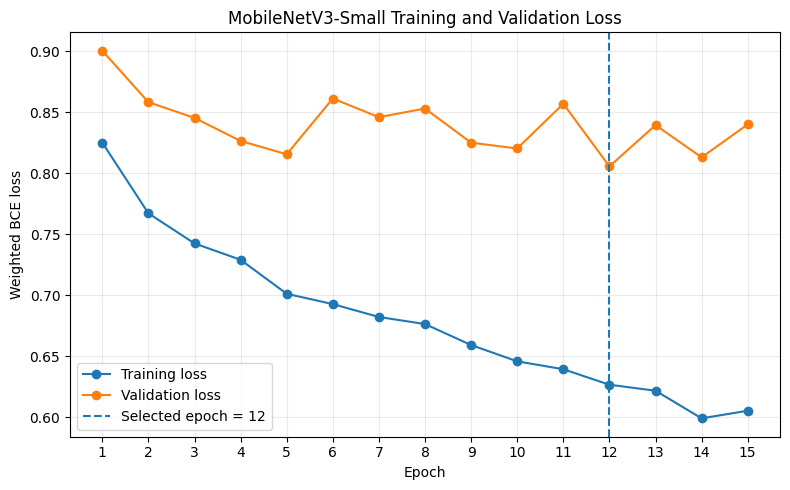

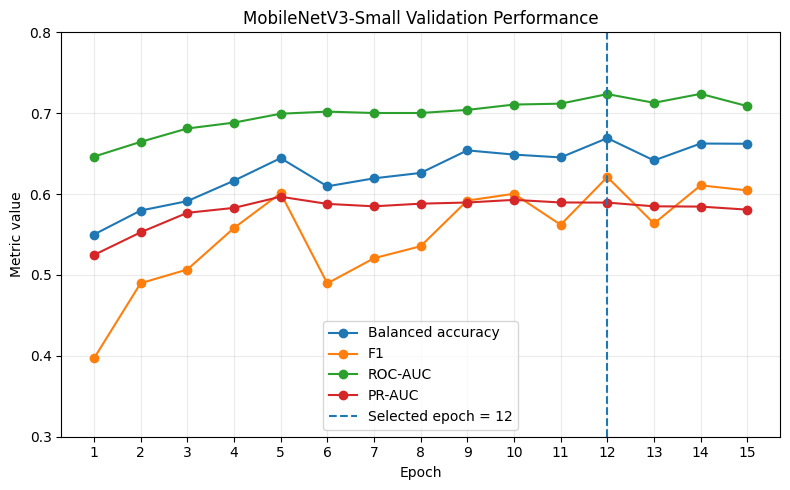

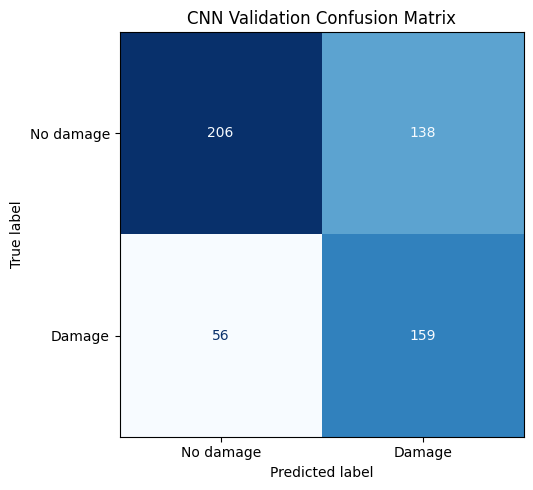

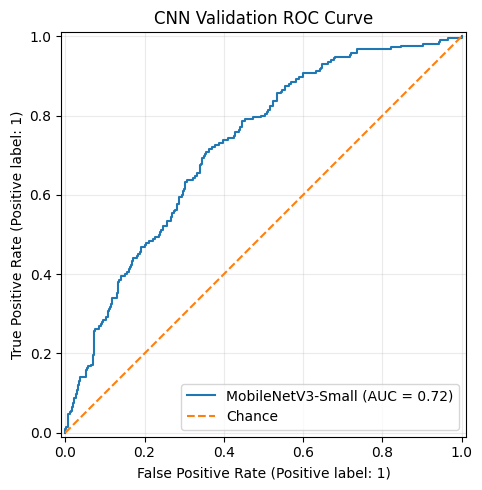

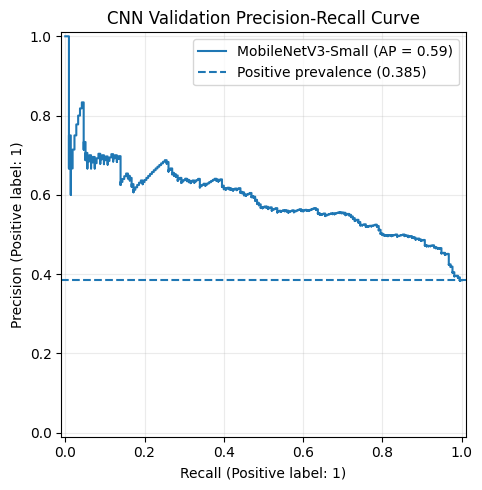


Selected epoch summary:
Epoch             : 12
Training loss     : 0.626571
Validation loss   : 0.805676
Balanced accuracy : 0.669186
F1                : 0.621094
ROC-AUC           : 0.723634
PR-AUC            : 0.589492

Saved figures:
/content/drive/MyDrive/EE565_Midterm_Milton/figures/cnn_training_validation_loss.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/cnn_validation_metrics_by_epoch.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/cnn_validation_confusion_matrix.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/cnn_validation_roc_curve.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/cnn_validation_precision_recall_curve.png

✓ Training behavior visualized
✓ Selected epoch confirmed from persistent history
✓ Confusion matrix generated
✓ ROC curve generated
✓ Precision-recall curve generated
✓ Figures saved at 300 dpi
✓ Test partition remained sealed
✓ Cell 30 complete


In [ ]:
# ============================================================
# CELL 30 — CNN LEARNING CURVES + VALIDATION DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("=" * 70)
print("CNN LEARNING CURVES + VALIDATION DIAGNOSTICS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reload persistent results
# ------------------------------------------------------------
history_plot = pd.read_csv(
    CNN_HISTORY_PATH
)

val_predictions_plot = pd.read_csv(
    CNN_VAL_PREDICTIONS_PATH
)

assert len(history_plot) == 15
assert len(val_predictions_plot) == 559

best_epoch_plot = int(
    history_plot.loc[
        history_plot[
            "val_loss"
        ].idxmin(),
        "epoch"
    ]
)

print(
    f"\nBest epoch from saved history : "
    f"{best_epoch_plot}"
)

assert best_epoch_plot == BEST_CNN_EPOCH

# ------------------------------------------------------------
# 2. Training / validation loss curve
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    history_plot["epoch"],
    history_plot["train_loss"],
    marker="o",
    label="Training loss"
)

ax.plot(
    history_plot["epoch"],
    history_plot["val_loss"],
    marker="o",
    label="Validation loss"
)

ax.axvline(
    best_epoch_plot,
    linestyle="--",
    label=f"Selected epoch = {best_epoch_plot}"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted BCE loss")
ax.set_title(
    "MobileNetV3-Small Training and Validation Loss"
)

ax.set_xticks(
    history_plot["epoch"]
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

CNN_LOSS_FIGURE = (
    FIGURE_DIR /
    "cnn_training_validation_loss.png"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    CNN_LOSS_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. Validation performance across epochs
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(8, 5)
)

for metric, label in [
    (
        "val_balanced_accuracy",
        "Balanced accuracy"
    ),
    (
        "val_f1",
        "F1"
    ),
    (
        "val_roc_auc",
        "ROC-AUC"
    ),
    (
        "val_pr_auc",
        "PR-AUC"
    )
]:

    ax.plot(
        history_plot["epoch"],
        history_plot[metric],
        marker="o",
        label=label
    )

ax.axvline(
    best_epoch_plot,
    linestyle="--",
    label=f"Selected epoch = {best_epoch_plot}"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Metric value")
ax.set_title(
    "MobileNetV3-Small Validation Performance"
)

ax.set_xticks(
    history_plot["epoch"]
)

ax.set_ylim(
    0.30,
    0.80
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

CNN_METRICS_FIGURE = (
    FIGURE_DIR /
    "cnn_validation_metrics_by_epoch.png"
)

fig.savefig(
    CNN_METRICS_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Selected-checkpoint confusion matrix
# ------------------------------------------------------------
y_val_plot = (
    val_predictions_plot[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    )
)

p_val_plot = (
    val_predictions_plot[
        "cnn_probability"
    ].to_numpy()
)

pred_val_plot = (
    val_predictions_plot[
        "cnn_prediction"
    ].to_numpy(
        dtype=np.int8
    )
)

fig, ax = plt.subplots(
    figsize=(5.5, 5)
)

ConfusionMatrixDisplay.from_predictions(
    y_val_plot,
    pred_val_plot,
    labels=[0, 1],
    display_labels=[
        "No damage",
        "Damage"
    ],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "CNN Validation Confusion Matrix"
)

fig.tight_layout()

CNN_CM_FIGURE = (
    FIGURE_DIR /
    "cnn_validation_confusion_matrix.png"
)

fig.savefig(
    CNN_CM_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Validation ROC curve
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(6, 5)
)

RocCurveDisplay.from_predictions(
    y_val_plot,
    p_val_plot,
    name="MobileNetV3-Small",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

ax.set_title(
    "CNN Validation ROC Curve"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

CNN_ROC_FIGURE = (
    FIGURE_DIR /
    "cnn_validation_roc_curve.png"
)

fig.savefig(
    CNN_ROC_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Validation precision-recall curve
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(6, 5)
)

PrecisionRecallDisplay.from_predictions(
    y_val_plot,
    p_val_plot,
    name="MobileNetV3-Small",
    ax=ax
)

positive_prevalence = (
    y_val_plot.mean()
)

ax.axhline(
    positive_prevalence,
    linestyle="--",
    label=(
        "Positive prevalence "
        f"({positive_prevalence:.3f})"
    )
)

ax.set_title(
    "CNN Validation Precision-Recall Curve"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

CNN_PR_FIGURE = (
    FIGURE_DIR /
    "cnn_validation_precision_recall_curve.png"
)

fig.savefig(
    CNN_PR_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. Selected epoch summary
# ------------------------------------------------------------
selected_epoch_row = (
    history_plot[
        history_plot[
            "epoch"
        ] == best_epoch_plot
    ]
    .iloc[0]
)

print("\nSelected epoch summary:")
print(
    f"Epoch             : "
    f"{best_epoch_plot}"
)
print(
    f"Training loss     : "
    f"{selected_epoch_row['train_loss']:.6f}"
)
print(
    f"Validation loss   : "
    f"{selected_epoch_row['val_loss']:.6f}"
)
print(
    f"Balanced accuracy : "
    f"{selected_epoch_row['val_balanced_accuracy']:.6f}"
)
print(
    f"F1                : "
    f"{selected_epoch_row['val_f1']:.6f}"
)
print(
    f"ROC-AUC           : "
    f"{selected_epoch_row['val_roc_auc']:.6f}"
)
print(
    f"PR-AUC            : "
    f"{selected_epoch_row['val_pr_auc']:.6f}"
)

print("\nSaved figures:")
print(CNN_LOSS_FIGURE)
print(CNN_METRICS_FIGURE)
print(CNN_CM_FIGURE)
print(CNN_ROC_FIGURE)
print(CNN_PR_FIGURE)

print("\n✓ Training behavior visualized")
print("✓ Selected epoch confirmed from persistent history")
print("✓ Confusion matrix generated")
print("✓ ROC curve generated")
print("✓ Precision-recall curve generated")
print("✓ Figures saved at 300 dpi")
print("✓ Test partition remained sealed")
print("✓ Cell 30 complete")

### 7.1 Development-Stage Method Comparison and Freeze

Before accessing the test partition, the validation-selected classical and CNN
configurations are compared using the same geographically separated validation
set.

The classical configuration was selected from the predefined image-processing
ablation study, while the CNN checkpoint was selected by minimum validation
loss. No decision thresholds are optimized on the validation set.

Following this comparison, all preprocessing rules, model configurations,
classification thresholds, and model-selection decisions are frozen. The test
partition is then accessed only once for final evaluation.

In [ ]:
# ============================================================
# CELL 31A — RESTORE FROZEN CLASSICAL ARTIFACTS AFTER RESTART
# ============================================================

import joblib
import pandas as pd
import numpy as np

print("=" * 70)
print("RESTORE FROZEN CLASSICAL DEVELOPMENT ARTIFACTS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Persistent paths
# ------------------------------------------------------------
BEST_CLASSICAL_MODEL_PATH = (
    MODEL_DIR /
    "classical_selected_model.joblib"
)

BEST_CLASSICAL_FEATURES_PATH = (
    MODEL_DIR /
    "classical_selected_features.txt"
)

TRAIN_CLASSICAL_FEATURES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_13_train_classical_features.csv"
)

VAL_CLASSICAL_FEATURES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_13_val_classical_features.csv"
)

# ------------------------------------------------------------
# 2. Verify artifacts
# ------------------------------------------------------------
required_classical_files = [
    BEST_CLASSICAL_MODEL_PATH,
    BEST_CLASSICAL_FEATURES_PATH,
    TRAIN_CLASSICAL_FEATURES_PATH,
    VAL_CLASSICAL_FEATURES_PATH
]

for path in required_classical_files:

    assert path.exists(), (
        f"Missing artifact: {path}"
    )

    print(f"✓ {path}")

# ------------------------------------------------------------
# 3. Restore selected classical model
# ------------------------------------------------------------
BEST_CLASSICAL_MODEL = joblib.load(
    BEST_CLASSICAL_MODEL_PATH
)

# ------------------------------------------------------------
# 4. Restore exact selected feature list
# ------------------------------------------------------------
with open(
    BEST_CLASSICAL_FEATURES_PATH,
    "r"
) as f:

    BEST_CLASSICAL_FEATURES = [
        line.strip()
        for line in f
        if line.strip()
    ]

BEST_CLASSICAL_NAME = "LAB only"

# Frozen expectation
expected_features = [
    "lab_mean",
    "lab_std",
    "lab_p75",
    "lab_p90",
    "lab_p95"
]

assert (
    BEST_CLASSICAL_FEATURES
    == expected_features
)

# ------------------------------------------------------------
# 5. Restore feature tables
# ------------------------------------------------------------
train_features_model = pd.read_csv(
    TRAIN_CLASSICAL_FEATURES_PATH
)

val_features_model = pd.read_csv(
    VAL_CLASSICAL_FEATURES_PATH
)

y_train = (
    train_features_model[
        "damage_label"
    ]
    .to_numpy(
        dtype=np.int8
    )
)

y_val = (
    val_features_model[
        "damage_label"
    ]
    .to_numpy(
        dtype=np.int8
    )
)

# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------
assert len(train_features_model) == 2455
assert len(val_features_model) == 559

assert all(
    feature in train_features_model.columns
    for feature in BEST_CLASSICAL_FEATURES
)

assert all(
    feature in val_features_model.columns
    for feature in BEST_CLASSICAL_FEATURES
)

print("\nRestored classical selection:")
print(
    f"Configuration : {BEST_CLASSICAL_NAME}"
)

print(
    "Features      : "
    + ", ".join(
        BEST_CLASSICAL_FEATURES
    )
)

print(
    f"Train rows    : "
    f"{len(train_features_model):,}"
)

print(
    f"Validation rows: "
    f"{len(val_features_model):,}"
)

print("\n✓ Selected classical model restored")
print("✓ Exact LAB feature definition restored")
print("✓ Train/validation feature tables restored")
print("✓ Test partition remained sealed")
print("✓ Cell 31A complete")

RESTORE FROZEN CLASSICAL DEVELOPMENT ARTIFACTS
✓ /content/drive/MyDrive/EE565_Midterm_Milton/models/classical_selected_model.joblib
✓ /content/drive/MyDrive/EE565_Midterm_Milton/models/classical_selected_features.txt
✓ /content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_13_train_classical_features.csv
✓ /content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_13_val_classical_features.csv

Restored classical selection:
Configuration : LAB only
Features      : lab_mean, lab_std, lab_p75, lab_p90, lab_p95
Train rows    : 2,455
Validation rows: 559

✓ Selected classical model restored
✓ Exact LAB feature definition restored
✓ Train/validation feature tables restored
✓ Test partition remained sealed
✓ Cell 31A complete


In [ ]:
# ============================================================
# CELL 31 — DEVELOPMENT COMPARISON + FINAL METHOD FREEZE
# ============================================================

import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("FINAL DEVELOPMENT COMPARISON + METHOD FREEZE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Classical validation predictions
# ------------------------------------------------------------
classical_feature_cols = list(
    BEST_CLASSICAL_FEATURES
)

X_val_classical = (
    val_features_model[
        classical_feature_cols
    ]
    .to_numpy(
        dtype=np.float64
    )
)

classical_val_probability = (
    BEST_CLASSICAL_MODEL
    .predict_proba(
        X_val_classical
    )[:, 1]
)

classical_val_prediction = (
    classical_val_probability >= 0.5
).astype(np.int8)

classical_cm = confusion_matrix(
    y_val,
    classical_val_prediction,
    labels=[0, 1]
)

c_tn, c_fp, c_fn, c_tp = (
    classical_cm.ravel()
)

classical_metrics = {
    "method":
        "Classical LAB + Logistic Regression",

    "accuracy":
        accuracy_score(
            y_val,
            classical_val_prediction
        ),

    "balanced_accuracy":
        balanced_accuracy_score(
            y_val,
            classical_val_prediction
        ),

    "precision":
        precision_score(
            y_val,
            classical_val_prediction,
            zero_division=0
        ),

    "recall":
        recall_score(
            y_val,
            classical_val_prediction,
            zero_division=0
        ),

    "f1":
        f1_score(
            y_val,
            classical_val_prediction,
            zero_division=0
        ),

    "roc_auc":
        roc_auc_score(
            y_val,
            classical_val_probability
        ),

    "pr_auc":
        average_precision_score(
            y_val,
            classical_val_probability
        ),

    "tn": int(c_tn),
    "fp": int(c_fp),
    "fn": int(c_fn),
    "tp": int(c_tp)
}

# ------------------------------------------------------------
# 2. CNN validation results from selected checkpoint
# ------------------------------------------------------------
cnn_metrics = {
    "method":
        "MobileNetV3-Small (NOAA post only)",

    "accuracy":
        BEST_CNN_VAL_METRICS[
            "accuracy"
        ],

    "balanced_accuracy":
        BEST_CNN_VAL_METRICS[
            "balanced_accuracy"
        ],

    "precision":
        BEST_CNN_VAL_METRICS[
            "precision"
        ],

    "recall":
        BEST_CNN_VAL_METRICS[
            "recall"
        ],

    "f1":
        BEST_CNN_VAL_METRICS[
            "f1"
        ],

    "roc_auc":
        BEST_CNN_VAL_METRICS[
            "roc_auc"
        ],

    "pr_auc":
        BEST_CNN_VAL_METRICS[
            "pr_auc"
        ],

    "tn":
        BEST_CNN_VAL_METRICS[
            "tn"
        ],

    "fp":
        BEST_CNN_VAL_METRICS[
            "fp"
        ],

    "fn":
        BEST_CNN_VAL_METRICS[
            "fn"
        ],

    "tp":
        BEST_CNN_VAL_METRICS[
            "tp"
        ]
}

# ------------------------------------------------------------
# 3. Comparison table
# ------------------------------------------------------------
development_comparison = pd.DataFrame([
    classical_metrics,
    cnn_metrics
])

print("\nValidation comparison:")

display(
    development_comparison[
        [
            "method",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc",
            "tn",
            "fp",
            "fn",
            "tp"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 4. Absolute CNN - classical differences
# ------------------------------------------------------------
metric_names = [
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]

difference_rows = []

for metric in metric_names:

    difference_rows.append({
        "metric":
            metric,

        "classical":
            classical_metrics[
                metric
            ],

        "cnn":
            cnn_metrics[
                metric
            ],

        "cnn_minus_classical":
            cnn_metrics[
                metric
            ]
            -
            classical_metrics[
                metric
            ]
    })

development_differences = (
    pd.DataFrame(
        difference_rows
    )
)

print(
    "\nCNN − classical validation differences:"
)

display(
    development_differences.round(4)
)

# ------------------------------------------------------------
# 5. Save validation predictions for classical method
# ------------------------------------------------------------
classical_val_predictions_df = (
    val_meta[
        [
            "property_index",
            "geo_tile_id",
            "damage_label"
        ]
    ]
    .copy()
)

classical_val_predictions_df[
    "classical_probability"
] = classical_val_probability

classical_val_predictions_df[
    "classical_prediction"
] = classical_val_prediction

CLASSICAL_VAL_PRED_PATH = (
    RESULTS_DIR /
    "classical_selected_validation_predictions.csv"
)

classical_val_predictions_df.to_csv(
    CLASSICAL_VAL_PRED_PATH,
    index=False
)

# ------------------------------------------------------------
# 6. Save development comparison
# ------------------------------------------------------------
DEVELOPMENT_COMPARISON_PATH = (
    RESULTS_DIR /
    "development_method_comparison.csv"
)

DEVELOPMENT_DIFFERENCE_PATH = (
    RESULTS_DIR /
    "development_method_differences.csv"
)

development_comparison.to_csv(
    DEVELOPMENT_COMPARISON_PATH,
    index=False
)

development_differences.to_csv(
    DEVELOPMENT_DIFFERENCE_PATH,
    index=False
)

# ------------------------------------------------------------
# 7. Freeze final methodology BEFORE test access
# ------------------------------------------------------------
METHOD_FREEZE_PATH = (
    RESULTS_DIR /
    "final_method_freeze_before_test.json"
)

method_freeze = {

    "freeze_timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "test_accessed":
        False,

    "patch_size":
        128,

    "label_rule": {
        "damage_measure":
            "max(roof_cover, superstruc, exterior_f)",

        "negative":
            "damage_measure == 0",

        "positive":
            "damage_measure >= 50",

        "excluded":
            "1 <= damage_measure <= 49"
    },

    "split_policy":
        "geographic NOAA tile grouped; no tile leakage",

    "registration": {
        "baseline":
            "GEOGRAPHIC_FALLBACK",

        "sift_nfeatures":
            12000,

        "lowe_ratio":
            0.75,

        "ransac_reprojection_threshold":
            4.0,

        "minimum_good_matches":
            10,

        "minimum_inliers":
            10,

        "minimum_inlier_ratio":
            0.15,

        "accepted_warp_area_ratio":
            [0.75, 1.25],

        "minimum_valid_warp_fraction":
            0.90,

        "ecc_after_accepted_sift_only":
            True,

        "ecc_singular_value_range":
            [0.95, 1.05],

        "ecc_max_translation_pixels":
            50,

        "ecc_max_coverage_loss":
            0.02
    },

    "quality_control": {
        "pre_registration_coverage_min":
            0.95,

        "noaa_post_valid_fraction_min":
            0.95
    },

    "classical": {
        "selected_configuration":
            "LAB only",

        "features":
            classical_feature_cols,

        "classifier":
            "StandardScaler + LogisticRegression",

        "class_weight":
            "balanced",

        "decision_threshold":
            0.5,

        "validation_selection_metric":
            "balanced_accuracy"
    },

    "cnn": {
        "architecture":
            "MobileNetV3-Small",

        "pretraining":
            "ImageNet IMAGENET1K_V1",

        "input":
            "NOAA post-event RGB only",

        "backbone":
            "frozen",

        "classifier":
            "Linear(576,128)-ReLU-Dropout(0.30)-Linear(128,1)",

        "positive_class_weight":
            float(POS_WEIGHT),

        "optimizer":
            "Adam",

        "learning_rate":
            1e-3,

        "weight_decay":
            1e-4,

        "epochs":
            15,

        "selected_epoch":
            int(BEST_CNN_EPOCH),

        "checkpoint_selection":
            "minimum validation loss",

        "decision_threshold":
            0.5
    },

    "development_counts": {
        "train":
            2455,

        "validation":
            559
    },

    "test_protocol":
        "Process and evaluate sealed test partition once after this freeze."
}

with open(
    METHOD_FREEZE_PATH,
    "w"
) as f:

    json.dump(
        method_freeze,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 8. Report
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("DEVELOPMENT DECISIONS FROZEN")
print("=" * 70)

print("\nClassical:")
print(
    "  LAB color-difference statistics "
    "+ balanced logistic regression"
)
print(
    "  Threshold = 0.5"
)

print("\nCNN:")
print(
    "  MobileNetV3-Small, NOAA post only"
)
print(
    "  Frozen ImageNet backbone"
)
print(
    f"  Selected epoch = "
    f"{BEST_CNN_EPOCH}"
)
print(
    "  Threshold = 0.5"
)

print("\nSaved:")
print(DEVELOPMENT_COMPARISON_PATH)
print(DEVELOPMENT_DIFFERENCE_PATH)
print(CLASSICAL_VAL_PRED_PATH)
print(METHOD_FREEZE_PATH)

print("\n✓ Classical configuration frozen")
print("✓ CNN architecture/checkpoint frozen")
print("✓ Decision threshold fixed at 0.5")
print("✓ Registration and QC rules recorded")
print("✓ Development comparison saved")
print("✓ No test information used for model selection")
print("✓ Test partition remains sealed")
print("✓ Cell 31 complete")

FINAL DEVELOPMENT COMPARISON + METHOD FREEZE

Validation comparison:


,method,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,Classical LAB + Logistic Regression,0.5921,0.5797,0.4728,0.5256,0.4978,0.6079,0.4697,218,126,102,113
1,MobileNetV3-Small (NOAA post only),0.6530,0.6692,0.5354,0.7395,0.6211,0.7236,0.5895,206,138,56,159



CNN − classical validation differences:


,metric,classical,cnn,cnn_minus_classical
0,accuracy,0.5921,0.6530,0.0608
1,balanced_accuracy,0.5797,0.6692,0.0895
2,precision,0.4728,0.5354,0.0626
3,recall,0.5256,0.7395,0.2140
4,f1,0.4978,0.6211,0.1233
5,roc_auc,0.6079,0.7236,0.1158
6,pr_auc,0.4697,0.5895,0.1198



DEVELOPMENT DECISIONS FROZEN

Classical:
  LAB color-difference statistics + balanced logistic regression
  Threshold = 0.5

CNN:
  MobileNetV3-Small, NOAA post only
  Frozen ImageNet backbone
  Selected epoch = 12
  Threshold = 0.5

Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/results/development_method_comparison.csv
/content/drive/MyDrive/EE565_Midterm_Milton/results/development_method_differences.csv
/content/drive/MyDrive/EE565_Midterm_Milton/results/classical_selected_validation_predictions.csv
/content/drive/MyDrive/EE565_Midterm_Milton/results/final_method_freeze_before_test.json

✓ Classical configuration frozen
✓ CNN architecture/checkpoint frozen
✓ Decision threshold fixed at 0.5
✓ Registration and QC rules recorded
✓ Development comparison saved
✓ No test information used for model selection
✓ Test partition remains sealed
✓ Cell 31 complete


### 8.1 Final Test Partition — Unsealing and Integrity Verification

Following completion and freezing of all development-stage decisions, the
previously sealed geographic test partition is accessed for final evaluation.

Before image preprocessing, the test records are checked against the frozen
training and validation partitions to verify property-level and NOAA-tile-level
separation. No model configuration, registration rule, quality-control
threshold, feature definition, or classification threshold will be modified
after this point based on test-set observations.

In [ ]:
# ============================================================
# CELL 32 — UNSEAL + VERIFY FROZEN TEST PARTITION
# ============================================================

import json
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path

print("=" * 70)
print("FINAL TEST PARTITION — UNSEAL + INTEGRITY VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Persistent paths
# ------------------------------------------------------------
SPLIT_GPKG_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_07_frozen_grouped_split.gpkg"
)

METHOD_FREEZE_PATH = (
    RESULTS_DIR /
    "final_method_freeze_before_test.json"
)

TEST_CANDIDATE_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_14_test_candidates.gpkg"
)

TEST_MANIFEST_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_14_test_manifest.csv"
)

# ------------------------------------------------------------
# 2. Verify pre-test method freeze exists
# ------------------------------------------------------------
assert METHOD_FREEZE_PATH.exists(), (
    "Method-freeze record is missing."
)

with open(
    METHOD_FREEZE_PATH,
    "r"
) as f:

    frozen_method = json.load(f)

assert (
    frozen_method[
        "test_accessed"
    ] is False
)

print("\n✓ Pre-test method-freeze record found")
print(
    f"Freeze timestamp: "
    f"{frozen_method['freeze_timestamp_utc']}"
)

# ------------------------------------------------------------
# 3. Load original frozen geographic split
# ------------------------------------------------------------
assert SPLIT_GPKG_PATH.exists(), (
    f"Missing split checkpoint: "
    f"{SPLIT_GPKG_PATH}"
)

frozen_split_gdf = gpd.read_file(
    SPLIT_GPKG_PATH
)

print(
    f"\nFrozen split records: "
    f"{len(frozen_split_gdf):,}"
)

print(
    frozen_split_gdf[
        "split"
    ]
    .value_counts()
)

# ------------------------------------------------------------
# 4. Unseal test records
# ------------------------------------------------------------
test_candidates = (
    frozen_split_gdf[
        frozen_split_gdf[
            "split"
        ] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(test_candidates) == 596

print("\nTEST partition unsealed:")
print(
    f"Properties : "
    f"{len(test_candidates):,}"
)

print(
    f"Negative   : "
    f"{(test_candidates['damage_label'] == 0).sum():,}"
)

print(
    f"Positive   : "
    f"{(test_candidates['damage_label'] == 1).sum():,}"
)

assert (
    test_candidates[
        "damage_label"
    ].value_counts().sort_index()
    .to_dict()
    == {
        0: 392,
        1: 204
    }
)

# ------------------------------------------------------------
# 5. Recover development property IDs
# ------------------------------------------------------------
train_meta_frozen = pd.read_csv(
    TRAIN_METADATA_PATH
)

val_meta_frozen = pd.read_csv(
    VAL_METADATA_PATH
)

development_property_ids = set(
    train_meta_frozen[
        "property_index"
    ]
).union(
    set(
        val_meta_frozen[
            "property_index"
        ]
    )
)

test_property_ids = set(
    test_candidates[
        "property_index"
    ]
)

property_overlap = (
    development_property_ids
    .intersection(
        test_property_ids
    )
)

# ------------------------------------------------------------
# 6. Geographic tile leakage check
# ------------------------------------------------------------
development_tiles = set(
    pd.concat(
        [
            train_meta_frozen[
                "geo_tile_id"
            ],
            val_meta_frozen[
                "geo_tile_id"
            ]
        ]
    )
    .astype(str)
)

test_tiles = set(
    test_candidates[
        "geo_tile_id"
    ]
    .astype(str)
)

tile_overlap = (
    development_tiles
    .intersection(
        test_tiles
    )
)

print("\nLeakage checks:")
print(
    f"Property overlap : "
    f"{len(property_overlap)}"
)

print(
    f"Development tiles: "
    f"{len(development_tiles)}"
)

print(
    f"Test tiles       : "
    f"{len(test_tiles)}"
)

print(
    f"Tile overlap     : "
    f"{len(tile_overlap)}"
)

assert len(property_overlap) == 0
assert len(tile_overlap) == 0

# ------------------------------------------------------------
# 7. Test NOAA folder/tile workload
# ------------------------------------------------------------
print("\nTest NOAA workload:")

print(
    f"Unique geographic tiles : "
    f"{test_candidates['geo_tile_id'].nunique()}"
)

if "noaa_folder" in test_candidates.columns:

    print("\nNOAA folders:")

    print(
        test_candidates[
            "noaa_folder"
        ]
        .value_counts()
    )

# Tile workload
test_tile_workload = (
    test_candidates
    .groupby(
        "geo_tile_id"
    )
    .agg(
        properties=(
            "property_index",
            "size"
        ),

        positives=(
            "damage_label",
            "sum"
        )
    )
    .reset_index()
)

test_tile_workload[
    "negatives"
] = (
    test_tile_workload[
        "properties"
    ]
    -
    test_tile_workload[
        "positives"
    ]
)

print("\nProperties per test tile:")
print(
    test_tile_workload[
        "properties"
    ]
    .describe()
    .round(2)
)

# ------------------------------------------------------------
# 8. Verify NOAA assignment exists for every test property
# ------------------------------------------------------------
required_assignment_columns = [
    "property_index",
    "damage_label",
    "geo_tile_id",
    "noaa_key"
]

missing_columns = [
    c
    for c in required_assignment_columns
    if c not in test_candidates.columns
]

assert not missing_columns, (
    f"Missing required columns: "
    f"{missing_columns}"
)

assert (
    test_candidates[
        "noaa_key"
    ]
    .notna()
    .all()
)

# ------------------------------------------------------------
# 9. Save explicit test manifest
# ------------------------------------------------------------
test_candidates.to_file(
    TEST_CANDIDATE_PATH,
    driver="GPKG"
)

manifest_columns = [
    c
    for c in [
        "property_index",
        "damage_label",
        "property_lon",
        "property_lat",
        "geo_tile_id",
        "noaa_key",
        "noaa_folder"
    ]
    if c in test_candidates.columns
]

test_candidates[
    manifest_columns
].to_csv(
    TEST_MANIFEST_PATH,
    index=False
)

# ------------------------------------------------------------
# 10. Mark that test has now been accessed
#
# Preserve the original pre-test freeze file unchanged.
# Create a NEW audit record rather than modifying it.
# ------------------------------------------------------------
TEST_ACCESS_RECORD_PATH = (
    RESULTS_DIR /
    "test_access_record.json"
)

test_access_record = {
    "method_freeze_file":
        str(METHOD_FREEZE_PATH),

    "test_unsealed":
        True,

    "test_properties":
        int(len(test_candidates)),

    "test_negative":
        int(
            (
                test_candidates[
                    "damage_label"
                ] == 0
            ).sum()
        ),

    "test_positive":
        int(
            (
                test_candidates[
                    "damage_label"
                ] == 1
            ).sum()
        ),

    "test_geographic_tiles":
        int(
            test_candidates[
                "geo_tile_id"
            ].nunique()
        ),

    "development_test_property_overlap":
        int(
            len(property_overlap)
        ),

    "development_test_tile_overlap":
        int(
            len(tile_overlap)
        ),

    "methods_changed_after_unsealing":
        False
}

with open(
    TEST_ACCESS_RECORD_PATH,
    "w"
) as f:

    json.dump(
        test_access_record,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 11. Final report
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("TEST PARTITION READY FOR FROZEN PREPROCESSING")
print("=" * 70)

print(
    f"Test properties : "
    f"{len(test_candidates):,}"
)

print(
    f"Class 0         : "
    f"{(test_candidates['damage_label'] == 0).sum():,}"
)

print(
    f"Class 1         : "
    f"{(test_candidates['damage_label'] == 1).sum():,}"
)

print(
    f"Geographic tiles: "
    f"{test_candidates['geo_tile_id'].nunique()}"
)

print("\nSaved:")
print(TEST_CANDIDATE_PATH)
print(TEST_MANIFEST_PATH)
print(TEST_ACCESS_RECORD_PATH)

print("\n✓ Pre-test method freeze verified")
print("✓ Frozen 596-property test partition recovered")
print("✓ Expected 392/204 class distribution verified")
print("✓ Zero development/test property overlap")
print("✓ Zero development/test geographic tile overlap")
print("✓ NOAA assignments verified")
print("✓ Test-access audit record created")
print("✓ No methodology changed after test access")
print("✓ Cell 32 complete")

FINAL TEST PARTITION — UNSEAL + INTEGRITY VERIFICATION

✓ Pre-test method-freeze record found
Freeze timestamp: 2026-09-21T06:12:52.704310+00:00

Frozen split records: 3,830
split
train         2650
test           596
validation     584
Name: count, dtype: int64

TEST partition unsealed:
Properties : 596
Negative   : 392
Positive   : 204

Leakage checks:
Property overlap : 0
Development tiles: 80
Test tiles       : 33
Tile overlap     : 0

Test NOAA workload:
Unique geographic tiles : 33

NOAA folders:
noaa_folder
20241011b_RGB    367
20241013a_RGB    226
20241012b_RGB      3
Name: count, dtype: int64

Properties per test tile:
count     33.00
mean      18.06
std       27.60
min        1.00
25%        1.00
50%        8.00
75%       16.00
max      109.00
Name: properties, dtype: float64

TEST PARTITION READY FOR FROZEN PREPROCESSING
Test properties : 596
Class 0         : 392
Class 1         : 204
Geographic tiles: 33

Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/check

### 8.2 Frozen Test-Set Preprocessing

The unsealed test properties are processed using exactly the preprocessing
rules frozen before test access. Each property is independently retrieved from
the USDA NAIP and NOAA imagery sources, registered using the frozen
SIFT/RANSAC and gated ECC procedure, and subjected to the same 95% coverage
requirements used during development.

Processing is checkpointed in resumable batches. No registration threshold,
quality-control rule, or fallback behavior is changed based on test-set
outcomes.

In [ ]:
# ============================================================
# CELL 33A — RESTORE NOAA S3 DEPENDENCY
# ============================================================

!pip -q install boto3

import boto3

print("✓ boto3 installed")
print(f"✓ boto3 version: {boto3.__version__}")
print("✓ Ready to run Cell 33")

✓ boto3 installed
✓ boto3 version: 1.43.98
✓ Ready to run Cell 33


In [ ]:
# ============================================================
# CELL 33 — FINAL FROZEN TEST PAIRED PREPROCESSING
# ============================================================

import cv2
import time
import boto3
import requests
import rasterio
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image
from io import BytesIO

from rasterio.session import AWSSession
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

print("=" * 70)
print("FROZEN TEST PAIRED NAIP / NOAA PREPROCESSING")
print("=" * 70)

# ============================================================
# 1. SELF-CONTAINED FROZEN CONFIGURATION
# ============================================================

# Project paths
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/"
    "EE565_Midterm_Milton/checkpoints"
)

TEST_CANDIDATES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_14_test_candidates.gpkg"
)

TEST_MANIFEST_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_14_test_manifest.csv"
)

TEST_BATCH_DIR = (
    CHECKPOINT_DIR /
    "paired_test_batches"
)

FINAL_TEST_QC_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_15_test_paired_qc.csv"
)

TEST_BATCH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Frozen patch/context geometry
# ------------------------------------------------------------
PATCH_SIZE = 128
WORK_SIZE = 1024
HALF_WIDTH_DEG = 0.002

# ------------------------------------------------------------
# Exact imagery sources
# ------------------------------------------------------------
NAIP_IMAGE_SERVER = (
    "https://imagery.geoplatform.gov/iipp/rest/services/"
    "NAIP/NAIP2023_CONUS/ImageServer/exportImage"
)

NOAA_BUCKET = "noaa-eri-pds"

# ------------------------------------------------------------
# Frozen SIFT/RANSAC configuration
# ------------------------------------------------------------
SIFT_NFEATURES = 12000
LOWE_RATIO = 0.75
RANSAC_THRESHOLD = 4.0

MIN_GOOD_MATCHES = 10
MIN_INLIERS = 10
MIN_INLIER_RATIO = 0.15

MIN_AREA_RATIO = 0.75
MAX_AREA_RATIO = 1.25
MIN_VALID_WARP = 0.90

# ------------------------------------------------------------
# Frozen ECC configuration
# ------------------------------------------------------------
ECC_MAX_ITER = 100
ECC_EPS = 1e-6

ECC_MIN_SINGULAR = 0.95
ECC_MAX_SINGULAR = 1.05
ECC_MAX_TRANSLATION = 50.0
ECC_MAX_COVERAGE_LOSS = 0.02

# ------------------------------------------------------------
# Frozen production/QC configuration
# ------------------------------------------------------------
TEST_BATCH_SIZE = 25

MAX_NETWORK_ATTEMPTS = 3
RETRY_WAIT_SECONDS = 3

PRE_COVERAGE_THRESHOLD = 0.95
POST_COVERAGE_THRESHOLD = 0.95

# ------------------------------------------------------------
# Configuration integrity checks
# ------------------------------------------------------------
assert PATCH_SIZE == 128
assert WORK_SIZE == 1024
assert HALF_WIDTH_DEG == 0.002

assert SIFT_NFEATURES == 12000
assert LOWE_RATIO == 0.75
assert RANSAC_THRESHOLD == 4.0

assert MIN_GOOD_MATCHES == 10
assert MIN_INLIERS == 10
assert MIN_INLIER_RATIO == 0.15

assert MIN_AREA_RATIO == 0.75
assert MAX_AREA_RATIO == 1.25
assert MIN_VALID_WARP == 0.90

assert ECC_MAX_ITER == 100
assert ECC_EPS == 1e-6

assert ECC_MIN_SINGULAR == 0.95
assert ECC_MAX_SINGULAR == 1.05
assert ECC_MAX_TRANSLATION == 50.0
assert ECC_MAX_COVERAGE_LOSS == 0.02

assert PRE_COVERAGE_THRESHOLD == 0.95
assert POST_COVERAGE_THRESHOLD == 0.95

assert NAIP_IMAGE_SERVER.endswith(
    "/ImageServer/exportImage"
)

print("\n✓ Frozen preprocessing configuration restored")

# ============================================================
# 2. LOAD FROZEN TEST MANIFEST
# ============================================================

assert TEST_MANIFEST_PATH.exists(), (
    "Frozen test manifest is missing."
)

test_df = pd.read_csv(
    TEST_MANIFEST_PATH
)

test_df = (
    test_df
    .sort_values("property_index")
    .reset_index(drop=True)
)

assert len(test_df) == 596

assert (
    test_df["damage_label"]
    .value_counts()
    .to_dict()
    == {
        0: 392,
        1: 204
    }
)

if "split" in test_df.columns:
    assert set(
        test_df["split"].unique()
    ) == {"test"}

print("\nTest candidates:")

if "split" in test_df.columns:
    print(
        test_df["split"]
        .value_counts()
    )
else:
    print("test    596")

print(
    f"\nTotal properties      : "
    f"{len(test_df)}"
)

print(
    f"Test batch size       : "
    f"{TEST_BATCH_SIZE}"
)

n_batches = int(
    np.ceil(
        len(test_df) /
        TEST_BATCH_SIZE
    )
)

assert n_batches == 24

print(
    f"Total batches         : "
    f"{n_batches}"
)

print(
    f"Persistent directory  : "
    f"{TEST_BATCH_DIR}"
)

print("\nMethod status         : FROZEN")

# ============================================================
# 3. PERSISTENT REMOTE SESSIONS
# ============================================================

http_session = requests.Session()

http_session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

aws_session_test = AWSSession(
    boto3.Session(),
    aws_unsigned=True
)

# ============================================================
# 4. RETRY NAIP REQUEST
# ============================================================

def get_naip_image(
    left,
    bottom,
    right,
    top
):

    bbox_string = (
        f"{left:.8f},"
        f"{bottom:.8f},"
        f"{right:.8f},"
        f"{top:.8f}"
    )

    params = {
        "bbox": bbox_string,
        "bboxSR": "4326",
        "imageSR": "4326",
        "size": (
            f"{WORK_SIZE},"
            f"{WORK_SIZE}"
        ),
        "format": "jpgpng",
        "pixelType": "U8",
        "f": "image"
    }

    last_error = None

    for attempt in range(
        1,
        MAX_NETWORK_ATTEMPTS + 1
    ):

        try:

            response = http_session.get(
                NAIP_IMAGE_SERVER,
                params=params,
                timeout=120
            )

            response.raise_for_status()

            content_type = (
                response.headers.get(
                    "Content-Type",
                    ""
                )
            )

            if (
                "image"
                not in content_type.lower()
            ):
                raise RuntimeError(
                    "NAIP response was not an image."
                )

            image = np.asarray(
                Image.open(
                    BytesIO(
                        response.content
                    )
                ).convert("RGB")
            )

            if image.shape != (
                WORK_SIZE,
                WORK_SIZE,
                3
            ):
                raise RuntimeError(
                    "Unexpected NAIP image shape."
                )

            return image

        except Exception as e:

            last_error = e

            if (
                attempt
                < MAX_NETWORK_ATTEMPTS
            ):
                time.sleep(
                    RETRY_WAIT_SECONDS
                )

    raise RuntimeError(
        "NAIP_READ_FAILED: "
        f"{type(last_error).__name__}: "
        f"{last_error}"
    )

# ============================================================
# 5. RETRY NOAA CONTEXT REQUEST
# ============================================================

def get_noaa_context(
    noaa_key,
    left,
    bottom,
    right,
    top
):

    s3_uri = (
        f"s3://{NOAA_BUCKET}/"
        f"{noaa_key}"
    )

    last_error = None

    for attempt in range(
        1,
        MAX_NETWORK_ATTEMPTS + 1
    ):

        try:

            with rasterio.Env(
                aws_session_test,
                GDAL_DISABLE_READDIR_ON_OPEN=(
                    "EMPTY_DIR"
                )
            ):

                with rasterio.open(
                    s3_uri
                ) as src:

                    window = from_bounds(
                        left,
                        bottom,
                        right,
                        top,
                        transform=src.transform
                    )

                    rgb_chw = src.read(
                        indexes=[1, 2, 3],
                        window=window,
                        out_shape=(
                            3,
                            WORK_SIZE,
                            WORK_SIZE
                        ),
                        resampling=(
                            Resampling.bilinear
                        ),
                        boundless=True,
                        fill_value=0
                    )

                    # NOAA dataset_mask remains
                    # authoritative for POST coverage.
                    mask = src.dataset_mask(
                        window=window,
                        out_shape=(
                            WORK_SIZE,
                            WORK_SIZE
                        ),
                        boundless=True
                    )

            rgb = np.moveaxis(
                rgb_chw,
                0,
                -1
            ).astype(np.uint8)

            if rgb.shape != (
                WORK_SIZE,
                WORK_SIZE,
                3
            ):
                raise RuntimeError(
                    "Unexpected NOAA context shape."
                )

            return rgb, mask

        except Exception as e:

            last_error = e

            if (
                attempt
                < MAX_NETWORK_ATTEMPTS
            ):
                time.sleep(
                    RETRY_WAIT_SECONDS
                )

    raise RuntimeError(
        "NOAA_READ_FAILED: "
        f"{type(last_error).__name__}: "
        f"{last_error}"
    )

# ============================================================
# 6. PROCESS ONE FROZEN TEST PROPERTY
# ============================================================

def process_test_property(
    prop
):

    t0 = time.perf_counter()

    property_index = int(
        prop["property_index"]
    )

    label = int(
        prop["damage_label"]
    )

    lon = float(
        prop["property_lon"]
    )

    lat = float(
        prop["property_lat"]
    )

    noaa_key = str(
        prop["noaa_key"]
    )

    record = {
        "property_index": property_index,
        "split": "test",
        "damage_label": label,
        "property_lon": lon,
        "property_lat": lat,
        "geo_tile_id": prop[
            "geo_tile_id"
        ],
        "noaa_key": noaa_key,

        "accepted": False,
        "rejection_reason": "",

        "registration_method": "",
        "good_matches": 0,
        "inliers": 0,
        "inlier_ratio": 0.0,
        "area_ratio": np.nan,
        "valid_warp_fraction": 0.0,

        "sift_accepted": False,
        "ecc_attempted": False,
        "ecc_accepted": False,
        "ecc_correlation": np.nan,
        "ecc_determinant": np.nan,
        "ecc_sv_max": np.nan,
        "ecc_sv_min": np.nan,
        "ecc_translation": np.nan,
        "ecc_coverage_loss": np.nan,

        "pre_valid_fraction": np.nan,
        "post_valid_fraction": np.nan,

        "processing_seconds": np.nan
    }

    try:

        # ----------------------------------------------------
        # A. Common geographic context
        # ----------------------------------------------------
        left = (
            lon - HALF_WIDTH_DEG
        )

        bottom = (
            lat - HALF_WIDTH_DEG
        )

        right = (
            lon + HALF_WIDTH_DEG
        )

        top = (
            lat + HALF_WIDTH_DEG
        )

        # ----------------------------------------------------
        # B. Retrieve PRE and POST contexts
        # ----------------------------------------------------
        naip_rgb_local = (
            get_naip_image(
                left,
                bottom,
                right,
                top
            )
        )

        (
            noaa_rgb_local,
            noaa_mask_local
        ) = get_noaa_context(
            noaa_key,
            left,
            bottom,
            right,
            top
        )

        # ----------------------------------------------------
        # C. SIFT feature extraction
        # ----------------------------------------------------
        pre_gray = cv2.cvtColor(
            naip_rgb_local,
            cv2.COLOR_RGB2GRAY
        )

        post_gray = cv2.cvtColor(
            noaa_rgb_local,
            cv2.COLOR_RGB2GRAY
        )

        sift_local = cv2.SIFT_create(
            nfeatures=SIFT_NFEATURES
        )

        (
            kp_pre,
            des_pre
        ) = sift_local.detectAndCompute(
            pre_gray,
            None
        )

        (
            kp_post,
            des_post
        ) = sift_local.detectAndCompute(
            post_gray,
            None
        )

        good = []
        H_local = None
        ransac_mask = None

        if (
            des_pre is not None
            and des_post is not None
        ):

            matcher = cv2.BFMatcher(
                cv2.NORM_L2
            )

            knn = matcher.knnMatch(
                des_pre,
                des_post,
                k=2
            )

            for pair in knn:

                if len(pair) < 2:
                    continue

                m, n = pair

                if (
                    m.distance
                    < LOWE_RATIO
                    * n.distance
                ):
                    good.append(m)

        record[
            "good_matches"
        ] = len(good)

        # ----------------------------------------------------
        # D. RANSAC homography
        # ----------------------------------------------------
        if len(good) >= 4:

            src_pts = np.float32([
                kp_pre[m.queryIdx].pt
                for m in good
            ]).reshape(
                -1,
                1,
                2
            )

            dst_pts = np.float32([
                kp_post[m.trainIdx].pt
                for m in good
            ]).reshape(
                -1,
                1,
                2
            )

            (
                H_local,
                ransac_mask
            ) = cv2.findHomography(
                src_pts,
                dst_pts,
                cv2.RANSAC,
                RANSAC_THRESHOLD
            )

        n_inliers = 0
        inlier_ratio = 0.0
        area_ratio = np.nan
        valid_warp_fraction = 0.0

        if (
            H_local is not None
            and ransac_mask is not None
        ):

            n_inliers = int(
                ransac_mask
                .ravel()
                .sum()
            )

            if len(good) > 0:

                inlier_ratio = (
                    n_inliers /
                    len(good)
                )

            corners = np.float32([
                [0, 0],
                [
                    WORK_SIZE - 1,
                    0
                ],
                [
                    WORK_SIZE - 1,
                    WORK_SIZE - 1
                ],
                [
                    0,
                    WORK_SIZE - 1
                ]
            ]).reshape(
                -1,
                1,
                2
            )

            warped_corners = (
                cv2.perspectiveTransform(
                    corners,
                    H_local
                )
            )

            original_area = float(
                (WORK_SIZE - 1) ** 2
            )

            warped_area = abs(
                cv2.contourArea(
                    warped_corners.astype(
                        np.float32
                    )
                )
            )

            area_ratio = (
                warped_area /
                original_area
            )

            support = np.ones(
                (
                    WORK_SIZE,
                    WORK_SIZE
                ),
                dtype=np.uint8
            )

            warped_support = (
                cv2.warpPerspective(
                    support,
                    H_local,
                    (
                        WORK_SIZE,
                        WORK_SIZE
                    ),
                    flags=cv2.INTER_NEAREST,
                    borderMode=(
                        cv2.BORDER_CONSTANT
                    ),
                    borderValue=0
                )
            )

            valid_warp_fraction = (
                np.count_nonzero(
                    warped_support
                )
                / warped_support.size
            )

        record[
            "inliers"
        ] = n_inliers

        record[
            "inlier_ratio"
        ] = inlier_ratio

        record[
            "area_ratio"
        ] = area_ratio

        record[
            "valid_warp_fraction"
        ] = valid_warp_fraction

        # ----------------------------------------------------
        # E. Frozen SIFT reliability gate
        # ----------------------------------------------------
        sift_pass = (
            H_local is not None
            and len(good)
            >= MIN_GOOD_MATCHES
            and n_inliers
            >= MIN_INLIERS
            and inlier_ratio
            >= MIN_INLIER_RATIO
            and np.isfinite(
                area_ratio
            )
            and MIN_AREA_RATIO
            <= area_ratio
            <= MAX_AREA_RATIO
            and valid_warp_fraction
            >= MIN_VALID_WARP
        )

        record[
            "sift_accepted"
        ] = sift_pass

        # ----------------------------------------------------
        # F. Geographic fallback or SIFT warp
        # ----------------------------------------------------
        if sift_pass:

            registered_pre_local = (
                cv2.warpPerspective(
                    naip_rgb_local,
                    H_local,
                    (
                        WORK_SIZE,
                        WORK_SIZE
                    ),
                    flags=cv2.INTER_LINEAR,
                    borderMode=(
                        cv2.BORDER_CONSTANT
                    ),
                    borderValue=0
                )
            )

            method = "SIFT_RANSAC"

        else:

            registered_pre_local = (
                naip_rgb_local.copy()
            )

            method = (
                "GEOGRAPHIC_FALLBACK"
            )

        # ----------------------------------------------------
        # G. ECC only after accepted SIFT
        # ----------------------------------------------------
        if sift_pass:

            record[
                "ecc_attempted"
            ] = True

            template = cv2.cvtColor(
                noaa_rgb_local,
                cv2.COLOR_RGB2GRAY
            ).astype(
                np.float32
            ) / 255.0

            moving = cv2.cvtColor(
                registered_pre_local,
                cv2.COLOR_RGB2GRAY
            ).astype(
                np.float32
            ) / 255.0

            warp_matrix = np.eye(
                2,
                3,
                dtype=np.float32
            )

            criteria = (
                cv2.TERM_CRITERIA_EPS |
                cv2.TERM_CRITERIA_COUNT,
                ECC_MAX_ITER,
                ECC_EPS
            )

            try:

                (
                    ecc_corr,
                    warp_matrix
                ) = cv2.findTransformECC(
                    template,
                    moving,
                    warp_matrix,
                    cv2.MOTION_AFFINE,
                    criteria,
                    None,
                    5
                )

                record[
                    "ecc_correlation"
                ] = float(
                    ecc_corr
                )

                A = (
                    warp_matrix[
                        :,
                        :2
                    ]
                )

                t = (
                    warp_matrix[
                        :,
                        2
                    ]
                )

                determinant = float(
                    np.linalg.det(A)
                )

                singular = (
                    np.linalg.svd(
                        A,
                        compute_uv=False
                    )
                )

                translation = float(
                    np.linalg.norm(t)
                )

                record[
                    "ecc_determinant"
                ] = determinant

                record[
                    "ecc_sv_max"
                ] = float(
                    singular.max()
                )

                record[
                    "ecc_sv_min"
                ] = float(
                    singular.min()
                )

                record[
                    "ecc_translation"
                ] = translation

                support_before = (
                    np.any(
                        registered_pre_local
                        > 0,
                        axis=2
                    ).astype(
                        np.uint8
                    )
                )

                support_after = (
                    cv2.warpAffine(
                        support_before,
                        warp_matrix,
                        (
                            WORK_SIZE,
                            WORK_SIZE
                        ),
                        flags=(
                            cv2.INTER_NEAREST
                            |
                            cv2.WARP_INVERSE_MAP
                        ),
                        borderMode=(
                            cv2.BORDER_CONSTANT
                        ),
                        borderValue=0
                    )
                )

                coverage_before = (
                    np.count_nonzero(
                        support_before
                    )
                    / support_before.size
                )

                coverage_after = (
                    np.count_nonzero(
                        support_after
                    )
                    / support_after.size
                )

                coverage_loss = max(
                    0.0,
                    coverage_before
                    - coverage_after
                )

                record[
                    "ecc_coverage_loss"
                ] = coverage_loss

                ecc_pass = (
                    np.all(
                        np.isfinite(
                            warp_matrix
                        )
                    )
                    and determinant > 0
                    and np.all(
                        singular
                        >= ECC_MIN_SINGULAR
                    )
                    and np.all(
                        singular
                        <= ECC_MAX_SINGULAR
                    )
                    and translation
                    <= ECC_MAX_TRANSLATION
                    and coverage_loss
                    <= ECC_MAX_COVERAGE_LOSS
                )

                record[
                    "ecc_accepted"
                ] = ecc_pass

                if ecc_pass:

                    registered_pre_local = (
                        cv2.warpAffine(
                            registered_pre_local,
                            warp_matrix,
                            (
                                WORK_SIZE,
                                WORK_SIZE
                            ),
                            flags=(
                                cv2.INTER_LINEAR
                                |
                                cv2.WARP_INVERSE_MAP
                            ),
                            borderMode=(
                                cv2.BORDER_CONSTANT
                            ),
                            borderValue=0
                        )
                    )

                    method = (
                        "SIFT_RANSAC_ECC"
                    )

            except cv2.error:

                record[
                    "ecc_accepted"
                ] = False

        record[
            "registration_method"
        ] = method

        # ----------------------------------------------------
        # H. Extract final centered 128×128 property patches
        # ----------------------------------------------------
        center = (
            WORK_SIZE // 2
        )

        half_patch = (
            PATCH_SIZE // 2
        )

        r0 = (
            center -
            half_patch
        )

        r1 = (
            r0 +
            PATCH_SIZE
        )

        c0 = (
            center -
            half_patch
        )

        c1 = (
            c0 +
            PATCH_SIZE
        )

        pre_patch_local = (
            registered_pre_local[
                r0:r1,
                c0:c1
            ].copy()
        )

        post_patch_local = (
            noaa_rgb_local[
                r0:r1,
                c0:c1
            ].copy()
        )

        post_mask_patch = (
            noaa_mask_local[
                r0:r1,
                c0:c1
            ]
        )

        # ----------------------------------------------------
        # I. Shape QC
        # ----------------------------------------------------
        expected_shape = (
            PATCH_SIZE,
            PATCH_SIZE,
            3
        )

        if (
            pre_patch_local.shape
            != expected_shape
            or post_patch_local.shape
            != expected_shape
        ):

            record[
                "rejection_reason"
            ] = "shape"

            return (
                record,
                None,
                None
            )

        # ----------------------------------------------------
        # J. PRE registration coverage
        # ----------------------------------------------------
        pre_valid = np.any(
            pre_patch_local > 0,
            axis=2
        )

        pre_valid_fraction = (
            np.count_nonzero(
                pre_valid
            )
            / pre_valid.size
        )

        record[
            "pre_valid_fraction"
        ] = pre_valid_fraction

        if (
            pre_valid_fraction
            < PRE_COVERAGE_THRESHOLD
        ):

            record[
                "rejection_reason"
            ] = (
                "pre_registration_coverage"
            )

            return (
                record,
                None,
                None
            )

        # ----------------------------------------------------
        # K. NOAA authoritative dataset-mask coverage
        # ----------------------------------------------------
        post_valid_fraction = (
            np.count_nonzero(
                post_mask_patch
            )
            / post_mask_patch.size
        )

        record[
            "post_valid_fraction"
        ] = post_valid_fraction

        if (
            post_valid_fraction
            < POST_COVERAGE_THRESHOLD
        ):

            record[
                "rejection_reason"
            ] = (
                "noaa_post_coverage"
            )

            return (
                record,
                None,
                None
            )

        # ----------------------------------------------------
        # L. Accept paired property
        # ----------------------------------------------------
        record[
            "accepted"
        ] = True

        return (
            record,
            pre_patch_local.astype(
                np.uint8
            ),
            post_patch_local.astype(
                np.uint8
            )
        )

    except Exception as e:

        message = str(e)

        if (
            "NAIP_READ_FAILED"
            in message
        ):

            reason = (
                "naip_read_error"
            )

        elif (
            "NOAA_READ_FAILED"
            in message
        ):

            reason = (
                "noaa_read_error"
            )

        else:

            reason = (
                "processing_error:"
                + type(e).__name__
            )

        record[
            "rejection_reason"
        ] = reason

        return (
            record,
            None,
            None
        )

    finally:

        record[
            "processing_seconds"
        ] = (
            time.perf_counter()
            - t0
        )

# ============================================================
# 7. PROCESS RESUMABLE TEST BATCHES
# ============================================================

for batch_idx in range(
    n_batches
):

    start_idx = (
        batch_idx *
        TEST_BATCH_SIZE
    )

    end_idx = min(
        start_idx
        + TEST_BATCH_SIZE,
        len(test_df)
    )

    batch_number = (
        batch_idx + 1
    )

    batch_npz = (
        TEST_BATCH_DIR /
        f"batch_{batch_number:03d}.npz"
    )

    batch_csv = (
        TEST_BATCH_DIR /
        f"batch_{batch_number:03d}.csv"
    )

    # --------------------------------------------------------
    # Resume logic
    # --------------------------------------------------------
    if (
        batch_npz.exists()
        and batch_csv.exists()
    ):

        print(
            f"TEST batch "
            f"{batch_number:03d}/"
            f"{n_batches:03d} "
            "already complete — skipping"
        )

        continue

    batch_df = (
        test_df
        .iloc[
            start_idx:end_idx
        ]
        .copy()
    )

    metadata_records = []
    pre_patches = []
    post_patches = []

    batch_start = (
        time.perf_counter()
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        f"Processing TEST batch "
        f"{batch_number:03d}/"
        f"{n_batches:03d} "
        f"(properties "
        f"{start_idx}–"
        f"{end_idx - 1})"
    )

    for local_i, (
        _,
        prop
    ) in enumerate(
        batch_df.iterrows(),
        start=1
    ):

        (
            record,
            pre_patch_result,
            post_patch_result
        ) = process_test_property(
            prop
        )

        metadata_records.append(
            record
        )

        if record["accepted"]:

            pre_patches.append(
                pre_patch_result
            )

            post_patches.append(
                post_patch_result
            )

        print(
            f"  "
            f"{local_i:02d}/"
            f"{len(batch_df):02d} | "
            f"property="
            f"{record['property_index']} | "
            f"{record['registration_method'] or 'ERROR'} | "
            f"{'ACCEPT' if record['accepted'] else 'REJECT'} | "
            f"{record['processing_seconds']:.1f}s"
        )

    # --------------------------------------------------------
    # 8. Build accepted arrays
    # --------------------------------------------------------
    batch_metadata = pd.DataFrame(
        metadata_records
    )

    if len(pre_patches) > 0:

        pre_array = np.stack(
            pre_patches
        ).astype(
            np.uint8
        )

        post_array = np.stack(
            post_patches
        ).astype(
            np.uint8
        )

    else:

        pre_array = np.empty(
            (
                0,
                PATCH_SIZE,
                PATCH_SIZE,
                3
            ),
            dtype=np.uint8
        )

        post_array = np.empty(
            (
                0,
                PATCH_SIZE,
                PATCH_SIZE,
                3
            ),
            dtype=np.uint8
        )

    n_accepted = int(
        batch_metadata[
            "accepted"
        ].sum()
    )

    assert (
        len(pre_array)
        == n_accepted
    )

    assert (
        len(post_array)
        == n_accepted
    )

    # --------------------------------------------------------
    # 9. Atomic checkpoint save
    # --------------------------------------------------------
    temp_npz = Path(
        str(batch_npz)
        + ".tmp.npz"
    )

    temp_csv = Path(
        str(batch_csv)
        + ".tmp"
    )

    np.savez_compressed(
        temp_npz,
        pre=pre_array,
        post=post_array
    )

    batch_metadata.to_csv(
        temp_csv,
        index=False
    )

    temp_npz.replace(
        batch_npz
    )

    temp_csv.replace(
        batch_csv
    )

    batch_elapsed = (
        time.perf_counter()
        - batch_start
    )

    print(
        f"\n✓ TEST batch "
        f"{batch_number:03d}: "
        f"{n_accepted}/"
        f"{len(batch_metadata)} "
        f"accepted | "
        f"{batch_elapsed / 60:.1f} min"
    )

# ============================================================
# 10. VERIFY ALL EXPECTED TEST BATCHES
# ============================================================

expected_npz = [
    TEST_BATCH_DIR /
    f"batch_{i:03d}.npz"
    for i in range(
        1,
        n_batches + 1
    )
]

expected_csv = [
    TEST_BATCH_DIR /
    f"batch_{i:03d}.csv"
    for i in range(
        1,
        n_batches + 1
    )
]

missing_npz = [
    p for p in expected_npz
    if not p.exists()
]

missing_csv = [
    p for p in expected_csv
    if not p.exists()
]

if (
    missing_npz
    or missing_csv
):

    print(
        "\nTest preprocessing "
        "is not yet complete."
    )

    print(
        f"Missing NPZ batches : "
        f"{len(missing_npz)}"
    )

    print(
        f"Missing CSV batches : "
        f"{len(missing_csv)}"
    )

    print(
        "\nCompleted batches are safe. "
        "Rerun Cell 33 later to resume."
    )

else:

    # ========================================================
    # 11. COMBINE TEST QC METADATA
    # ========================================================
    all_test_metadata = (
        pd.concat(
            [
                pd.read_csv(p)
                for p in expected_csv
            ],
            ignore_index=True
        )
    )

    assert (
        len(all_test_metadata)
        == len(test_df)
        == 596
    )

    assert (
        all_test_metadata[
            "property_index"
        ].nunique()
        == 596
    )

    # Confirm metadata represents exactly
    # the frozen test manifest.
    assert set(
        all_test_metadata[
            "property_index"
        ]
    ) == set(
        test_df[
            "property_index"
        ]
    )

    # ========================================================
    # 12. FINAL FROZEN TEST SUMMARY
    # ========================================================
    attempted = len(
        all_test_metadata
    )

    accepted = int(
        all_test_metadata[
            "accepted"
        ].sum()
    )

    rejected_count = (
        attempted -
        accepted
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        "FROZEN TEST PREPROCESSING SUMMARY"
    )

    print(
        "=" * 70
    )

    print(
        f"\nAttempted : "
        f"{attempted}"
    )

    print(
        f"Accepted  : "
        f"{accepted}"
    )

    print(
        f"Rejected  : "
        f"{rejected_count}"
    )

    rejected = (
        all_test_metadata[
            all_test_metadata[
                "accepted"
            ] == False
        ]
    )

    print(
        "\nRejection reasons:"
    )

    if len(rejected) > 0:

        print(
            rejected[
                "rejection_reason"
            ].value_counts()
        )

    else:

        print("None")

    accepted_metadata = (
        all_test_metadata[
            all_test_metadata[
                "accepted"
            ] == True
        ]
    )

    print(
        "\nRegistration methods "
        "among accepted samples:"
    )

    print(
        accepted_metadata[
            "registration_method"
        ].value_counts()
    )

    print(
        "\nAccepted class distribution:"
    )

    print(
        accepted_metadata[
            "damage_label"
        ].value_counts()
        .sort_index()
    )

    # ========================================================
    # 13. SAVE FINAL TEST QC CHECKPOINT
    # ========================================================
    all_test_metadata.to_csv(
        FINAL_TEST_QC_PATH,
        index=False
    )

    print(
        "\nFinal test QC metadata saved:"
    )

    print(
        FINAL_TEST_QC_PATH
    )

    print(
        "\n✓ All 596 frozen test candidates processed"
    )

    print(
        "✓ Registered paired test patches checkpointed"
    )

    print(
        "✓ Frozen SIFT/RANSAC gate preserved"
    )

    print(
        "✓ Geographic fallback preserved"
    )

    print(
        "✓ Frozen ECC gate preserved"
    )

    print(
        "✓ NOAA dataset_mask coverage QC preserved"
    )

    print(
        "✓ No test-based tuning performed"
    )

    print(
        "✓ Cell 33 complete"
    )

FROZEN TEST PAIRED NAIP / NOAA PREPROCESSING

✓ Frozen preprocessing configuration restored

Test candidates:
test    596

Total properties      : 596
Test batch size       : 25
Total batches         : 24
Persistent directory  : /content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/paired_test_batches

Method status         : FROZEN

----------------------------------------------------------------------
Processing TEST batch 001/024 (properties 0–24)
  01/25 | property=8 | GEOGRAPHIC_FALLBACK | REJECT | 5.2s
  02/25 | property=25 | GEOGRAPHIC_FALLBACK | ACCEPT | 3.3s
  03/25 | property=27 | GEOGRAPHIC_FALLBACK | ACCEPT | 4.2s
  04/25 | property=47 | GEOGRAPHIC_FALLBACK | ACCEPT | 4.6s
  05/25 | property=51 | SIFT_RANSAC_ECC | ACCEPT | 4.8s
  06/25 | property=52 | GEOGRAPHIC_FALLBACK | ACCEPT | 3.6s
  07/25 | property=54 | GEOGRAPHIC_FALLBACK | REJECT | 2.8s
  08/25 | property=60 | GEOGRAPHIC_FALLBACK | ACCEPT | 3.1s
  09/25 | property=79 | SIFT_RANSAC_ECC | ACCEPT | 4.7s
  10/25 | pr

In [ ]:
# ============================================================
# CELL 34 — CONSOLIDATE AND FREEZE FINAL TEST DATASET
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path

print("=" * 70)
print("CONSOLIDATE AND FREEZE FINAL TEST DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 1. Persistent paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "EE565_Midterm_Milton"
)

CHECKPOINT_DIR = (
    PROJECT_DIR /
    "checkpoints"
)

DATA_DIR = (
    PROJECT_DIR /
    "data"
)

TEST_BATCH_DIR = (
    CHECKPOINT_DIR /
    "paired_test_batches"
)

FINAL_TEST_QC_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_15_test_paired_qc.csv"
)

FROZEN_TEST_DIR = (
    DATA_DIR /
    "frozen_test"
)

FROZEN_TEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FROZEN_TEST_NPZ = (
    FROZEN_TEST_DIR /
    "test_paired_128.npz"
)

FROZEN_TEST_METADATA = (
    FROZEN_TEST_DIR /
    "test_metadata.csv"
)

PATCH_SIZE = 128
EXPECTED_BATCHES = 24
EXPECTED_ATTEMPTED = 596
EXPECTED_ACCEPTED = 532

# ------------------------------------------------------------
# 2. Verify final Cell 33 QC checkpoint
# ------------------------------------------------------------
assert FINAL_TEST_QC_PATH.exists(), (
    "Final Cell 33 QC checkpoint is missing."
)

test_qc = pd.read_csv(
    FINAL_TEST_QC_PATH
)

assert len(test_qc) == EXPECTED_ATTEMPTED

assert (
    test_qc["property_index"]
    .nunique()
    == EXPECTED_ATTEMPTED
)

accepted_qc = (
    test_qc[
        test_qc["accepted"] == True
    ]
    .copy()
)

rejected_qc = (
    test_qc[
        test_qc["accepted"] == False
    ]
    .copy()
)

assert len(accepted_qc) == EXPECTED_ACCEPTED
assert len(rejected_qc) == 64

assert (
    rejected_qc[
        "rejection_reason"
    ]
    .eq(
        "noaa_post_coverage"
    )
    .all()
)

assert (
    accepted_qc[
        "damage_label"
    ]
    .value_counts()
    .to_dict()
    == {
        0: 353,
        1: 179
    }
)

print("\nCell 33 QC checkpoint:")
print(
    f"  Attempted : "
    f"{len(test_qc)}"
)
print(
    f"  Accepted  : "
    f"{len(accepted_qc)}"
)
print(
    f"  Rejected  : "
    f"{len(rejected_qc)}"
)

# ------------------------------------------------------------
# 3. Verify all 24 persistent batches exist
# ------------------------------------------------------------
batch_csv_files = [
    TEST_BATCH_DIR /
    f"batch_{i:03d}.csv"
    for i in range(
        1,
        EXPECTED_BATCHES + 1
    )
]

batch_npz_files = [
    TEST_BATCH_DIR /
    f"batch_{i:03d}.npz"
    for i in range(
        1,
        EXPECTED_BATCHES + 1
    )
]

missing_csv = [
    p for p in batch_csv_files
    if not p.exists()
]

missing_npz = [
    p for p in batch_npz_files
    if not p.exists()
]

assert not missing_csv, (
    f"Missing batch CSV files: "
    f"{missing_csv}"
)

assert not missing_npz, (
    f"Missing batch NPZ files: "
    f"{missing_npz}"
)

print(
    f"\n✓ All {EXPECTED_BATCHES} "
    "test batch pairs found"
)

# ------------------------------------------------------------
# 4. Consolidate accepted patches + metadata
#
# Cell 33 stores arrays ONLY for accepted records,
# in the same order as accepted metadata within each batch.
# ------------------------------------------------------------
all_pre = []
all_post = []
all_metadata = []

attempted_from_batches = 0
accepted_from_batches = 0

for batch_number in range(
    1,
    EXPECTED_BATCHES + 1
):

    csv_path = (
        TEST_BATCH_DIR /
        f"batch_{batch_number:03d}.csv"
    )

    npz_path = (
        TEST_BATCH_DIR /
        f"batch_{batch_number:03d}.npz"
    )

    batch_meta = pd.read_csv(
        csv_path
    )

    batch_arrays = np.load(
        npz_path
    )

    assert "pre" in batch_arrays.files
    assert "post" in batch_arrays.files

    batch_pre = batch_arrays["pre"]
    batch_post = batch_arrays["post"]

    batch_accepted_meta = (
        batch_meta[
            batch_meta["accepted"] == True
        ]
        .copy()
        .reset_index(drop=True)
    )

    n_batch_accepted = len(
        batch_accepted_meta
    )

    # --------------------------------------------------------
    # Per-batch integrity
    # --------------------------------------------------------
    assert (
        len(batch_pre)
        == n_batch_accepted
    )

    assert (
        len(batch_post)
        == n_batch_accepted
    )

    assert (
        batch_pre.shape
        == (
            n_batch_accepted,
            PATCH_SIZE,
            PATCH_SIZE,
            3
        )
    )

    assert (
        batch_post.shape
        == (
            n_batch_accepted,
            PATCH_SIZE,
            PATCH_SIZE,
            3
        )
    )

    assert batch_pre.dtype == np.uint8
    assert batch_post.dtype == np.uint8

    attempted_from_batches += len(
        batch_meta
    )

    accepted_from_batches += (
        n_batch_accepted
    )

    if n_batch_accepted > 0:

        all_pre.append(
            batch_pre
        )

        all_post.append(
            batch_post
        )

        batch_accepted_meta[
            "source_batch"
        ] = batch_number

        all_metadata.append(
            batch_accepted_meta
        )

    batch_arrays.close()

# ------------------------------------------------------------
# 5. Verify totals reconstructed from batches
# ------------------------------------------------------------
assert (
    attempted_from_batches
    == EXPECTED_ATTEMPTED
)

assert (
    accepted_from_batches
    == EXPECTED_ACCEPTED
)

print(
    "\nBatch reconstruction:"
)
print(
    f"  Attempted : "
    f"{attempted_from_batches}"
)
print(
    f"  Accepted  : "
    f"{accepted_from_batches}"
)

# ------------------------------------------------------------
# 6. Stack final accepted arrays
# ------------------------------------------------------------
test_pre = np.concatenate(
    all_pre,
    axis=0
).astype(
    np.uint8,
    copy=False
)

test_post = np.concatenate(
    all_post,
    axis=0
).astype(
    np.uint8,
    copy=False
)

test_metadata = pd.concat(
    all_metadata,
    ignore_index=True
)

assert (
    test_pre.shape
    == (
        EXPECTED_ACCEPTED,
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )
)

assert (
    test_post.shape
    == (
        EXPECTED_ACCEPTED,
        PATCH_SIZE,
        PATCH_SIZE,
        3
    )
)

assert len(
    test_metadata
) == EXPECTED_ACCEPTED

# ------------------------------------------------------------
# 7. Metadata integrity
# ------------------------------------------------------------
assert (
    test_metadata[
        "property_index"
    ].nunique()
    == EXPECTED_ACCEPTED
)

assert not (
    test_metadata[
        "property_index"
    ].duplicated()
).any()

assert (
    test_metadata[
        "damage_label"
    ]
    .value_counts()
    .to_dict()
    == {
        0: 353,
        1: 179
    }
)

if "split" in test_metadata.columns:

    assert set(
        test_metadata[
            "split"
        ].unique()
    ) == {"test"}

# ------------------------------------------------------------
# 8. Confirm accepted IDs exactly match Cell 33 QC
# ------------------------------------------------------------
batch_ids = set(
    test_metadata[
        "property_index"
    ].astype(int)
)

qc_ids = set(
    accepted_qc[
        "property_index"
    ].astype(int)
)

assert batch_ids == qc_ids

# Stronger order check
expected_order = (
    accepted_qc[
        "property_index"
    ]
    .astype(int)
    .tolist()
)

actual_order = (
    test_metadata[
        "property_index"
    ]
    .astype(int)
    .tolist()
)

assert (
    actual_order
    == expected_order
), (
    "Accepted metadata order does not match "
    "the final QC checkpoint."
)

# ------------------------------------------------------------
# 9. Array sanity checks
# ------------------------------------------------------------
assert np.isfinite(
    test_pre
).all()

assert np.isfinite(
    test_post
).all()

assert (
    test_pre.min() >= 0
    and test_pre.max() <= 255
)

assert (
    test_post.min() >= 0
    and test_post.max() <= 255
)

print("\nFinal accepted arrays:")
print(
    f"  PRE shape  : "
    f"{test_pre.shape}"
)
print(
    f"  POST shape : "
    f"{test_post.shape}"
)
print(
    f"  PRE dtype  : "
    f"{test_pre.dtype}"
)
print(
    f"  POST dtype : "
    f"{test_post.dtype}"
)

print("\nAccepted class distribution:")
print(
    test_metadata[
        "damage_label"
    ]
    .value_counts()
    .sort_index()
)

print("\nRegistration methods:")
print(
    test_metadata[
        "registration_method"
    ]
    .value_counts()
)

# ------------------------------------------------------------
# 10. Save frozen test arrays
# ------------------------------------------------------------
np.savez_compressed(
    FROZEN_TEST_NPZ,
    pre=test_pre,
    post=test_post,
    labels=(
        test_metadata[
            "damage_label"
        ]
        .to_numpy(
            dtype=np.int64
        )
    ),
    property_index=(
        test_metadata[
            "property_index"
        ]
        .to_numpy(
            dtype=np.int64
        )
    )
)

# ------------------------------------------------------------
# 11. Save frozen accepted metadata
# ------------------------------------------------------------
test_metadata.to_csv(
    FROZEN_TEST_METADATA,
    index=False
)

# ------------------------------------------------------------
# 12. Reload saved artifacts and verify
# ------------------------------------------------------------
with np.load(
    FROZEN_TEST_NPZ
) as saved:

    assert (
        saved["pre"].shape
        == test_pre.shape
    )

    assert (
        saved["post"].shape
        == test_post.shape
    )

    assert np.array_equal(
        saved["labels"],
        test_metadata[
            "damage_label"
        ].to_numpy(
            dtype=np.int64
        )
    )

    assert np.array_equal(
        saved["property_index"],
        test_metadata[
            "property_index"
        ].to_numpy(
            dtype=np.int64
        )
    )

saved_metadata = pd.read_csv(
    FROZEN_TEST_METADATA
)

assert len(
    saved_metadata
) == EXPECTED_ACCEPTED

assert (
    saved_metadata[
        "property_index"
    ].astype(int).tolist()
    == actual_order
)

# ------------------------------------------------------------
# 13. Final report
# ------------------------------------------------------------
print(
    "\n"
    + "=" * 70
)

print(
    "FROZEN TEST DATASET COMPLETE"
)

print(
    "=" * 70
)

print(
    f"\nFinal evaluation population : "
    f"{EXPECTED_ACCEPTED}"
)

print(
    "Negative / non-damaged     : "
    "353"
)

print(
    "Positive / damaged         : "
    "179"
)

print(
    f"\nSaved arrays:"
)
print(
    FROZEN_TEST_NPZ
)

print(
    "\nSaved metadata:"
)
print(
    FROZEN_TEST_METADATA
)

print(
    "\n✓ 24 test batches consolidated"
)

print(
    "✓ 532 accepted properties preserved"
)

print(
    "✓ PRE/POST arrays aligned with metadata"
)

print(
    "✓ Property IDs are unique"
)

print(
    "✓ Class labels verified"
)

print(
    "✓ Shapes and uint8 dtypes verified"
)

print(
    "✓ Saved artifacts reloaded successfully"
)

print(
    "✓ No model inference performed"
)

print(
    "✓ No test metric computed"
)

print(
    "✓ Final test population is now frozen"
)

print(
    "✓ Cell 34 complete"
)

CONSOLIDATE AND FREEZE FINAL TEST DATASET

Cell 33 QC checkpoint:
  Attempted : 596
  Accepted  : 532
  Rejected  : 64

✓ All 24 test batch pairs found

Batch reconstruction:
  Attempted : 596
  Accepted  : 532

Final accepted arrays:
  PRE shape  : (532, 128, 128, 3)
  POST shape : (532, 128, 128, 3)
  PRE dtype  : uint8
  POST dtype : uint8

Accepted class distribution:
damage_label
0    353
1    179
Name: count, dtype: int64

Registration methods:
registration_method
GEOGRAPHIC_FALLBACK    294
SIFT_RANSAC_ECC        195
SIFT_RANSAC             43
Name: count, dtype: int64

FROZEN TEST DATASET COMPLETE

Final evaluation population : 532
Negative / non-damaged     : 353
Positive / damaged         : 179

Saved arrays:
/content/drive/MyDrive/EE565_Midterm_Milton/data/frozen_test/test_paired_128.npz

Saved metadata:
/content/drive/MyDrive/EE565_Midterm_Milton/data/frozen_test/test_metadata.csv

✓ 24 test batches consolidated
✓ 532 accepted properties preserved
✓ PRE/POST arrays aligned w

In [ ]:
# ============================================================
# CELL 35 — FROZEN CLASSICAL TEST FEATURE EXTRACTION
# ============================================================

import cv2
import time
import numpy as np
import pandas as pd

from pathlib import Path
from skimage.exposure import match_histograms
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

print("=" * 70)
print("FROZEN CLASSICAL TEST FEATURE EXTRACTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Persistent paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "EE565_Midterm_Milton"
)

CHECKPOINT_DIR = (
    PROJECT_DIR /
    "checkpoints"
)

FROZEN_TEST_DIR = (
    PROJECT_DIR /
    "data" /
    "frozen_test"
)

TEST_PAIRED_PATH = (
    FROZEN_TEST_DIR /
    "test_paired_128.npz"
)

TEST_METADATA_PATH = (
    FROZEN_TEST_DIR /
    "test_metadata.csv"
)

TEST_CLASSICAL_FEATURES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_16_test_classical_features.csv"
)

# ------------------------------------------------------------
# 2. Load frozen test dataset
# ------------------------------------------------------------
assert TEST_PAIRED_PATH.exists()
assert TEST_METADATA_PATH.exists()

with np.load(
    TEST_PAIRED_PATH,
    allow_pickle=False
) as data:

    test_pre_c = data["pre"]
    test_post_c = data["post"]
    test_labels_c = data["labels"]
    test_ids_c = data["property_index"]

test_metadata_c = pd.read_csv(
    TEST_METADATA_PATH
)

# ------------------------------------------------------------
# Frozen-test integrity checks
# ------------------------------------------------------------
assert test_pre_c.shape == (
    532,
    128,
    128,
    3
)

assert test_post_c.shape == (
    532,
    128,
    128,
    3
)

assert len(test_labels_c) == 532
assert len(test_ids_c) == 532
assert len(test_metadata_c) == 532

assert test_pre_c.dtype == np.uint8
assert test_post_c.dtype == np.uint8

assert (
    np.unique(
        test_ids_c
    ).size
    == 532
)

assert np.array_equal(
    test_ids_c.astype(np.int64),
    test_metadata_c[
        "property_index"
    ].to_numpy(
        dtype=np.int64
    )
)

assert np.array_equal(
    test_labels_c.astype(np.int64),
    test_metadata_c[
        "damage_label"
    ].to_numpy(
        dtype=np.int64
    )
)

assert (
    pd.Series(
        test_labels_c
    )
    .value_counts()
    .to_dict()
    == {
        0: 353,
        1: 179
    }
)

print("\nFrozen test dataset loaded:")
print(
    f"Samples : "
    f"{len(test_labels_c):,}"
)

print(
    f"PRE     : "
    f"{test_pre_c.shape} "
    f"{test_pre_c.dtype}"
)

print(
    f"POST    : "
    f"{test_post_c.shape} "
    f"{test_post_c.dtype}"
)

print("\nClass distribution:")
print(
    pd.Series(
        test_labels_c,
        name="damage_label"
    )
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 3. EXACT frozen Cell 24 feature extractor
# ------------------------------------------------------------
def extract_classical_features(
    pre_rgb,
    post_rgb
):

    # --------------------------------------------------------
    # A. Radiometric normalization
    # --------------------------------------------------------
    pre_matched = match_histograms(
        pre_rgb,
        post_rgb,
        channel_axis=-1
    )

    pre_matched = np.clip(
        pre_matched,
        0,
        255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # B. SSIM structural change
    # --------------------------------------------------------
    pre_gray = cv2.cvtColor(
        pre_matched,
        cv2.COLOR_RGB2GRAY
    )

    post_gray = cv2.cvtColor(
        post_rgb,
        cv2.COLOR_RGB2GRAY
    )

    ssim_global, ssim_map = (
        structural_similarity(
            pre_gray,
            post_gray,
            data_range=255,
            full=True
        )
    )

    ssim_change = (
        1.0 - ssim_map
    ).astype(np.float32)

    # --------------------------------------------------------
    # C. LAB color difference
    # --------------------------------------------------------
    pre_lab = cv2.cvtColor(
        pre_matched,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    post_lab = cv2.cvtColor(
        post_rgb,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    lab_diff = np.linalg.norm(
        pre_lab - post_lab,
        axis=2
    ).astype(np.float32)

    # --------------------------------------------------------
    # D. Robust normalization for combined response
    #
    # Exact Cell 24 fixed scaling.
    # --------------------------------------------------------
    ssim_scaled = np.clip(
        ssim_change / 2.0,
        0.0,
        1.0
    )

    lab_scaled = np.clip(
        lab_diff / 255.0,
        0.0,
        1.0
    )

    combined = (
        0.5 * ssim_scaled
        + 0.5 * lab_scaled
    ).astype(np.float32)

    # --------------------------------------------------------
    # E. Morphological representation
    #
    # Exact Cell 24:
    # 90th percentile + 3×3 ellipse + open + close.
    # --------------------------------------------------------
    threshold = np.percentile(
        combined,
        90
    )

    binary_change = (
        combined >= threshold
    ).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3)
    )

    morph = cv2.morphologyEx(
        binary_change,
        cv2.MORPH_OPEN,
        kernel
    )

    morph = cv2.morphologyEx(
        morph,
        cv2.MORPH_CLOSE,
        kernel
    )

    n_components, _, stats, _ = (
        cv2.connectedComponentsWithStats(
            morph,
            connectivity=8
        )
    )

    if n_components > 1:

        component_areas = (
            stats[
                1:,
                cv2.CC_STAT_AREA
            ]
        )

        largest_component_fraction = (
            component_areas.max()
            / morph.size
        )

        component_count = (
            n_components - 1
        )

    else:

        largest_component_fraction = 0.0
        component_count = 0

    # --------------------------------------------------------
    # F. Exact 19 property-level features
    # --------------------------------------------------------
    features = {

        # SSIM-only family
        "ssim_global":
            float(ssim_global),

        "ssim_change_mean":
            float(
                ssim_change.mean()
            ),

        "ssim_change_std":
            float(
                ssim_change.std()
            ),

        "ssim_change_p75":
            float(
                np.percentile(
                    ssim_change,
                    75
                )
            ),

        "ssim_change_p90":
            float(
                np.percentile(
                    ssim_change,
                    90
                )
            ),

        "ssim_change_p95":
            float(
                np.percentile(
                    ssim_change,
                    95
                )
            ),

        # LAB-only family
        "lab_mean":
            float(
                lab_diff.mean()
            ),

        "lab_std":
            float(
                lab_diff.std()
            ),

        "lab_p75":
            float(
                np.percentile(
                    lab_diff,
                    75
                )
            ),

        "lab_p90":
            float(
                np.percentile(
                    lab_diff,
                    90
                )
            ),

        "lab_p95":
            float(
                np.percentile(
                    lab_diff,
                    95
                )
            ),

        # Combined family
        "combined_mean":
            float(
                combined.mean()
            ),

        "combined_std":
            float(
                combined.std()
            ),

        "combined_p75":
            float(
                np.percentile(
                    combined,
                    75
                )
            ),

        "combined_p90":
            float(
                np.percentile(
                    combined,
                    90
                )
            ),

        "combined_p95":
            float(
                np.percentile(
                    combined,
                    95
                )
            ),

        # Morphology family
        "morph_fraction":
            float(
                morph.mean()
            ),

        "morph_component_count":
            int(
                component_count
            ),

        "morph_largest_component_fraction":
            float(
                largest_component_fraction
            )
    }

    return features

# ------------------------------------------------------------
# 4. Exact dataset-level extraction pattern from Cell 24
# ------------------------------------------------------------
def extract_feature_table(
    pre_array,
    post_array,
    labels,
    property_ids,
    split_name
):

    rows = []

    start = time.perf_counter()

    for i in tqdm(
        range(len(labels)),
        desc=f"{split_name} features"
    ):

        features = (
            extract_classical_features(
                pre_array[i],
                post_array[i]
            )
        )

        features[
            "property_index"
        ] = int(
            property_ids[i]
        )

        features[
            "damage_label"
        ] = int(
            labels[i]
        )

        features[
            "split"
        ] = split_name

        rows.append(
            features
        )

    elapsed = (
        time.perf_counter()
        - start
    )

    table = pd.DataFrame(
        rows
    )

    return table, elapsed

# ------------------------------------------------------------
# 5. Extract TEST features
# ------------------------------------------------------------
test_features, test_feature_seconds = (
    extract_feature_table(
        test_pre_c,
        test_post_c,
        test_labels_c,
        test_ids_c,
        "test"
    )
)

# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------
assert len(
    test_features
) == 532

assert not (
    test_features
    .isna()
    .any()
    .any()
)

assert (
    test_features[
        "property_index"
    ]
    .duplicated()
    .sum()
    == 0
)

assert np.array_equal(
    test_features[
        "damage_label"
    ].to_numpy(
        dtype=np.int64
    ),
    test_labels_c.astype(
        np.int64
    )
)

assert np.array_equal(
    test_features[
        "property_index"
    ].to_numpy(
        dtype=np.int64
    ),
    test_ids_c.astype(
        np.int64
    )
)

assert (
    test_features[
        "split"
    ] == "test"
).all()

# ------------------------------------------------------------
# 7. Verify exact feature schema
# ------------------------------------------------------------
feature_columns = [
    c
    for c in test_features.columns
    if c not in [
        "property_index",
        "damage_label",
        "split"
    ]
]

EXPECTED_FEATURES = [

    "ssim_global",
    "ssim_change_mean",
    "ssim_change_std",
    "ssim_change_p75",
    "ssim_change_p90",
    "ssim_change_p95",

    "lab_mean",
    "lab_std",
    "lab_p75",
    "lab_p90",
    "lab_p95",

    "combined_mean",
    "combined_std",
    "combined_p75",
    "combined_p90",
    "combined_p95",

    "morph_fraction",
    "morph_component_count",
    "morph_largest_component_fraction"
]

assert feature_columns == EXPECTED_FEATURES
assert len(feature_columns) == 19

# Frozen classical model uses these five.
FROZEN_LAB_FEATURES = [
    "lab_mean",
    "lab_std",
    "lab_p75",
    "lab_p90",
    "lab_p95"
]

assert all(
    feature in test_features.columns
    for feature in FROZEN_LAB_FEATURES
)

# ------------------------------------------------------------
# 8. Save test feature checkpoint
# ------------------------------------------------------------
test_features.to_csv(
    TEST_CLASSICAL_FEATURES_PATH,
    index=False
)

# ------------------------------------------------------------
# 9. Reload saved checkpoint
# ------------------------------------------------------------
saved_test_features = pd.read_csv(
    TEST_CLASSICAL_FEATURES_PATH
)

assert len(
    saved_test_features
) == 532

assert (
    saved_test_features[
        "property_index"
    ].astype(int).tolist()
    ==
    test_features[
        "property_index"
    ].astype(int).tolist()
)

assert (
    saved_test_features[
        "damage_label"
    ].astype(int).tolist()
    ==
    test_features[
        "damage_label"
    ].astype(int).tolist()
)

# ------------------------------------------------------------
# 10. Report
# ------------------------------------------------------------
print(
    "\n"
    + "=" * 70
)

print(
    "FROZEN TEST CLASSICAL FEATURE SUMMARY"
)

print(
    "=" * 70
)

print(
    f"\nFeatures/property : "
    f"{len(feature_columns)}"
)

print(
    f"Test samples      : "
    f"{len(test_features):,}"
)

print(
    f"Extraction runtime: "
    f"{test_feature_seconds:.2f} s"
)

print(
    f"Runtime/property  : "
    f"{test_feature_seconds / len(test_features):.4f} s"
)

print(
    "\nFrozen selected classical features:"
)

for feature in FROZEN_LAB_FEATURES:
    print(
        f"  {feature}"
    )

print(
    "\nTest LAB feature ranges:"
)

display(
    test_features[
        FROZEN_LAB_FEATURES
    ]
    .describe()
    .T[
        [
            "mean",
            "std",
            "min",
            "max"
        ]
    ]
    .round(4)
)

print(
    "\nSaved:"
)

print(
    TEST_CLASSICAL_FEATURES_PATH
)

print(
    "\n✓ Exact Cell 24 feature extractor preserved"
)

print(
    "✓ Histogram normalization preserved"
)

print(
    "✓ All 19 predefined features extracted"
)

print(
    "✓ Frozen five-feature LAB subset identified"
)

print(
    "✓ 532 test properties preserved"
)

print(
    "✓ Feature/property/label ordering verified"
)

print(
    "✓ No classifier fitted or modified"
)

print(
    "✓ No test prediction performed"
)

print(
    "✓ No test metric computed"
)

print(
    "✓ Cell 35 complete"
)

FROZEN CLASSICAL TEST FEATURE EXTRACTION

Frozen test dataset loaded:
Samples : 532
PRE     : (532, 128, 128, 3) uint8
POST    : (532, 128, 128, 3) uint8

Class distribution:
damage_label
0    353
1    179
Name: count, dtype: int64


test features:   0%|          | 0/532 [00:00<?, ?it/s]


FROZEN TEST CLASSICAL FEATURE SUMMARY

Features/property : 19
Test samples      : 532
Extraction runtime: 3.95 s
Runtime/property  : 0.0074 s

Frozen selected classical features:
  lab_mean
  lab_std
  lab_p75
  lab_p90
  lab_p95

Test LAB feature ranges:


,mean,std,min,max
lab_mean,34.0195,7.6339,12.9691,54.3128
lab_std,29.7451,5.8519,12.9522,49.8393
lab_p75,47.9940,11.8393,16.8819,89.2595
lab_p90,77.5962,16.9761,26.7712,137.1641
lab_p95,96.4379,19.6862,38.8272,157.4822



Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/checkpoints/checkpoint_16_test_classical_features.csv

✓ Exact Cell 24 feature extractor preserved
✓ Histogram normalization preserved
✓ All 19 predefined features extracted
✓ Frozen five-feature LAB subset identified
✓ 532 test properties preserved
✓ Feature/property/label ordering verified
✓ No classifier fitted or modified
✓ No test prediction performed
✓ No test metric computed
✓ Cell 35 complete


In [ ]:
# ============================================================
# CELL 36 — ONE-TIME FROZEN FINAL TEST EVALUATION
# Classical LAB Logistic Regression vs MobileNetV3-Small
# ============================================================

import json
import time
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("ONE-TIME FROZEN FINAL TEST EVALUATION")
print("=" * 70)

print(
    "\nIMPORTANT: This cell performs the final frozen test "
    "evaluation."
)
print(
    "No fitting, threshold tuning, model selection, or "
    "hyperparameter adjustment is performed."
)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "EE565_Midterm_Milton"
)

MODEL_DIR = (
    PROJECT_DIR /
    "models"
)

RESULTS_DIR = (
    PROJECT_DIR /
    "results"
)

CHECKPOINT_DIR = (
    PROJECT_DIR /
    "checkpoints"
)

FROZEN_TEST_DIR = (
    PROJECT_DIR /
    "data" /
    "frozen_test"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CLASSICAL_MODEL_PATH = (
    MODEL_DIR /
    "classical_selected_model.joblib"
)

CLASSICAL_FEATURES_PATH = (
    MODEL_DIR /
    "classical_selected_features.txt"
)

TEST_CLASSICAL_FEATURES_PATH = (
    CHECKPOINT_DIR /
    "checkpoint_16_test_classical_features.csv"
)

BEST_CNN_PATH = (
    MODEL_DIR /
    "noaa_post_only_mobilenet_best.pt"
)

TEST_PAIRED_PATH = (
    FROZEN_TEST_DIR /
    "test_paired_128.npz"
)

TEST_METADATA_PATH = (
    FROZEN_TEST_DIR /
    "test_metadata.csv"
)

FINAL_METRICS_PATH = (
    RESULTS_DIR /
    "final_test_metrics.csv"
)

FINAL_PREDICTIONS_PATH = (
    RESULTS_DIR /
    "final_test_predictions.csv"
)

FINAL_EVALUATION_RECORD_PATH = (
    RESULTS_DIR /
    "final_test_evaluation_record.json"
)

# ------------------------------------------------------------
# 2. Verify all frozen artifacts exist
# ------------------------------------------------------------
required_paths = [
    CLASSICAL_MODEL_PATH,
    CLASSICAL_FEATURES_PATH,
    TEST_CLASSICAL_FEATURES_PATH,
    BEST_CNN_PATH,
    TEST_PAIRED_PATH,
    TEST_METADATA_PATH
]

for path in required_paths:
    assert path.exists(), (
        f"Required frozen artifact missing: {path}"
    )

print("\n✓ All frozen model/test artifacts found")

# ------------------------------------------------------------
# 3. Load frozen test population
# ------------------------------------------------------------
with np.load(
    TEST_PAIRED_PATH,
    allow_pickle=False
) as data:

    test_post = (
        data["post"].copy()
    )

    test_labels = (
        data["labels"]
        .astype(np.int8)
    )

    test_ids = (
        data["property_index"]
        .astype(np.int64)
    )

test_metadata = pd.read_csv(
    TEST_METADATA_PATH
)

test_classical_features = pd.read_csv(
    TEST_CLASSICAL_FEATURES_PATH
)

EXPECTED_TEST_N = 532

assert len(test_labels) == EXPECTED_TEST_N
assert len(test_metadata) == EXPECTED_TEST_N
assert len(test_classical_features) == EXPECTED_TEST_N

assert test_post.shape == (
    EXPECTED_TEST_N,
    128,
    128,
    3
)

assert test_post.dtype == np.uint8

assert np.array_equal(
    test_ids,
    test_metadata[
        "property_index"
    ].to_numpy(
        dtype=np.int64
    )
)

assert np.array_equal(
    test_ids,
    test_classical_features[
        "property_index"
    ].to_numpy(
        dtype=np.int64
    )
)

assert np.array_equal(
    test_labels,
    test_metadata[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    )
)

assert np.array_equal(
    test_labels,
    test_classical_features[
        "damage_label"
    ].to_numpy(
        dtype=np.int8
    )
)

assert (
    pd.Series(test_labels)
    .value_counts()
    .to_dict()
    == {
        0: 353,
        1: 179
    }
)

print("\nFrozen final test population:")
print(
    f"  Samples  : {len(test_labels)}"
)
print(
    f"  Negative : {(test_labels == 0).sum()}"
)
print(
    f"  Positive : {(test_labels == 1).sum()}"
)

# ============================================================
# PART A — FROZEN CLASSICAL MODEL
# ============================================================

print("\n" + "=" * 70)
print("A. FROZEN CLASSICAL MODEL")
print("=" * 70)

# ------------------------------------------------------------
# 4. Load validation-selected model and feature definition
# ------------------------------------------------------------
classical_model = joblib.load(
    CLASSICAL_MODEL_PATH
)

with open(
    CLASSICAL_FEATURES_PATH,
    "r"
) as f:

    classical_feature_names = [
        line.strip()
        for line in f
        if line.strip()
    ]

EXPECTED_CLASSICAL_FEATURES = [
    "lab_mean",
    "lab_std",
    "lab_p75",
    "lab_p90",
    "lab_p95"
]

assert (
    classical_feature_names
    == EXPECTED_CLASSICAL_FEATURES
), (
    "Saved selected classical feature list does not match "
    "the validation-frozen LAB-only configuration."
)

print("\nLoaded selected configuration:")
print("  LAB only")
print(
    f"  Features: {len(classical_feature_names)}"
)

for feature in classical_feature_names:
    print(f"    {feature}")

# ------------------------------------------------------------
# 5. Classical test inference
#
# IMPORTANT:
# predict_proba only. NO fit() occurs here.
# ------------------------------------------------------------
X_test_classical = (
    test_classical_features[
        classical_feature_names
    ]
    .to_numpy(
        dtype=np.float64
    )
)

classical_start = (
    time.perf_counter()
)

classical_probability = (
    classical_model
    .predict_proba(
        X_test_classical
    )[:, 1]
)

classical_inference_seconds = (
    time.perf_counter()
    - classical_start
)

assert len(
    classical_probability
) == EXPECTED_TEST_N

assert np.isfinite(
    classical_probability
).all()

assert (
    (classical_probability >= 0.0)
    & (classical_probability <= 1.0)
).all()

# Frozen threshold
classical_prediction = (
    classical_probability >= 0.5
).astype(np.int8)

# ============================================================
# PART B — FROZEN CNN MODEL
# ============================================================

print("\n" + "=" * 70)
print("B. FROZEN MOBILENETV3-SMALL")
print("=" * 70)

# ------------------------------------------------------------
# 6. Device
# ------------------------------------------------------------
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    f"\nDevice: {DEVICE}"
)

# ------------------------------------------------------------
# 7. Exact deterministic validation/test transform from Cell 28
# ------------------------------------------------------------
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ------------------------------------------------------------
# 8. Exact Cell 28 dataset structure
# ------------------------------------------------------------
class NOAAPostTestDataset(Dataset):

    def __init__(
        self,
        images,
        labels,
        transform=None
    ):

        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):

        return len(
            self.labels
        )

    def __getitem__(
        self,
        index
    ):

        image = Image.fromarray(
            self.images[index]
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        label = torch.tensor(
            self.labels[index],
            dtype=torch.float32
        )

        return image, label

test_dataset = NOAAPostTestDataset(
    test_post,
    test_labels,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=(
        DEVICE.type == "cuda"
    )
)

assert len(test_dataset) == EXPECTED_TEST_N

print(
    f"Test batches: {len(test_loader)}"
)

# ------------------------------------------------------------
# 9. Reconstruct EXACT frozen Cell 28 architecture
#
# weights=None prevents any network download.
# The trained checkpoint supplies all learned parameters.
# ------------------------------------------------------------
cnn_model = mobilenet_v3_small(
    weights=None
)

feature_dim = (
    cnn_model.classifier[0]
    .in_features
)

assert feature_dim == 576

cnn_model.classifier = nn.Sequential(
    nn.Linear(
        feature_dim,
        128
    ),
    nn.ReLU(),
    nn.Dropout(
        p=0.30
    ),
    nn.Linear(
        128,
        1
    )
)

# Preserve frozen-backbone definition
for parameter in (
    cnn_model.features.parameters()
):
    parameter.requires_grad = False

cnn_model = cnn_model.to(
    DEVICE
)

# ------------------------------------------------------------
# 10. Load validation-selected BEST checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    BEST_CNN_PATH,
    map_location=DEVICE,
    weights_only=False
)

assert "model_state_dict" in best_checkpoint
assert "epoch" in best_checkpoint
assert "config" in best_checkpoint

BEST_CNN_EPOCH = int(
    best_checkpoint[
        "epoch"
    ]
)

# Frozen development result
assert BEST_CNN_EPOCH == 12, (
    f"Expected validation-selected epoch 12, "
    f"but checkpoint contains epoch "
    f"{BEST_CNN_EPOCH}."
)

checkpoint_config = (
    best_checkpoint[
        "config"
    ]
)

# ------------------------------------------------------------
# 11. Verify frozen CNN configuration BEFORE inference
# ------------------------------------------------------------
assert (
    checkpoint_config[
        "architecture"
    ]
    == "MobileNetV3-Small"
)

assert (
    checkpoint_config[
        "input"
    ]
    == "NOAA post-event RGB only"
)

assert int(
    checkpoint_config[
        "input_size"
    ]
) == 128

assert (
    checkpoint_config[
        "backbone"
    ]
    == "frozen"
)

assert float(
    checkpoint_config[
        "classification_threshold"
    ]
) == 0.5

assert (
    checkpoint_config[
        "model_selection"
    ]
    == "minimum validation loss"
)

cnn_model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

cnn_model.eval()

print(
    f"\nLoaded validation-selected "
    f"CNN checkpoint: epoch {BEST_CNN_EPOCH}"
)

print(
    "Selection rule: minimum validation loss"
)

print(
    "CNN input: NOAA post-event RGB only"
)

print(
    "Classification threshold: 0.5"
)

# ------------------------------------------------------------
# 12. CNN test inference
# ------------------------------------------------------------
cnn_probabilities = []
cnn_labels_check = []

cnn_start = (
    time.perf_counter()
)

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        logits = (
            cnn_model(images)
            .squeeze(1)
        )

        probabilities = (
            torch.sigmoid(
                logits
            )
        )

        cnn_probabilities.append(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )

        cnn_labels_check.append(
            labels
            .detach()
            .cpu()
            .numpy()
        )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

cnn_inference_seconds = (
    time.perf_counter()
    - cnn_start
)

cnn_probability = np.concatenate(
    cnn_probabilities
)

cnn_labels_from_loader = (
    np.concatenate(
        cnn_labels_check
    )
    .astype(np.int8)
)

assert np.array_equal(
    cnn_labels_from_loader,
    test_labels
)

assert len(
    cnn_probability
) == EXPECTED_TEST_N

assert np.isfinite(
    cnn_probability
).all()

assert (
    (cnn_probability >= 0.0)
    & (cnn_probability <= 1.0)
).all()

# Frozen threshold
cnn_prediction = (
    cnn_probability >= 0.5
).astype(np.int8)

# ============================================================
# PART C — FINAL METRICS
# ============================================================

print("\n" + "=" * 70)
print("C. FINAL FROZEN TEST METRICS")
print("=" * 70)

# ------------------------------------------------------------
# 13. Common metric helper
# ------------------------------------------------------------
def calculate_final_metrics(
    y_true,
    probability,
    prediction,
    model_name,
    inference_seconds
):

    cm = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1]
    )

    tn, fp, fn, tp = (
        cm.ravel()
    )

    return {
        "model":
            model_name,

        "n_test":
            int(len(y_true)),

        "threshold":
            0.5,

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    prediction
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y_true,
                    prediction
                )
            ),

        "precision":
            float(
                precision_score(
                    y_true,
                    prediction,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    y_true,
                    prediction,
                    zero_division=0
                )
            ),

        "f1":
            float(
                f1_score(
                    y_true,
                    prediction,
                    zero_division=0
                )
            ),

        "roc_auc":
            float(
                roc_auc_score(
                    y_true,
                    probability
                )
            ),

        "pr_auc":
            float(
                average_precision_score(
                    y_true,
                    probability
                )
            ),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp),

        "inference_seconds":
            float(
                inference_seconds
            ),

        "inference_ms_per_property":
            float(
                1000.0
                * inference_seconds
                / len(y_true)
            )
    }

classical_metrics = (
    calculate_final_metrics(
        test_labels,
        classical_probability,
        classical_prediction,
        "Classical LAB + Logistic Regression",
        classical_inference_seconds
    )
)

cnn_metrics = (
    calculate_final_metrics(
        test_labels,
        cnn_probability,
        cnn_prediction,
        "MobileNetV3-Small (NOAA post-only)",
        cnn_inference_seconds
    )
)

final_metrics_df = pd.DataFrame([
    classical_metrics,
    cnn_metrics
])

# ------------------------------------------------------------
# 14. Display final results
# ------------------------------------------------------------
DISPLAY_COLUMNS = [
    "model",
    "n_test",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "tn",
    "fp",
    "fn",
    "tp"
]

print("\nFINAL TEST RESULTS:\n")

display(
    final_metrics_df[
        DISPLAY_COLUMNS
    ].round(4)
)

for metrics in [
    classical_metrics,
    cnn_metrics
]:

    print(
        "\n"
        + "-" * 70
    )

    print(
        metrics["model"]
    )

    print(
        "-" * 70
    )

    print(
        f"Accuracy          : "
        f"{metrics['accuracy']:.6f}"
    )

    print(
        f"Balanced accuracy : "
        f"{metrics['balanced_accuracy']:.6f}"
    )

    print(
        f"Precision         : "
        f"{metrics['precision']:.6f}"
    )

    print(
        f"Recall            : "
        f"{metrics['recall']:.6f}"
    )

    print(
        f"F1                : "
        f"{metrics['f1']:.6f}"
    )

    print(
        f"ROC-AUC           : "
        f"{metrics['roc_auc']:.6f}"
    )

    print(
        f"PR-AUC            : "
        f"{metrics['pr_auc']:.6f}"
    )

    print(
        "Confusion matrix  : "
        f"[[{metrics['tn']}, "
        f"{metrics['fp']}], "
        f"[{metrics['fn']}, "
        f"{metrics['tp']}]]"
    )

    print(
        f"Inference time     : "
        f"{metrics['inference_seconds']:.4f} s"
    )

    print(
        f"Time/property      : "
        f"{metrics['inference_ms_per_property']:.4f} ms"
    )

# ------------------------------------------------------------
# 15. Save property-level predictions
# ------------------------------------------------------------
prediction_columns = [
    "property_index"
]

for optional_column in [
    "geo_tile_id",
    "registration_method"
]:

    if optional_column in test_metadata.columns:
        prediction_columns.append(
            optional_column
        )

final_predictions_df = (
    test_metadata[
        prediction_columns
    ]
    .copy()
)

final_predictions_df[
    "damage_label"
] = test_labels

final_predictions_df[
    "classical_probability"
] = classical_probability

final_predictions_df[
    "classical_prediction"
] = classical_prediction

final_predictions_df[
    "cnn_probability"
] = cnn_probability

final_predictions_df[
    "cnn_prediction"
] = cnn_prediction

assert len(
    final_predictions_df
) == EXPECTED_TEST_N

assert np.array_equal(
    final_predictions_df[
        "property_index"
    ].to_numpy(
        dtype=np.int64
    ),
    test_ids
)

# ------------------------------------------------------------
# 16. Save final metrics and predictions
# ------------------------------------------------------------
final_metrics_df.to_csv(
    FINAL_METRICS_PATH,
    index=False
)

final_predictions_df.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=False
)

# ------------------------------------------------------------
# 17. Permanent evaluation record
# ------------------------------------------------------------
evaluation_record = {

    "test_population":
        EXPECTED_TEST_N,

    "test_negative":
        int(
            (test_labels == 0).sum()
        ),

    "test_positive":
        int(
            (test_labels == 1).sum()
        ),

    "classification_threshold":
        0.5,

    "classical_configuration":
        "LAB only",

    "classical_features":
        classical_feature_names,

    "classical_model_artifact":
        str(
            CLASSICAL_MODEL_PATH
        ),

    "cnn_configuration":
        "MobileNetV3-Small NOAA post-event only",

    "cnn_best_epoch":
        BEST_CNN_EPOCH,

    "cnn_selection_rule":
        "minimum validation loss",

    "cnn_model_artifact":
        str(
            BEST_CNN_PATH
        ),

    "test_metrics_file":
        str(
            FINAL_METRICS_PATH
        ),

    "test_predictions_file":
        str(
            FINAL_PREDICTIONS_PATH
        ),

    "statement":
        (
            "Final frozen test evaluation. "
            "No test-based fitting, threshold tuning, "
            "model selection, or hyperparameter adjustment."
        )
}

with open(
    FINAL_EVALUATION_RECORD_PATH,
    "w"
) as f:

    json.dump(
        evaluation_record,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 18. Verify saved outputs
# ------------------------------------------------------------
saved_metrics = pd.read_csv(
    FINAL_METRICS_PATH
)

saved_predictions = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)

assert len(saved_metrics) == 2
assert len(saved_predictions) == 532

assert np.array_equal(
    saved_predictions[
        "property_index"
    ].to_numpy(
        dtype=np.int64
    ),
    test_ids
)

# ------------------------------------------------------------
# 19. Final completion report
# ------------------------------------------------------------
print(
    "\n"
    + "=" * 70
)

print(
    "FINAL TEST EVALUATION COMPLETE"
)

print(
    "=" * 70
)

print(
    f"\nFrozen test population : "
    f"{EXPECTED_TEST_N}"
)

print(
    "Threshold              : 0.5"
)

print(
    f"Classical configuration: "
    f"LAB only "
    f"({len(classical_feature_names)} features)"
)

print(
    f"CNN checkpoint         : "
    f"epoch {BEST_CNN_EPOCH}"
)

print(
    "\nSaved:"
)

print(
    FINAL_METRICS_PATH
)

print(
    FINAL_PREDICTIONS_PATH
)

print(
    FINAL_EVALUATION_RECORD_PATH
)

print(
    "\n✓ Validation-selected classical model loaded"
)

print(
    "✓ Classical model NOT refitted"
)

print(
    "✓ Validation-selected CNN checkpoint loaded"
)

print(
    "✓ CNN deterministic preprocessing preserved"
)

print(
    "✓ Both methods evaluated on identical 532 properties"
)

print(
    "✓ Fixed threshold 0.5 used for both methods"
)

print(
    "✓ Property-level predictions permanently saved"
)

print(
    "✓ Final metrics permanently saved"
)

print(
    "✓ No test-based tuning performed"
)

print(
    "✓ Cell 36 complete"
)

ONE-TIME FROZEN FINAL TEST EVALUATION

IMPORTANT: This cell performs the final frozen test evaluation.
No fitting, threshold tuning, model selection, or hyperparameter adjustment is performed.

✓ All frozen model/test artifacts found

Frozen final test population:
  Samples  : 532
  Negative : 353
  Positive : 179

A. FROZEN CLASSICAL MODEL

Loaded selected configuration:
  LAB only
  Features: 5
    lab_mean
    lab_std
    lab_p75
    lab_p90
    lab_p95

B. FROZEN MOBILENETV3-SMALL

Device: cuda
Test batches: 9

Loaded validation-selected CNN checkpoint: epoch 12
Selection rule: minimum validation loss
CNN input: NOAA post-event RGB only
Classification threshold: 0.5

C. FINAL FROZEN TEST METRICS

FINAL TEST RESULTS:



,model,n_test,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,Classical LAB + Logistic Regression,532,0.5508,0.6119,0.4133,0.7989,0.5448,0.6865,0.5354,150,203,36,143
1,MobileNetV3-Small (NOAA post-only),532,0.5996,0.6405,0.4448,0.7654,0.5626,0.7138,0.5774,182,171,42,137



----------------------------------------------------------------------
Classical LAB + Logistic Regression
----------------------------------------------------------------------
Accuracy          : 0.550752
Balanced accuracy : 0.611906
Precision         : 0.413295
Recall            : 0.798883
F1                : 0.544762
ROC-AUC           : 0.686454
PR-AUC            : 0.535390
Confusion matrix  : [[150, 203], [36, 143]]
Inference time     : 0.0014 s
Time/property      : 0.0027 ms

----------------------------------------------------------------------
MobileNetV3-Small (NOAA post-only)
----------------------------------------------------------------------
Accuracy          : 0.599624
Balanced accuracy : 0.640472
Precision         : 0.444805
Recall            : 0.765363
F1                : 0.562628
ROC-AUC           : 0.713786
PR-AUC            : 0.577356
Confusion matrix  : [[182, 171], [42, 137]]
Inference time     : 0.3720 s
Time/property      : 0.6993 ms

FINAL TEST EVALUATION COMP

FINAL RESULTS TABLES AND FIGURES

Frozen test results loaded:
Samples  : 532
Negative : 353
Positive : 179

FINAL TEST PERFORMANCE TABLE


,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,Classical LAB + LR,0.5508,0.6119,0.4133,0.7989,0.5448,0.6865,0.5354,150,203,36,143
1,MobileNetV3-Small,0.5996,0.6405,0.4448,0.7654,0.5626,0.7138,0.5774,182,171,42,137


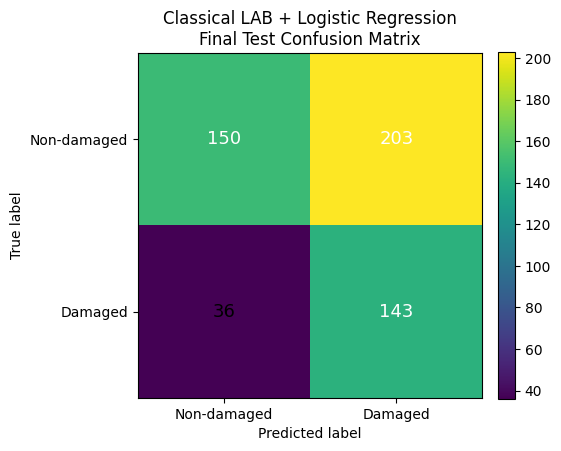

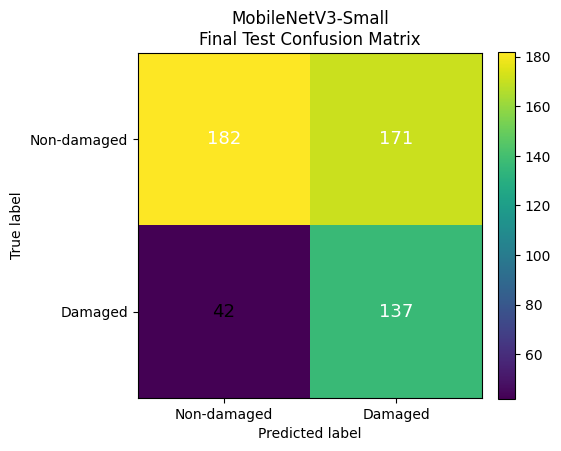

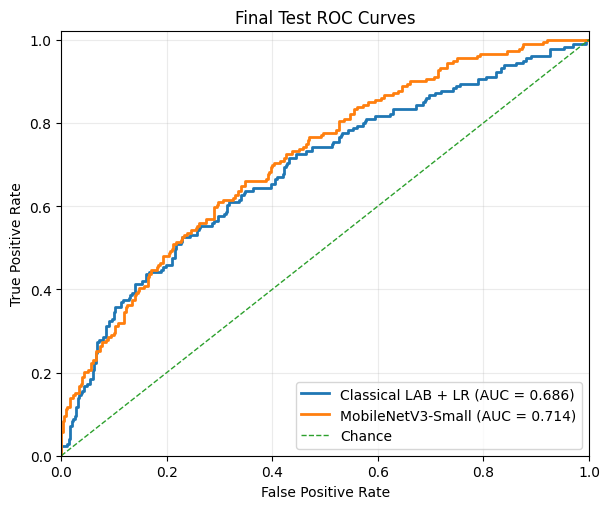

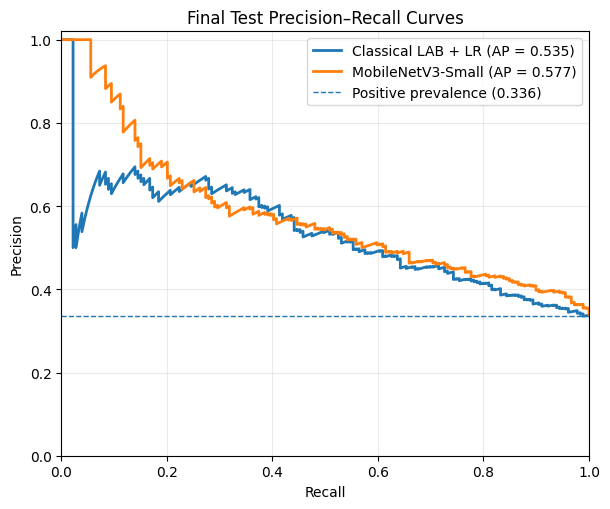

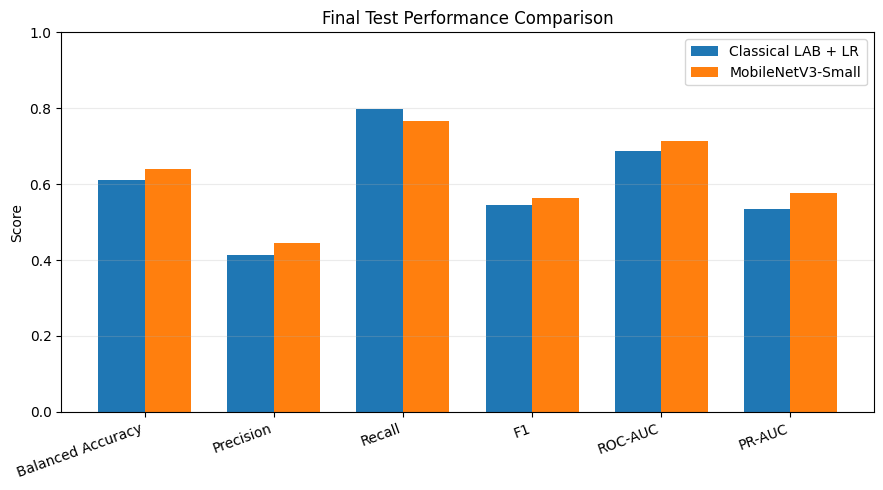


RUNTIME SUMMARY


,method,feature_or_network_seconds,classifier_seconds,reported_total_seconds,reported_ms_per_property
0,Classical LAB + LR,3.950,0.0014,3.9514,7.4275
1,MobileNetV3-Small,0.372,NaN,0.3720,0.6993



FINAL REPORT ARTIFACTS COMPLETE

Saved results:
/content/drive/MyDrive/EE565_Midterm_Milton/results/final_test_report_table.csv
/content/drive/MyDrive/EE565_Midterm_Milton/results/final_test_runtime_summary.csv

Saved figures:
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_confusion_matrix_classical.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_confusion_matrix_cnn.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_roc_curves.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_precision_recall_curves.png
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_metric_comparison.png

✓ Final metrics loaded from frozen Cell 36 outputs
✓ No model fitting performed
✓ No threshold tuning performed
✓ Classical and CNN confusion matrices generated
✓ ROC comparison generated
✓ Precision–Recall comparison generated
✓ Metric comparison figure generated
✓ Runtime summary generated
✓ Report-ready artifacts saved
✓ Cell 37 c

In [ ]:
# ============================================================
# CELL 37 — FINAL RESULTS TABLES AND FIGURES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

print("=" * 70)
print("FINAL RESULTS TABLES AND FIGURES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "EE565_Midterm_Milton"
)

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_METRICS_PATH = (
    RESULTS_DIR /
    "final_test_metrics.csv"
)

FINAL_PREDICTIONS_PATH = (
    RESULTS_DIR /
    "final_test_predictions.csv"
)

assert FINAL_METRICS_PATH.exists()
assert FINAL_PREDICTIONS_PATH.exists()

# ------------------------------------------------------------
# 2. Load frozen Cell 36 results
# ------------------------------------------------------------
metrics_df = pd.read_csv(
    FINAL_METRICS_PATH
)

predictions_df = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)

assert len(metrics_df) == 2
assert len(predictions_df) == 532

y_true = predictions_df[
    "damage_label"
].to_numpy(dtype=np.int8)

classical_prob = predictions_df[
    "classical_probability"
].to_numpy()

classical_pred = predictions_df[
    "classical_prediction"
].to_numpy(dtype=np.int8)

cnn_prob = predictions_df[
    "cnn_probability"
].to_numpy()

cnn_pred = predictions_df[
    "cnn_prediction"
].to_numpy(dtype=np.int8)

assert (y_true == 0).sum() == 353
assert (y_true == 1).sum() == 179

print("\nFrozen test results loaded:")
print(f"Samples  : {len(y_true)}")
print(f"Negative : {(y_true == 0).sum()}")
print(f"Positive : {(y_true == 1).sum()}")

# ------------------------------------------------------------
# 3. Clean report-ready final results table
# ------------------------------------------------------------
report_table = metrics_df[
    [
        "model",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "pr_auc",
        "tn",
        "fp",
        "fn",
        "tp"
    ]
].copy()

report_table["model"] = [
    "Classical LAB + LR",
    "MobileNetV3-Small"
]

REPORT_TABLE_PATH = (
    RESULTS_DIR /
    "final_test_report_table.csv"
)

report_table.to_csv(
    REPORT_TABLE_PATH,
    index=False
)

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE TABLE")
print("=" * 70)

display(
    report_table.round(4)
)

# ------------------------------------------------------------
# 4. Confusion matrix helper
# ------------------------------------------------------------
def save_confusion_matrix(
    y_true,
    y_pred,
    title,
    output_path
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(
        figsize=(5.5, 4.8)
    )

    image = ax.imshow(
        cm
    )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        ["Non-damaged", "Damaged"]
    )

    ax.set_yticklabels(
        ["Non-damaged", "Damaged"]
    )

    ax.set_xlabel(
        "Predicted label"
    )

    ax.set_ylabel(
        "True label"
    )

    ax.set_title(
        title
    )

    threshold = (
        cm.max() / 2.0
    )

    for i in range(2):
        for j in range(2):

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                color=(
                    "white"
                    if cm[i, j] > threshold
                    else "black"
                ),
                fontsize=13
            )

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 5. Classical confusion matrix
# ------------------------------------------------------------
CLASSICAL_CM_PATH = (
    FIGURES_DIR /
    "final_test_confusion_matrix_classical.png"
)

save_confusion_matrix(
    y_true,
    classical_pred,
    (
        "Classical LAB + Logistic Regression\n"
        "Final Test Confusion Matrix"
    ),
    CLASSICAL_CM_PATH
)

# ------------------------------------------------------------
# 6. CNN confusion matrix
# ------------------------------------------------------------
CNN_CM_PATH = (
    FIGURES_DIR /
    "final_test_confusion_matrix_cnn.png"
)

save_confusion_matrix(
    y_true,
    cnn_pred,
    (
        "MobileNetV3-Small\n"
        "Final Test Confusion Matrix"
    ),
    CNN_CM_PATH
)

# ------------------------------------------------------------
# 7. ROC curves
# ------------------------------------------------------------
classical_fpr, classical_tpr, _ = (
    roc_curve(
        y_true,
        classical_prob
    )
)

cnn_fpr, cnn_tpr, _ = (
    roc_curve(
        y_true,
        cnn_prob
    )
)

classical_auc = roc_auc_score(
    y_true,
    classical_prob
)

cnn_auc = roc_auc_score(
    y_true,
    cnn_prob
)

fig, ax = plt.subplots(
    figsize=(6.2, 5.2)
)

ax.plot(
    classical_fpr,
    classical_tpr,
    linewidth=2,
    label=(
        "Classical LAB + LR "
        f"(AUC = {classical_auc:.3f})"
    )
)

ax.plot(
    cnn_fpr,
    cnn_tpr,
    linewidth=2,
    label=(
        "MobileNetV3-Small "
        f"(AUC = {cnn_auc:.3f})"
    )
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Chance"
)

ax.set_xlabel(
    "False Positive Rate"
)

ax.set_ylabel(
    "True Positive Rate"
)

ax.set_title(
    "Final Test ROC Curves"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower right"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

ROC_PATH = (
    FIGURES_DIR /
    "final_test_roc_curves.png"
)

fig.savefig(
    ROC_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. Precision–Recall curves
# ------------------------------------------------------------
classical_precision_curve, \
classical_recall_curve, _ = (
    precision_recall_curve(
        y_true,
        classical_prob
    )
)

cnn_precision_curve, \
cnn_recall_curve, _ = (
    precision_recall_curve(
        y_true,
        cnn_prob
    )
)

classical_ap = (
    average_precision_score(
        y_true,
        classical_prob
    )
)

cnn_ap = (
    average_precision_score(
        y_true,
        cnn_prob
    )
)

positive_prevalence = (
    y_true.mean()
)

fig, ax = plt.subplots(
    figsize=(6.2, 5.2)
)

ax.plot(
    classical_recall_curve,
    classical_precision_curve,
    linewidth=2,
    label=(
        "Classical LAB + LR "
        f"(AP = {classical_ap:.3f})"
    )
)

ax.plot(
    cnn_recall_curve,
    cnn_precision_curve,
    linewidth=2,
    label=(
        "MobileNetV3-Small "
        f"(AP = {cnn_ap:.3f})"
    )
)

ax.axhline(
    positive_prevalence,
    linestyle="--",
    linewidth=1,
    label=(
        "Positive prevalence "
        f"({positive_prevalence:.3f})"
    )
)

ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "Final Test Precision–Recall Curves"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="best"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

PR_PATH = (
    FIGURES_DIR /
    "final_test_precision_recall_curves.png"
)

fig.savefig(
    PR_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. Compact metric comparison
# ------------------------------------------------------------
comparison_metrics = [
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]

comparison_labels = [
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

classical_row = metrics_df.iloc[0]
cnn_row = metrics_df.iloc[1]

x = np.arange(
    len(comparison_metrics)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    x - width / 2,
    [
        classical_row[m]
        for m in comparison_metrics
    ],
    width,
    label="Classical LAB + LR"
)

ax.bar(
    x + width / 2,
    [
        cnn_row[m]
        for m in comparison_metrics
    ],
    width,
    label="MobileNetV3-Small"
)

ax.set_ylabel(
    "Score"
)

ax.set_title(
    "Final Test Performance Comparison"
)

ax.set_xticks(x)

ax.set_xticklabels(
    comparison_labels,
    rotation=20,
    ha="right"
)

ax.set_ylim(
    0,
    1.0
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

COMPARISON_PATH = (
    FIGURES_DIR /
    "final_test_metric_comparison.png"
)

fig.savefig(
    COMPARISON_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Runtime summary
#
# Classical feature extraction runtime comes from Cell 35:
# 3.95 s / 532 properties.
#
# Do NOT confuse classifier-only runtime with complete
# classical feature-processing time.
# ------------------------------------------------------------
classical_feature_seconds = 3.95

classical_classifier_seconds = float(
    classical_row[
        "inference_seconds"
    ]
)

cnn_inference_seconds = float(
    cnn_row[
        "inference_seconds"
    ]
)

runtime_df = pd.DataFrame([
    {
        "method":
            "Classical LAB + LR",

        "feature_or_network_seconds":
            classical_feature_seconds,

        "classifier_seconds":
            classical_classifier_seconds,

        "reported_total_seconds":
            (
                classical_feature_seconds
                + classical_classifier_seconds
            ),

        "reported_ms_per_property":
            (
                1000.0
                * (
                    classical_feature_seconds
                    + classical_classifier_seconds
                )
                / 532
            )
    },
    {
        "method":
            "MobileNetV3-Small",

        "feature_or_network_seconds":
            cnn_inference_seconds,

        "classifier_seconds":
            np.nan,

        "reported_total_seconds":
            cnn_inference_seconds,

        "reported_ms_per_property":
            (
                1000.0
                * cnn_inference_seconds
                / 532
            )
    }
])

RUNTIME_PATH = (
    RESULTS_DIR /
    "final_test_runtime_summary.csv"
)

runtime_df.to_csv(
    RUNTIME_PATH,
    index=False
)

print("\n" + "=" * 70)
print("RUNTIME SUMMARY")
print("=" * 70)

display(
    runtime_df.round(4)
)

# ------------------------------------------------------------
# 11. Final verification
# ------------------------------------------------------------
for output_path in [
    REPORT_TABLE_PATH,
    CLASSICAL_CM_PATH,
    CNN_CM_PATH,
    ROC_PATH,
    PR_PATH,
    COMPARISON_PATH,
    RUNTIME_PATH
]:

    assert output_path.exists(), (
        f"Missing output: {output_path}"
    )

print("\n" + "=" * 70)
print("FINAL REPORT ARTIFACTS COMPLETE")
print("=" * 70)

print("\nSaved results:")
print(REPORT_TABLE_PATH)
print(RUNTIME_PATH)

print("\nSaved figures:")
print(CLASSICAL_CM_PATH)
print(CNN_CM_PATH)
print(ROC_PATH)
print(PR_PATH)
print(COMPARISON_PATH)

print("\n✓ Final metrics loaded from frozen Cell 36 outputs")
print("✓ No model fitting performed")
print("✓ No threshold tuning performed")
print("✓ Classical and CNN confusion matrices generated")
print("✓ ROC comparison generated")
print("✓ Precision–Recall comparison generated")
print("✓ Metric comparison figure generated")
print("✓ Runtime summary generated")
print("✓ Report-ready artifacts saved")
print("✓ Cell 37 complete")

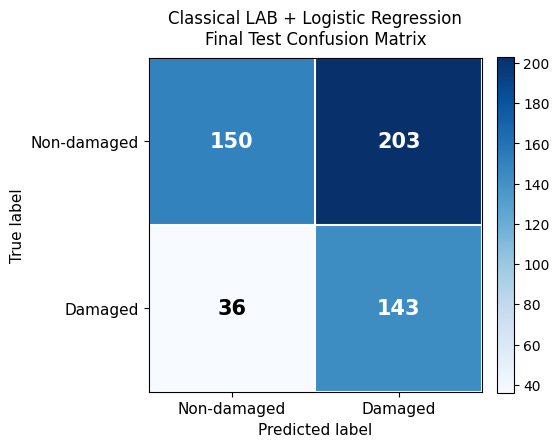

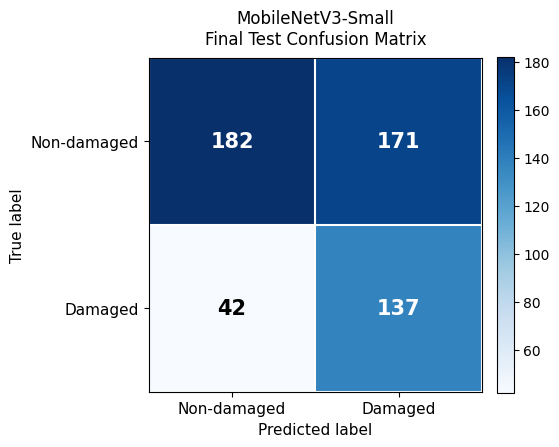

IEEE CONFUSION MATRICES UPDATED

Classical:
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_confusion_matrix_classical.png

CNN:
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_confusion_matrix_cnn.png

✓ Numerical results unchanged
✓ Only figure styling changed
✓ 300 dpi figures saved


In [ ]:
# ============================================================
# CELL 37A — IMPROVED CONFUSION MATRICES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/EE565_Midterm_Milton"
)

FIGURES_DIR = PROJECT_DIR / "figures"


def save_ieee_confusion_matrix(
    y_true,
    y_pred,
    title,
    output_path
):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(
        figsize=(5.4, 4.6)
    )

    # Clean, conventional confusion-matrix palette
    im = ax.imshow(
        cm,
        cmap="Blues"
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.ax.tick_params(
        labelsize=10
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        ["Non-damaged", "Damaged"],
        fontsize=11
    )

    ax.set_yticklabels(
        ["Non-damaged", "Damaged"],
        fontsize=11
    )

    ax.set_xlabel(
        "Predicted label",
        fontsize=11
    )

    ax.set_ylabel(
        "True label",
        fontsize=11
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=10
    )

    # --------------------------------------------------------
    # Contrast-safe annotation
    # White text on dark cells, black text on light cells.
    # --------------------------------------------------------
    normalized_intensity = (
        cm.astype(float) / cm.max()
    )

    for i in range(2):
        for j in range(2):

            text_color = (
                "white"
                if normalized_intensity[i, j] > 0.50
                else "black"
            )

            ax.text(
                j,
                i,
                f"{cm[i, j]}",
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color=text_color
            )

    # Subtle white cell boundaries
    ax.set_xticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linewidth=1.5
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# Classical model
# ------------------------------------------------------------
CLASSICAL_CM_PATH = (
    FIGURES_DIR /
    "final_test_confusion_matrix_classical.png"
)

save_ieee_confusion_matrix(
    y_true,
    classical_pred,
    (
        "Classical LAB + Logistic Regression\n"
        "Final Test Confusion Matrix"
    ),
    CLASSICAL_CM_PATH
)


# ------------------------------------------------------------
# CNN model
# ------------------------------------------------------------
CNN_CM_PATH = (
    FIGURES_DIR /
    "final_test_confusion_matrix_cnn.png"
)

save_ieee_confusion_matrix(
    y_true,
    cnn_pred,
    (
        "MobileNetV3-Small\n"
        "Final Test Confusion Matrix"
    ),
    CNN_CM_PATH
)


print("=" * 70)
print("IEEE CONFUSION MATRICES UPDATED")
print("=" * 70)

print("\nClassical:")
print(CLASSICAL_CM_PATH)

print("\nCNN:")
print(CNN_CM_PATH)

print("\n✓ Numerical results unchanged")
print("✓ Only figure styling changed")
print("✓ 300 dpi figures saved")

QUALITATIVE FINAL TEST ERROR ANALYSIS

✓ Frozen test arrays and predictions aligned

Automatically selected examples:


,property_index,damage_label,classical_probability,classical_prediction,cnn_probability,cnn_prediction,cnn_outcome,cnn_predicted_class_confidence,geo_tile_id,registration_method
0,865,0,0.4260,0,0.0320,0,True Negative,0.9680,0820000w270000n,SIFT_RANSAC_ECC
1,3243,1,0.5973,1,0.9908,1,True Positive,0.9908,0821930w265145n,GEOGRAPHIC_FALLBACK
2,1017,0,0.6088,1,0.9597,1,False Positive,0.9597,0822230w265615n,GEOGRAPHIC_FALLBACK
3,640,1,0.4641,0,0.1563,0,False Negative,0.8437,0820000w270000n,SIFT_RANSAC


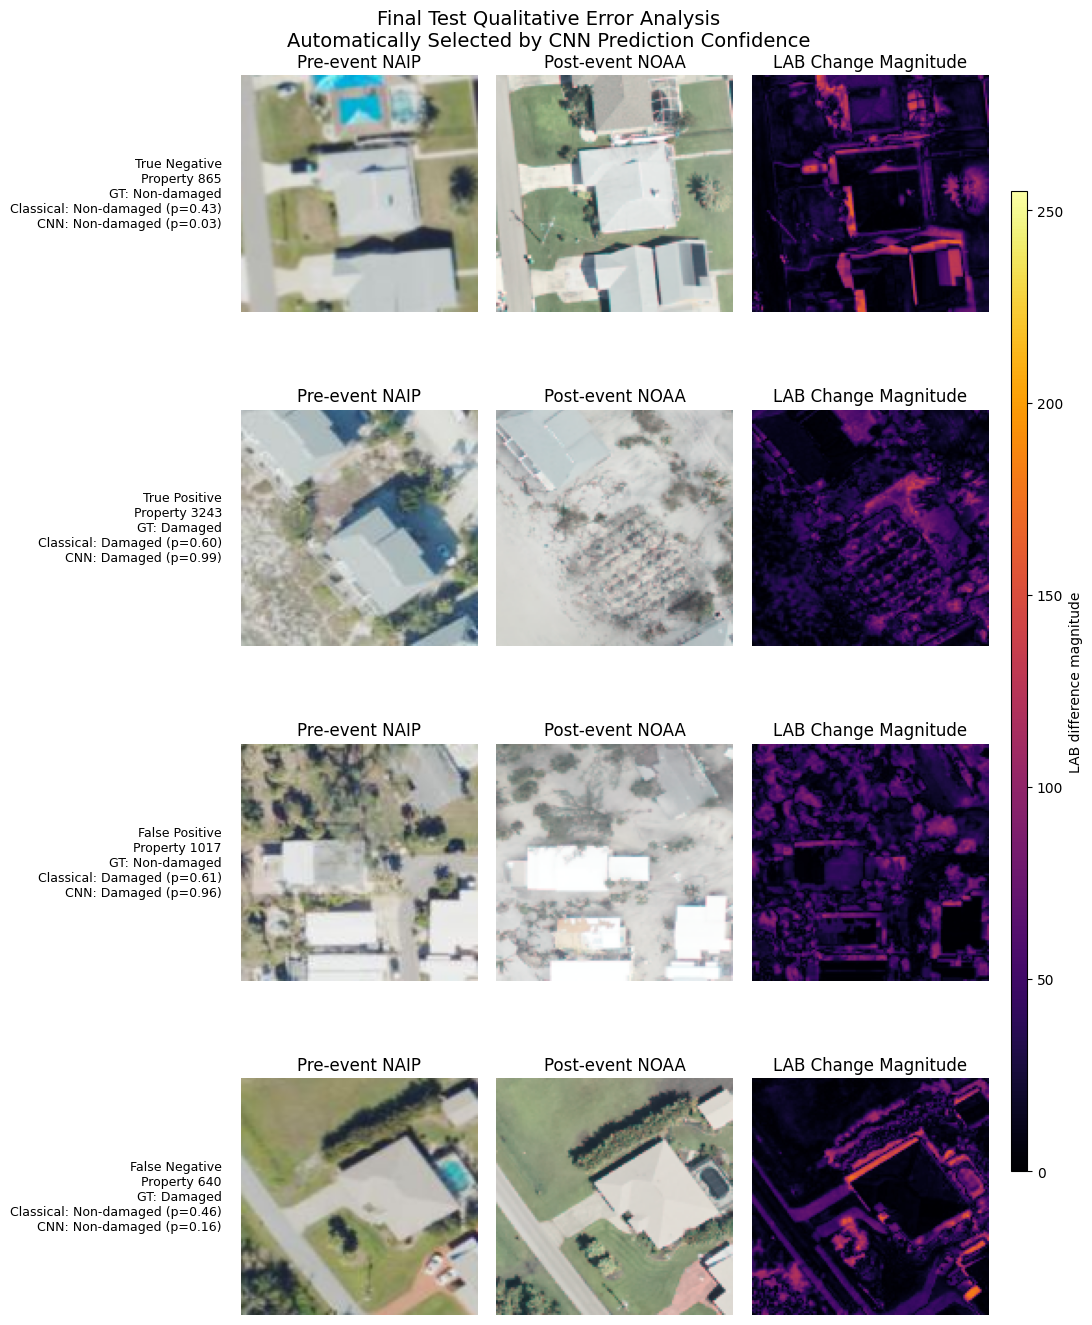


MODEL AGREEMENT / ERROR ANALYSIS

Models agree       : 350 / 532 (65.8%)
Models disagree    : 182 / 532 (34.2%)

Both correct       : 215
Both wrong         : 135
Classical only correct : 78
CNN only correct       : 104

QUALITATIVE ANALYSIS COMPLETE

Saved:
/content/drive/MyDrive/EE565_Midterm_Milton/figures/final_test_qualitative_examples.png
/content/drive/MyDrive/EE565_Midterm_Milton/results/final_test_qualitative_examples.csv
/content/drive/MyDrive/EE565_Midterm_Milton/results/final_test_model_agreement.csv

✓ Selection rule deterministic
✓ No manual test-example cherry-picking
✓ Frozen predictions used
✓ No model fitting performed
✓ No threshold tuning performed
✓ PRE NAIP / POST NOAA / LAB change displayed
✓ TN / TP / FP / FN represented
✓ Model agreement quantified
✓ Cell 38 complete


In [ ]:
# ============================================================
# CELL 38 — QUALITATIVE EXAMPLES + ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from skimage.exposure import match_histograms

print("=" * 70)
print("QUALITATIVE FINAL TEST ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "EE565_Midterm_Milton"
)

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

FROZEN_TEST_DIR = (
    PROJECT_DIR /
    "data" /
    "frozen_test"
)

TEST_PAIRED_PATH = (
    FROZEN_TEST_DIR /
    "test_paired_128.npz"
)

FINAL_PREDICTIONS_PATH = (
    RESULTS_DIR /
    "final_test_predictions.csv"
)

QUALITATIVE_FIGURE_PATH = (
    FIGURES_DIR /
    "final_test_qualitative_examples.png"
)

QUALITATIVE_TABLE_PATH = (
    RESULTS_DIR /
    "final_test_qualitative_examples.csv"
)

# ------------------------------------------------------------
# 2. Load frozen data
# ------------------------------------------------------------
with np.load(
    TEST_PAIRED_PATH,
    allow_pickle=False
) as data:

    test_pre = data["pre"].copy()
    test_post = data["post"].copy()
    test_labels = (
        data["labels"]
        .astype(np.int8)
    )

    test_ids = (
        data["property_index"]
        .astype(np.int64)
    )

predictions_df = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)

assert len(test_pre) == 532
assert len(test_post) == 532
assert len(predictions_df) == 532

assert np.array_equal(
    test_ids,
    predictions_df[
        "property_index"
    ].to_numpy(dtype=np.int64)
)

assert np.array_equal(
    test_labels,
    predictions_df[
        "damage_label"
    ].to_numpy(dtype=np.int8)
)

print("\n✓ Frozen test arrays and predictions aligned")

# ------------------------------------------------------------
# 3. Define CNN outcome category
# ------------------------------------------------------------
def outcome_category(
    truth,
    prediction
):

    if truth == 0 and prediction == 0:
        return "True Negative"

    if truth == 1 and prediction == 1:
        return "True Positive"

    if truth == 0 and prediction == 1:
        return "False Positive"

    return "False Negative"


predictions_df[
    "cnn_outcome"
] = [
    outcome_category(
        truth,
        prediction
    )
    for truth, prediction in zip(
        predictions_df[
            "damage_label"
        ],
        predictions_df[
            "cnn_prediction"
        ]
    )
]

# ------------------------------------------------------------
# 4. Fixed automatic selection rule
#
# For each CNN outcome category:
# select the sample with the highest confidence in the CNN's
# predicted class.
#
# Positive prediction confidence = P(damage)
# Negative prediction confidence = 1 - P(damage)
#
# This is deterministic and avoids manual cherry-picking.
# ------------------------------------------------------------
predictions_df[
    "cnn_predicted_class_confidence"
] = np.where(
    predictions_df[
        "cnn_prediction"
    ] == 1,

    predictions_df[
        "cnn_probability"
    ],

    1.0 - predictions_df[
        "cnn_probability"
    ]
)

CATEGORY_ORDER = [
    "True Negative",
    "True Positive",
    "False Positive",
    "False Negative"
]

selected_rows = []

for category in CATEGORY_ORDER:

    subset = predictions_df[
        predictions_df[
            "cnn_outcome"
        ] == category
    ].copy()

    assert len(subset) > 0, (
        f"No samples found for {category}"
    )

    subset = subset.sort_values(
        [
            "cnn_predicted_class_confidence",
            "property_index"
        ],
        ascending=[
            False,
            True
        ]
    )

    selected_rows.append(
        subset.iloc[0]
    )

selected_df = pd.DataFrame(
    selected_rows
).reset_index(drop=True)

# ------------------------------------------------------------
# 5. Locate array indices
# ------------------------------------------------------------
id_to_array_index = {
    int(property_id): index
    for index, property_id
    in enumerate(test_ids)
}

selected_df[
    "array_index"
] = [
    id_to_array_index[
        int(property_id)
    ]
    for property_id in selected_df[
        "property_index"
    ]
]

# ------------------------------------------------------------
# 6. Exact LAB change visualization
#
# Preserve Cell 24 preprocessing:
# histogram-match PRE to POST, then RGB -> LAB and compute
# Euclidean LAB difference.
# ------------------------------------------------------------
def make_lab_change_map(
    pre_rgb,
    post_rgb
):

    pre_matched = match_histograms(
        pre_rgb,
        post_rgb,
        channel_axis=-1
    )

    pre_matched = np.clip(
        pre_matched,
        0,
        255
    ).astype(np.uint8)

    pre_lab = cv2.cvtColor(
        pre_matched,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    post_lab = cv2.cvtColor(
        post_rgb,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    lab_difference = np.linalg.norm(
        post_lab - pre_lab,
        axis=2
    )

    return (
        pre_matched,
        lab_difference
    )

# ------------------------------------------------------------
# 7. Save selected-case table
# ------------------------------------------------------------
selected_output_columns = [
    "property_index",
    "damage_label",
    "classical_probability",
    "classical_prediction",
    "cnn_probability",
    "cnn_prediction",
    "cnn_outcome",
    "cnn_predicted_class_confidence"
]

for optional_column in [
    "geo_tile_id",
    "registration_method"
]:

    if optional_column in selected_df.columns:
        selected_output_columns.append(
            optional_column
        )

selected_df[
    selected_output_columns
].to_csv(
    QUALITATIVE_TABLE_PATH,
    index=False
)

print("\nAutomatically selected examples:")

display(
    selected_df[
        selected_output_columns
    ].round(4)
)

# ------------------------------------------------------------
# 8. Build qualitative panel
#
# Rows:
# TN, TP, FP, FN
#
# Columns:
# PRE NAIP
# POST NOAA
# LAB change
# ------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(11, 14)
)

for row_number, row in selected_df.iterrows():

    array_index = int(
        row[
            "array_index"
        ]
    )

    pre_rgb = test_pre[
        array_index
    ]

    post_rgb = test_post[
        array_index
    ]

    pre_matched, lab_change = (
        make_lab_change_map(
            pre_rgb,
            post_rgb
        )
    )

    # --------------------------------------------------------
    # PRE image
    # --------------------------------------------------------
    axes[
        row_number,
        0
    ].imshow(
        pre_rgb
    )

    axes[
        row_number,
        0
    ].set_title(
        "Pre-event NAIP"
    )

    # --------------------------------------------------------
    # POST image
    # --------------------------------------------------------
    axes[
        row_number,
        1
    ].imshow(
        post_rgb
    )

    axes[
        row_number,
        1
    ].set_title(
        "Post-event NOAA"
    )

    # --------------------------------------------------------
    # LAB change map
    # --------------------------------------------------------
    change_image = axes[
        row_number,
        2
    ].imshow(
        lab_change,
        cmap="inferno",
        vmin=0,
        vmax=255
    )

    axes[
        row_number,
        2
    ].set_title(
        "LAB Change Magnitude"
    )

    # --------------------------------------------------------
    # Remove axes
    # --------------------------------------------------------
    for column in range(3):

        axes[
            row_number,
            column
        ].axis(
            "off"
        )

    # --------------------------------------------------------
    # Row annotation
    # --------------------------------------------------------
    truth_text = (
        "Damaged"
        if int(
            row[
                "damage_label"
            ]
        ) == 1
        else "Non-damaged"
    )

    classical_text = (
        "Damaged"
        if int(
            row[
                "classical_prediction"
            ]
        ) == 1
        else "Non-damaged"
    )

    cnn_text = (
        "Damaged"
        if int(
            row[
                "cnn_prediction"
            ]
        ) == 1
        else "Non-damaged"
    )

    row_label = (
        f"{row['cnn_outcome']}\n"
        f"Property {int(row['property_index'])}\n"
        f"GT: {truth_text}\n"
        f"Classical: {classical_text} "
        f"(p={row['classical_probability']:.2f})\n"
        f"CNN: {cnn_text} "
        f"(p={row['cnn_probability']:.2f})"
    )

    axes[
        row_number,
        0
    ].text(
        -0.08,
        0.5,
        row_label,
        transform=axes[
            row_number,
            0
        ].transAxes,
        ha="right",
        va="center",
        fontsize=9
    )

# ------------------------------------------------------------
# 9. Shared colorbar
# ------------------------------------------------------------
fig.subplots_adjust(
    right=0.90,
    left=0.22,
    top=0.94,
    bottom=0.04,
    hspace=0.30,
    wspace=0.08
)

colorbar_axis = fig.add_axes(
    [
        0.92,
        0.15,
        0.015,
        0.70
    ]
)

fig.colorbar(
    change_image,
    cax=colorbar_axis,
    label="LAB difference magnitude"
)

fig.suptitle(
    (
        "Final Test Qualitative Error Analysis\n"
        "Automatically Selected by CNN Prediction Confidence"
    ),
    fontsize=14
)

fig.savefig(
    QUALITATIVE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Agreement/disagreement analysis
# ------------------------------------------------------------
predictions_df[
    "models_agree"
] = (
    predictions_df[
        "classical_prediction"
    ]
    ==
    predictions_df[
        "cnn_prediction"
    ]
)

agreement_count = int(
    predictions_df[
        "models_agree"
    ].sum()
)

disagreement_count = int(
    (
        ~predictions_df[
            "models_agree"
        ]
    ).sum()
)

both_correct = int(
    (
        (
            predictions_df[
                "classical_prediction"
            ]
            ==
            predictions_df[
                "damage_label"
            ]
        )
        &
        (
            predictions_df[
                "cnn_prediction"
            ]
            ==
            predictions_df[
                "damage_label"
            ]
        )
    ).sum()
)

both_wrong = int(
    (
        (
            predictions_df[
                "classical_prediction"
            ]
            !=
            predictions_df[
                "damage_label"
            ]
        )
        &
        (
            predictions_df[
                "cnn_prediction"
            ]
            !=
            predictions_df[
                "damage_label"
            ]
        )
    ).sum()
)

classical_only_correct = int(
    (
        (
            predictions_df[
                "classical_prediction"
            ]
            ==
            predictions_df[
                "damage_label"
            ]
        )
        &
        (
            predictions_df[
                "cnn_prediction"
            ]
            !=
            predictions_df[
                "damage_label"
            ]
        )
    ).sum()
)

cnn_only_correct = int(
    (
        (
            predictions_df[
                "classical_prediction"
            ]
            !=
            predictions_df[
                "damage_label"
            ]
        )
        &
        (
            predictions_df[
                "cnn_prediction"
            ]
            ==
            predictions_df[
                "damage_label"
            ]
        )
    ).sum()
)

assert (
    both_correct
    + both_wrong
    + classical_only_correct
    + cnn_only_correct
    == 532
)

print("\n" + "=" * 70)
print("MODEL AGREEMENT / ERROR ANALYSIS")
print("=" * 70)

print(
    f"\nModels agree       : "
    f"{agreement_count} / 532 "
    f"({agreement_count / 532:.1%})"
)

print(
    f"Models disagree    : "
    f"{disagreement_count} / 532 "
    f"({disagreement_count / 532:.1%})"
)

print(
    f"\nBoth correct       : "
    f"{both_correct}"
)

print(
    f"Both wrong         : "
    f"{both_wrong}"
)

print(
    f"Classical only correct : "
    f"{classical_only_correct}"
)

print(
    f"CNN only correct       : "
    f"{cnn_only_correct}"
)

# ------------------------------------------------------------
# 11. Save agreement summary
# ------------------------------------------------------------
agreement_summary = pd.DataFrame([
    {
        "total_test_samples":
            532,

        "models_agree":
            agreement_count,

        "models_disagree":
            disagreement_count,

        "both_correct":
            both_correct,

        "both_wrong":
            both_wrong,

        "classical_only_correct":
            classical_only_correct,

        "cnn_only_correct":
            cnn_only_correct
    }
])

AGREEMENT_PATH = (
    RESULTS_DIR /
    "final_test_model_agreement.csv"
)

agreement_summary.to_csv(
    AGREEMENT_PATH,
    index=False
)

# ------------------------------------------------------------
# 12. Final verification
# ------------------------------------------------------------
assert QUALITATIVE_FIGURE_PATH.exists()
assert QUALITATIVE_TABLE_PATH.exists()
assert AGREEMENT_PATH.exists()

print("\n" + "=" * 70)
print("QUALITATIVE ANALYSIS COMPLETE")
print("=" * 70)

print("\nSaved:")
print(QUALITATIVE_FIGURE_PATH)
print(QUALITATIVE_TABLE_PATH)
print(AGREEMENT_PATH)

print("\n✓ Selection rule deterministic")
print("✓ No manual test-example cherry-picking")
print("✓ Frozen predictions used")
print("✓ No model fitting performed")
print("✓ No threshold tuning performed")
print("✓ PRE NAIP / POST NOAA / LAB change displayed")
print("✓ TN / TP / FP / FN represented")
print("✓ Model agreement quantified")
print("✓ Cell 38 complete")